# Analysis of uoe5 pipeline run
Reran antibody panel 1 with new updates within the pipeline, resutling in run uoe5.

Major pipeline changes include more quality control mesasures focused on organelle channels (lysosome, endosome, and mitochondria) - I added the contrast check that we run for the nuclues channel to script 3 to check each channel before segmentation is preformed. The organelle channels are generally more dim than the nuclues channel, so the threshold for QC is quite a bit lower than that of the nucleus channel.

The goals here are to preform the prior PCA analyses (plus additional analysis on the genotype level, manual focused analsysis, and structure level analysis) and assess whether we reduced the number of poor quality images that make it to this analysis stage. 

In [1]:
import pathlib as Path
import pandas as pd
import os

import glob

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
import io
import matplotlib.pyplot as plt

# pip install python-pptx  (if not already installed)
from pptx import Presentation
from pptx.util import Inches, Pt

# ===========================================================================
# Figure capture: wrap plt.show so EVERY plot is grabbed, no per-call edits.
# ===========================================================================
_CAPTURED = []            # list of (title, png_bytes)
_CAPTURE_ON = True        # flip to False to pause capture for a cell


def _best_title(fig):
    """Pull a slide title from the figure: suptitle first, else first axes title."""
    # suptitle (used by scree / variant_pca)
    if getattr(fig, "_suptitle", None) is not None and fig._suptitle.get_text():
        return fig._suptitle.get_text()
    for ax in fig.axes:
        if ax.get_title():
            return ax.get_title()
    return None


_orig_show = plt.show

def _capturing_show(*args, **kwargs):
    if _CAPTURE_ON:
        fig = plt.gcf()
        # skip empty figures (no axes / nothing drawn)
        if fig.axes:
            buf = io.BytesIO()
            fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
            buf.seek(0)
            _CAPTURED.append((_best_title(fig), buf.getvalue()))
    return _orig_show(*args, **kwargs)

plt.show = _capturing_show
print("Figure capture ON — every plt.show() will be collected.")


# ===========================================================================
# Build the deck (call once at the very end of the notebook).
# ===========================================================================
def build_pptx(path, captured=None, widescreen=True):
    captured = _CAPTURED if captured is None else captured
    prs = Presentation()
    if widescreen:
        prs.slide_width = Inches(13.333)
        prs.slide_height = Inches(7.5)
    blank = prs.slide_layouts[6]   # fully blank

    sw = prs.slide_width
    sh = prs.slide_height
    for title, png in captured:
        slide = prs.slides.add_slide(blank)
        top = Inches(0.1)
        if title:
            tb = slide.shapes.add_textbox(Inches(0.3), Inches(0.1),
                                          sw - Inches(0.6), Inches(0.6))
            tf = tb.text_frame
            tf.text = title
            tf.paragraphs[0].font.size = Pt(18)
            top = Inches(0.8)

        pic = slide.shapes.add_picture(io.BytesIO(png), Inches(0), top)
        # scale to fit the slide while preserving aspect ratio
        avail_w = sw
        avail_h = sh - top - Inches(0.1)
        scale = min(avail_w / pic.width, avail_h / pic.height)
        pic.width = int(pic.width * scale)
        pic.height = int(pic.height * scale)
        pic.left = int((sw - pic.width) / 2)   # center horizontally

    prs.save(path)
    print(f"wrote {len(captured)} slides -> {path}")


def restore_show():
    """Undo the monkeypatch (optional, e.g. before re-running interactively)."""
    plt.show = _orig_show
    print("Figure capture OFF — plt.show restored.")

Figure capture ON — every plt.show() will be collected.


## Load feature data
Load in feature data merged with metadata

In [3]:
uoe5_organelle_output_fn = "/data/kelpschdj/iNDI/Production/notebooks/analysis_uoe5/uoe5_organelle_output.parquet"
df = pd.read_parquet(uoe5_organelle_output_fn)

df["Batch"] = df["Batch"].astype("Int64").astype(str)  # Int64 first handles any NaN

df = df[df["Structure"] == "Lysosome"]

print(df.head())
print(df.columns.tolist())

                DAPI_filename  Nucleus_ID  \
1   r01c01f01p01-ch01t01.tiff         1.0   
4   r01c01f01p01-ch01t01.tiff         2.0   
7   r01c01f01p01-ch01t01.tiff         2.0   
10  r01c01f01p01-ch01t01.tiff         2.0   
13  r01c01f01p01-ch01t01.tiff         3.0   

                          Measurement_ID subdirectory  Row  Column  Frame  \
1   7e03b502-ad64-4090-a9e2-fc4c3ecdae11       r01c01    1       1      1   
4   72c0a713-b5d5-4cd4-a826-c556368ed1d1       r01c01    1       1      1   
7   7e03b502-ad64-4090-a9e2-fc4c3ecdae11       r01c01    1       1      1   
10  d7e04b5c-a253-42ff-859f-2af0e6047a00       r01c01    1       1      1   
13  2b1c31ad-579d-4ea6-a782-251ea083ed6a       r01c01    1       1      1   

    Plane  Time           channel_filename  ... Variant Genotype  \
1       1     1  r01c01f01p01-ch02t01.tiff  ...    None     None   
4       1     1  r01c01f01p01-ch02t01.tiff  ...    None     None   
7       1     1  r01c01f01p01-ch02t01.tiff  ...    None     No

In [4]:
print(f"Total number of images: {df[['channel_filename', 'iNDI_Plate_ID']].drop_duplicates().shape[0]}")
print(f"Total number of ROIs: {len(df)}")

Total number of images: 192954
Total number of ROIs: 1031413


In [5]:
WELL_KEYS = ["iNDI_Plate_ID", "Well_ID"]
IMAGE_KEY = "channel_filename"

# 1) grouping keys have no NaN (NaN keys get silently dropped by groupby)
for k in WELL_KEYS + [IMAGE_KEY]:
    n = df[k].isna().sum()
    print(f"{k}: {n} NaN" + ("  <-- WILL DROP ROWS" if n else ""))

# 2) metadata that .first() carries should be invariant within a well
for col in ["Genotype_Name", "Gene_Var_Type", "Source", "Batch"]:
    bad = (df.groupby(WELL_KEYS)[col].nunique() > 1).sum()
    print(f"{col}: {bad} well(s) with >1 value" + ("  <-- CHECK" if bad else ""))

# 3) counts line up: wells, images-per-well, and the parental sanity number
n_wells  = df[WELL_KEYS].drop_duplicates().shape[0]
n_images = df[WELL_KEYS + [IMAGE_KEY]].drop_duplicates().shape[0]
print(f"\nwells: {n_wells}")
print(f"well+image combos (expected rows after stage-1 agg): {n_images}")

par = df[(df["Source"].astype(str).str.strip() == "automated")
         & (df["Genotype_Name"].astype(str).str.strip() == "Parental")]
print(f"automated parental wells: {par[WELL_KEYS].drop_duplicates().shape[0]}  (expect 1139)")

iNDI_Plate_ID: 0 NaN
Well_ID: 0 NaN
channel_filename: 0 NaN
Genotype_Name: 0 well(s) with >1 value
Gene_Var_Type: 0 well(s) with >1 value
Source: 0 well(s) with >1 value
Batch: 0 well(s) with >1 value

wells: 5931
well+image combos (expected rows after stage-1 agg): 192954
automated parental wells: 1139  (expect 1139)


# Primary analysis
## ROI level data
### Feature assessment and PCA loadings
Broad assessment of features before PCA

#### Helper functions

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# candidate regionprops features (from script 1)
CANDIDATE_FEATURES = [
    # ROI-level
    "area_px", "organelle_count", "average_organelle_area", "roi_occupancy",
    # pooled-pixel intensity
    "max_f_intensity", "sum_f_intensity", "mean_f_intensity",
    "median_f_intensity", "CoefOfVar_intensity",
    # per-object shape (use median as the robust center; add _std for spread)
    "area_median", "area_std",
    "perimeter_median", "eccentricity_median", "solidity_median",
    "extent_median", "axis_major_length_median", "axis_minor_length_median",
    "equivalent_diameter_area_median",
    # per-object intensity distribution
    "intensity_mean_median", "intensity_max_median", "intensity_min_median",
    # radial organization
    "dist_to_centroid_median", "dist_to_centroid_norm_mean", "dist_to_centroid_std",
]
# pruned set fed to PCA (after the |r|>0.9 review)
PCA_FEATURES = [
    "area_px", "organelle_count", "roi_occupancy",
    "mean_f_intensity", "CoefOfVar_intensity",
    "eccentricity_median", "solidity_median", "extent_median",
    "intensity_max_median",
    "dist_to_centroid_norm_mean", "dist_to_centroid_std",
]


def feature_correlation(data, features=CANDIDATE_FEATURES,
                        title="Lysosome feature cross-correlation (raw)", show=True):
    """Pearson corr heatmap + list of |r|>0.9 pairs. Returns the corr matrix."""
    features = [c for c in features if c in data.columns]
    X = data[features].replace([np.inf, -np.inf], np.nan)
    corr = X.corr(method="pearson")

    if show:
        plt.figure(figsize=(9, 7))
        im = plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
        plt.xticks(range(len(features)), features, rotation=90, fontsize=8)
        plt.yticks(range(len(features)), features, fontsize=8)
        plt.colorbar(im, label="Pearson r")
        plt.title(title)
        plt.tight_layout(); plt.show()

    hi = (corr.abs() > 0.9) & (corr.abs() < 1.0)
    pairs = [(a, b, round(corr.loc[a, b], 3))
             for i, a in enumerate(features)
             for b in features[i + 1:] if hi.loc[a, b]]
    print("Highly correlated pairs (|r| > 0.9):")
    for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
        print(f"  {r:+.3f}  {a:22s} {b}")
    return corr


def fit_pca(data, features=PCA_FEATURES, add_aspect_ratio=True,
            show_scree=True, show_loadings=True, label=""):
    """Add aspect_ratio, drop NaN/inf, scale, and fit PCA.

    Operates on a COPY -- does not mutate the input or any global. Returns
    (scored_df, pca, features_used) where scored_df has PC1..PCn columns.
    """
    data = data.copy()
    if add_aspect_ratio and {"axis_minor_length", "axis_major_length"} <= set(data.columns):
        data["aspect_ratio"] = data["axis_minor_length"] / data["axis_major_length"]

    features = [c for c in features if c in data.columns]
    print(f"[{label}] using FEATURES:", features)

    before = len(data)
    X_df = data[features].replace([np.inf, -np.inf], np.nan)
    keep = X_df.notna().all(axis=1)
    data = data[keep].reset_index(drop=True)
    X_df = X_df[keep].reset_index(drop=True)
    print(f"[{label}] dropped {before - len(data)} rows with NaN/inf; {len(data)} remain")

    X = StandardScaler().fit_transform(X_df.values)
    pca = PCA(n_components=len(features))
    scores = pca.fit_transform(X)
    for i in range(scores.shape[1]):
        data[f"PC{i+1}"] = scores[:, i]

    ev = pca.explained_variance_ratio_
    print(f"[{label}] EVR:", ev.round(3))
    print(f"[{label}] cumulative:", np.cumsum(ev).round(3))

    if show_scree:
        pcs = range(1, len(ev) + 1)
        fig, ax1 = plt.subplots(figsize=(7, 4.5))

        # per-PC explained variance (bars, left axis)
        ax1.bar(pcs, ev, color="steelblue", alpha=0.8, label="individual")
        ax1.set_xlabel("PC")
        ax1.set_ylabel("explained variance ratio", color="steelblue")
        ax1.tick_params(axis="y", labelcolor="steelblue")
        ax1.set_xticks(list(pcs))

        # cumulative explained variance (line, right axis)
        ax2 = ax1.twinx()
        ax2.plot(pcs, np.cumsum(ev), marker="o", color="darkorange",
                 label="cumulative")
        ax2.set_ylabel("cumulative EVR", color="darkorange")
        ax2.tick_params(axis="y", labelcolor="darkorange")
        ax2.set_ylim(0, 1.02)

        plt.title(f"{label} — scree" if label else "scree")
        fig.tight_layout(); plt.show()

    if show_loadings:
        loadings = pd.DataFrame(
            pca.components_.T, index=features,
            columns=[f"PC{i+1}" for i in range(len(features))],
        )
        print(loadings.round(3))
        n_show = min(6, len(features))
        plt.figure(figsize=(1.6 * n_show, 0.4 * len(features) + 1))
        im = plt.imshow(loadings.iloc[:, :n_show], cmap="RdBu_r",
                        vmin=-1, vmax=1, aspect="auto")
        plt.xticks(range(n_show), [f"PC{i+1}" for i in range(n_show)])
        plt.yticks(range(len(features)), features, fontsize=9)
        plt.colorbar(im, label="Loading")
        plt.title(f"{label} — Lysosome PCA loadings" if label else "Lysosome PCA loadings")
        plt.tight_layout(); plt.show()

    return data, pca, features



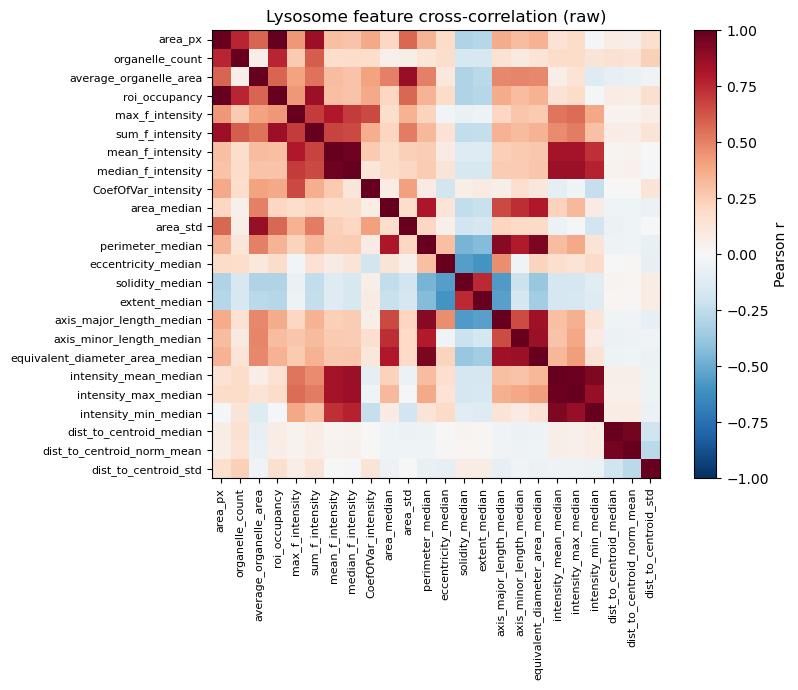

Highly correlated pairs (|r| > 0.9):
  +0.977  intensity_mean_median  intensity_max_median
  +0.976  mean_f_intensity       median_f_intensity
  +0.954  dist_to_centroid_median dist_to_centroid_norm_mean
  +0.945  perimeter_median       equivalent_diameter_area_median
  +0.931  intensity_mean_median  intensity_min_median
  +0.911  perimeter_median       axis_major_length_median
[full] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full] dropped 0 rows with NaN/inf; 1031413 remain
[full] EVR: [0.32  0.189 0.146 0.111 0.08  0.057 0.042 0.023 0.022 0.01  0.   ]
[full] cumulative: [0.32  0.509 0.655 0.766 0.847 0.904 0.946 0.968 0.99  1.    1.   ]


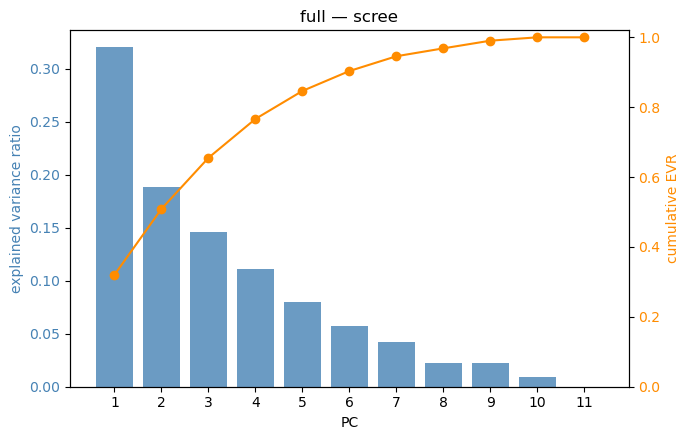

                              PC1    PC2    PC3    PC4    PC5    PC6    PC7  \
area_px                     0.471  0.224 -0.157  0.091 -0.003 -0.206 -0.069   
organelle_count             0.394  0.226 -0.168  0.120 -0.395 -0.111  0.092   
roi_occupancy               0.471  0.224 -0.157  0.091 -0.003 -0.206 -0.069   
mean_f_intensity            0.273  0.063  0.629 -0.149  0.089  0.075  0.064   
CoefOfVar_intensity         0.162  0.380 -0.004 -0.003  0.760  0.283  0.245   
eccentricity_median         0.240 -0.463 -0.113 -0.034 -0.090  0.097  0.816   
solidity_median            -0.301  0.445  0.122  0.076 -0.204 -0.123  0.414   
extent_median              -0.298  0.464  0.126  0.075 -0.171 -0.148  0.259   
intensity_max_median        0.236 -0.060  0.652 -0.136 -0.205 -0.025 -0.062   
dist_to_centroid_norm_mean  0.045  0.001  0.115  0.768 -0.167  0.590 -0.073   
dist_to_centroid_std        0.071  0.264 -0.210 -0.571 -0.331  0.649 -0.063   

                              PC8    PC9   PC10   P

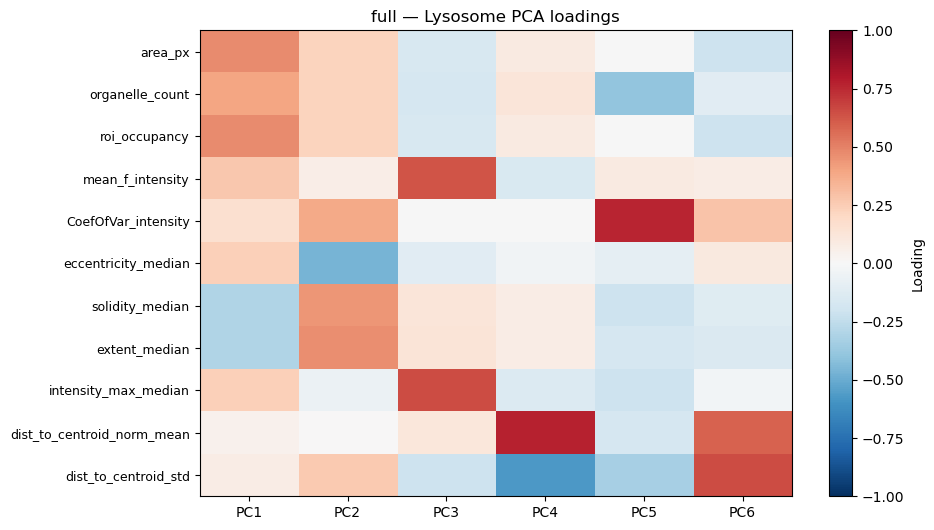

In [7]:
feature_correlation(df)
df, pca, FEATURES = fit_pca(df, label="full")

### PCA plots
Assessment of ROI level data for features

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
import seaborn as sns
import glasbey


# ===========================================================================
# Palettes
# ===========================================================================
def make_palette(values, hue_bounds=(60, 500.0), chroma_bounds=(40, 130)):
    """Stable {value: color} mapping for a categorical column, derived from
    the data (not a hardcoded set). Sorted so colors are reproducible."""
    vals = sorted(pd.Series(values).dropna().unique())
    raw = glasbey.create_palette(palette_size=max(len(vals), 1),
                                 hue_bounds=hue_bounds, chroma_bounds=chroma_bounds)
    cmap = ListedColormap(raw)
    pal = {v: cmap(i) for i, v in enumerate(vals)}
    return pal


# high-cardinality fallback for genotype-like columns with no fixed mapping
_GENO_RAW = glasbey.create_palette(palette_size=64, hue_bounds=(0.0, 360.0),
                                   chroma_bounds=(40, 90))
GENO_COLORS = [ListedColormap(_GENO_RAW)(i) for i in range(64)]


def check_palette_coverage(data, col, palette):
    """Warn about values present in the data but missing from the palette."""
    present = set(data[col].dropna().unique())
    missing = present - set(palette)
    print(f"[warning] {col} values with no color: {sorted(missing)}" if missing
          else f"All {len(present)} {col} values have a color.")


# ===========================================================================
# Scatter: one PCA panel colored by a categorical column
# ===========================================================================
def pca_scatter(data, color_col, pcx="PC1", pcy="PC2", palette=None,
                s=2, alpha=0.15, figsize=(10, 7), legend_ncol=1,
                title=None, show_legend=True, shuffle=True, random_state=0):
    """PCA scatter colored by `color_col`.

    palette : optional {value: color} dict. If None, Gene_Var_Type uses the
              glasbey genotype colors and everything else falls back to husl.
    shuffle : plot rows in random order so no single group sits on top.
    """
    if shuffle:
        data = data.sample(frac=1, random_state=random_state).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    vals = data[color_col].astype("object")
    cats = vals.value_counts().index.tolist()

    if palette is not None:
        colors = [palette.get(c, "#808080") for c in cats]
    elif color_col == "Gene_Var_Type":
        colors = [GENO_COLORS[i % len(GENO_COLORS)] for i in range(len(cats))]
    else:
        colors = sns.color_palette("husl", n_colors=len(cats))

    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(data.loc[m, pcx], data.loc[m, pcy], s=s, alpha=alpha,
                   color=col, linewidths=0, rasterized=True)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"PCA of {color_col}", pad=10)
    if show_legend:
        handles = [Line2D([0], [0], marker="o", linestyle="", markersize=5,
                   markerfacecolor=col, markeredgecolor=col, label=str(c))
                   for c, col in zip(cats, colors)]
        ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
                  frameon=False, fontsize=7, ncol=legend_ncol,
                  borderaxespad=0.0, handletextpad=0.4, columnspacing=0.8)
    plt.show()
    return ax


# ===========================================================================
# Centroid overlay: per-group centroids over a faint background cloud
# ===========================================================================
def centroid_overlay(data, color_col, group_keys, pcx="PC1", pcy="PC2",
                     palette=None, stat="median", bg_frac=1.0, s_centroid=60,
                     figsize=(10, 7), legend_ncol=1, title=None,
                     bg_s=1, bg_alpha=0.03):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    bg = data.sample(frac=bg_frac, random_state=0) if bg_frac < 1.0 else data
    ax.scatter(bg[pcx], bg[pcy], s=bg_s, alpha=bg_alpha, color="lightgray",
               linewidths=0, rasterized=True)
    agg_spec = {pcx: stat, pcy: stat}
    if color_col not in group_keys:
        agg_spec[color_col] = "first"
    cent = data.groupby(group_keys).agg(agg_spec).reset_index()
    vals = cent[color_col].astype("object")
    cats = vals.value_counts().index.tolist()
    colors = ([palette.get(c, "#808080") for c in cats] if palette
              else sns.color_palette("husl", n_colors=len(cats)))
    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(cent.loc[m, pcx], cent.loc[m, pcy], s=s_centroid, color=col,
                   edgecolor="k", linewidths=0.5, alpha=0.9)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"Per-group {stat} centroids ({color_col})", pad=10)
    handles = [Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=col, markeredgecolor="k", label=str(c))
               for c, col in zip(cats, colors)]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=7, ncol=legend_ncol)
    plt.show()
    return cent


# ===========================================================================
# Convenience: a standard panel set for one scored frame
# ===========================================================================
def scatter_panels(data, specs, label="Lysosome", s=2, alpha=0.15, figsize=(12, 7)):
    """Run pca_scatter for several columns in one call.

    specs : list of (column, palette_or_None). Pass a palette dict for columns
            you want stable colors on (plate, batch); None lets the function
            pick (glasbey for Gene_Var_Type, husl otherwise).
    """
    for col, pal in specs:
        pca_scatter(data, col, palette=pal, s=s, alpha=alpha, figsize=figsize,
                    legend_ncol=2 if col in ("Gene_Var_Type", "Genotype_Name") else 1,
                    title=f"{label} — {col}")


# --- usage -----------------------------------------------------------------
# build palettes once from whatever frame you're plotting:
# plate_pal = make_palette(df["iNDI_Plate_ID"])
# batch_pal = make_palette(df["Batch"])
# check_palette_coverage(df, "iNDI_Plate_ID", plate_pal)
#
# # single calls, anywhere later in the script -- no global dependencies:
# pca_scatter(df, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7),
#             title="Nuclei — iNDI_Plate_ID")
# pca_scatter(df, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2,
#             title="Nuclei — Gene_Var_Type")
#
# # or the whole standard set at once:
# scatter_panels(df, [
#     ("iNDI_Plate_ID", plate_pal),
#     ("Source",        None),
#     ("Batch",         batch_pal),
#     ("Asp PosID",     None),
#     ("Gene_Var_Type", None),
# ])
#
# centroid_overlay(df, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal,
#                  figsize=(12, 7), title="Per-experiment medians (by plate)")
# cent = df.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
# print("Std of per-experiment centroids (batch magnitude):")
# print(cent.std().round(3))

All 21 iNDI_Plate_ID values have a color.


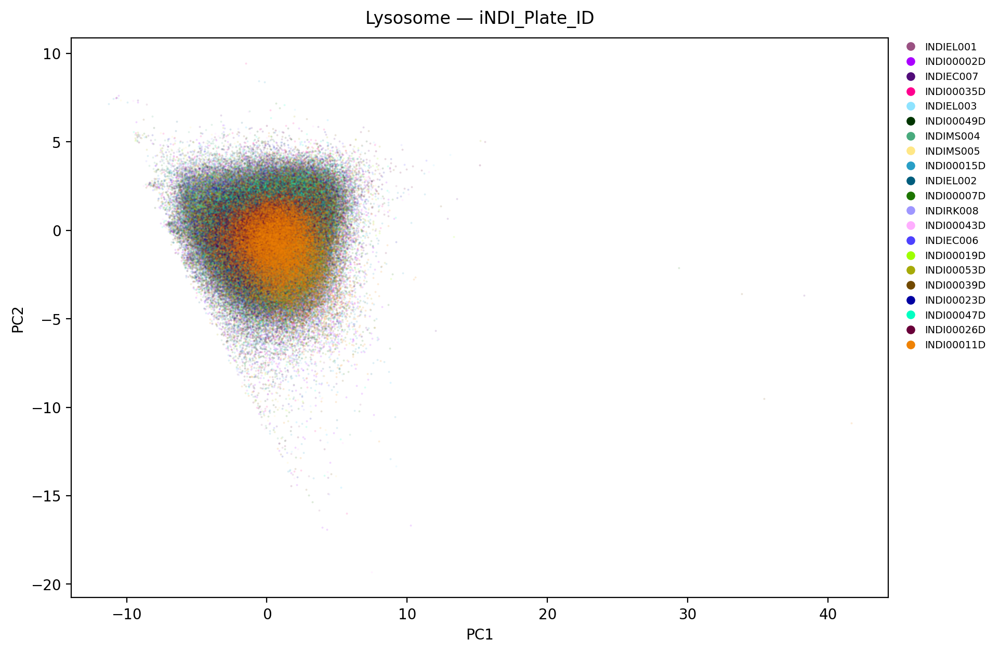

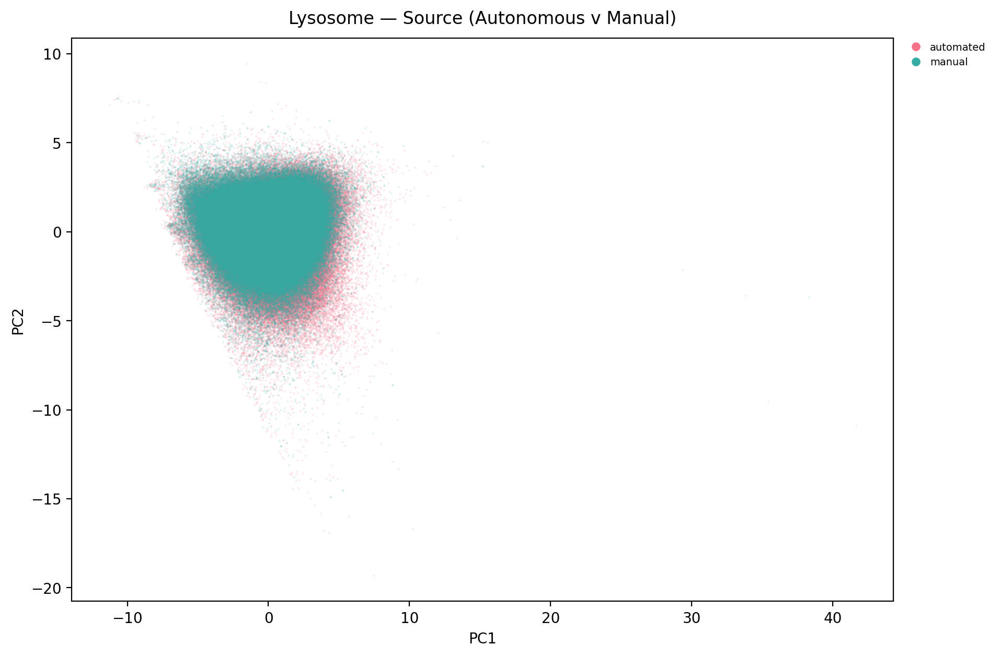

All 5 Batch values have a color.


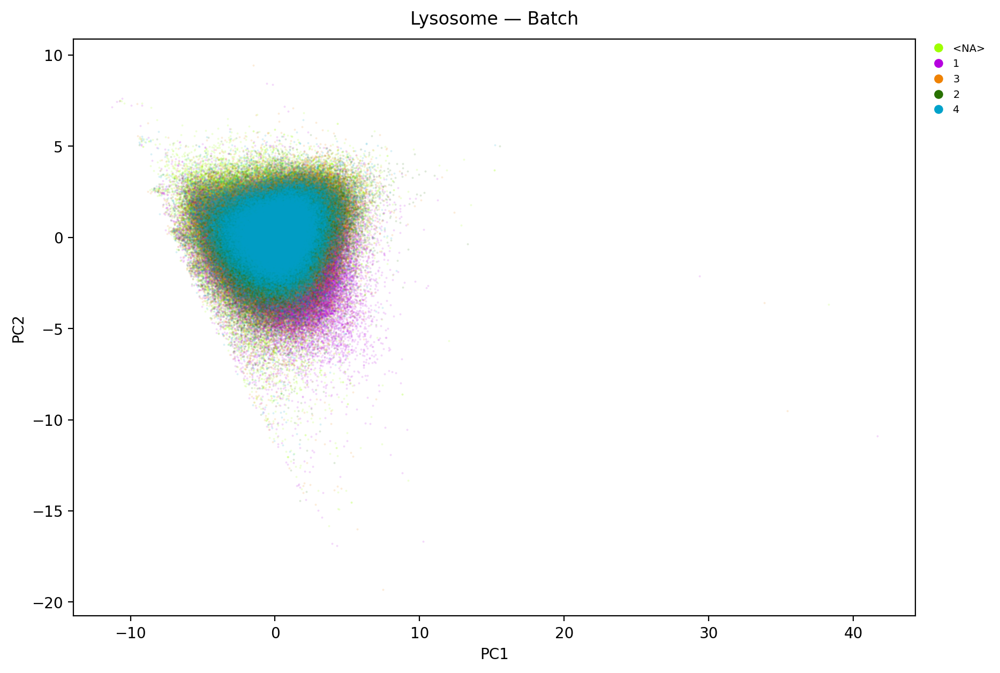

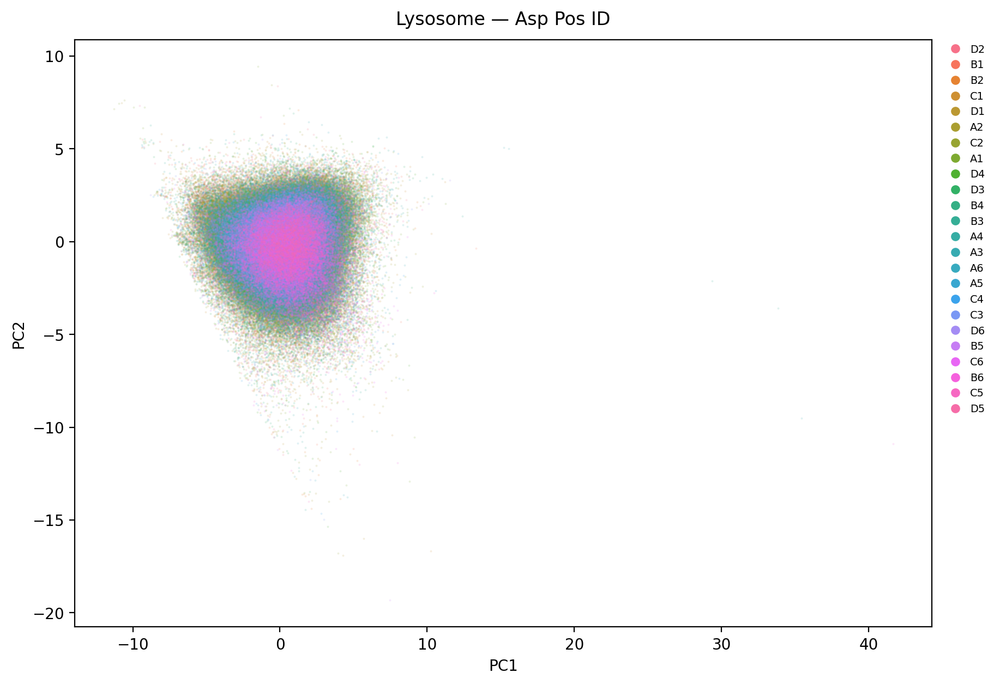

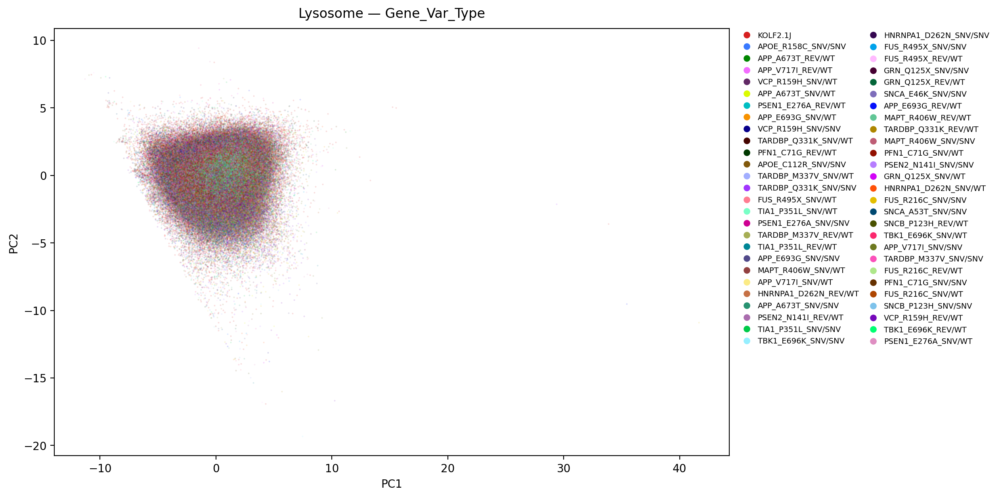

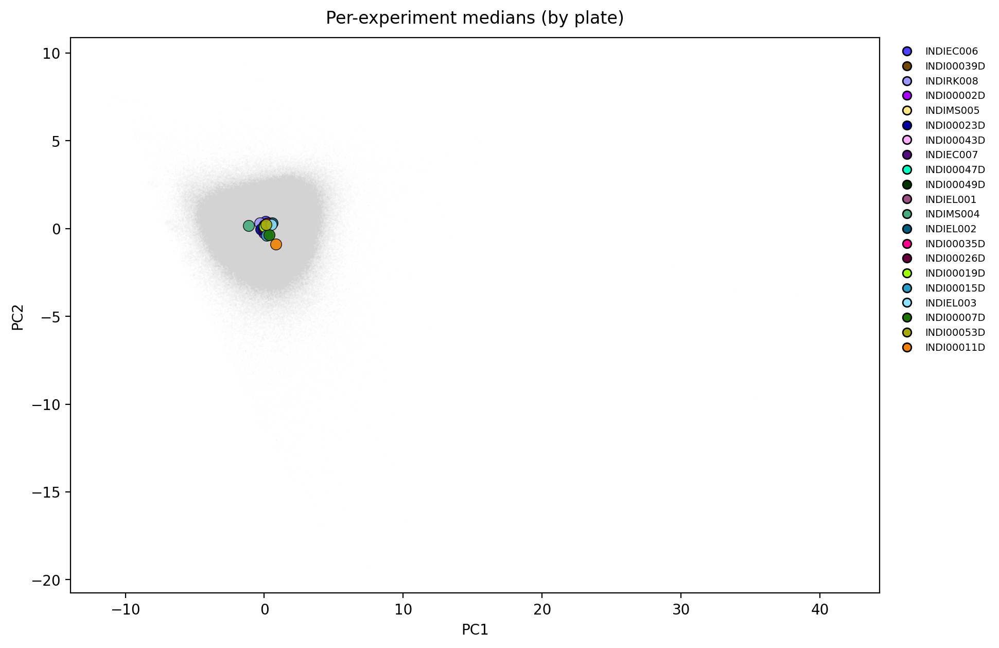

Std of per-experiment centroids (batch magnitude):
PC1    0.382
PC2    0.313
PC3    0.611
dtype: float64


In [9]:
plate_pal = make_palette(df["iNDI_Plate_ID"])
check_palette_coverage(df, "iNDI_Plate_ID", plate_pal)
pca_scatter(df, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Lysosome — iNDI_Plate_ID")

pca_scatter(df, "Source", figsize=(12, 7),title="Lysosome — Source (Autonomous v Manual)")

batch_palette = make_palette(df["Batch"])
check_palette_coverage(df, "Batch", batch_palette)
pca_scatter(df, "Batch", palette=batch_palette, figsize=(12, 7),title="Lysosome — Batch")

pca_scatter(df, "Asp PosID", figsize=(12, 7),title="Lysosome — Asp Pos ID")

pca_scatter(df, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Lysosome — Gene_Var_Type")

centroid_overlay(df, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = df.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

### Variance-component analysis

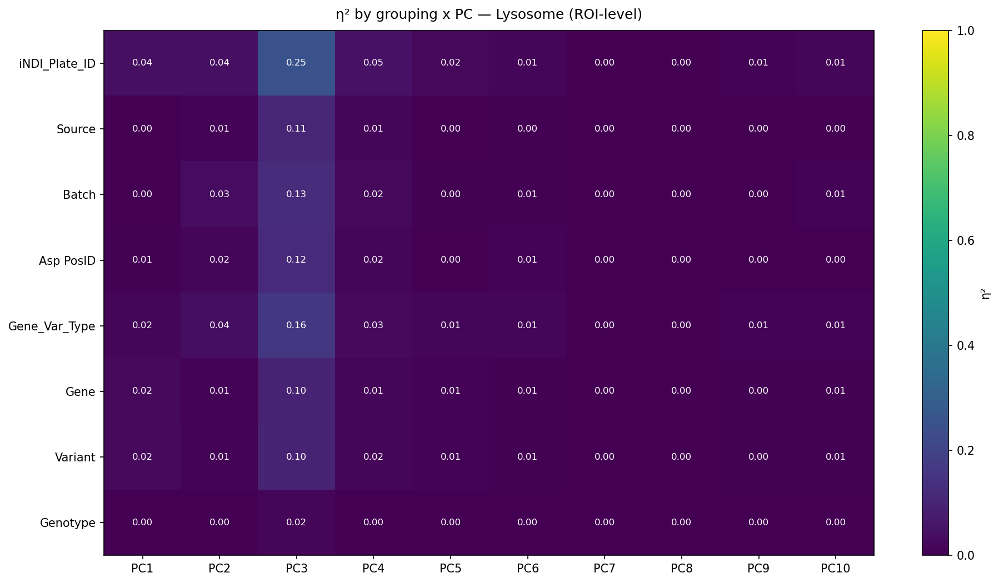

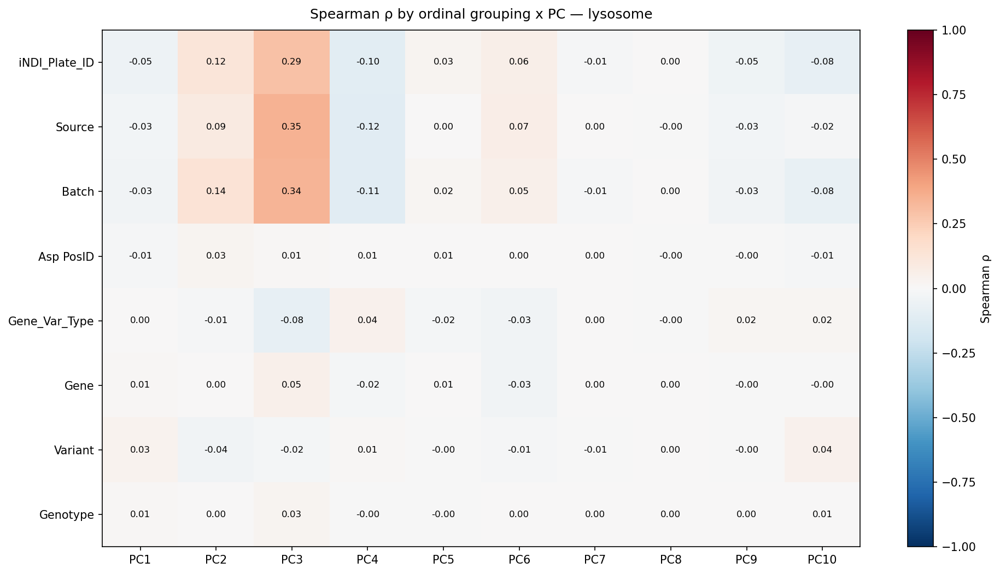

In [10]:
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:            # guard: skip empty groups
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


def eta_heatmap(data, group_cols, n_pcs=None, title="η² by grouping x PC", annot=True):
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))
    if n_pcs is not None:
        pc_cols = pc_cols[:n_pcs]
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    fig, ax = plt.subplots(figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(group_cols) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(group_cols))); ax.set_yticklabels(group_cols)
    plt.colorbar(im, ax=ax, label="η²")
    ax.set_title(title, pad=10)
    if annot:
        for i in range(len(group_cols)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 else "black", fontsize=8)
    plt.tight_layout(); plt.show()
    return mat

# Structure dropped (single channel). Batch drivers that matter:
GROUP_COLS = ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"]
eta_full = eta_heatmap(df, GROUP_COLS, n_pcs=10, title="η² by grouping x PC — Lysosome (ROI-level)")

from scipy.stats import spearmanr

def spearman_heatmap(data, group_cols, n_pcs=None,
                     title="Spearman ρ by grouping x PC", annot=True):
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))
    if n_pcs is not None:
        pc_cols = pc_cols[:n_pcs]
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)

    for gc in group_cols:
        # ordinal code: use numeric directly if numeric, else factorize
        col = data[gc]
        if pd.api.types.is_numeric_dtype(col):
            codes = col.to_numpy(dtype=float)
        else:
            codes = pd.factorize(col, sort=True)[0].astype(float)
            codes[codes < 0] = np.nan  # NaNs come back as -1
        for pc in pc_cols:
            x = data[pc].to_numpy(dtype=float)
            m = np.isfinite(x) & np.isfinite(codes)
            if m.sum() < 3:
                mat.loc[gc, pc] = np.nan
                continue
            rho, _ = spearmanr(x[m], codes[m])
            mat.loc[gc, pc] = rho

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(group_cols) + 1.5), dpi=150)
    # diverging map + symmetric limits since ρ ∈ [-1, 1]
    im = ax.imshow(mat.values.astype(float), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(group_cols))); ax.set_yticklabels(group_cols)
    plt.colorbar(im, ax=ax, label="Spearman ρ")
    ax.set_title(title, pad=10)
    if annot:
        for i in range(len(group_cols)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if abs(v) > 0.5 else "black", fontsize=8)
    plt.tight_layout(); plt.show()
    return mat

ORDINAL_COLS = ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"]
spear = spearman_heatmap(df, ORDINAL_COLS, n_pcs=10,
                         title="Spearman ρ by ordinal grouping x PC — lysosome")

[facet] 22 (gene, variant) pairs; 240264 total KOLF2.1J rows (all folded into each facet)
  APOE / C112R: 25913 variant + 240264 parental rows


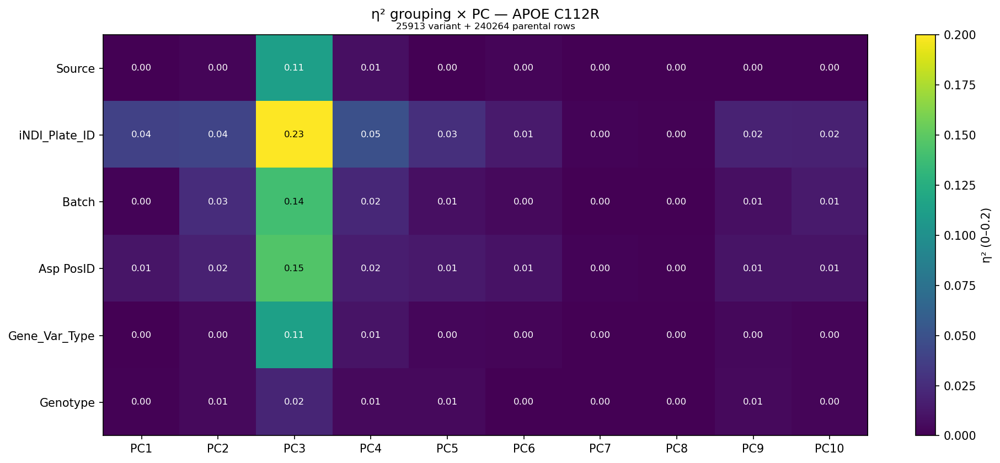

  APOE / R158C: 12681 variant + 240264 parental rows


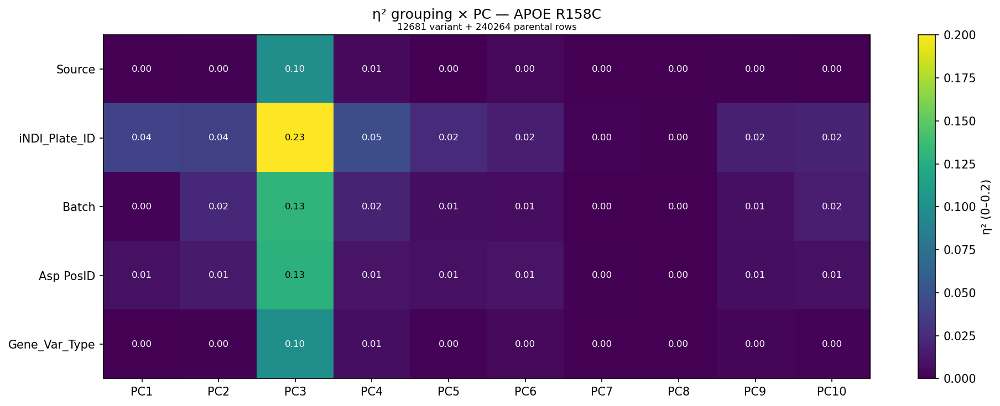

  APP / A673T: 51328 variant + 240264 parental rows


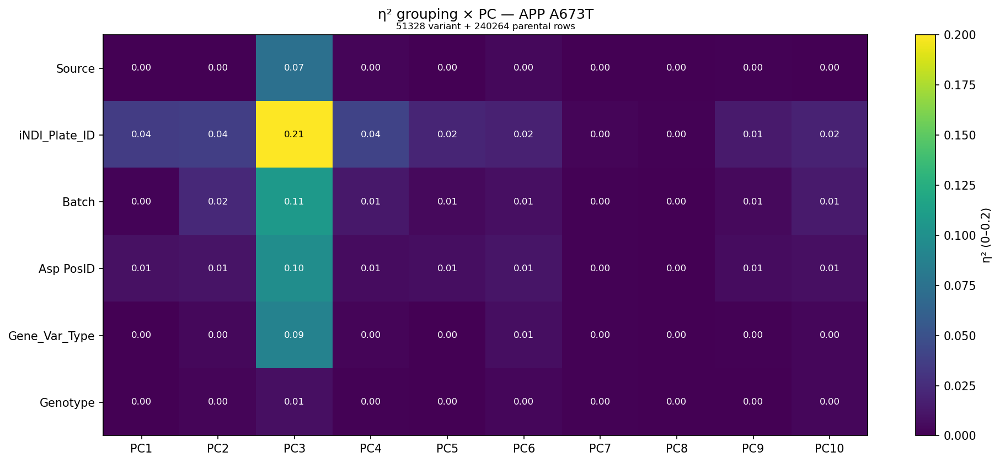

  APP / E693G: 44217 variant + 240264 parental rows


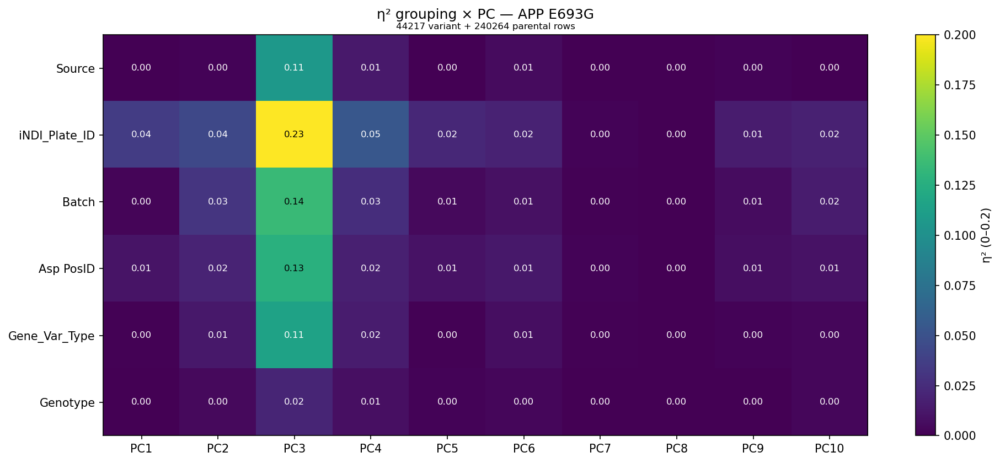

  APP / V717I: 23693 variant + 240264 parental rows


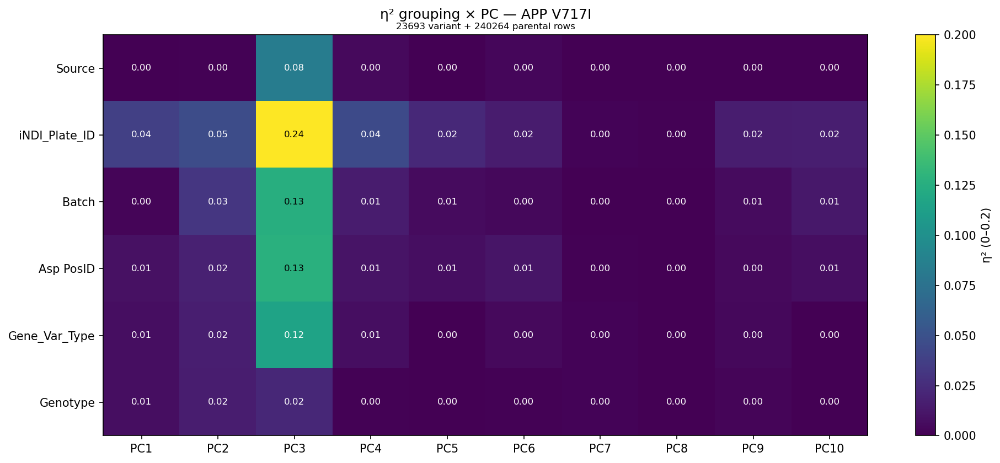

  FUS / R216C: 34494 variant + 240264 parental rows


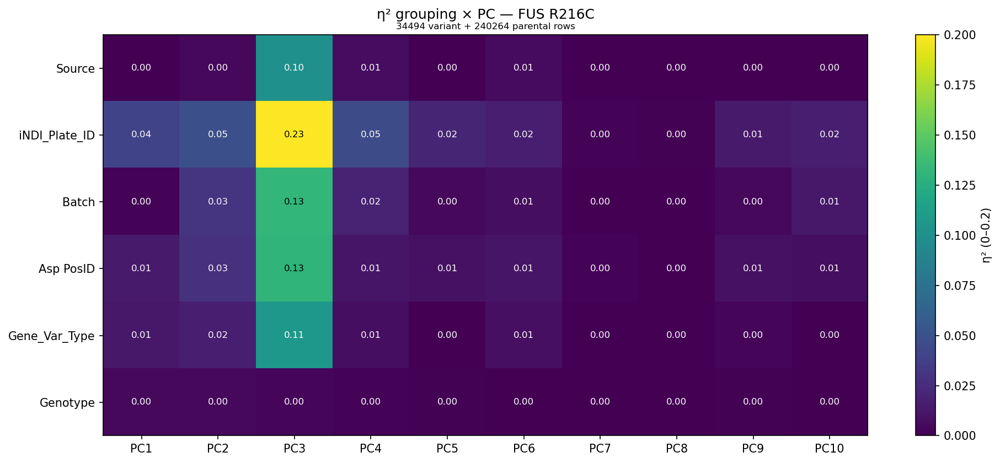

  FUS / R495X: 40568 variant + 240264 parental rows


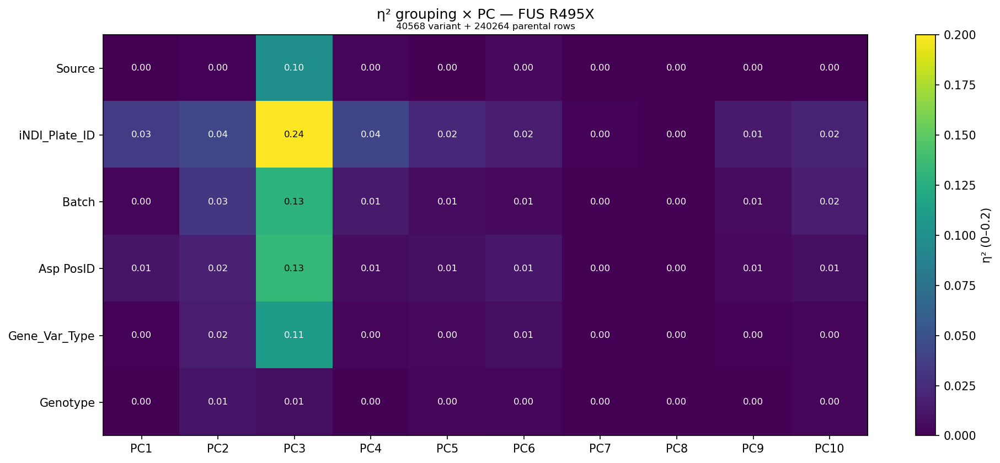

  GRN / Q125X: 47161 variant + 240264 parental rows


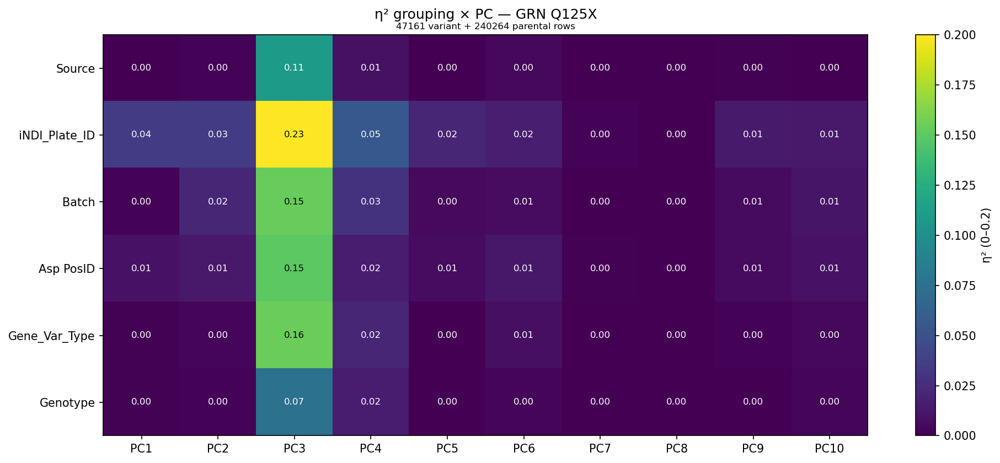

  HNRNPA1 / D262N: 42462 variant + 240264 parental rows


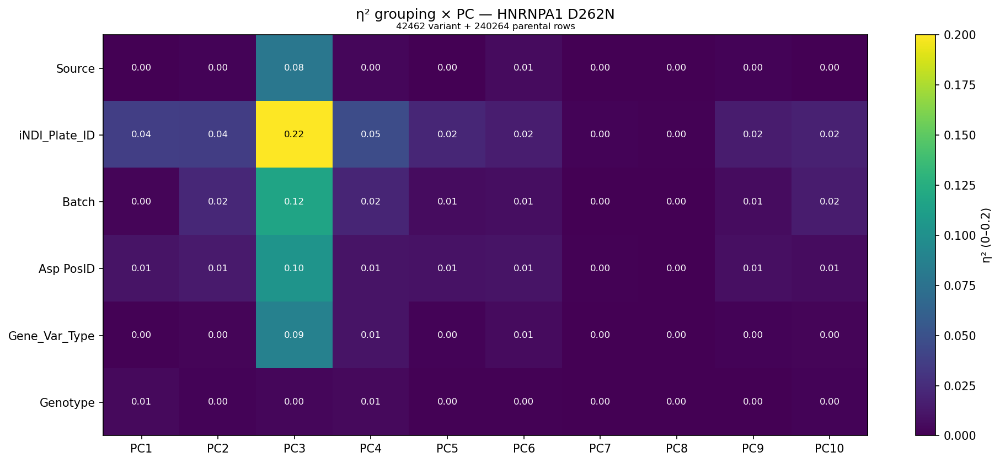

  MAPT / R406W: 59702 variant + 240264 parental rows


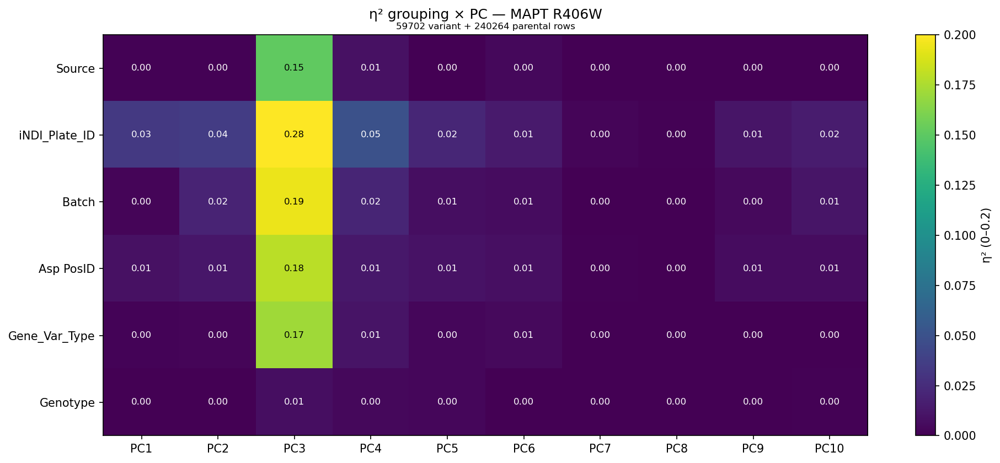

  PFN1 / C71G: 44243 variant + 240264 parental rows


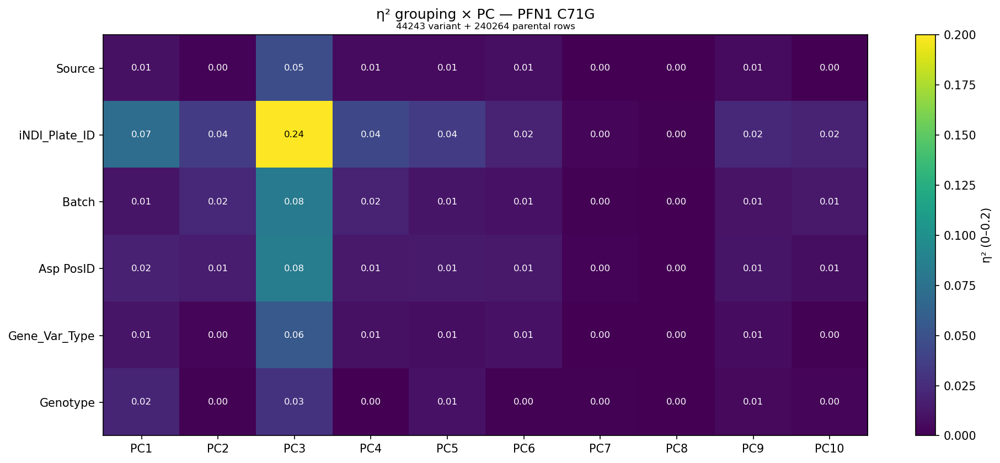

  PSEN1 / E276A: 20385 variant + 240264 parental rows


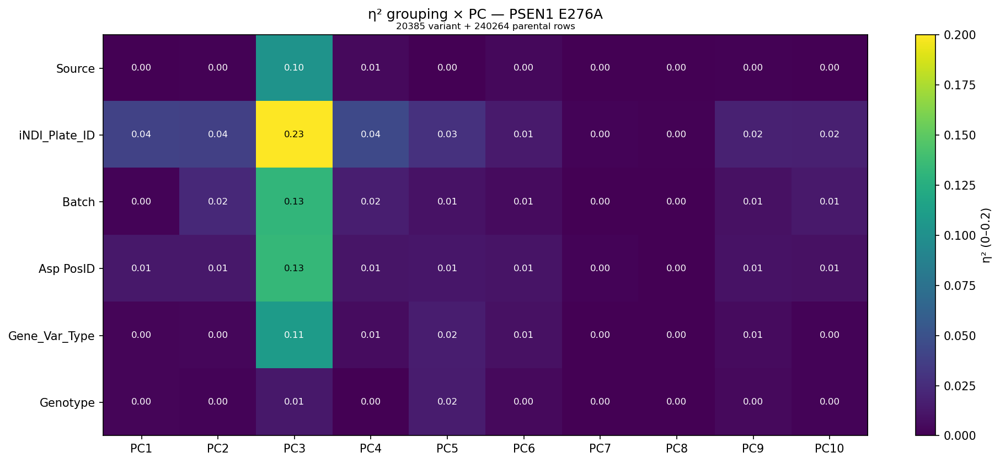

  PSEN2 / N141I: 37093 variant + 240264 parental rows


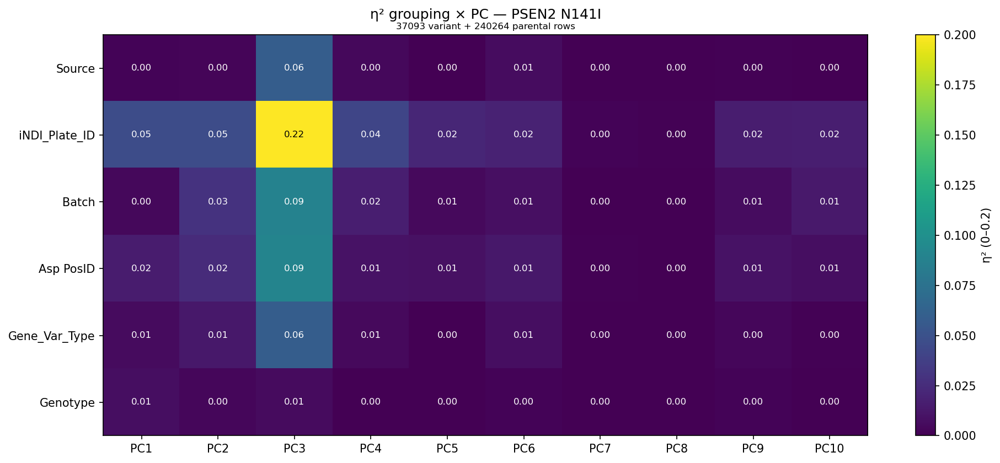

  SNCA / A53T: 27738 variant + 240264 parental rows


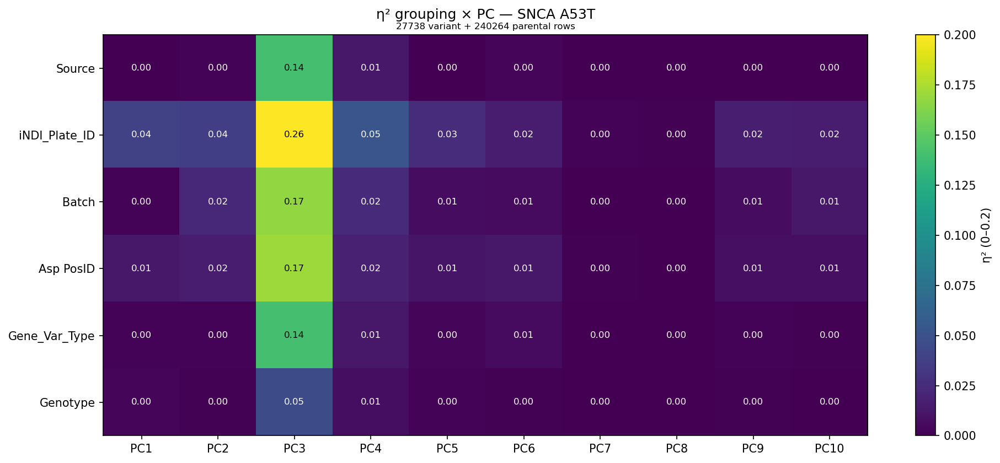

  SNCA / E46K: 38906 variant + 240264 parental rows


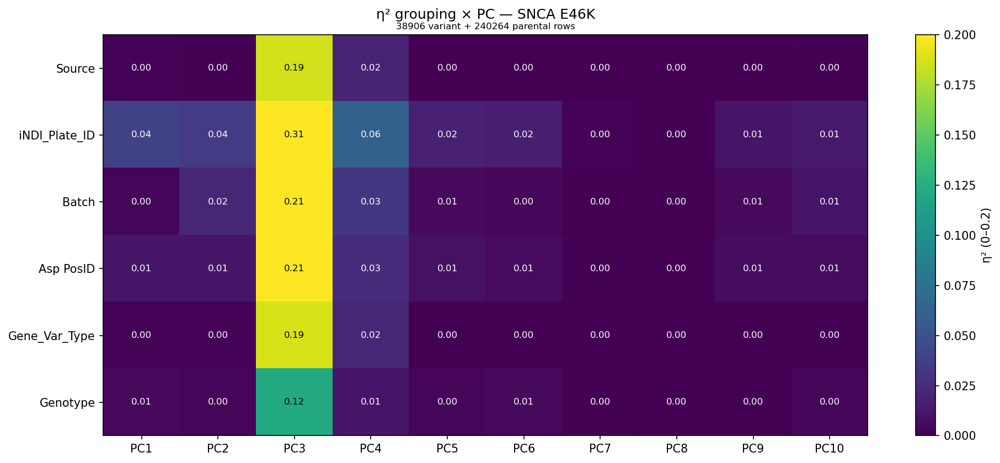

  SNCB / P123H: 31960 variant + 240264 parental rows


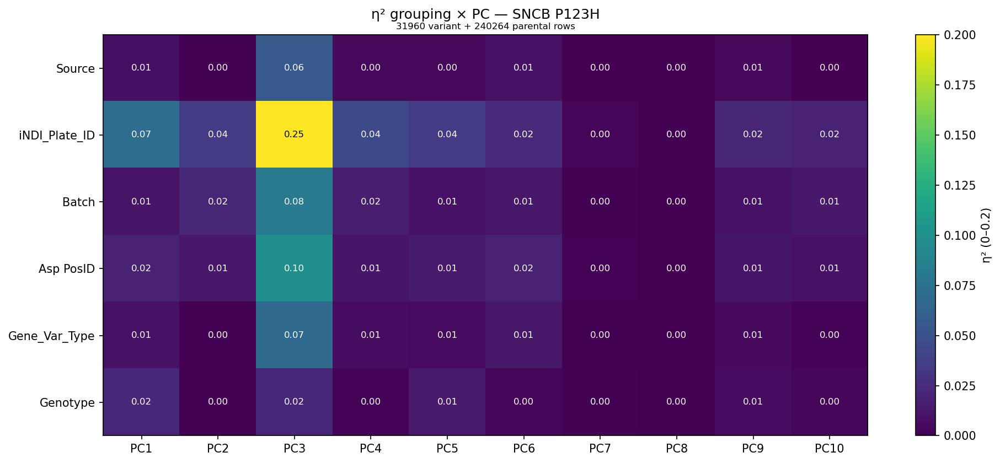

  TARDBP / M337V: 47370 variant + 240264 parental rows


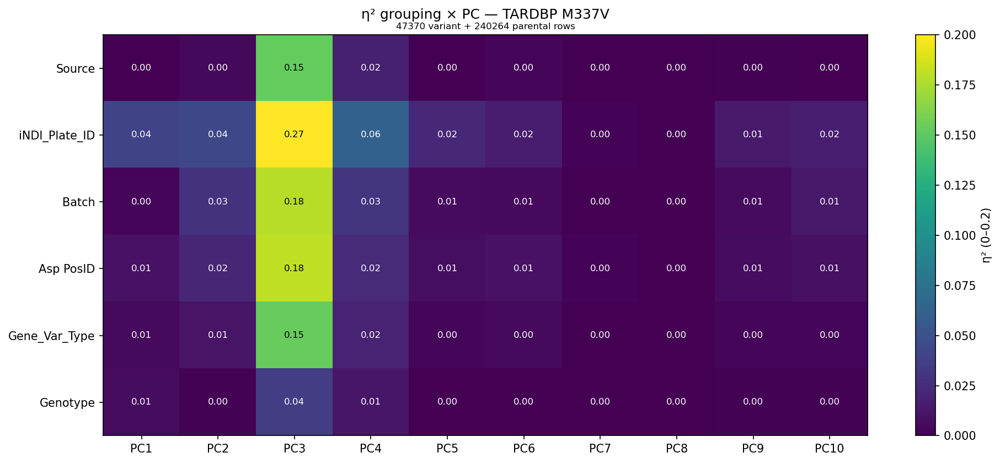

  TARDBP / Q331K: 50896 variant + 240264 parental rows


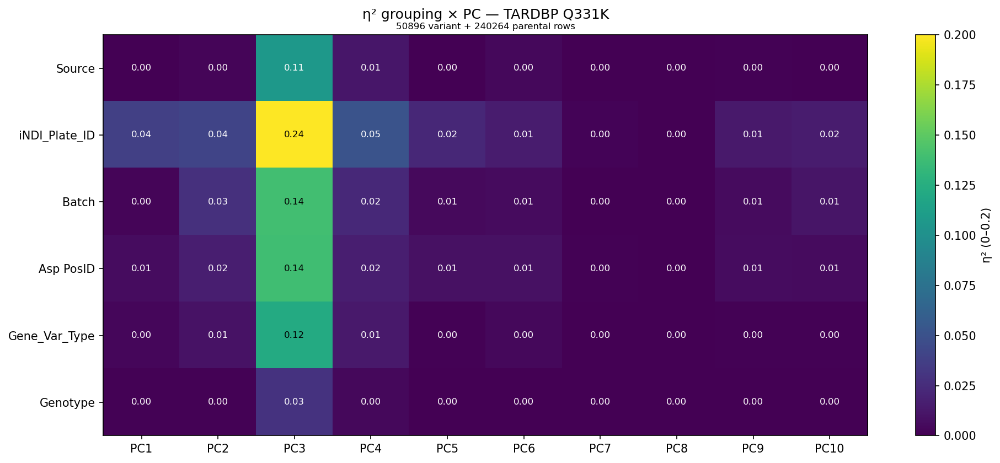

  TBK1 / E696K: 34975 variant + 240264 parental rows


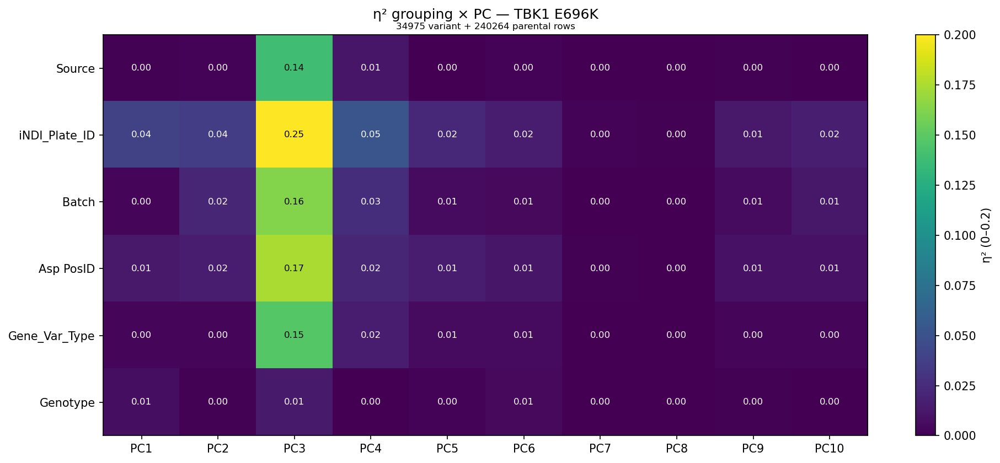

  TIA1 / P351L: 26006 variant + 240264 parental rows


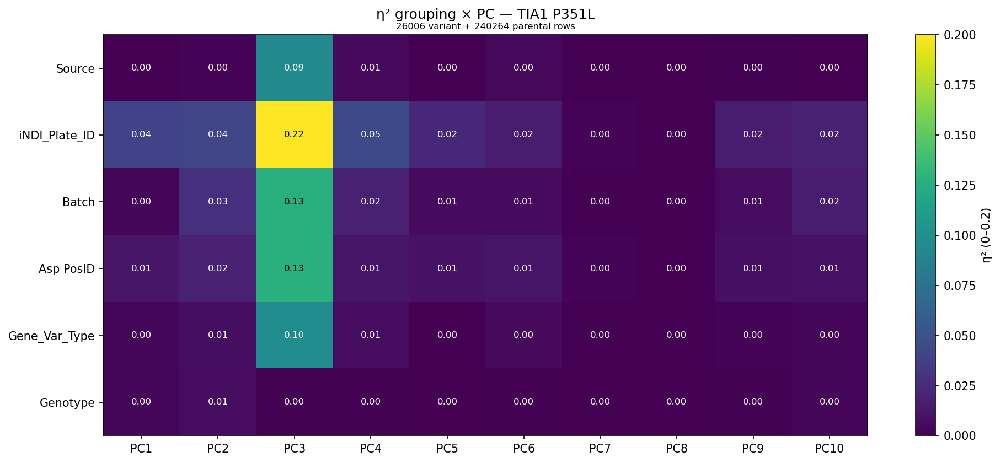

  UBQLN2 / P506T: 12810 variant + 240264 parental rows


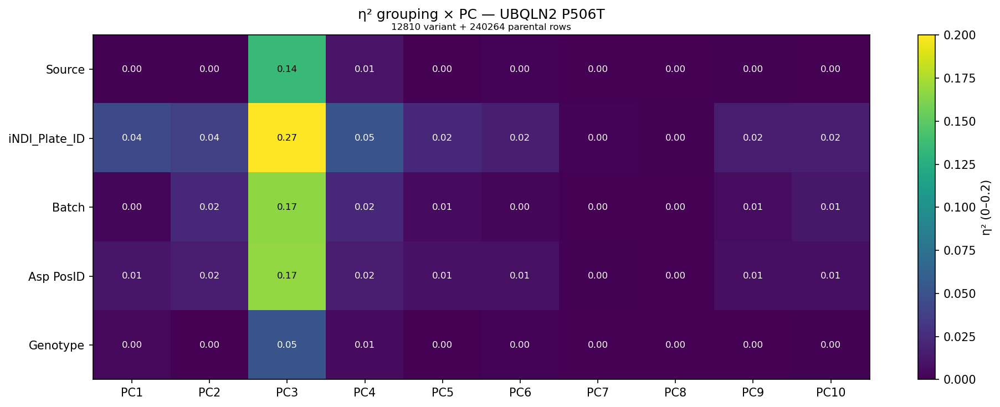

  VCP / R159H: 36548 variant + 240264 parental rows


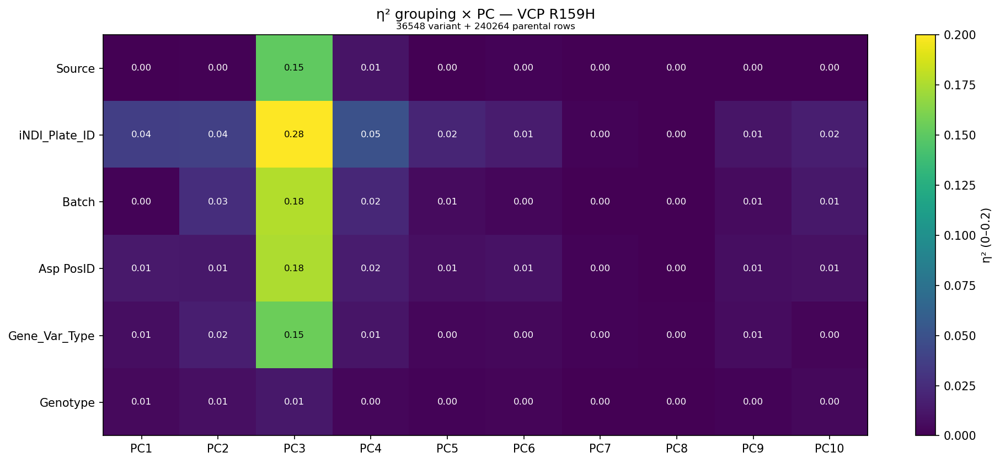

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- eta_squared ----------------------------------
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


# --- optional well-level aggregation (strongly recommended) ----------------
# A per-gene variant effect on a mean is invisible at single-nucleus level.
# Collapse ROI rows to one row per well before faceting.
def aggregate_to_wells(data, well_keys, carry_cols, pc_cols):
    agg = {pc: "median" for pc in pc_cols}
    for c in carry_cols:
        agg[c] = "first"
    return data.groupby(list(well_keys), as_index=False).agg(agg)


# --- shared WT/control predicate -------------------------------------------
def is_wt(data, gene_col="Gene"):
    """True for the shared KOLF2.1J parental-control rows (they live in Gene)."""
    return data[gene_col].astype(str).str.strip() == "KOLF2.1J"


# --- the original single-matrix eta computation, as a reusable helper -------
def eta_matrix(data, group_cols, pc_cols):
    """grouping x PC matrix of η² for one data subset (e.g. one gene facet)."""
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    return mat


# --- per-gene-variant: ONE SEPARATE FIGURE per facet -----------------------
def plot_gene_heatmap(sub, group_cols, pc_cols, gene, variant, vmax=0.2,
                      annot=True, drop_constant=True, subtitle=None):
    """Draw a single grouping x PC η² heatmap for one facet's subset."""
    rows = list(group_cols)
    if drop_constant:  # hide grouping rows with <2 levels in this facet
        rows = [g for g in rows if g in sub.columns and sub[g].nunique() > 1]
    mat = eta_matrix(sub, rows, pc_cols)

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(mat.index) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis",
                   vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(mat.index))); ax.set_yticklabels(mat.index)
    plt.colorbar(im, ax=ax, label=f"η² (0–{vmax})")
    ax.set_title(f"η² grouping × PC — {gene} {variant}", pad=14)
    if subtitle:
        ax.text(0.5, 1.01, subtitle, transform=ax.transAxes,
                ha="center", va="bottom", fontsize=8)
    if annot:
        for i in range(len(mat.index)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 * vmax else "black",
                            fontsize=8)
    plt.tight_layout(); plt.show()
    return mat


def facet_by_gene_variant(data, group_cols, n_pcs=10,
                          gene_col="Gene", variant_col="Variant", vmax=0.2,
                          annot=True, include_wt=True, drop_constant=True,
                          plate_match=False, plate_col="iNDI_Plate_ID"):
    """One separate η² heatmap figure per (gene, variant) pair. Each facet's
    subset is that single variant's rows plus the shared KOLF2.1J control rows.

    plate_match=True restricts the KOLF2.1J rows folded into each facet to the
    plates that variant actually occupies, removing the plate confound.
    """
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))[:n_pcs]

    wt_mask = is_wt(data, gene_col)
    wt_rows = data[wt_mask]
    edited = data[~wt_mask]

    # unique (gene, variant) pairs among edited rows
    pairs = (edited[[gene_col, variant_col]]
             .dropna()
             .drop_duplicates()
             .sort_values([gene_col, variant_col])
             .itertuples(index=False, name=None))
    pairs = list(pairs)

    print(f"[facet] {len(pairs)} (gene, variant) pairs; "
          f"{len(wt_rows)} total KOLF2.1J rows "
          f"{'(plate-matched per facet)' if plate_match else '(all folded into each facet)'}")

    # gene and variant are constant within a facet, so never use them as rows
    facet_groups = [g for g in group_cols
                    if g not in (gene_col, variant_col)]

    mats = {}
    for gene, variant in pairs:
        var_rows = edited[(edited[gene_col] == gene)
                          & (edited[variant_col] == variant)]
        if var_rows.empty:
            continue

        if include_wt:
            wt_use = wt_rows
            if plate_match and plate_col in data.columns:
                var_plates = set(var_rows[plate_col].dropna().unique())
                wt_use = wt_rows[wt_rows[plate_col].isin(var_plates)]
            plate_note = (f" on {len(set(var_rows[plate_col].dropna().unique()))} plate(s)"
                          if plate_match else "")
            subtitle = (f"{len(var_rows)} variant + {len(wt_use)} parental rows"
                        f"{plate_note}")
            sub = pd.concat([var_rows, wt_use], ignore_index=True)
            print(f"  {gene} / {variant}: {subtitle}")
        else:
            subtitle = f"{len(var_rows)} variant rows"
            sub = var_rows
            print(f"  {gene} / {variant}: {subtitle}")

        mats[(gene, variant)] = plot_gene_heatmap(
            sub, facet_groups, pc_cols, gene, variant,
            vmax=vmax, annot=annot, drop_constant=drop_constant,
            subtitle=subtitle)
    return mats


# --- usage -----------------------------------------------------------------
GROUP_COLS = ["Source", "iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Variant", "Genotype"]

# recommended: aggregate to wells first (adjust well_keys to your schema)
# pc_cols = sorted([c for c in df.columns if c.startswith("PC")], key=lambda s: int(s[2:]))[:10]
# well_df = aggregate_to_wells(
#     df,
#     well_keys=["iNDI_Plate_ID", "Row", "Column"],
#     carry_cols=GROUP_COLS + ["Gene"],
#     pc_cols=pc_cols,
# )
# facet_by_gene_variant(well_df, GROUP_COLS, n_pcs=10, vmax=0.2)

# or straight on ROI-level df (noisier):
mats = facet_by_gene_variant(df, GROUP_COLS, n_pcs=10, vmax=0.2)

## Well-level aggregation
### PCA plots

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 192954 rows (13440 images)
[full] well-level: 5931 rows
[full well] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full well] dropped 0 rows with NaN/inf; 5931 remain
[full well] EVR: [0.434 0.165 0.15  0.114 0.079 0.025 0.018 0.008 0.003 0.001 0.   ]
[full well] cumulative: [0.434 0.6   0.75  0.864 0.943 0.969 0.987 0.996 0.999 1.    1.   ]


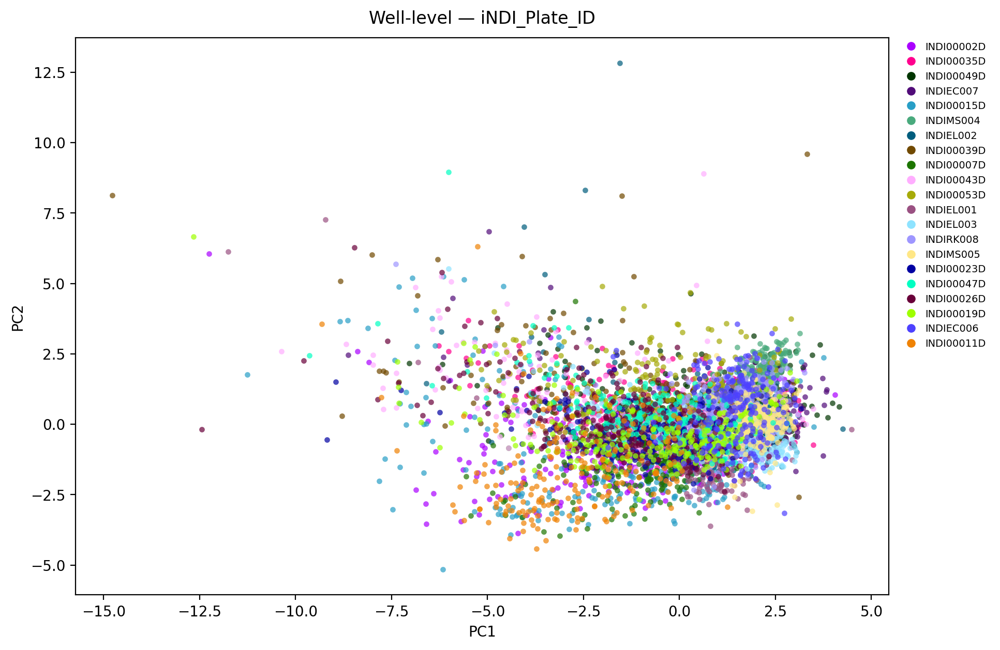

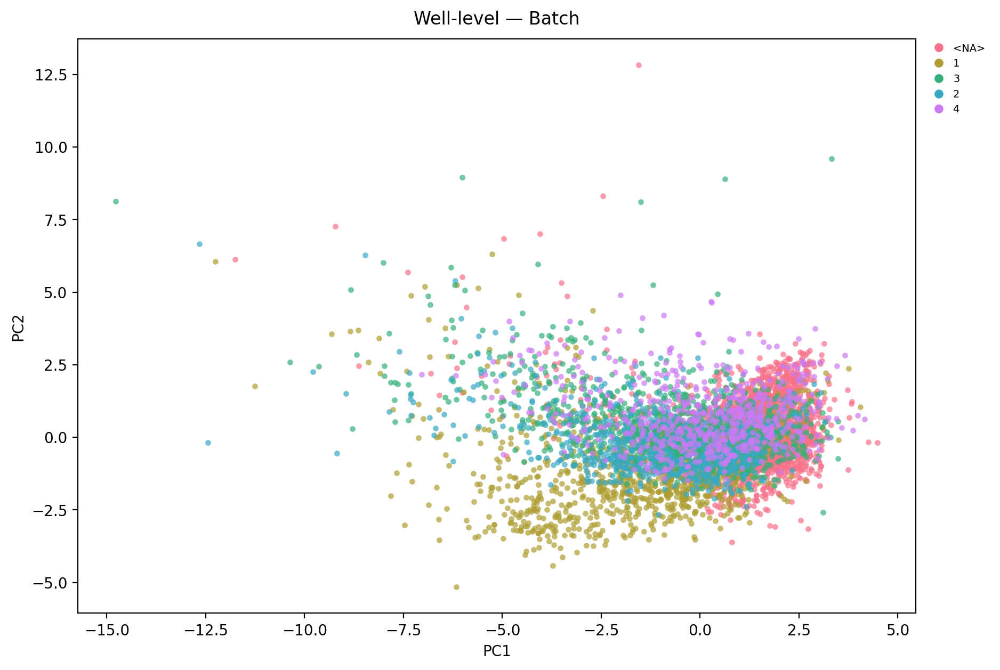

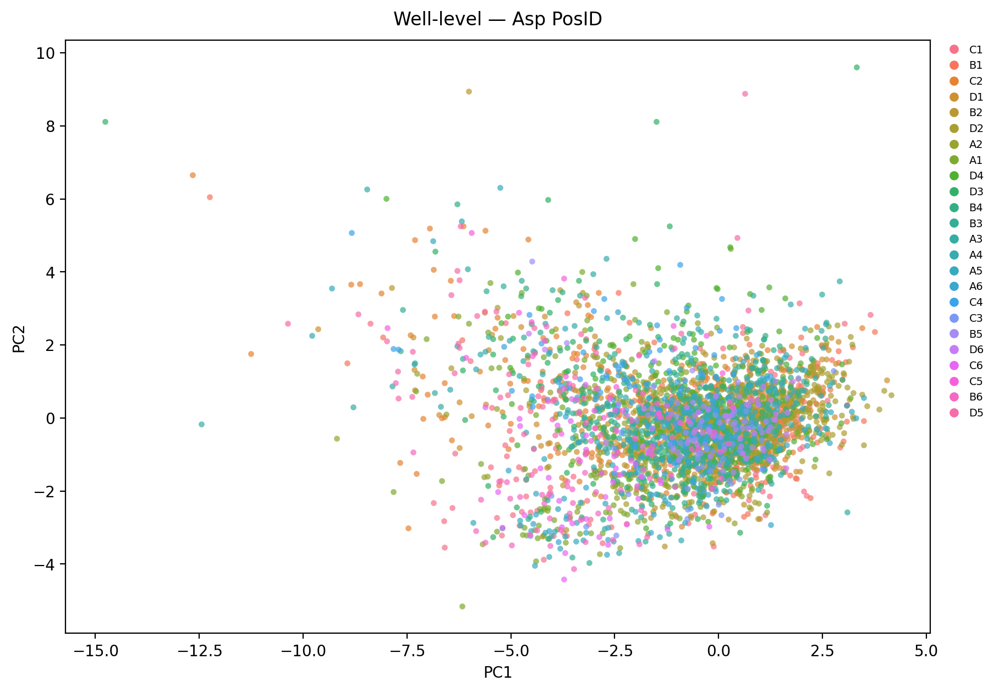

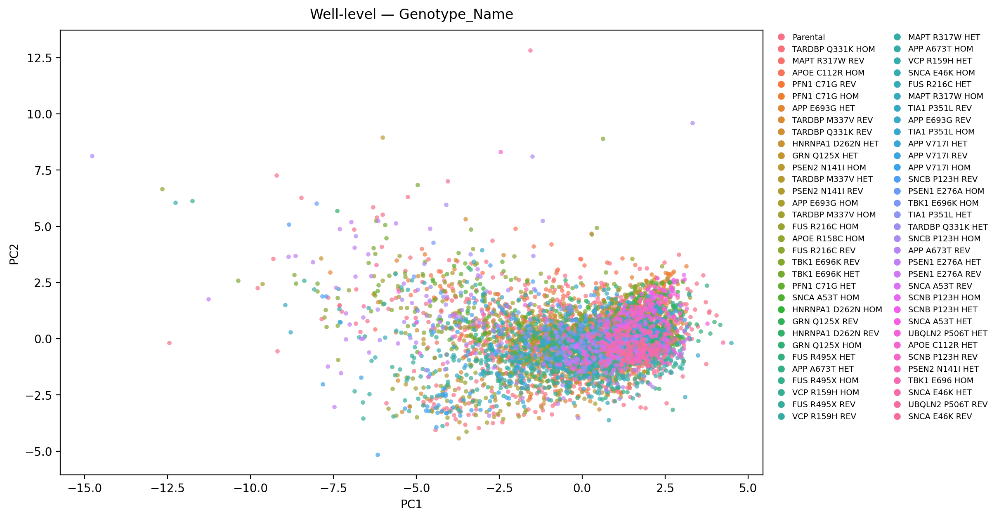

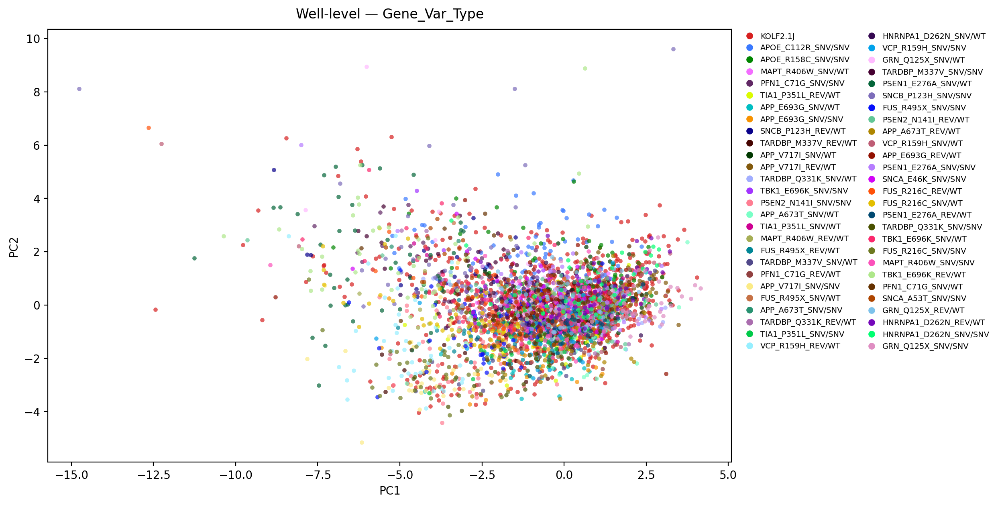

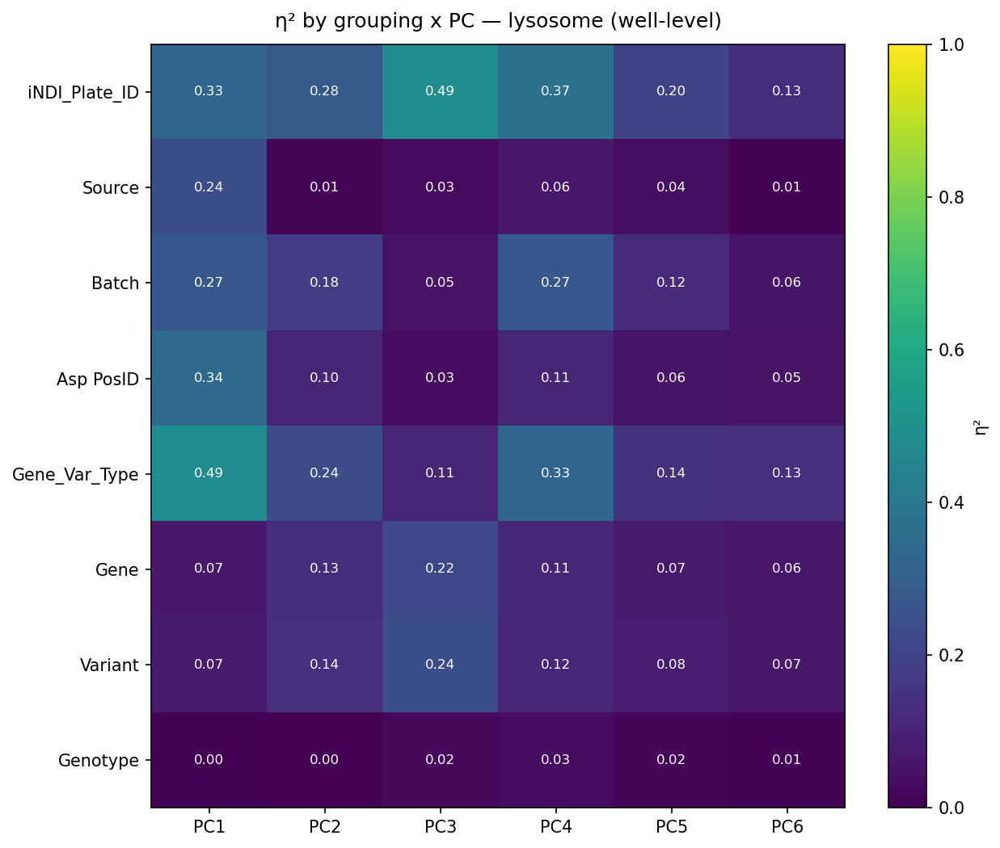

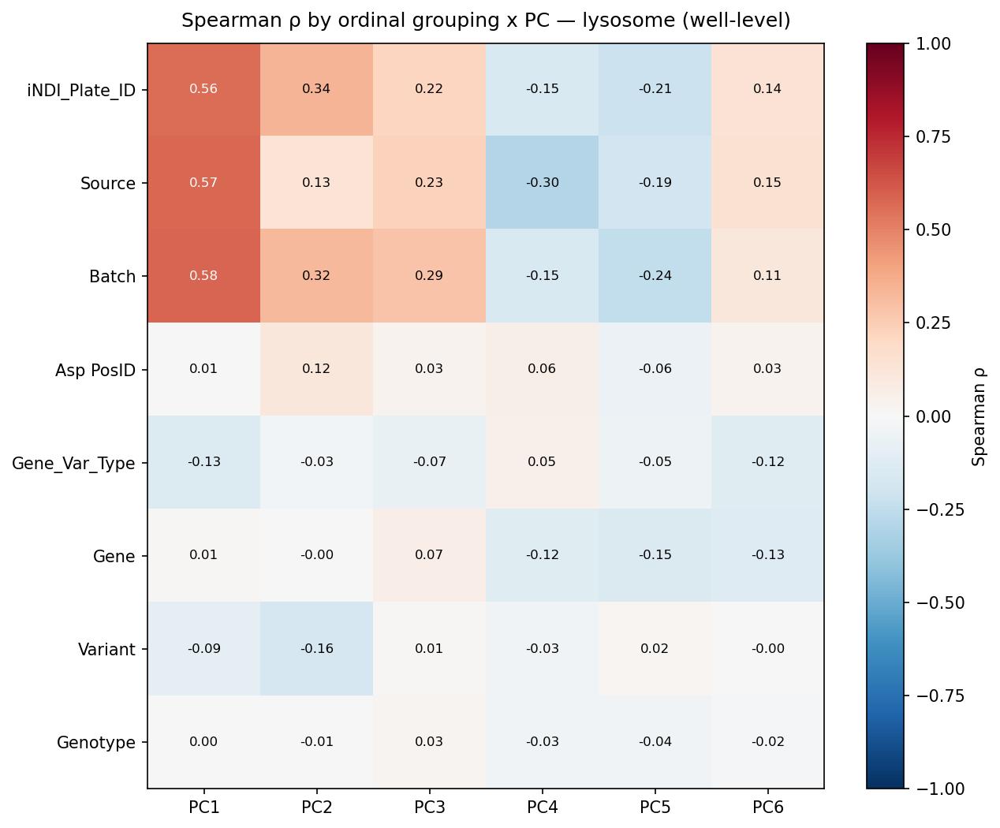

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.560485,0.339418,0.217627,-0.149617,-0.211455,0.144711
Source,0.574891,0.133108,0.229234,-0.295362,-0.189771,0.151188
Batch,0.582200,0.324233,0.286314,-0.154591,-0.243103,0.109665
Asp PosID,0.005450,0.115568,0.034493,0.058210,-0.056414,0.034039
Gene_Var_Type,-0.133213,-0.030581,-0.071157,0.050711,-0.048872,-0.122734
Gene,0.012475,-0.000447,0.066950,-0.120266,-0.146186,-0.127457
Variant,-0.086673,-0.164557,0.008534,-0.031541,0.020954,-0.004731
Genotype,0.001007,-0.005190,0.030678,-0.032444,-0.035998,-0.016933


In [12]:
import numpy as np
import pandas as pd

# well = Measurement_ID + subdirectory; image = channel_filename
WELL_KEYS = ["Measurement_ID", "subdirectory"]
IMAGE_KEY = "channel_filename"


def aggregate_wells(data, features, well_keys=WELL_KEYS, image_key=IMAGE_KEY,
                    check_cols=("Genotype_Name", "iNDI_Plate_ID", "prep_method"),
                    label="", image_stat="median", well_stat="mean",
                    n_pc_drop=20):
    """Collapse ROI -> image -> well.

    stage 1: `image_stat` across ROI within each image
    stage 2: `well_stat` across images within each well

    Metadata columns (everything that isn't a feature, PC, or key) are carried
    through with .first(), after a safety check that they're invariant within a
    well. Returns the well-level dataframe (NOT PCA-scored -- run fit_pca next).
    """
    features = [f for f in features if f in data.columns]
    group_keys = [*well_keys, image_key]
    drop_cols = (set(features) | {f"PC{i+1}" for i in range(n_pc_drop)}
                 | set(group_keys) | {"label", "filename", "filepath"})
    meta_cols = [c for c in data.columns if c not in drop_cols]
    n_in = data[well_keys].drop_duplicates().shape[0]

    # safety: metadata carried by .first() should be invariant within a well
    for col in check_cols:
        if col in data.columns:
            n_bad = (data.groupby(well_keys)[col].nunique() > 1).sum()
            print(f"[{label}] {col}: {n_bad} well(s) with >1 value"
                  f"{'  <-- CHECK' if n_bad else ''}")

    # stage 1: within-image summary
    agg_image = {**{f: image_stat for f in features},
                 **{m: "first" for m in meta_cols}}
    image_level = data.groupby(group_keys, as_index=False).agg(agg_image)
    print(f"[{label}] image-level: {len(image_level)} rows "
          f"({data[image_key].nunique()} images)")

    # stage 2: within-well summary across images
    agg_well = {**{f: well_stat for f in features},
                **{m: "first" for m in meta_cols}}
    well_level = image_level.groupby(well_keys, as_index=False).agg(agg_well)
    print(f"[{label}] well-level: {len(well_level)} rows")
    assert len(well_level) == n_in, "wells lost in aggregation"

    return well_level


# --- usage -----------------------------------------------------------------
# aggregate, then reuse the SAME fit_pca from the feature section (don't
# re-implement the scale/PCA/score here):
#
# well_level = aggregate_wells(df, FEATURES, label="full")
# well_level, pca_well, _ = fit_pca(
#     well_level, features=FEATURES, add_aspect_ratio=False,
#     show_scree=False, show_loadings=False, label="full well",
# )


well_level = aggregate_wells(df, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)
well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"],
            n_pcs=6, title="η² by grouping x PC — lysosome (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — lysosome (well-level)")

### Variance-component analysis
This is built to handle all of the parental data for each genotype, but remember that this is HIGHLY unbalanced.\
"plate_match=True" will correct for this by only pulling parentals from the plates that each genotype is on, which is more accurate, but NOT a proxy for plate correction

[facet] 22 (gene, variant) pairs; 1443 total KOLF2.1J rows (all folded into each facet)
  APOE / C112R: 135 variant + 1443 parental rows


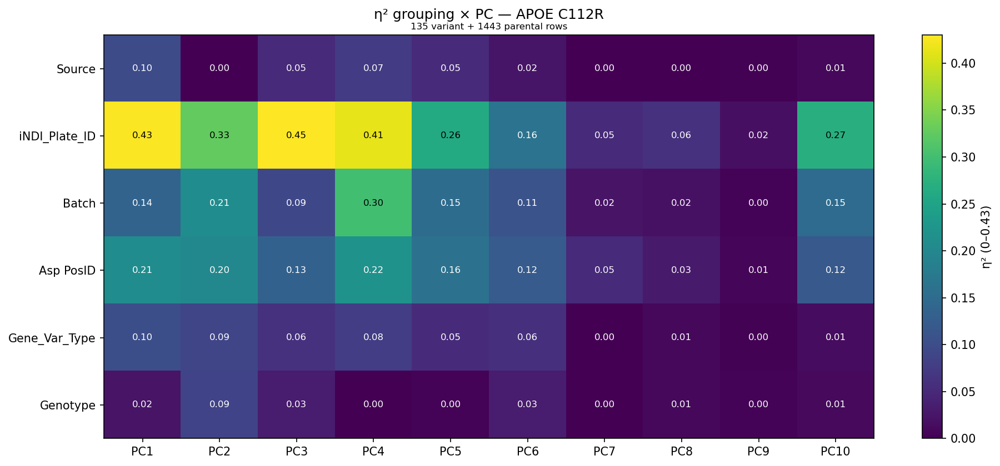

  APOE / R158C: 89 variant + 1443 parental rows


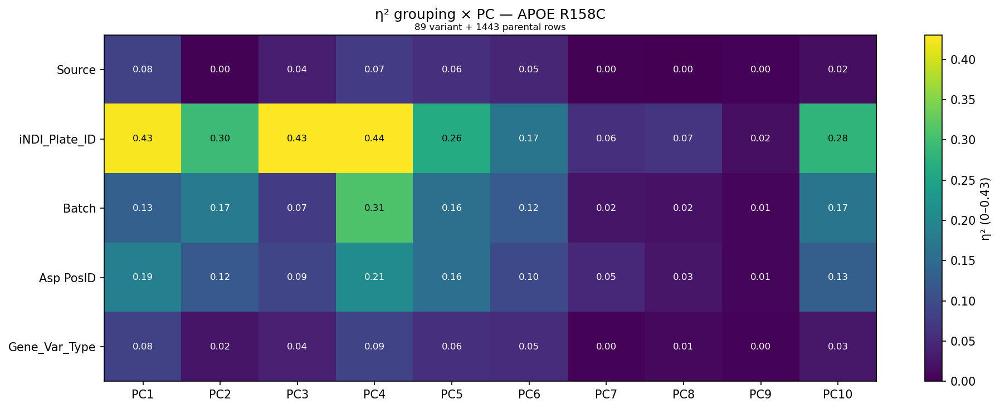

  APP / A673T: 200 variant + 1443 parental rows


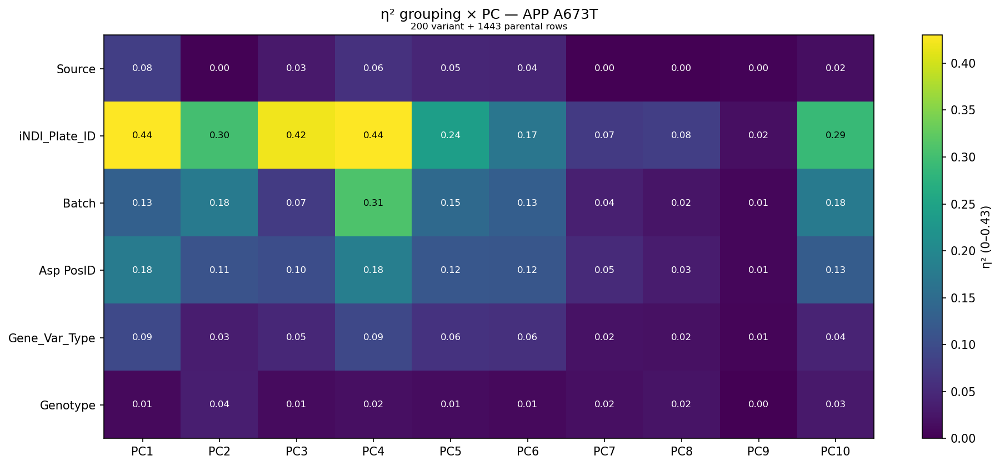

  APP / E693G: 228 variant + 1443 parental rows


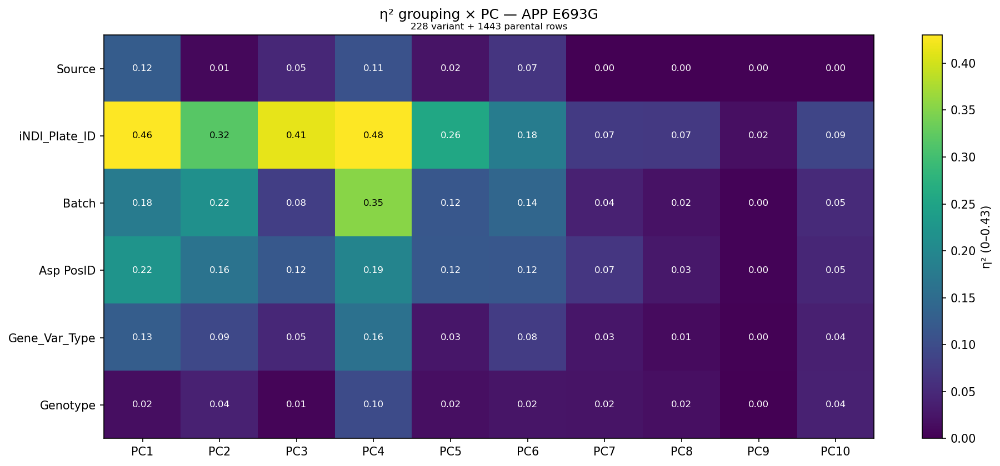

  APP / V717I: 144 variant + 1443 parental rows


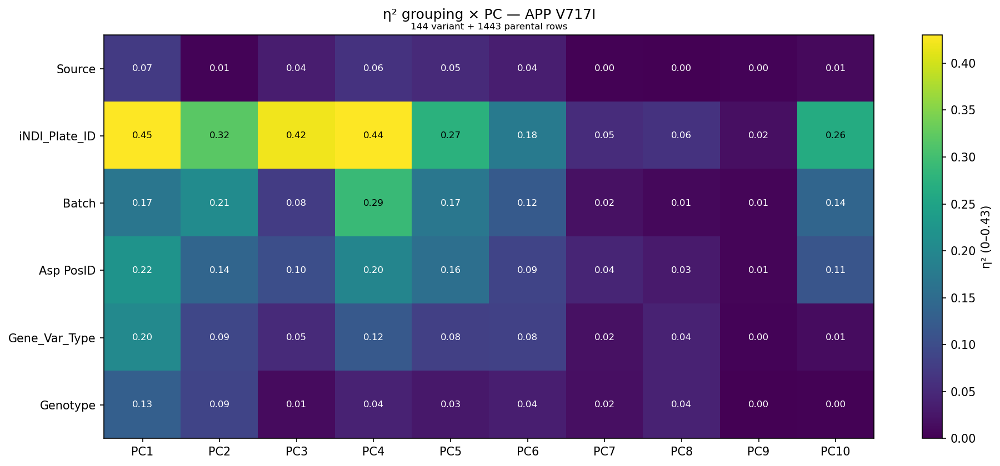

  FUS / R216C: 253 variant + 1443 parental rows


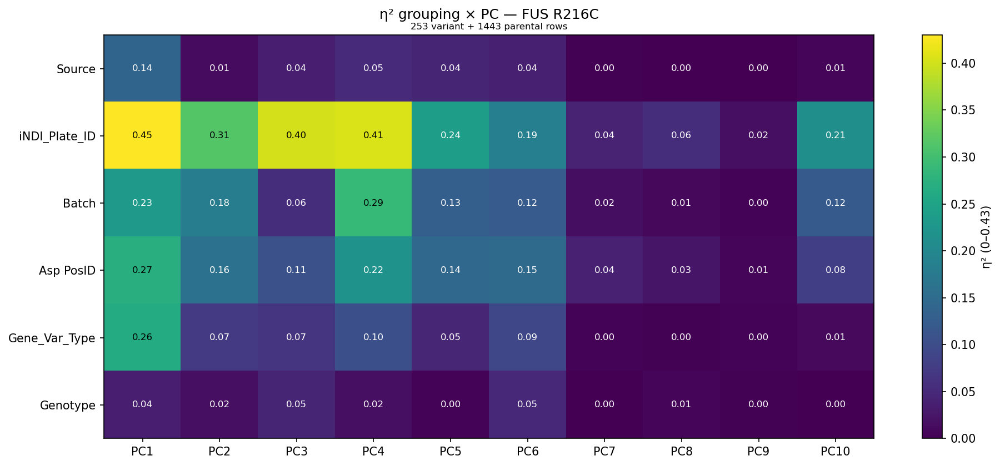

  FUS / R495X: 228 variant + 1443 parental rows


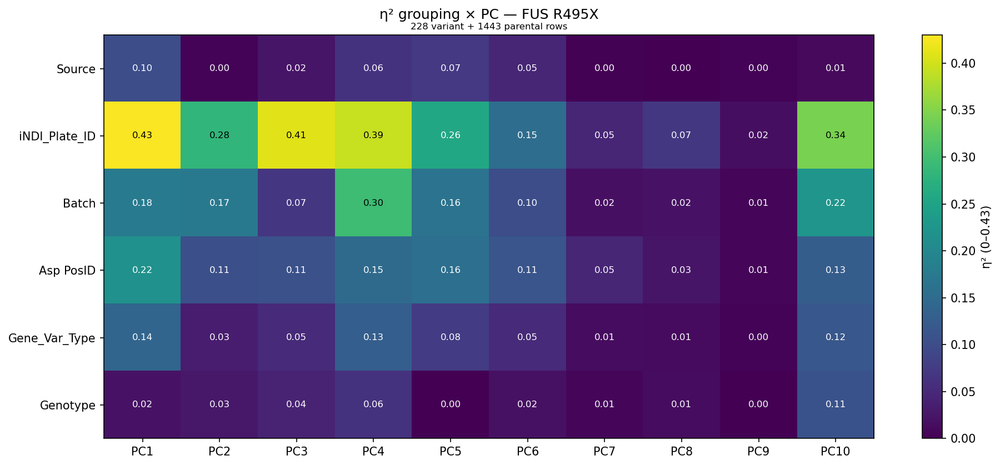

  GRN / Q125X: 260 variant + 1443 parental rows


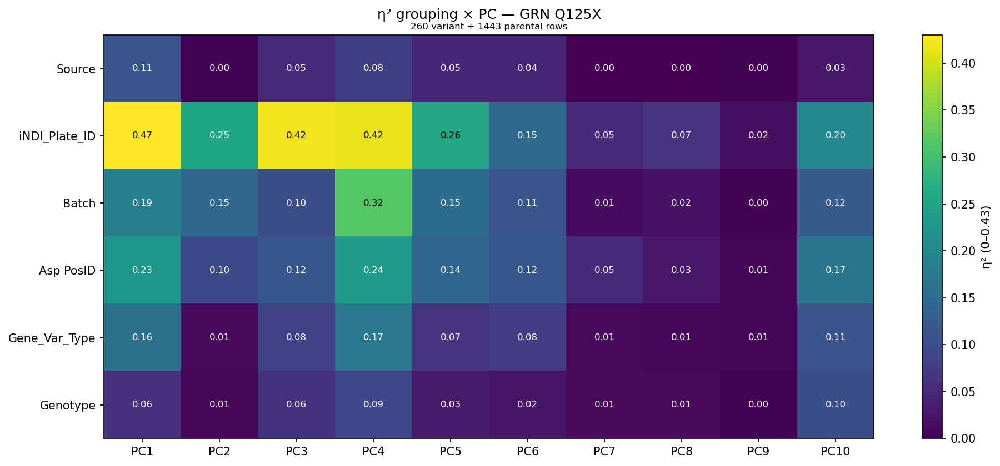

  HNRNPA1 / D262N: 261 variant + 1443 parental rows


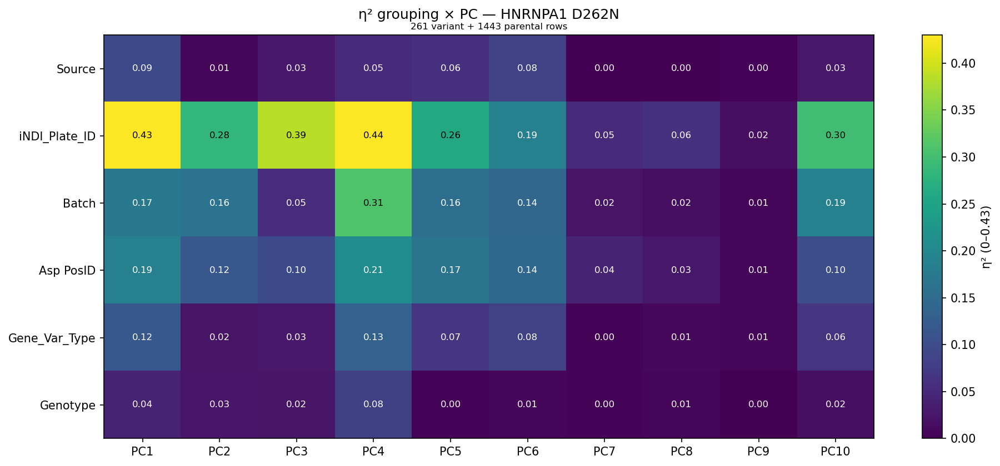

  MAPT / R406W: 255 variant + 1443 parental rows


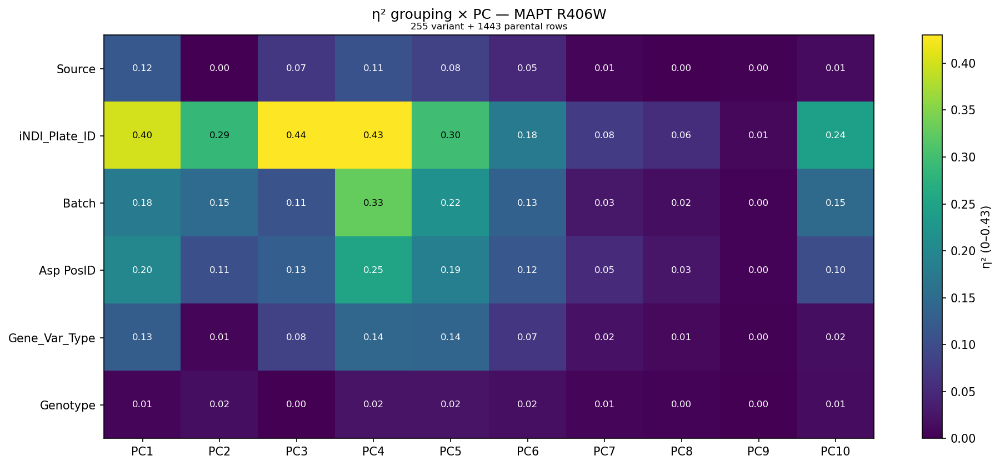

  PFN1 / C71G: 268 variant + 1443 parental rows


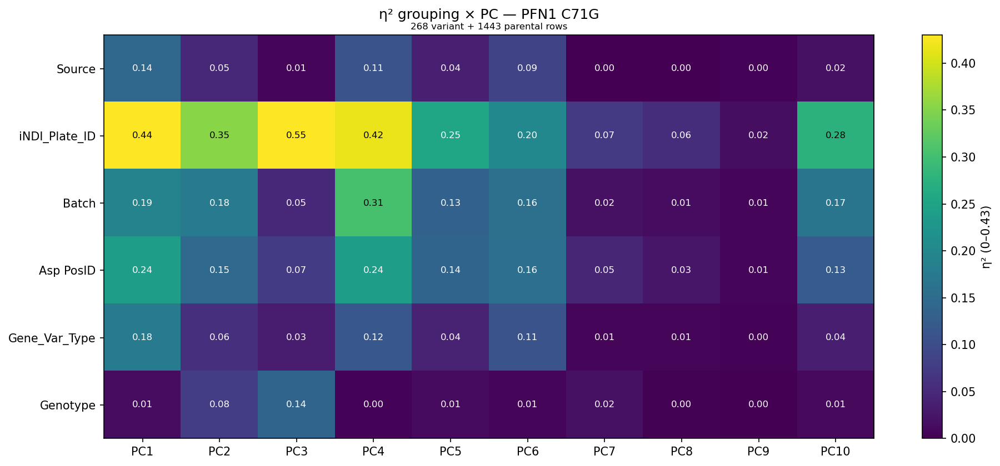

  PSEN1 / E276A: 143 variant + 1443 parental rows


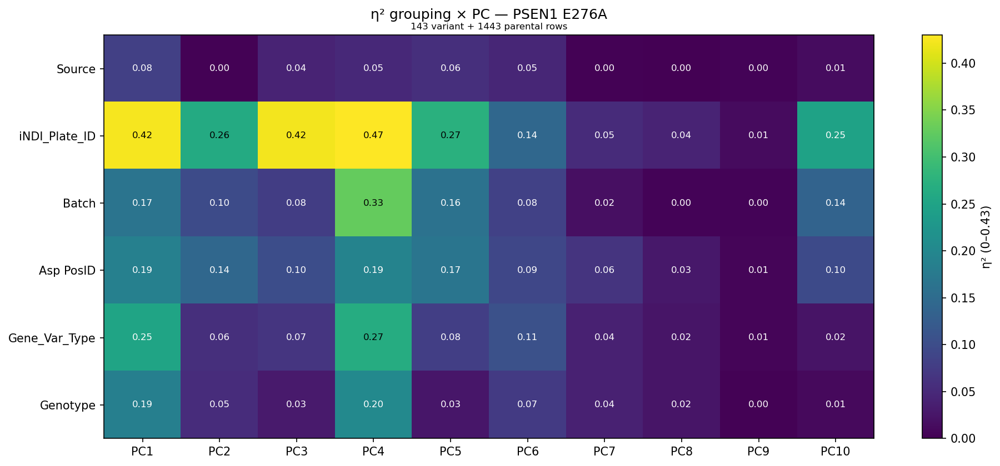

  PSEN2 / N141I: 222 variant + 1443 parental rows


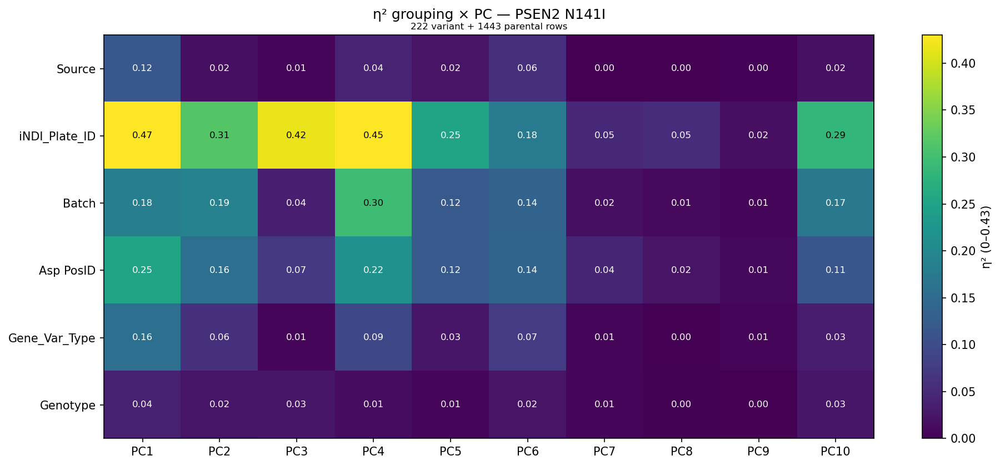

  SNCA / A53T: 172 variant + 1443 parental rows


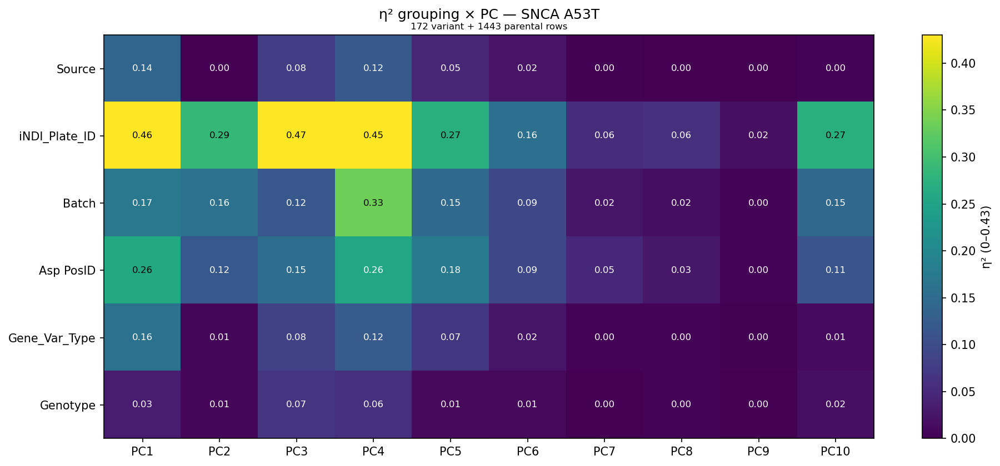

  SNCA / E46K: 146 variant + 1443 parental rows


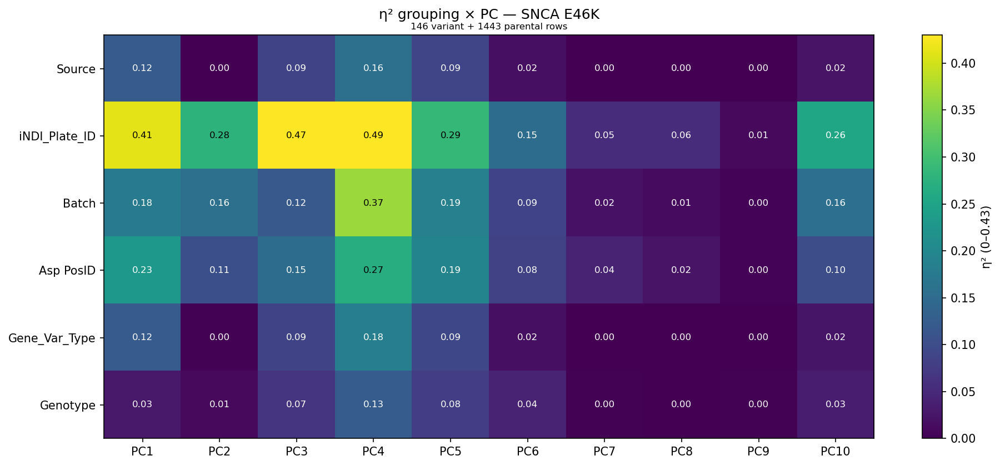

  SNCB / P123H: 222 variant + 1443 parental rows


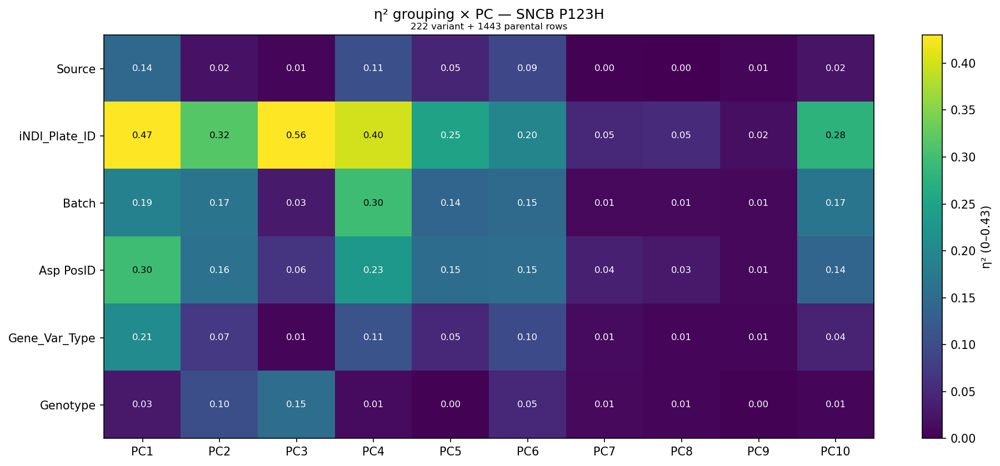

  TARDBP / M337V: 270 variant + 1443 parental rows


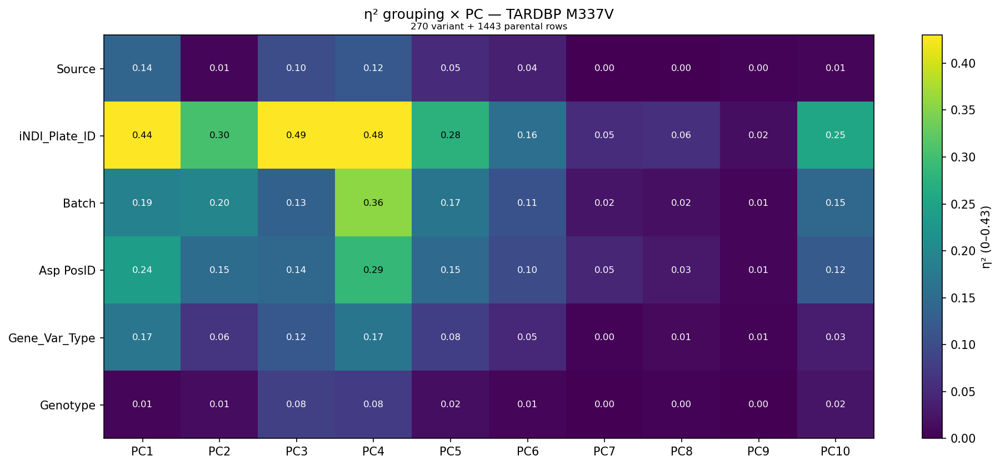

  TARDBP / Q331K: 269 variant + 1443 parental rows


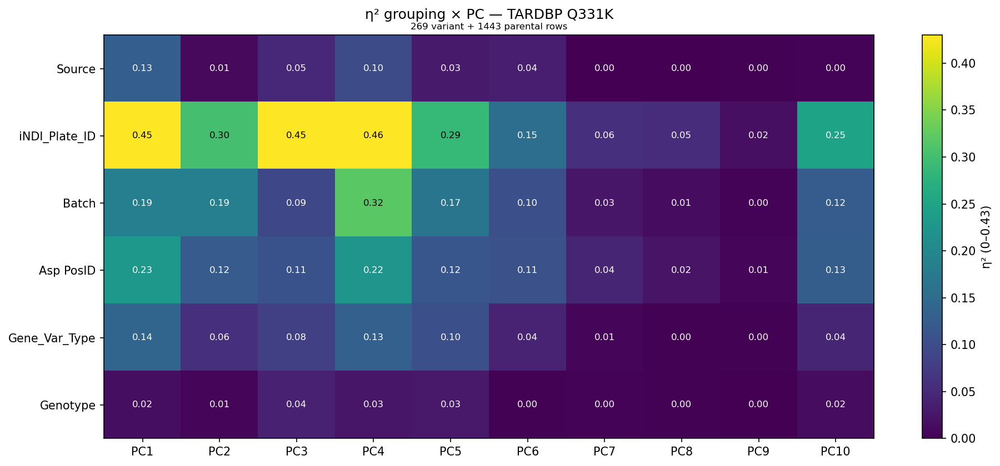

  TBK1 / E696K: 268 variant + 1443 parental rows


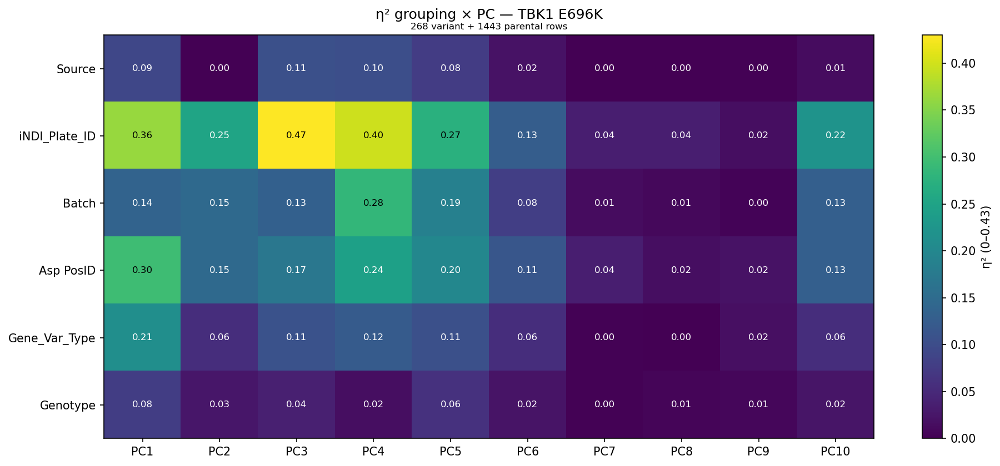

  TIA1 / P351L: 144 variant + 1443 parental rows


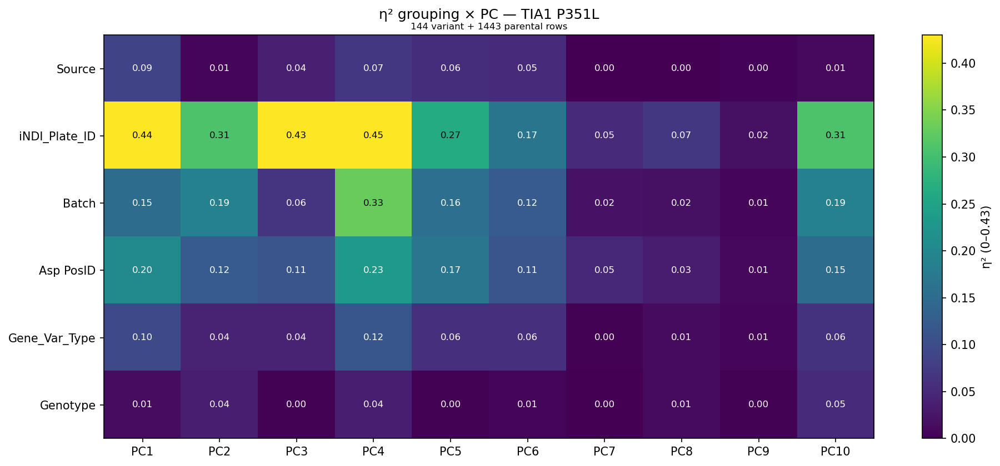

  UBQLN2 / P506T: 83 variant + 1443 parental rows


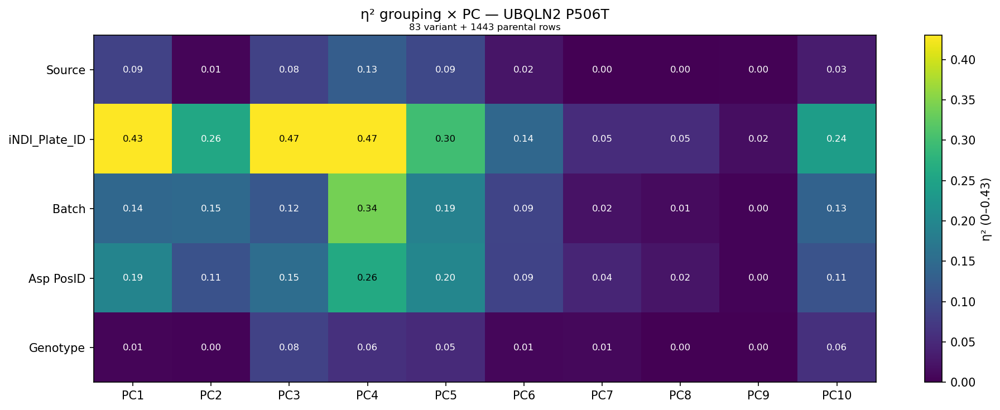

  VCP / R159H: 228 variant + 1443 parental rows


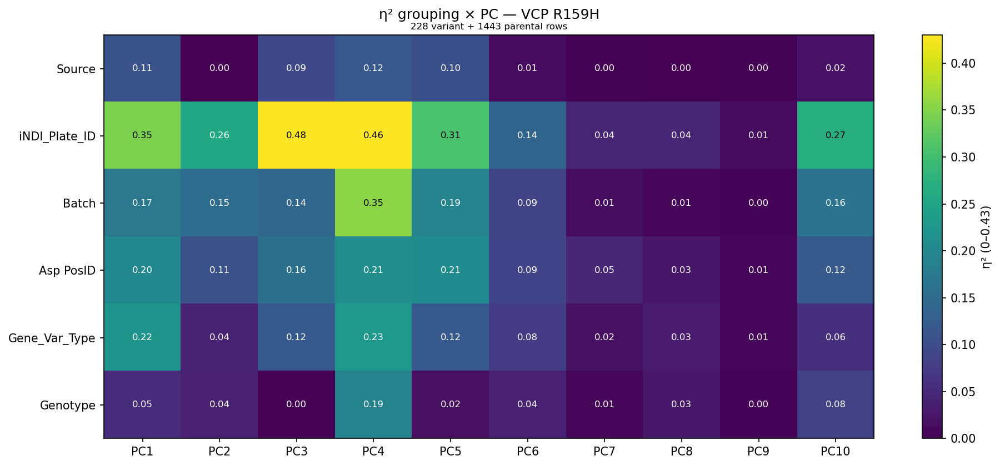

[facet] 22 (gene, variant) pairs; 1443 total KOLF2.1J rows (plate-matched per facet)
  APOE / C112R: 135 variant + 136 parental rows on 2 plate(s)


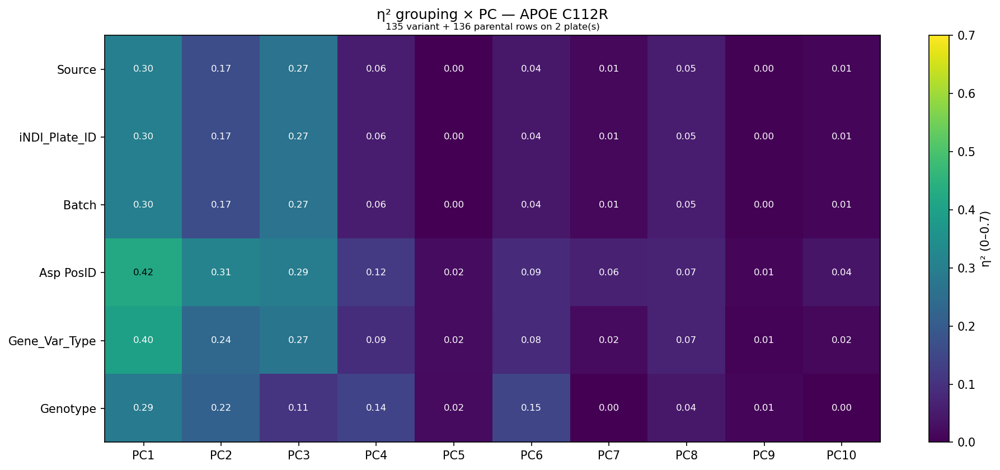

  APOE / R158C: 89 variant + 185 parental rows on 2 plate(s)


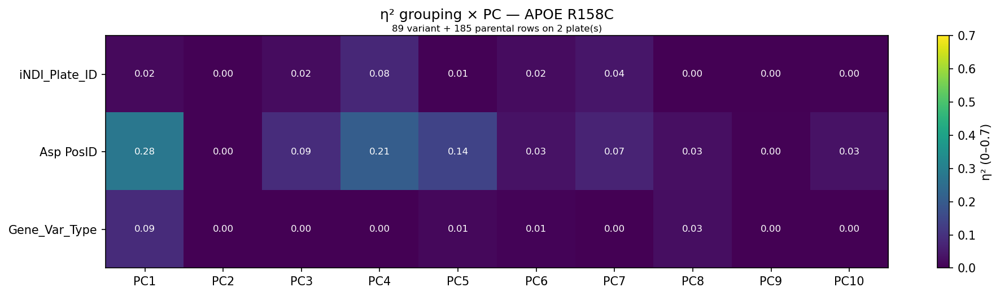

  APP / A673T: 200 variant + 197 parental rows on 3 plate(s)


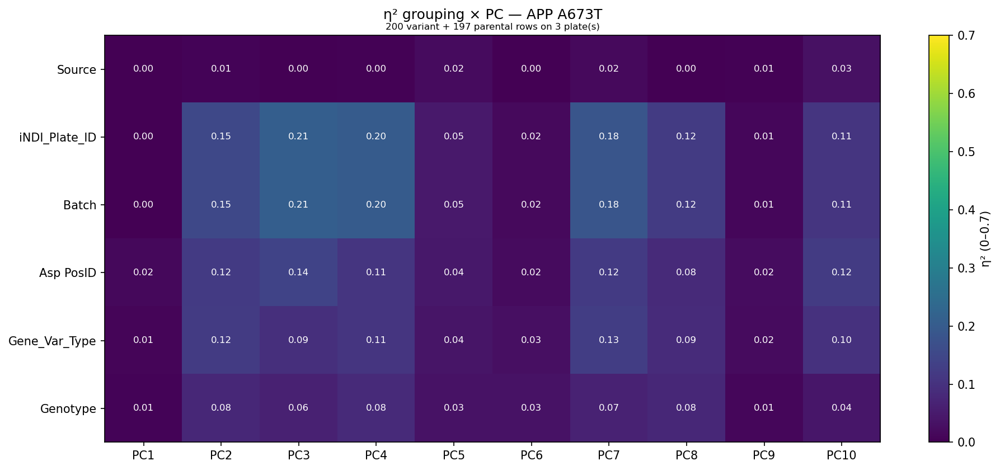

  APP / E693G: 228 variant + 186 parental rows on 3 plate(s)


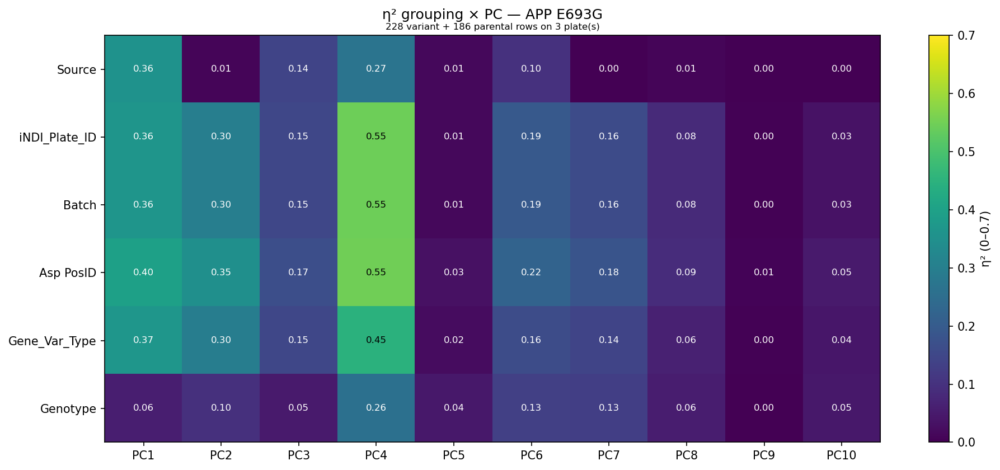

  APP / V717I: 144 variant + 144 parental rows on 2 plate(s)


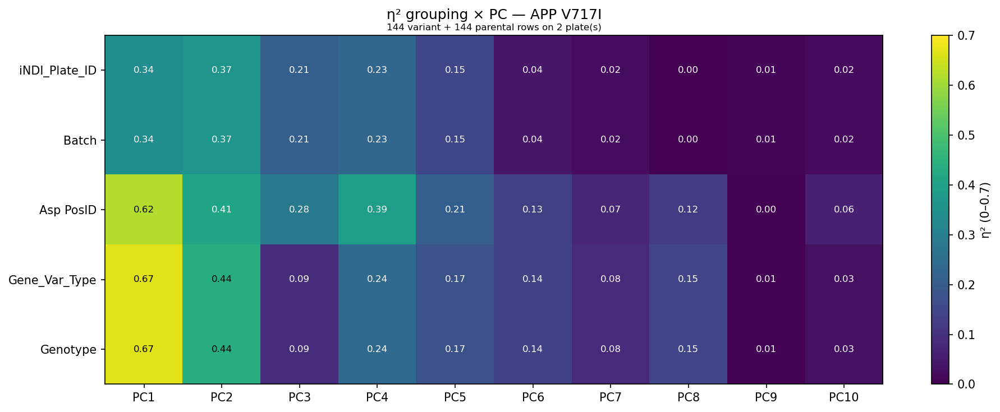

  FUS / R216C: 253 variant + 328 parental rows on 5 plate(s)


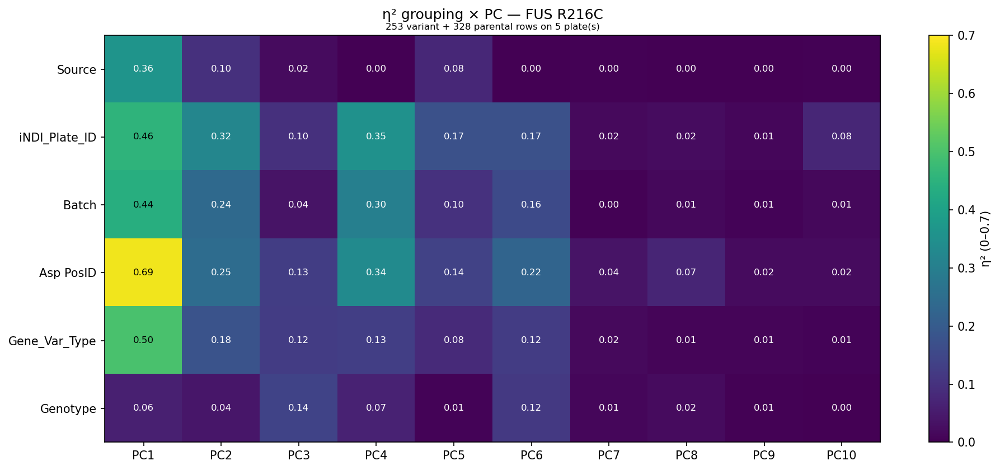

  FUS / R495X: 228 variant + 149 parental rows on 2 plate(s)


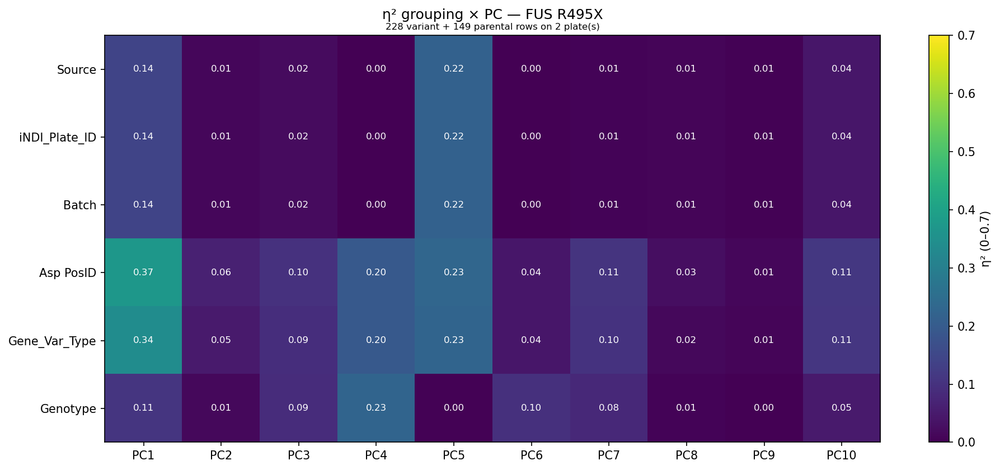

  GRN / Q125X: 260 variant + 270 parental rows on 4 plate(s)


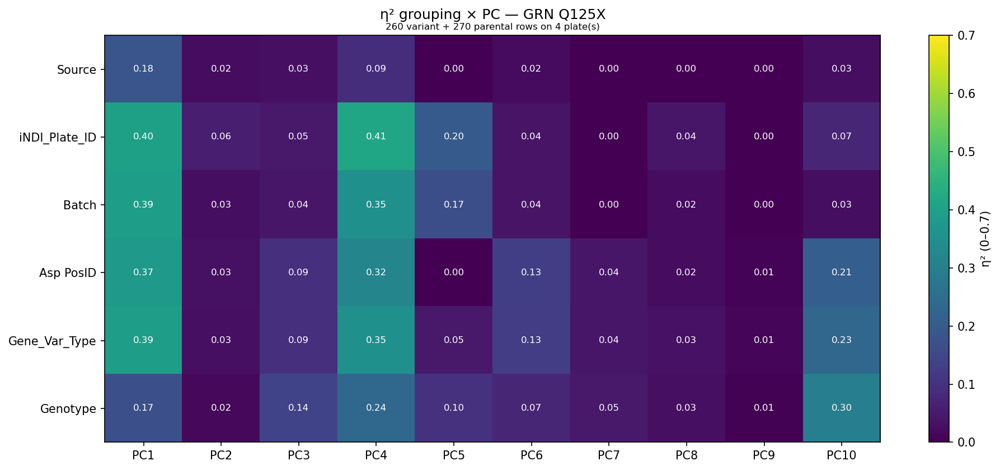

  HNRNPA1 / D262N: 261 variant + 197 parental rows on 3 plate(s)


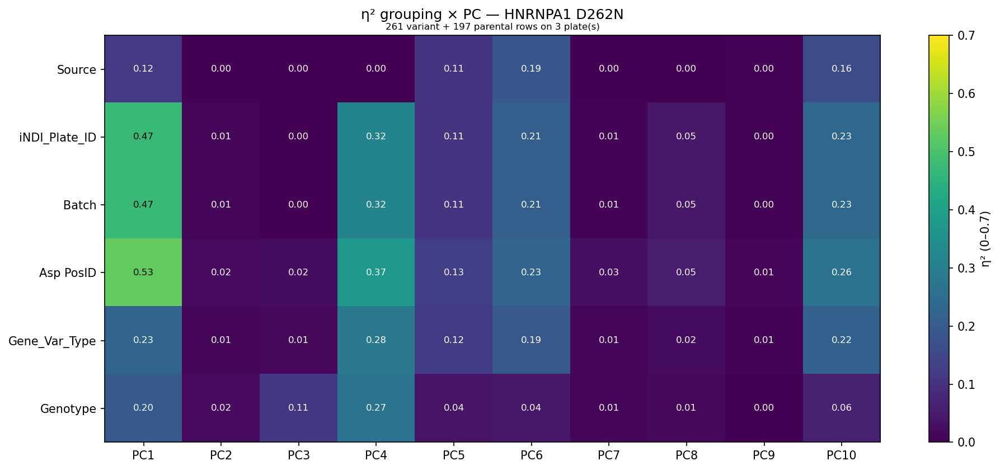

  MAPT / R406W: 255 variant + 176 parental rows on 3 plate(s)


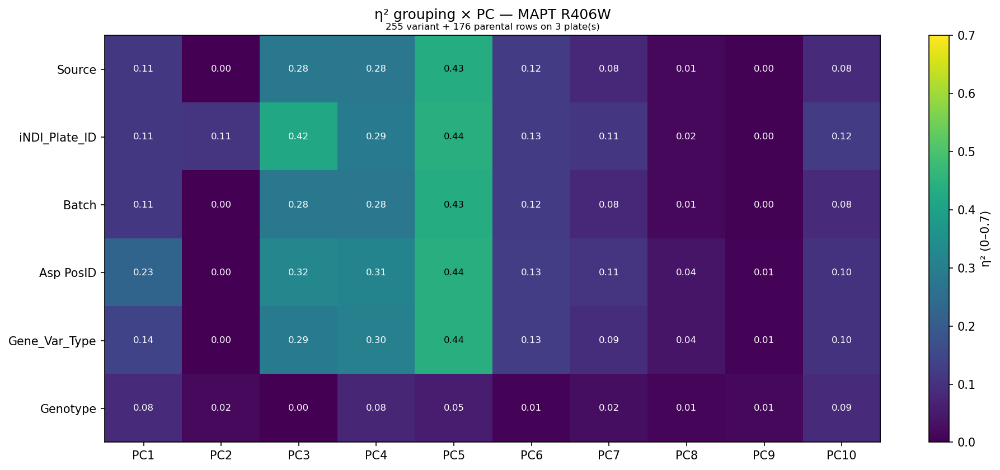

  PFN1 / C71G: 268 variant + 225 parental rows on 3 plate(s)


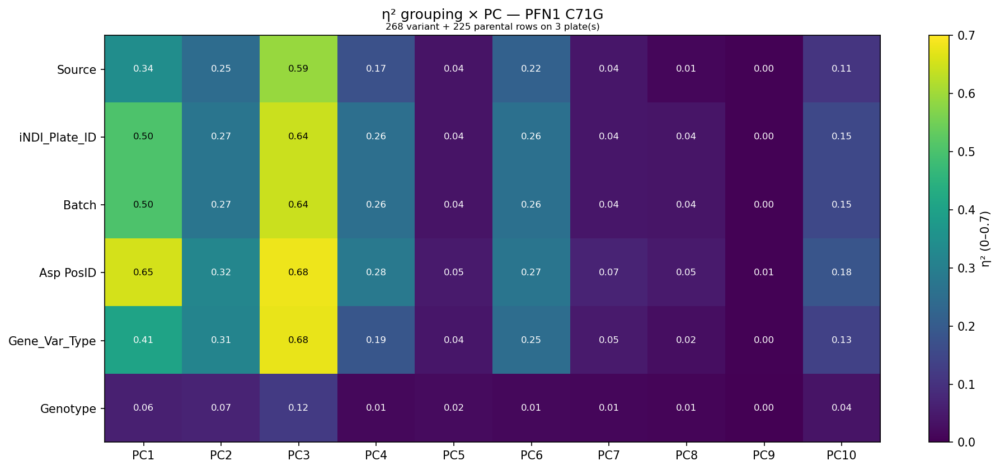

  PSEN1 / E276A: 143 variant + 239 parental rows on 3 plate(s)


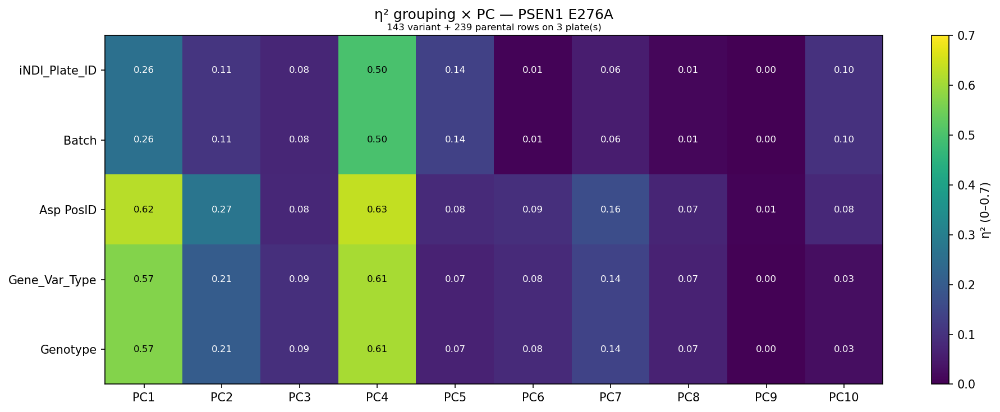

  PSEN2 / N141I: 222 variant + 205 parental rows on 3 plate(s)


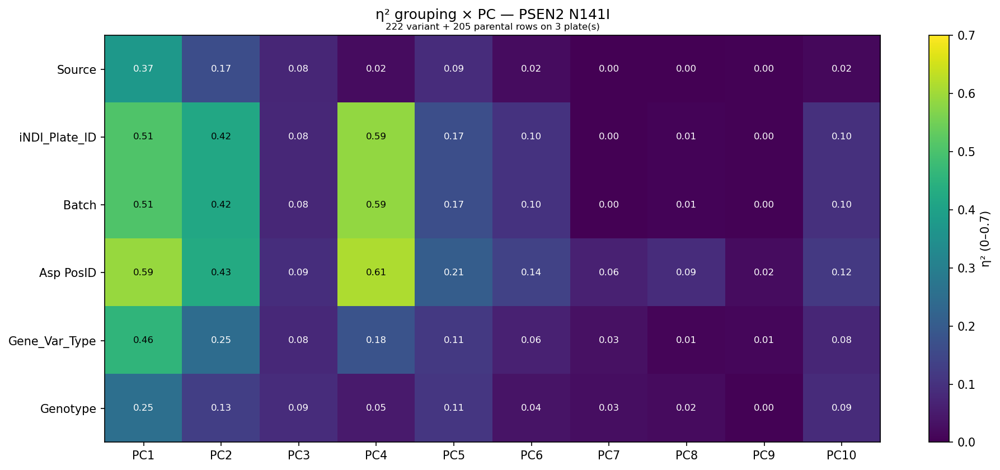

  SNCA / A53T: 172 variant + 136 parental rows on 2 plate(s)


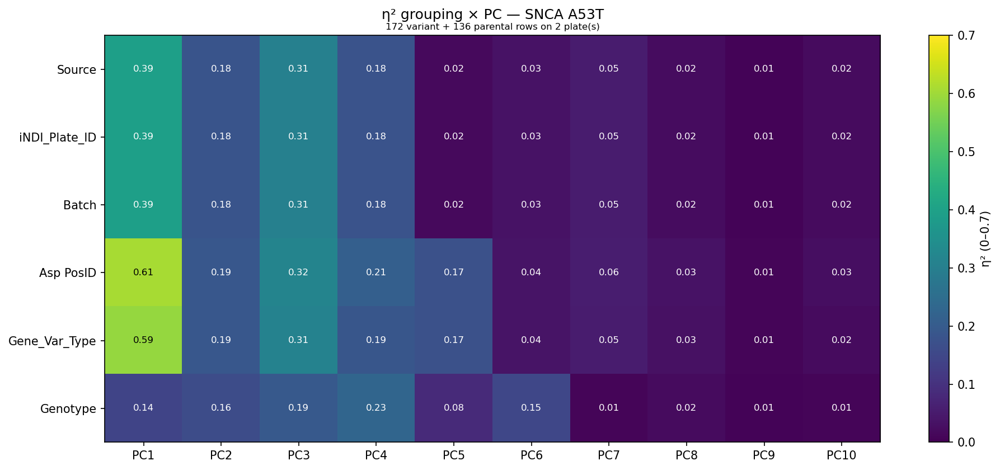

  SNCA / E46K: 146 variant + 122 parental rows on 2 plate(s)


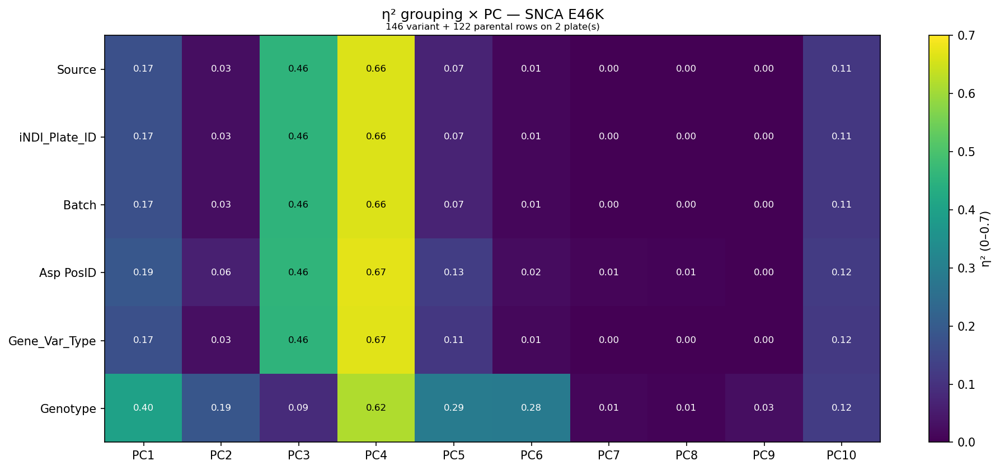

  SNCB / P123H: 222 variant + 138 parental rows on 2 plate(s)


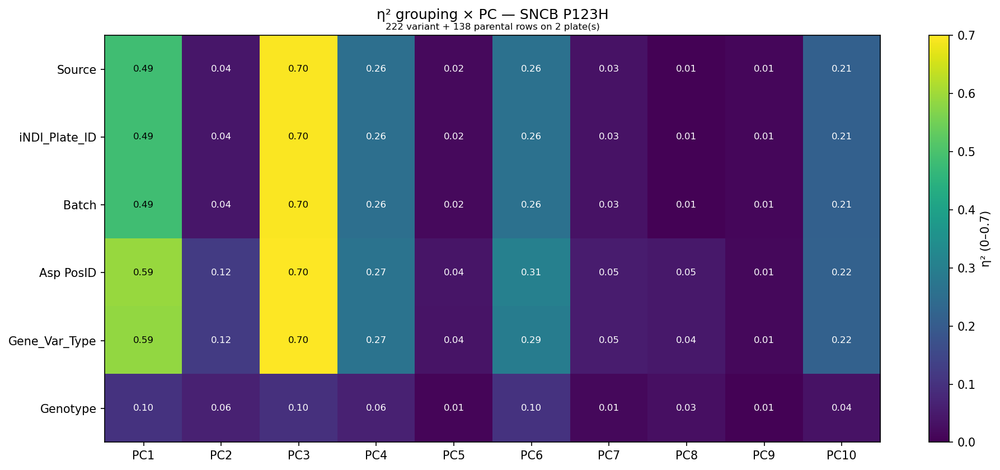

  TARDBP / M337V: 270 variant + 186 parental rows on 3 plate(s)


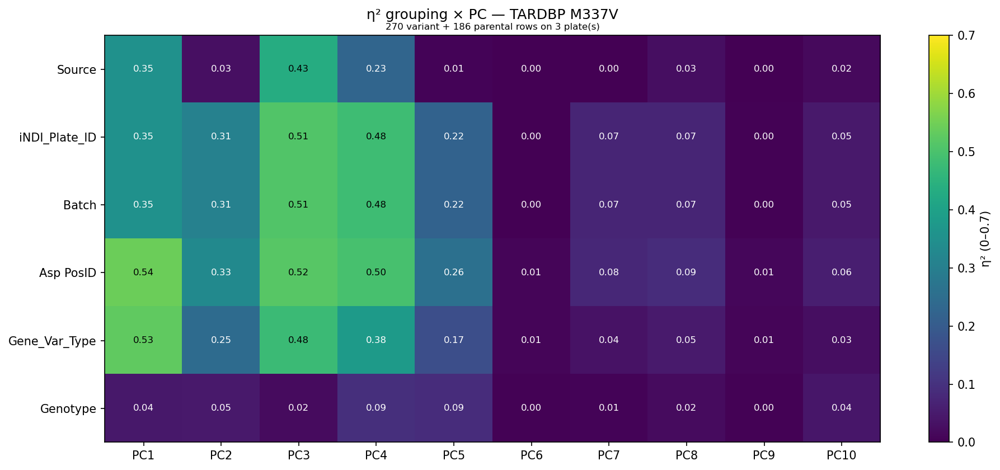

  TARDBP / Q331K: 269 variant + 270 parental rows on 5 plate(s)


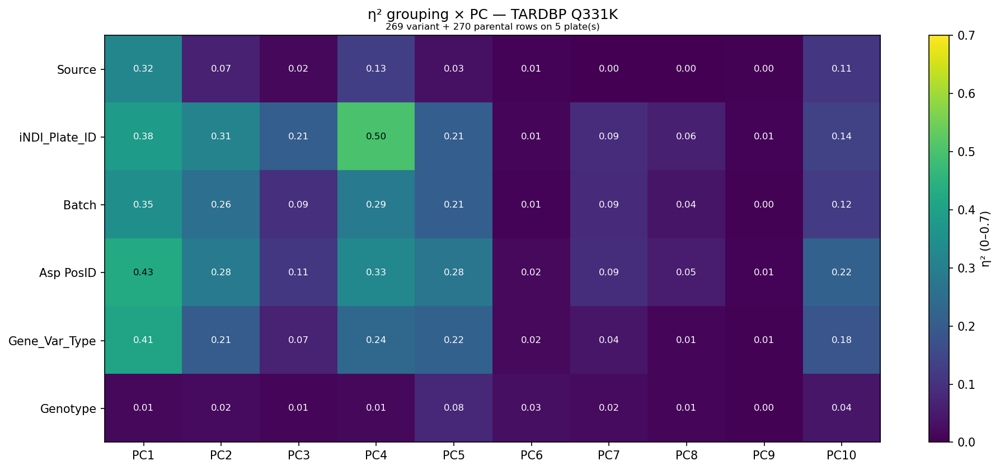

  TBK1 / E696K: 268 variant + 180 parental rows on 3 plate(s)


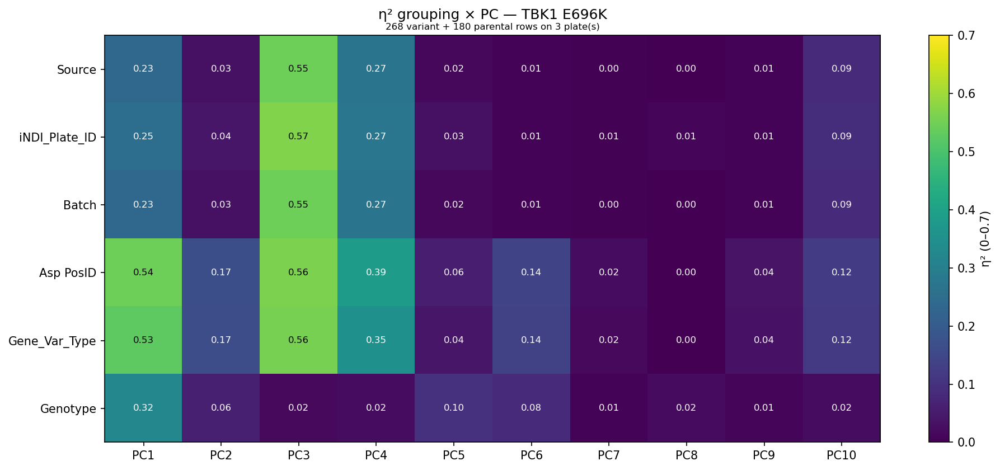

  TIA1 / P351L: 144 variant + 144 parental rows on 2 plate(s)


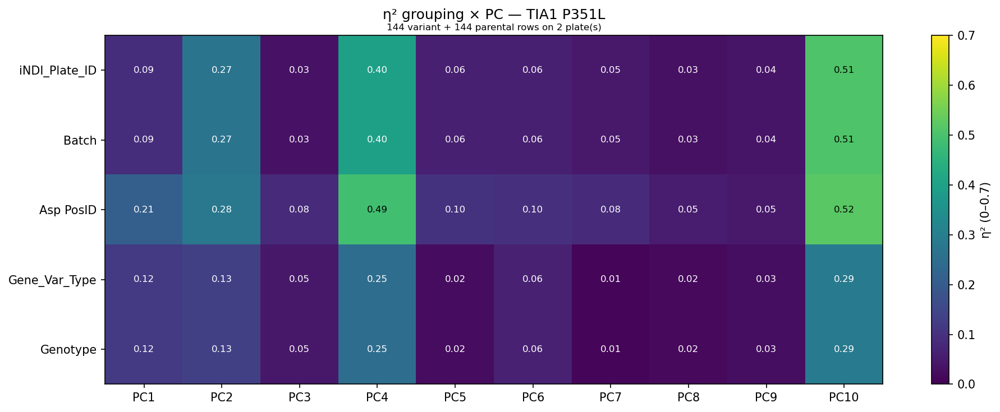

  UBQLN2 / P506T: 83 variant + 42 parental rows on 1 plate(s)


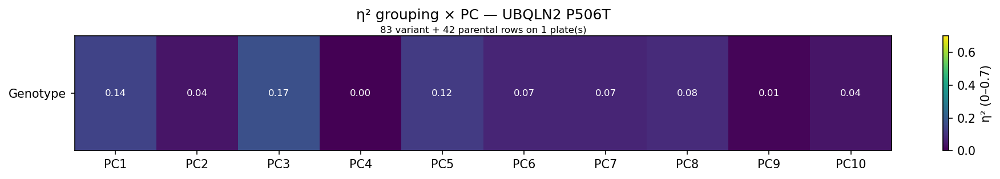

  VCP / R159H: 228 variant + 123 parental rows on 2 plate(s)


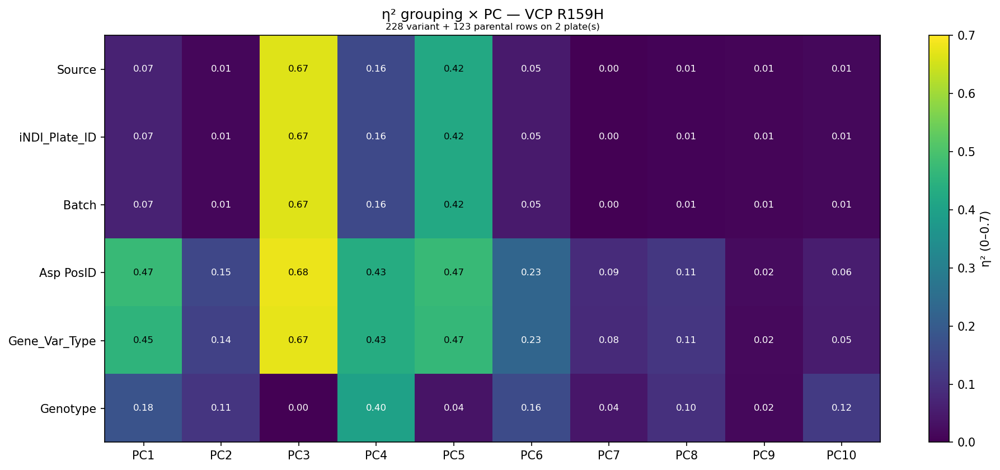

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- your original eta_squared, unchanged ----------------------------------
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


# --- optional well-level aggregation (strongly recommended) ----------------
# A per-gene variant effect on a mean is invisible at single-nucleus level.
# Collapse ROI rows to one row per well before faceting.
def aggregate_to_wells(data, well_keys, carry_cols, pc_cols):
    agg = {pc: "median" for pc in pc_cols}
    for c in carry_cols:
        agg[c] = "first"
    return data.groupby(list(well_keys), as_index=False).agg(agg)


# --- shared WT/control predicate -------------------------------------------
def is_wt(data, gene_col="Gene"):
    """True for the shared KOLF2.1J parental-control rows (they live in Gene)."""
    return data[gene_col].astype(str).str.strip() == "KOLF2.1J"


# --- the original single-matrix eta computation, as a reusable helper -------
def eta_matrix(data, group_cols, pc_cols):
    """grouping x PC matrix of η² for one data subset (e.g. one gene facet)."""
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    return mat


# --- per-gene-variant: ONE SEPARATE FIGURE per facet -----------------------
def plot_gene_heatmap(sub, group_cols, pc_cols, gene, variant, vmax=0.2,
                      annot=True, drop_constant=True, subtitle=None):
    """Draw a single grouping x PC η² heatmap for one facet's subset."""
    rows = list(group_cols)
    if drop_constant:  # hide grouping rows with <2 levels in this facet
        rows = [g for g in rows if g in sub.columns and sub[g].nunique() > 1]
    mat = eta_matrix(sub, rows, pc_cols)

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(mat.index) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis",
                   vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(mat.index))); ax.set_yticklabels(mat.index)
    plt.colorbar(im, ax=ax, label=f"η² (0–{vmax})")
    ax.set_title(f"η² grouping × PC — {gene} {variant}", pad=14)
    if subtitle:
        ax.text(0.5, 1.01, subtitle, transform=ax.transAxes,
                ha="center", va="bottom", fontsize=8)
    if annot:
        for i in range(len(mat.index)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 * vmax else "black",
                            fontsize=8)
    plt.tight_layout(); plt.show()
    return mat


def facet_by_gene_variant(data, group_cols, n_pcs=10,
                          gene_col="Gene", variant_col="Variant", vmax=0.2,
                          annot=True, include_wt=True, drop_constant=True,
                          plate_match=False, plate_col="iNDI_Plate_ID"):
    """One separate η² heatmap figure per (gene, variant) pair. Each facet's
    subset is that single variant's rows plus the shared KOLF2.1J control rows.

    plate_match=True restricts the KOLF2.1J rows folded into each facet to the
    plates that variant actually occupies, removing the plate confound.
    """
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))[:n_pcs]

    wt_mask = is_wt(data, gene_col)
    wt_rows = data[wt_mask]
    edited = data[~wt_mask]

    # unique (gene, variant) pairs among edited rows
    pairs = (edited[[gene_col, variant_col]]
             .dropna()
             .drop_duplicates()
             .sort_values([gene_col, variant_col])
             .itertuples(index=False, name=None))
    pairs = list(pairs)

    print(f"[facet] {len(pairs)} (gene, variant) pairs; "
          f"{len(wt_rows)} total KOLF2.1J rows "
          f"{'(plate-matched per facet)' if plate_match else '(all folded into each facet)'}")

    # gene and variant are constant within a facet, so never use them as rows
    facet_groups = [g for g in group_cols
                    if g not in (gene_col, variant_col)]

    mats = {}
    for gene, variant in pairs:
        var_rows = edited[(edited[gene_col] == gene)
                          & (edited[variant_col] == variant)]
        if var_rows.empty:
            continue

        if include_wt:
            wt_use = wt_rows
            if plate_match and plate_col in data.columns:
                var_plates = set(var_rows[plate_col].dropna().unique())
                wt_use = wt_rows[wt_rows[plate_col].isin(var_plates)]
            plate_note = (f" on {len(set(var_rows[plate_col].dropna().unique()))} plate(s)"
                          if plate_match else "")
            subtitle = (f"{len(var_rows)} variant + {len(wt_use)} parental rows"
                        f"{plate_note}")
            sub = pd.concat([var_rows, wt_use], ignore_index=True)
            print(f"  {gene} / {variant}: {subtitle}")
        else:
            subtitle = f"{len(var_rows)} variant rows"
            sub = var_rows
            print(f"  {gene} / {variant}: {subtitle}")

        mats[(gene, variant)] = plot_gene_heatmap(
            sub, facet_groups, pc_cols, gene, variant,
            vmax=vmax, annot=annot, drop_constant=drop_constant,
            subtitle=subtitle)
    return mats


# --- usage -----------------------------------------------------------------
GROUP_COLS = ["Source", "iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Variant", "Genotype"]

mats = facet_by_gene_variant(well_level, GROUP_COLS, n_pcs=10, vmax=0.43, plate_match=False)
mats = facet_by_gene_variant(well_level, GROUP_COLS, n_pcs=10, vmax=0.7, plate_match=True)

### Genotype faceted PCAs


MANUAL (2192 wells)


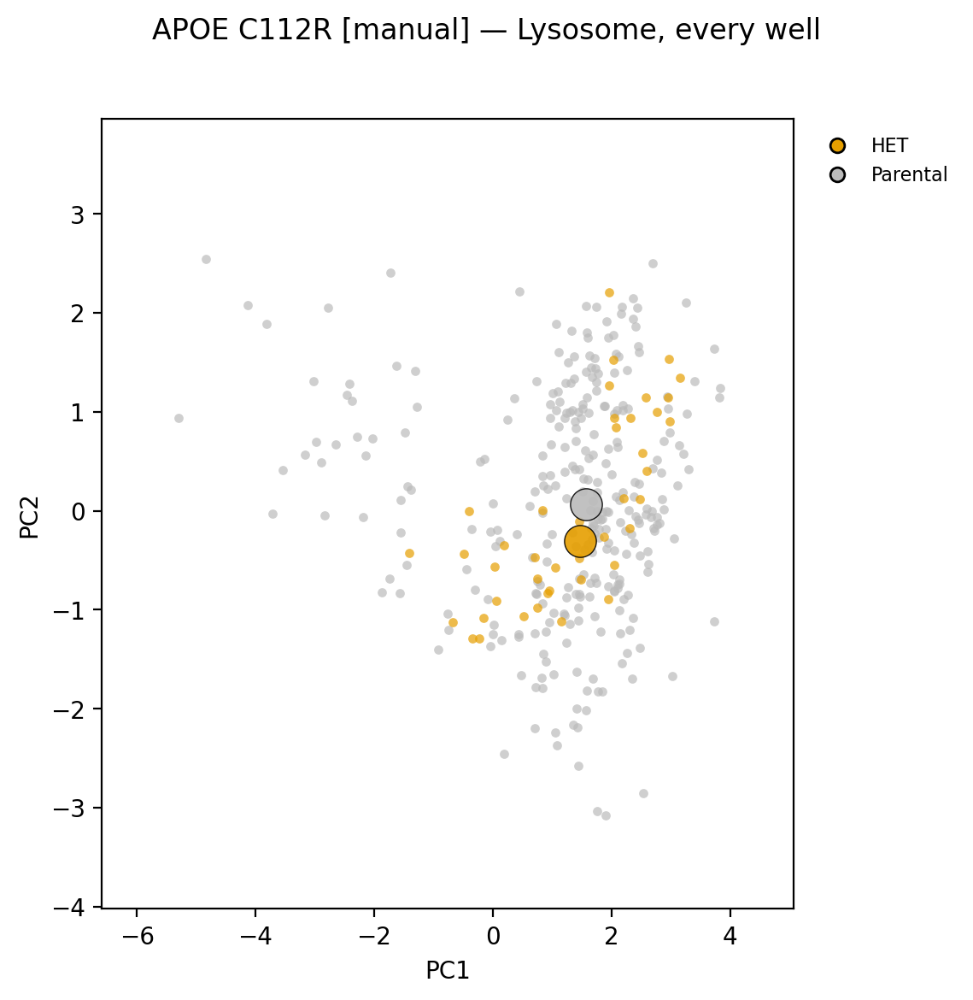

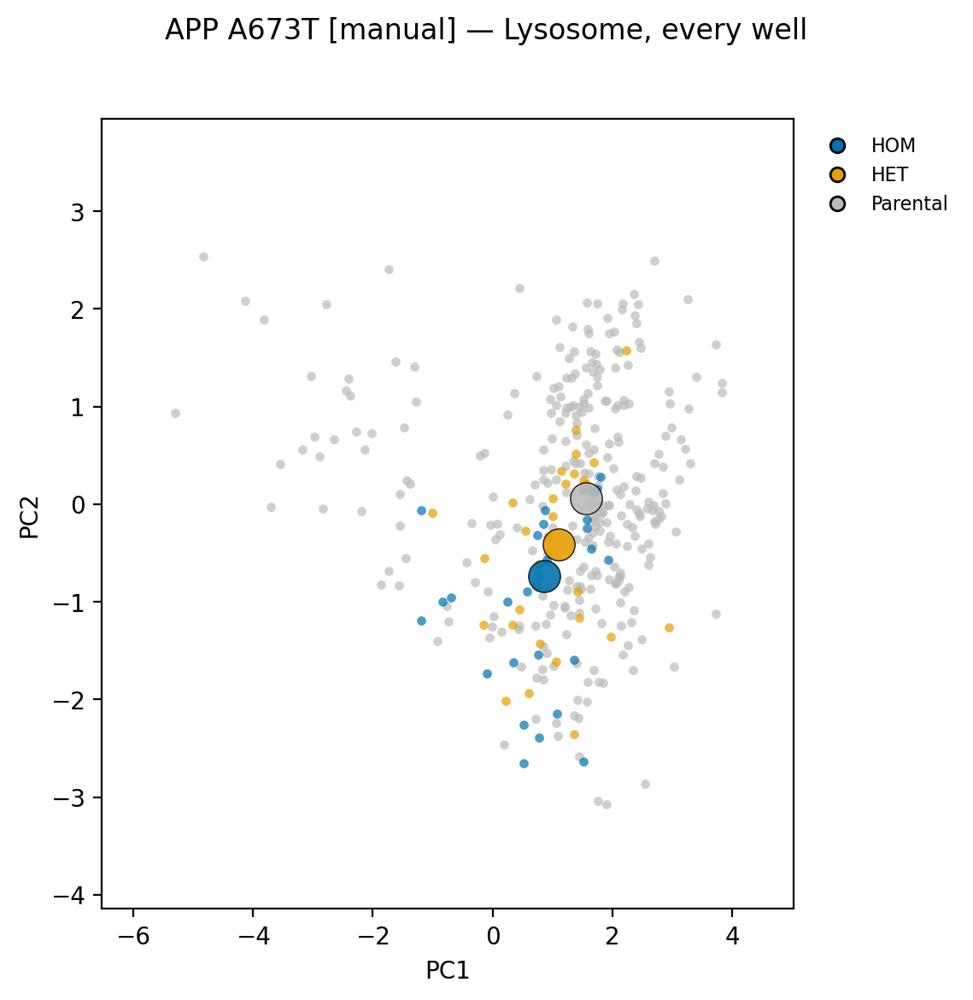

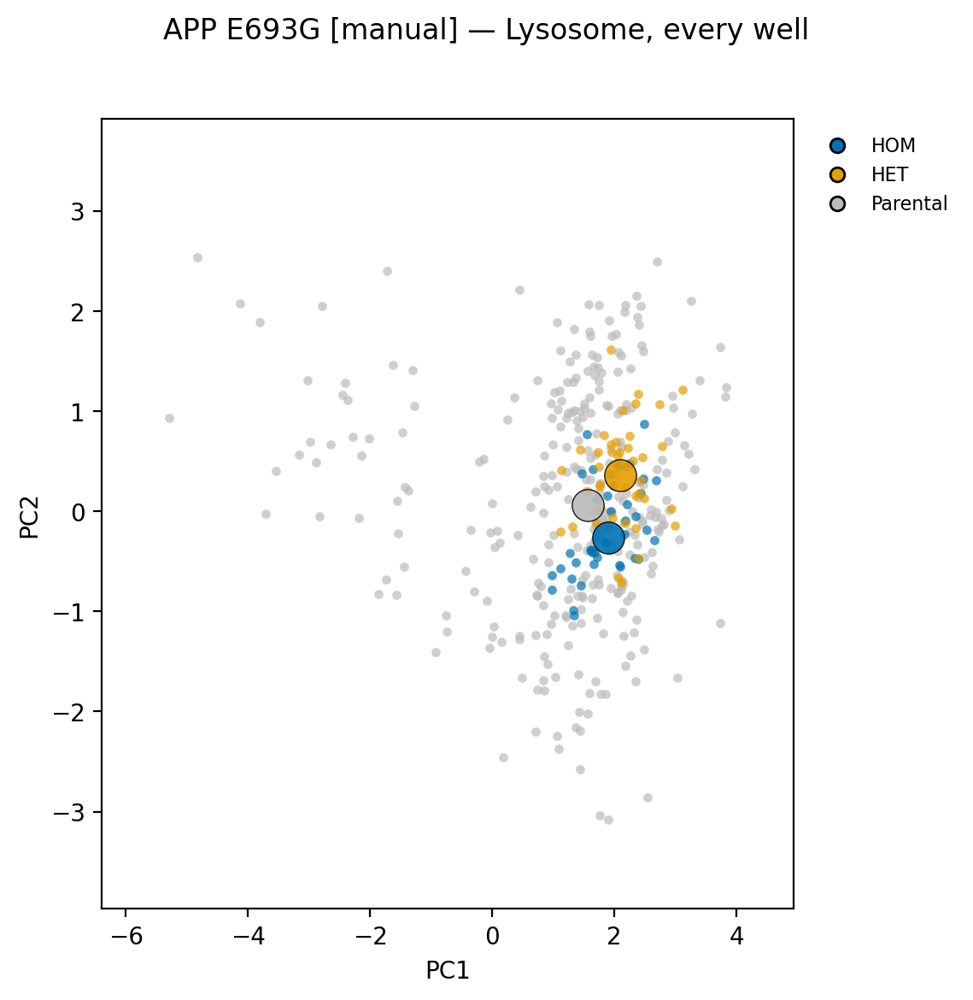

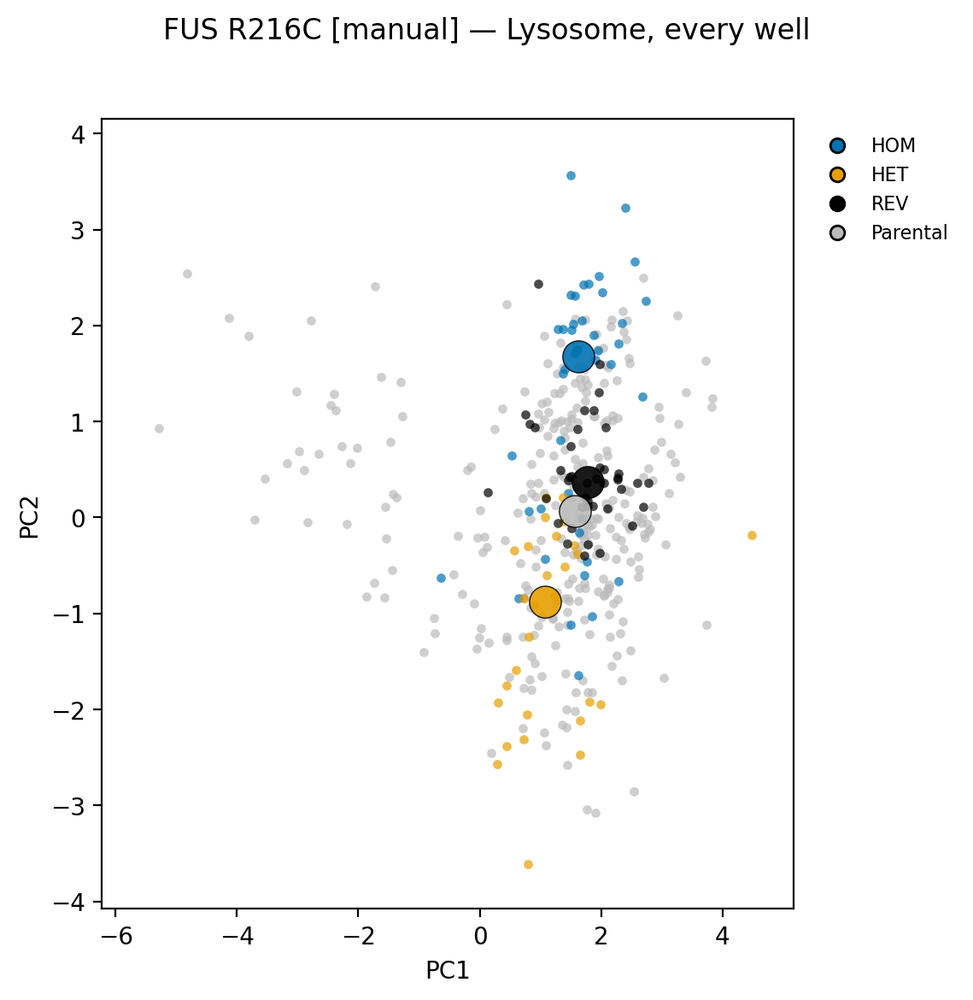

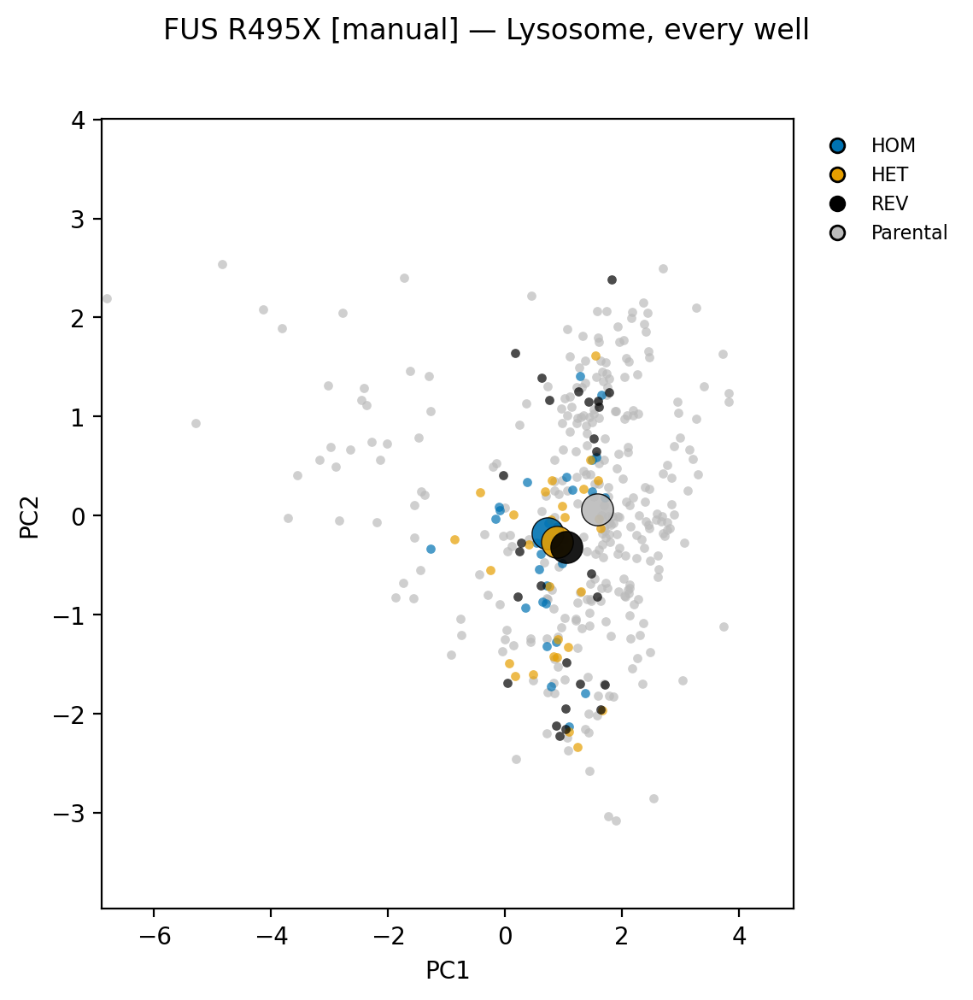

...

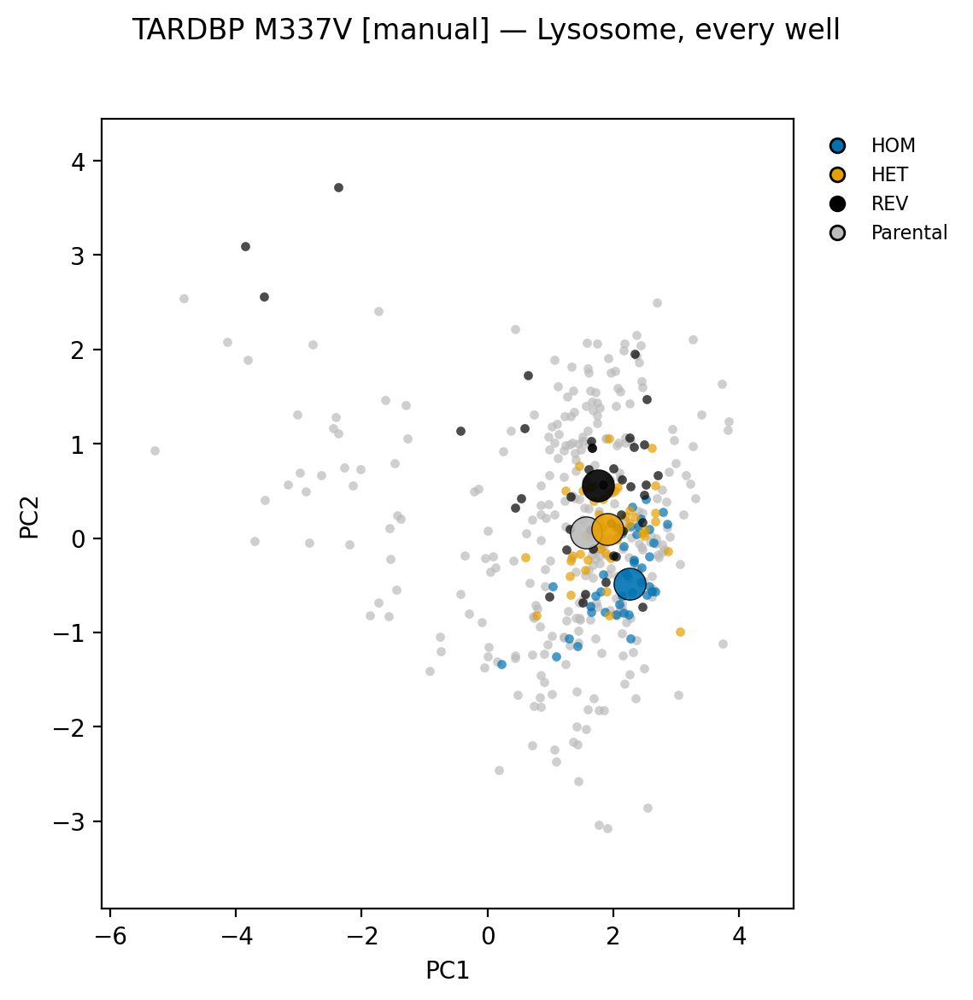

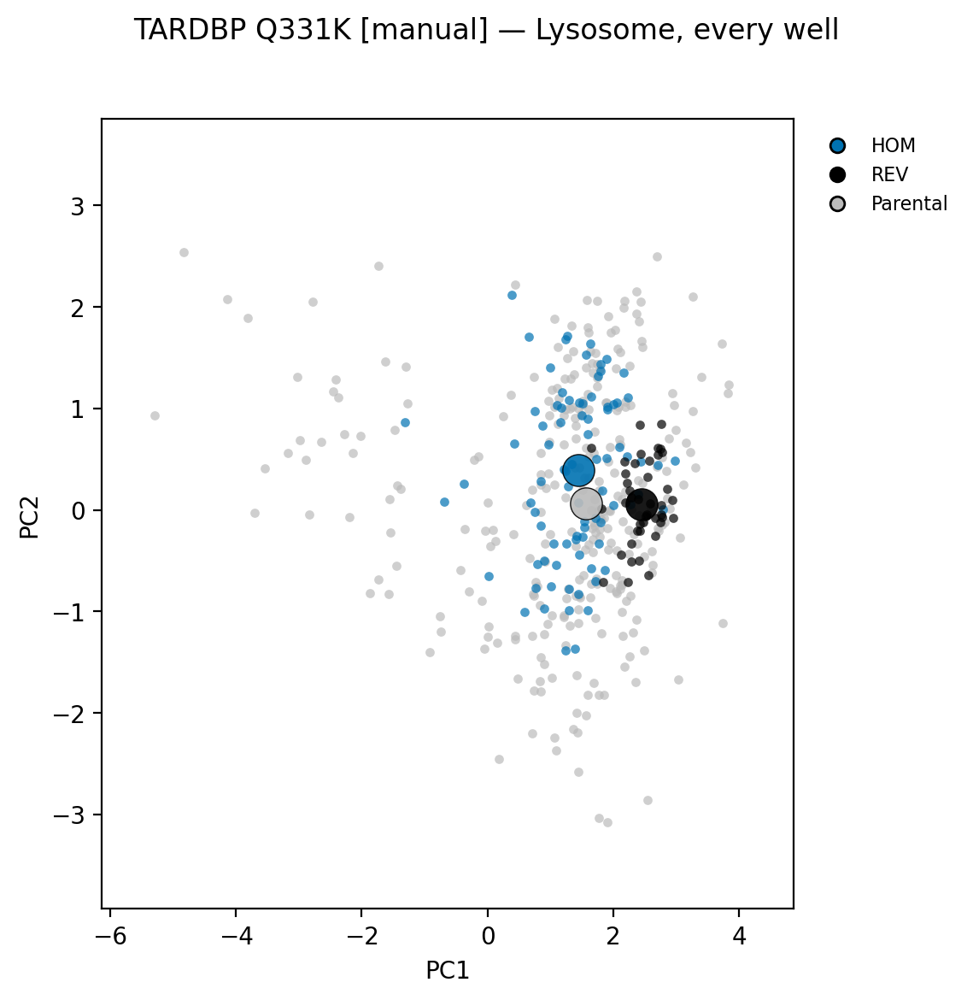

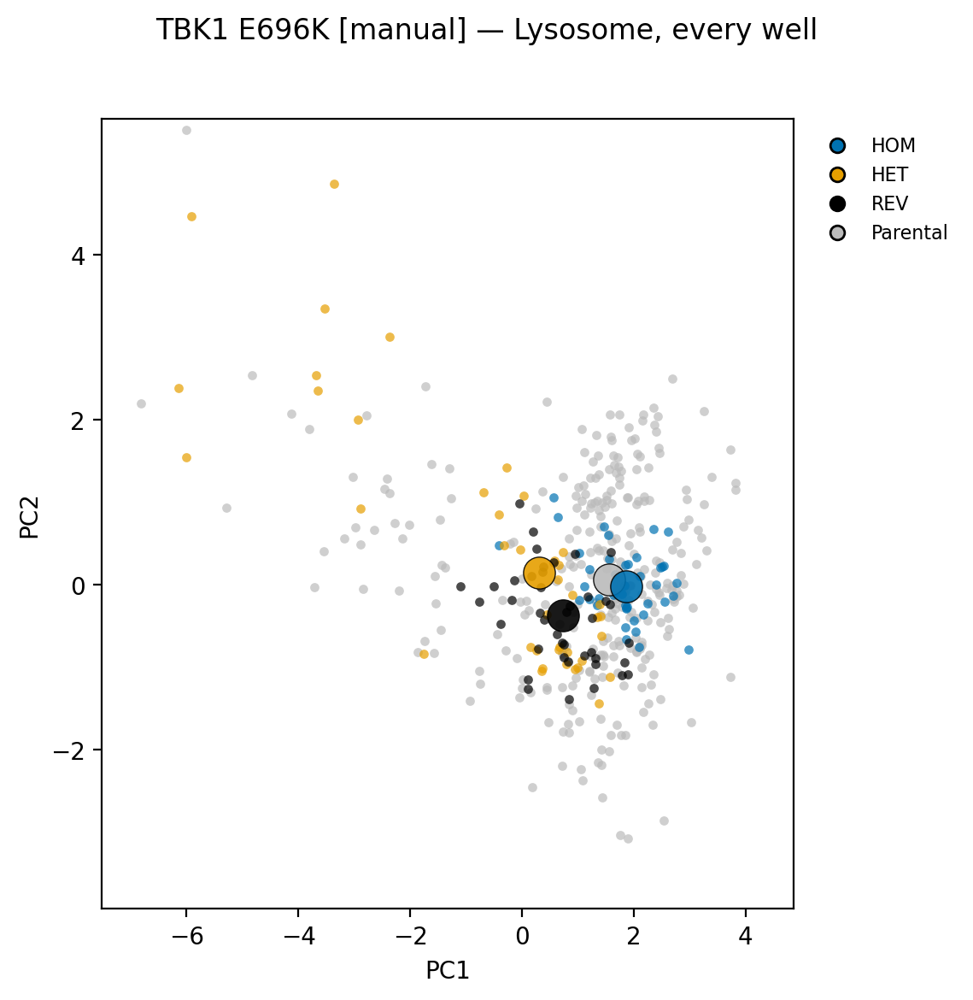

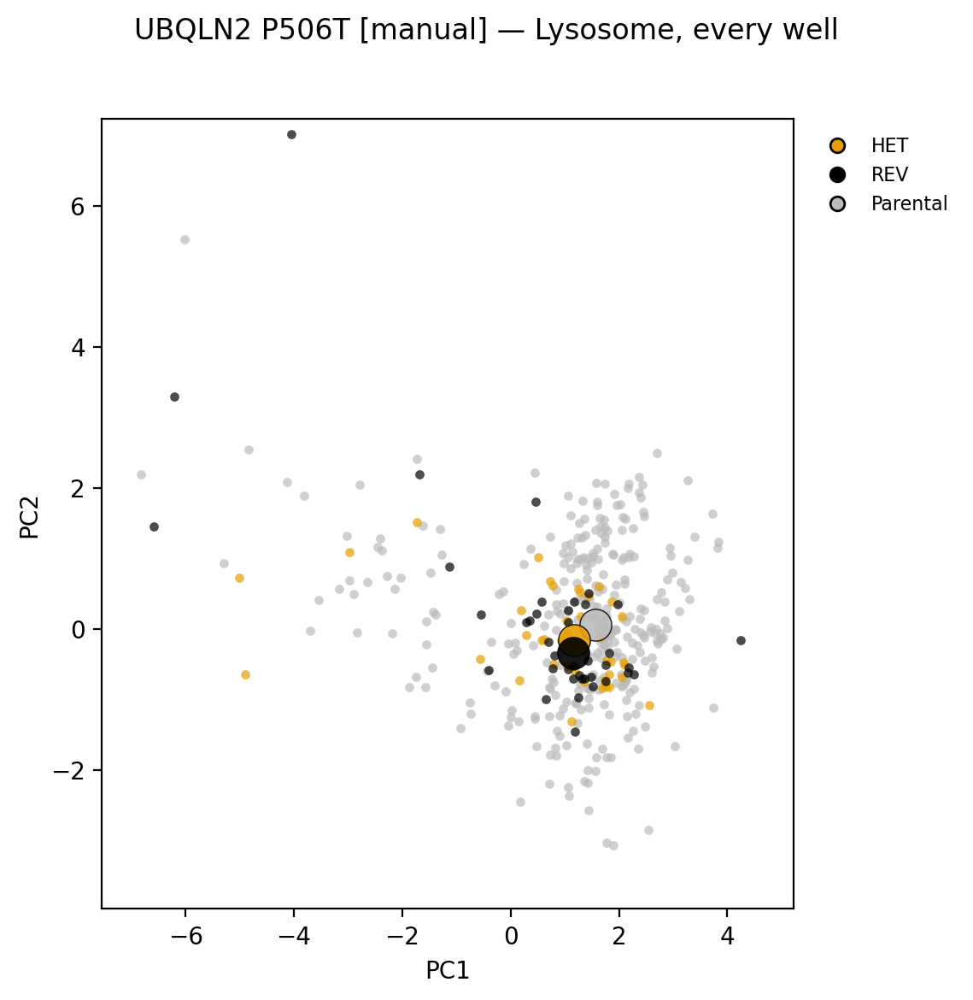

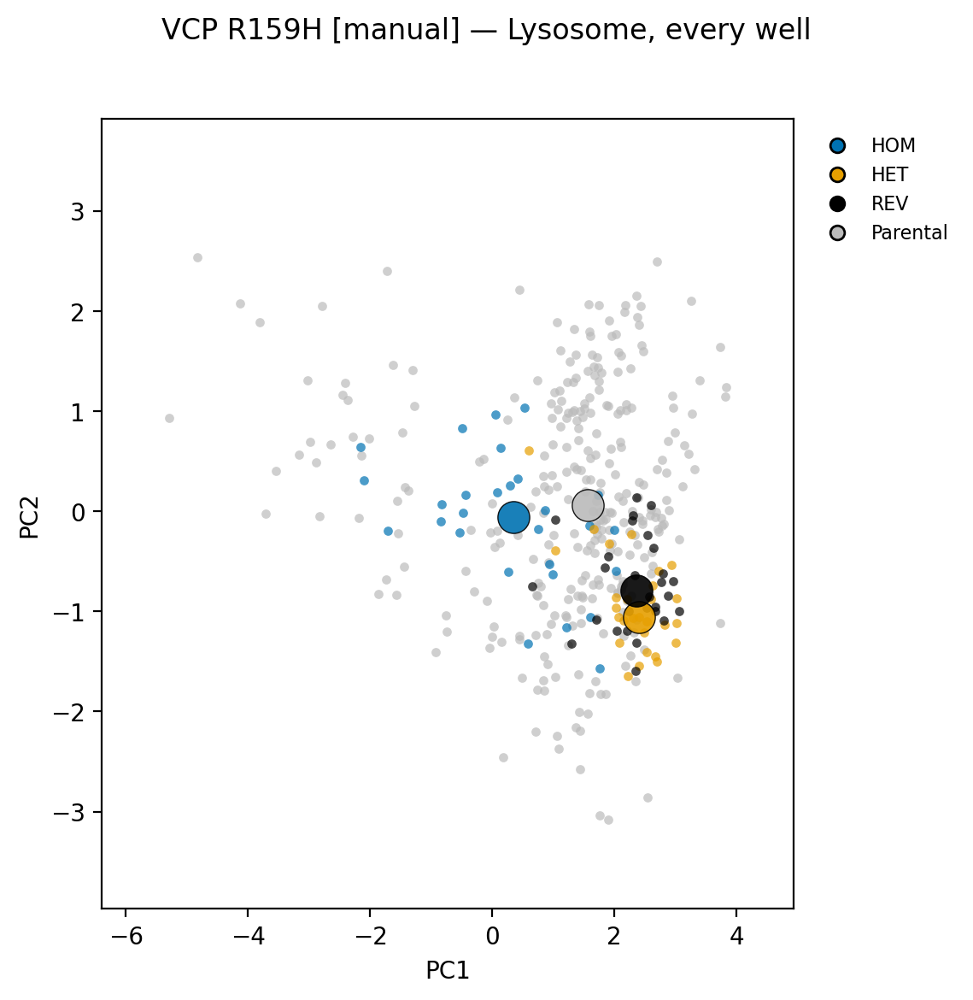


AUTOMATED (3739 wells)


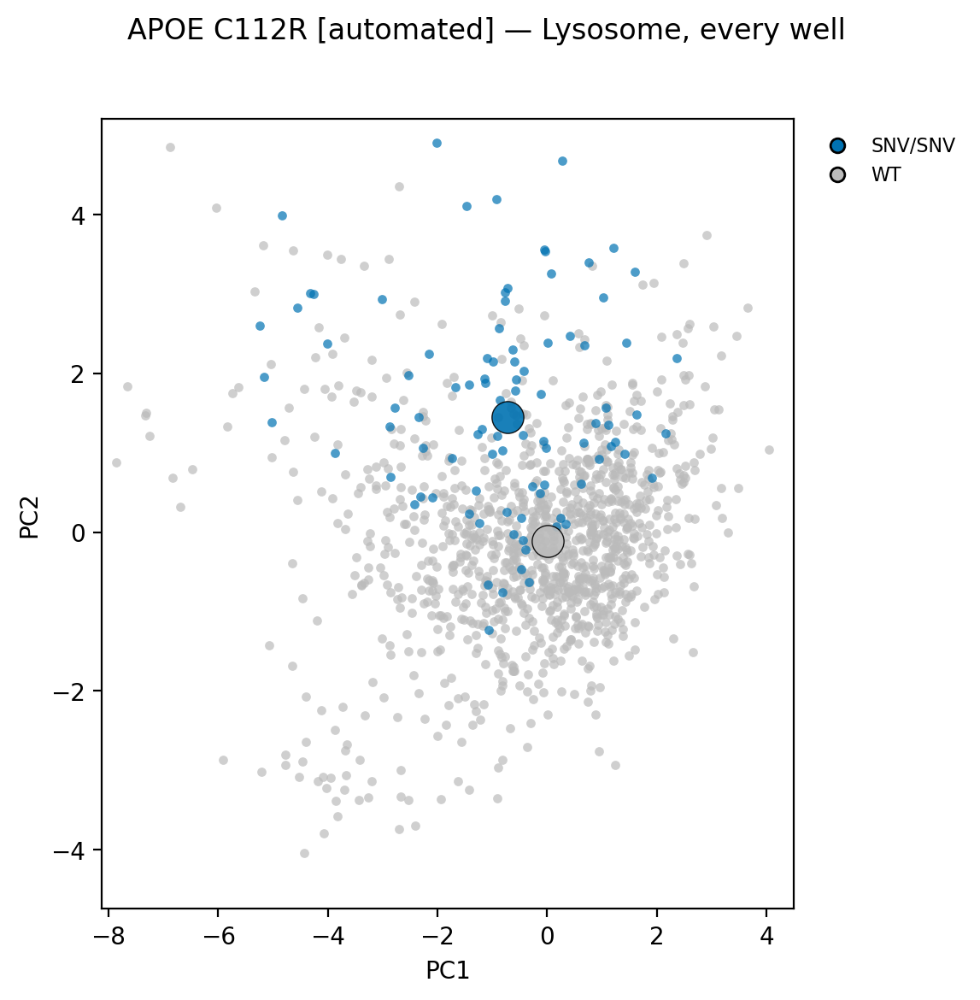

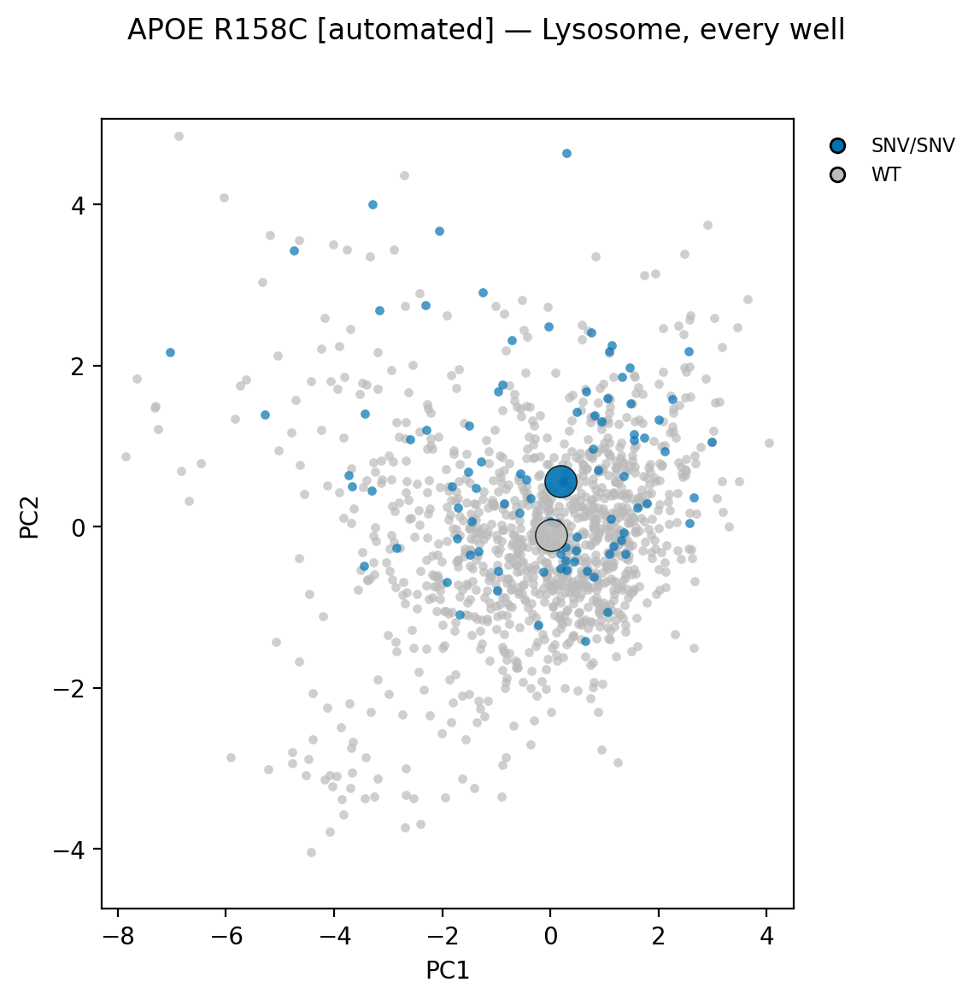

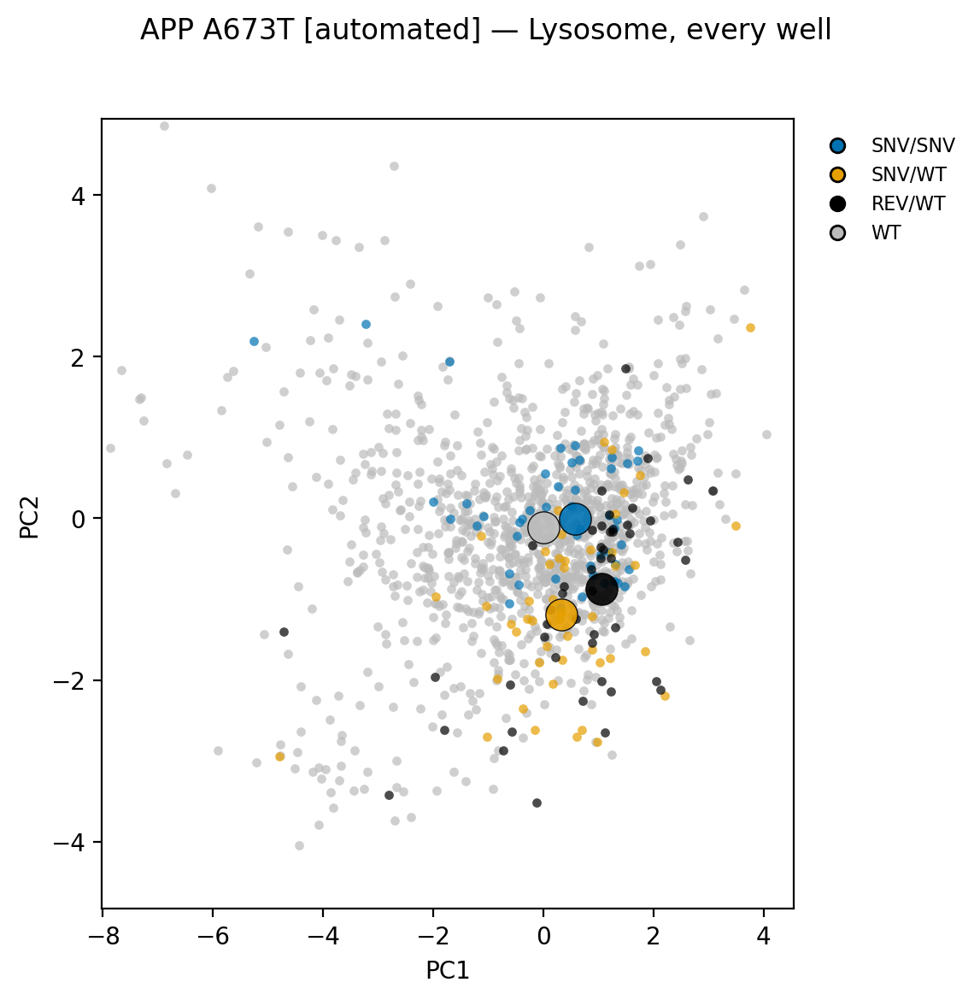

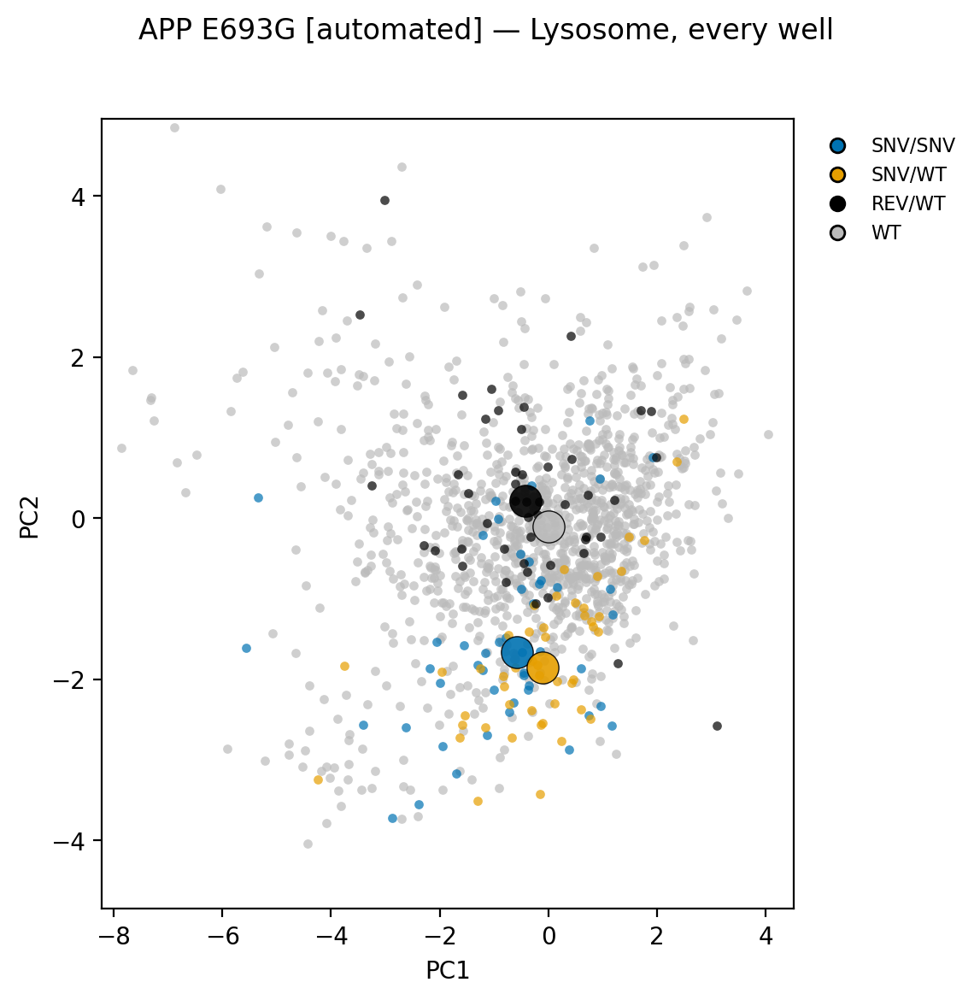

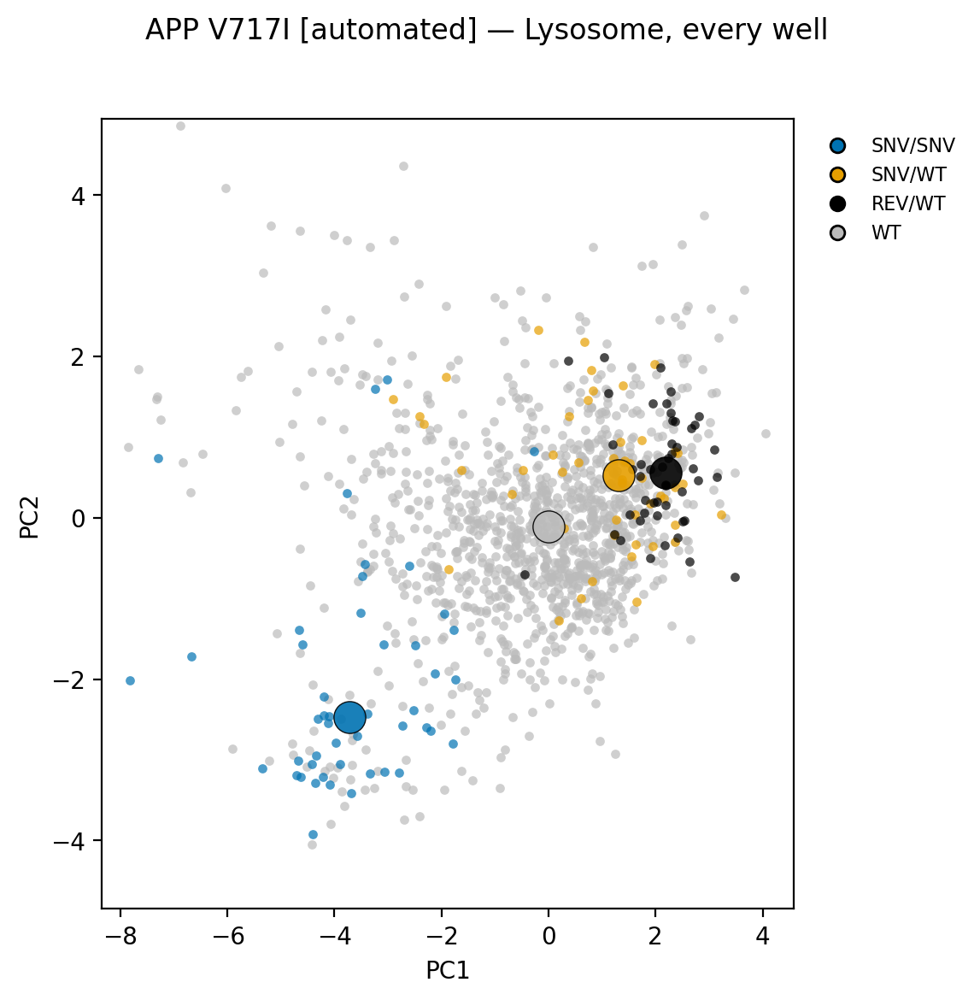

...

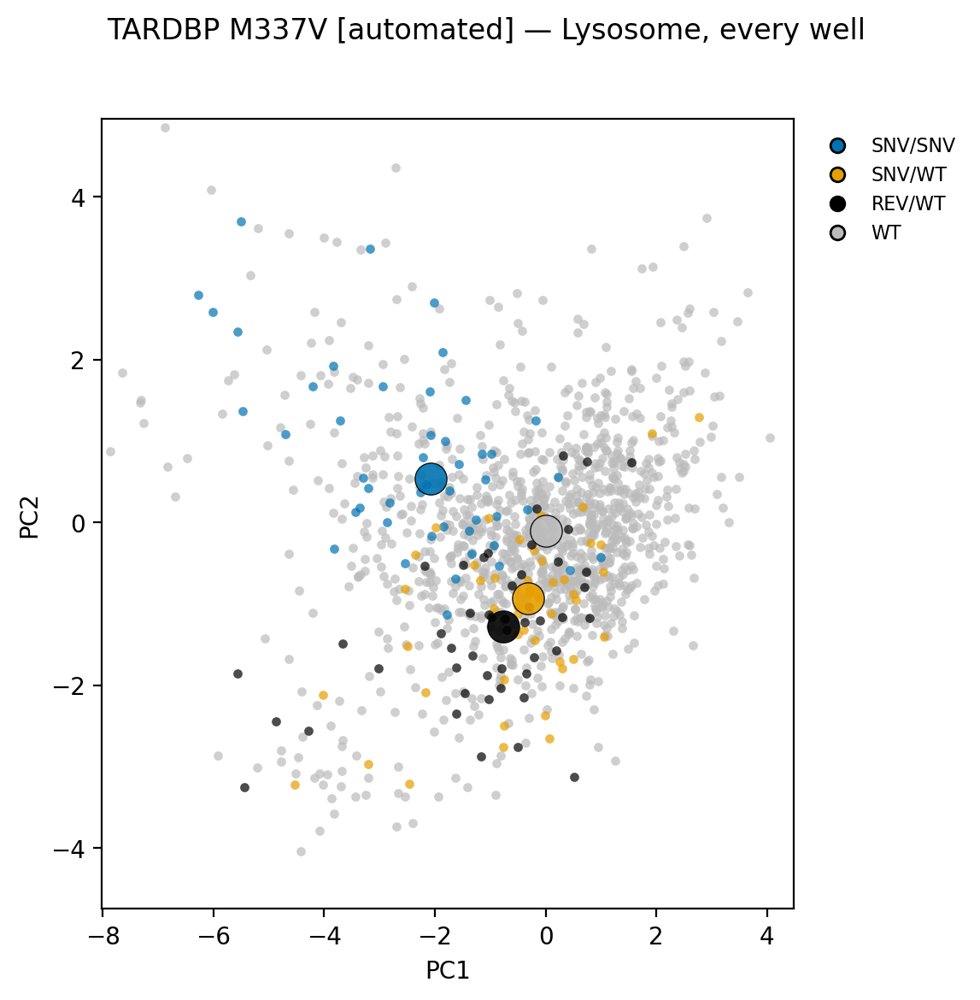

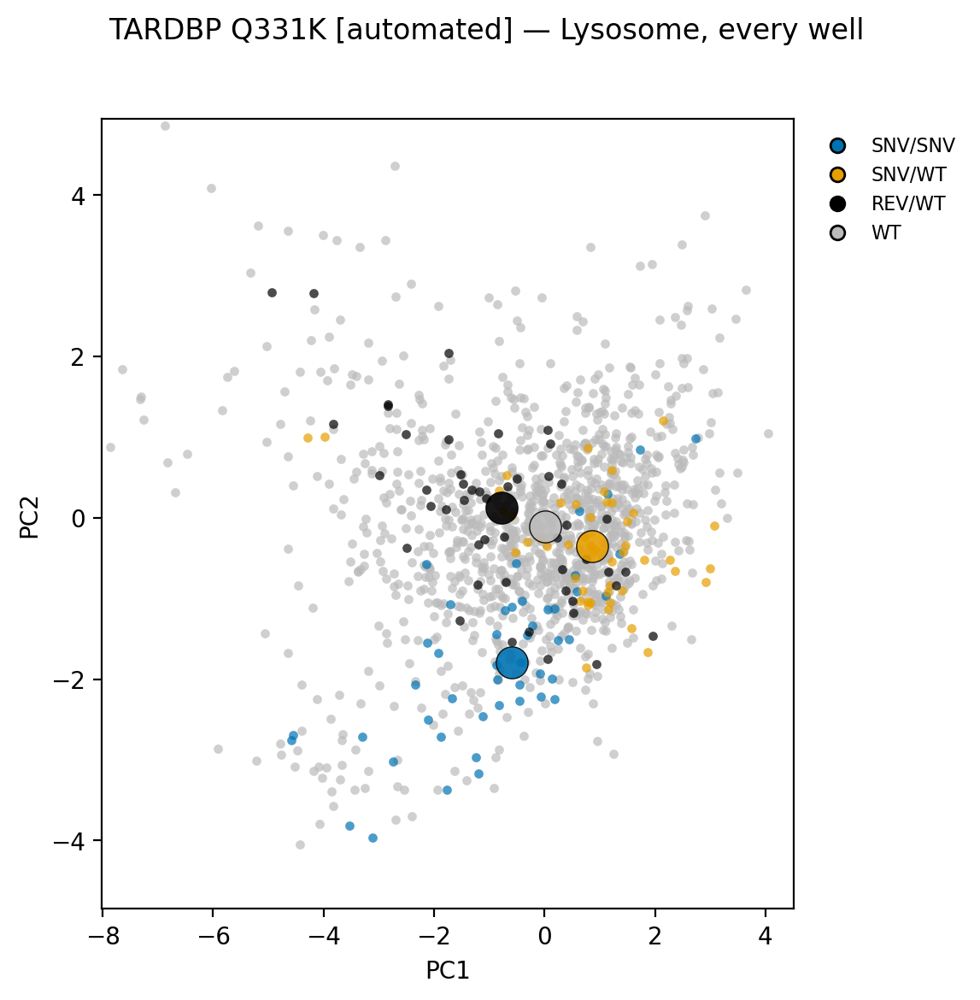

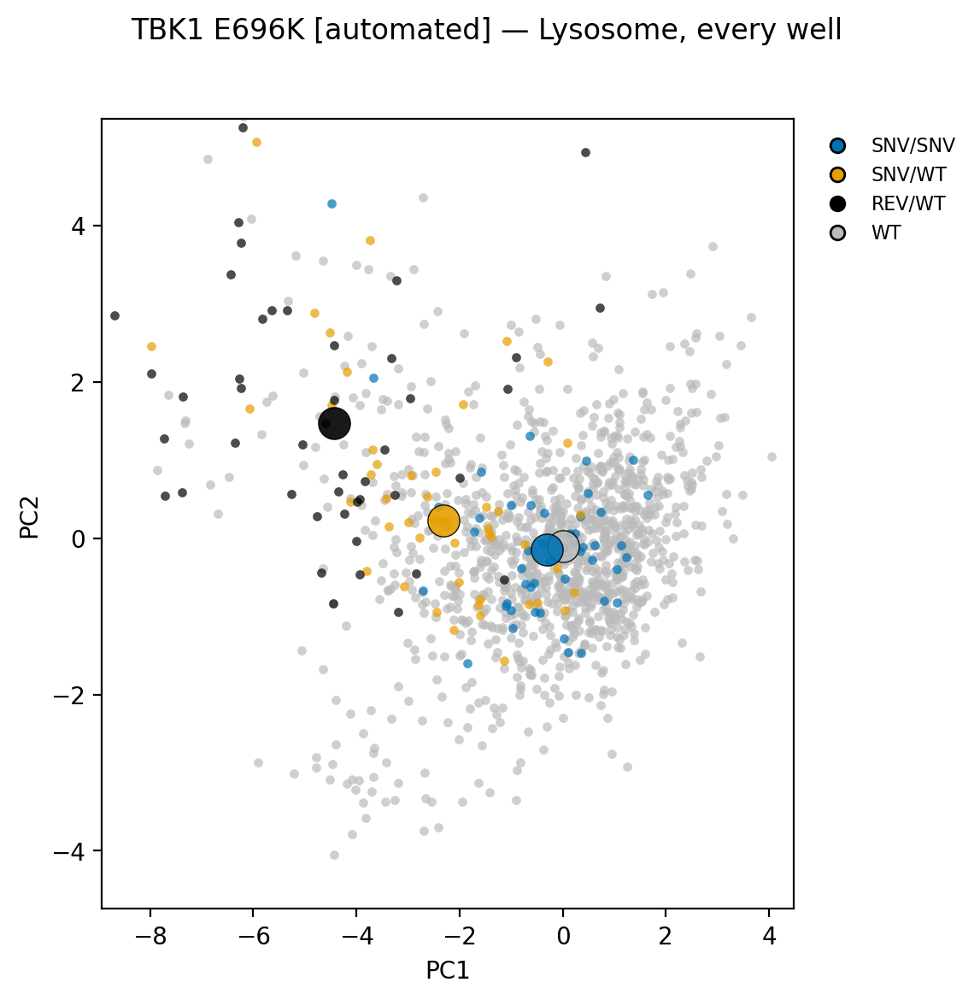

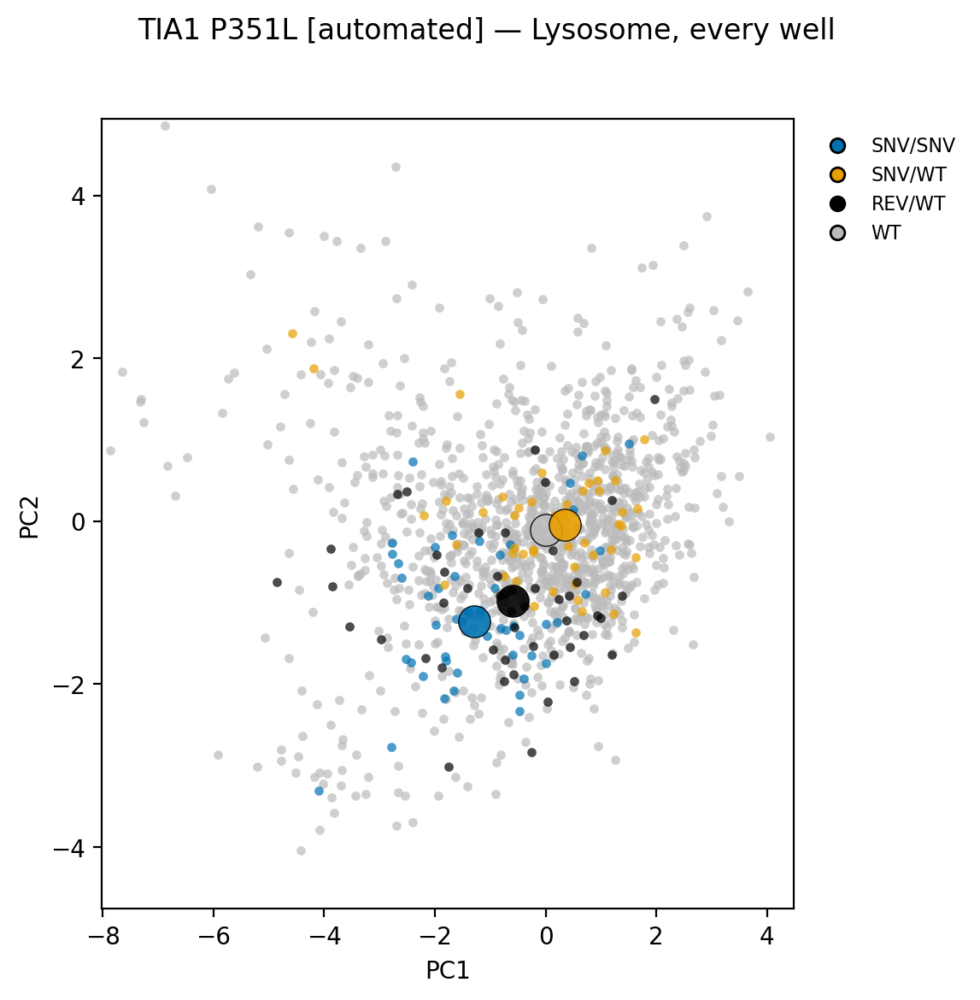

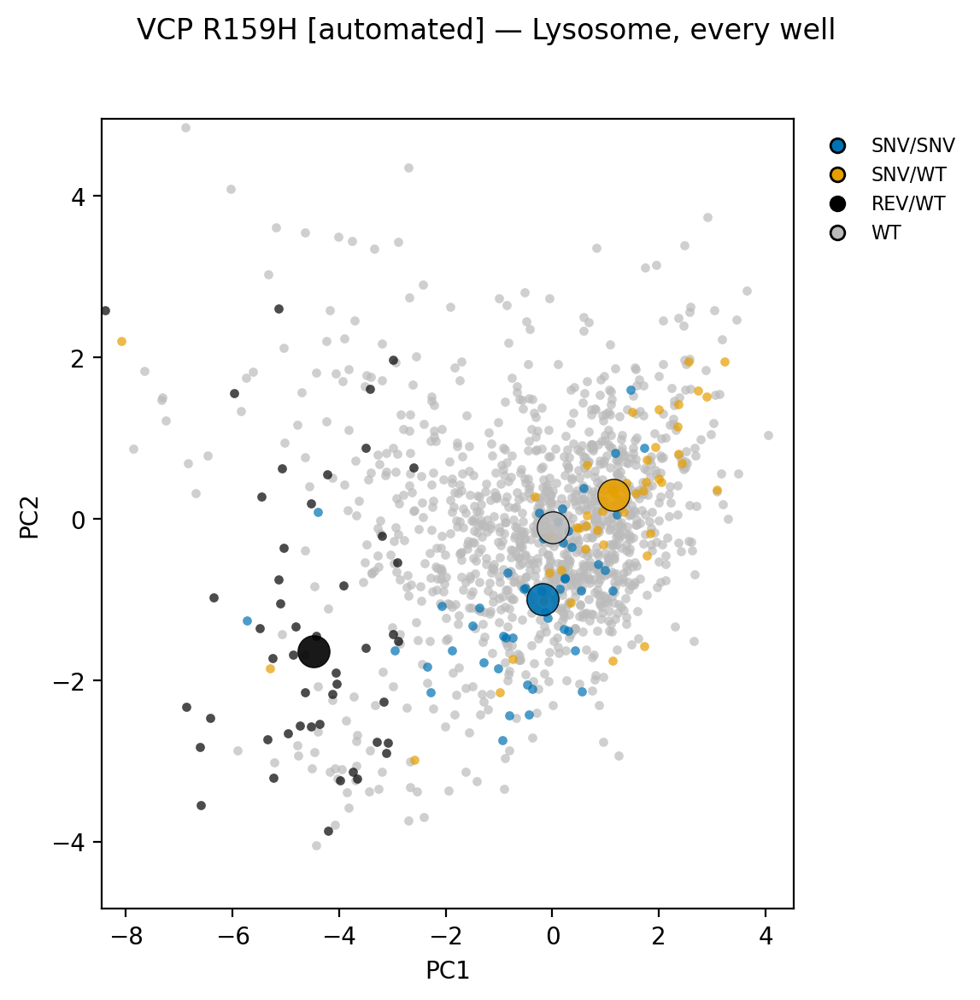

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ==========================================================================
# Prep split
# ==========================================================================
PREP_COL = "Source"          # column tagging each well's prep
AUTOMATED_VAL = "automated"
MANUAL_VAL = "manual"

# ==========================================================================
# Group-specific schemes
# ==========================================================================
# --- Manual: parental by Genotype_Name == "Parental"; genotype is the trailing
#     token of Genotype_Name (HOM / HET / REV). -----------------------------
MANUAL_PARENTAL_NAME = "Parental"
MANUAL_COLORS = {
    "Parental": "#BBBBBB", "HET": "#E69F00", "HOM": "#0072B2",
    "REV": "#000000", "OTHER": "#F0E442",
}
MANUAL_ORDER = ["HOM", "HET", "REV", "Parental"]
MANUAL_PARENTAL_KEY = "Parental"

def _manual_is_parental(df):
    return (df["Genotype_Name"].astype(str).str.strip().str.upper()
            == MANUAL_PARENTAL_NAME.upper())

def _manual_color_key(df):
    name = df["Genotype_Name"].astype(str).str.strip()
    zyg = name.str.split().str[-1].str.upper()        # HOM / HET / REV
    return np.where(_manual_is_parental(df), MANUAL_PARENTAL_KEY, zyg)

def _manual_has_mutant(nonpar_keys):
    return nonpar_keys.isin(["HOM", "HET"]).any()

# --- Automated: parental by Gene == "KOLF2.1J"; genotype from the Genotype
#     column (SNV/SNV, SNV/WT, SNV/Y, ...). ---------------------------------
AUTO_WT_GENE = "KOLF2.1J"
AUTO_COLORS = {
    "WT": "#BBBBBB", "SNV/WT": "#E69F00", "SNV/SNV": "#0072B2",
    "REV/WT": "#000000", "SNV/Y": "#009E73", "REV/Y": "#CC79A7",
    "OTHER": "#F0E442",
}
AUTO_ORDER = ["SNV/SNV", "SNV/WT", "SNV/Y", "REV/WT", "REV/Y", "WT"]
AUTO_PARENTAL_KEY = "WT"

def _auto_is_parental(df):
    return (df["Gene"].astype(str).str.strip().str.upper()
            == AUTO_WT_GENE.upper())

def _auto_color_key(df):
    return np.where(_auto_is_parental(df), AUTO_PARENTAL_KEY,
                    df["Genotype"].astype(str).str.strip())

def _auto_has_mutant(nonwt_keys):
    return nonwt_keys.str.startswith("SNV").any()

SCHEMES = {
    "manual": {
        "label": "manual", "is_parental": _manual_is_parental,
        "color_key": _manual_color_key, "colors": MANUAL_COLORS,
        "order": MANUAL_ORDER, "parental_key": MANUAL_PARENTAL_KEY,
        "has_mutant": _manual_has_mutant,
    },
    "automated": {
        "label": "automated", "is_parental": _auto_is_parental,
        "color_key": _auto_color_key, "colors": AUTO_COLORS,
        "order": AUTO_ORDER, "parental_key": AUTO_PARENTAL_KEY,
        "has_mutant": _auto_has_mutant,
    },
}


# ==========================================================================
# Figure: single-panel PCA for one allele (nucleus-level, no faceting)
# ==========================================================================
def variant_pca(
    df, gene, variant, scheme, pcx="PC1", pcy="PC2", title=None, pad=1.5,
    parental=None, s=15, alpha=0.7, s_centroid=180, figsize=(6, 6),
):
    """Single PCA panel for one (gene, variant), using `scheme` for color keys,
    palette, and ordering. `parental` is the pooled parental reference."""
    colors = scheme["colors"]
    order = scheme["order"]
    par_key = scheme["parental_key"]

    src = df[(df["Gene"] == gene) & (df["Variant"] == variant)].copy()
    if parental is not None and not parental.empty:
        src = pd.concat([src, parental], ignore_index=True)
    if src.empty:
        print(f"[skip] ({scheme['label']}) no rows for {gene} {variant}")
        return None

    src["_ckey"] = scheme["color_key"](src)

    nonpar = src.loc[src["_ckey"] != par_key, "_ckey"]
    has_mutant = scheme["has_mutant"](nonpar)
    mutant_note = "" if has_mutant else "  [no mutant genotype — revertant only]"

    px, py = src[pcx].dropna(), src[pcy].dropna()
    if px.empty or py.empty:
        print(f"[skip] ({scheme['label']}) no finite PC values for {gene} {variant}")
        return None
    x_lo, x_hi = px.quantile(.01) - pad, px.quantile(.99) + pad
    y_lo, y_hi = py.quantile(.01) - pad, py.quantile(.99) + pad

    all_keys = list(pd.unique(src["_ckey"]))
    unknown = [k for k in all_keys if k not in colors]
    if unknown:
        print(f"[warning] ({scheme['label']}) {gene} {variant}: genotype(s) "
              f"not in palette, drawn as OTHER: {unknown}")
    keys_present = ([k for k in order if k in all_keys]
                    + [k for k in all_keys if k not in order])
    draw_order = ([k for k in keys_present if k == par_key]
                  + [k for k in keys_present if k != par_key])

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.80)

    for k in draw_order:                        # clouds: parental bottom
        gg = src[src["_ckey"] == k]
        ax.scatter(gg[pcx], gg[pcy], s=s, alpha=alpha,
                   color=colors.get(k, colors["OTHER"]),
                   linewidths=0, rasterized=True)
    for k in draw_order:                         # centroids
        gg = src[src["_ckey"] == k]
        if gg.empty:
            continue
        ax.scatter(gg[pcx].median(), gg[pcy].median(), s=s_centroid,
                   color=colors.get(k, colors["OTHER"]),
                   edgecolor="k", linewidths=0.5, alpha=0.9, zorder=5)

    ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)

    handles = [
        Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=colors.get(k, colors["OTHER"]),
               markeredgecolor="k", label=k)
        for k in keys_present
    ]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=8)

    fig.suptitle((title or f"{gene} {variant} [{scheme['label']}] — Lysosome, "
                  f"every well") + mutant_note, y=0.98)
    plt.show()
    return fig


# ==========================================================================
# Driver: run each prep group independently with its own scheme.
# ==========================================================================
def run_group(well_df, scheme):
    print(f"\n{'=' * 60}\n{scheme['label'].upper()} ({len(well_df)} wells)\n{'=' * 60}")

    is_par = scheme["is_parental"](well_df)
    parental_all = well_df[is_par].copy()

    variants = (well_df.loc[~is_par, ["Gene", "Variant"]]
                .dropna().drop_duplicates().sort_values(["Gene", "Variant"]))

    for gene, variant in variants.itertuples(index=False):
        variant_pca(well_df, gene, variant, scheme, parental=parental_all)


well_df = well_level

# Manual-only fixup from the previous manual driver.
well_df.loc[
    well_df["Genotype_Name"].astype(str).str.strip() == "TBK1 E696K HOM",
    "Variant",
] = "E696K"

prep = well_df[PREP_COL].astype(str).str.strip().str.lower()

run_group(well_df[prep == MANUAL_VAL.lower()].copy(),    SCHEMES["manual"])
run_group(well_df[prep == AUTOMATED_VAL.lower()].copy(), SCHEMES["automated"])

## Automated analysis
### Feature assessment and loadings

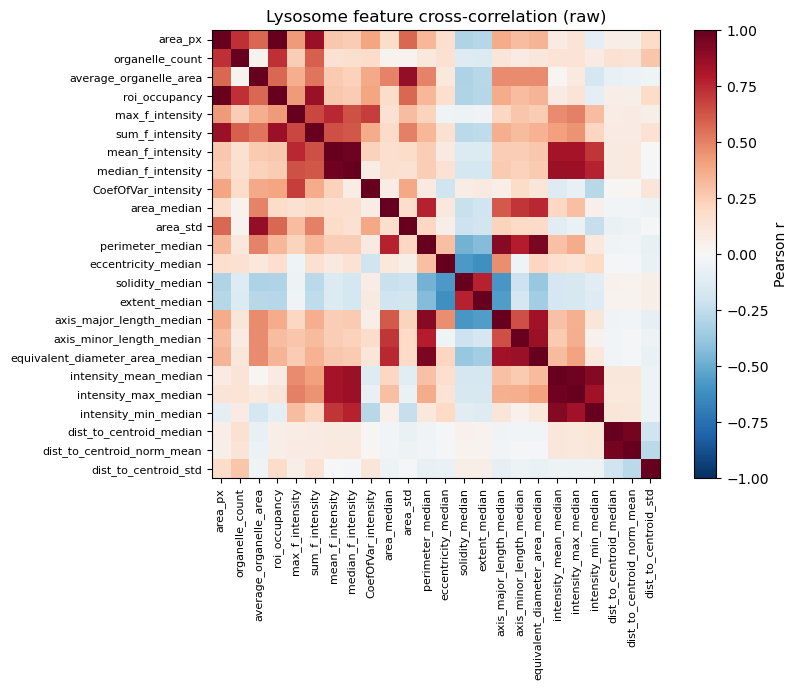

Highly correlated pairs (|r| > 0.9):
  +1.000  area_px                roi_occupancy
  +0.974  mean_f_intensity       median_f_intensity
  +0.972  intensity_mean_median  intensity_max_median
  +0.957  dist_to_centroid_median dist_to_centroid_norm_mean
  +0.941  perimeter_median       equivalent_diameter_area_median
  +0.920  intensity_mean_median  intensity_min_median
  +0.906  perimeter_median       axis_major_length_median
[full] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full] dropped 0 rows with NaN/inf; 576259 remain
[full] EVR: [0.314 0.195 0.153 0.109 0.08  0.055 0.041 0.023 0.021 0.01  0.   ]
[full] cumulative: [0.314 0.508 0.661 0.769 0.85  0.905 0.946 0.969 0.99  1.    1.   ]


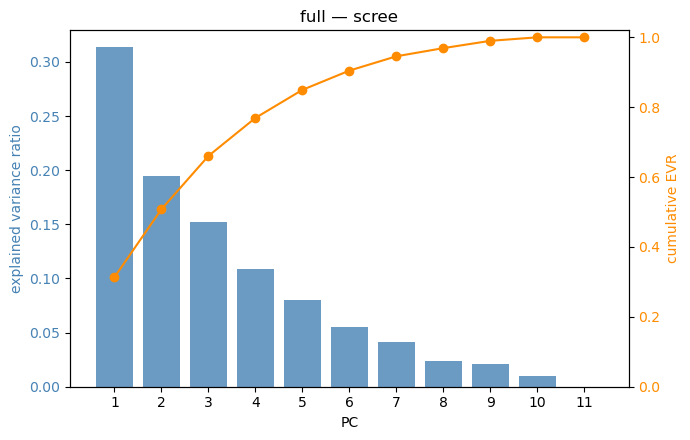

                              PC1    PC2    PC3    PC4    PC5    PC6    PC7  \
area_px                     0.474 -0.240 -0.117  0.101  0.010 -0.215 -0.078   
organelle_count             0.385 -0.258 -0.109  0.082 -0.434 -0.124  0.117   
roi_occupancy               0.474 -0.240 -0.117  0.101  0.010 -0.215 -0.078   
mean_f_intensity            0.262  0.011  0.616 -0.218  0.120  0.045  0.069   
CoefOfVar_intensity         0.166 -0.382  0.031  0.046  0.725  0.342  0.253   
eccentricity_median         0.245  0.451 -0.152 -0.002 -0.102  0.103  0.809   
solidity_median            -0.311 -0.431  0.162  0.013 -0.188 -0.139  0.409   
extent_median              -0.309 -0.448  0.164  0.015 -0.152 -0.159  0.256   
intensity_max_median        0.210  0.136  0.631 -0.226 -0.160 -0.077 -0.058   
dist_to_centroid_norm_mean  0.045 -0.023  0.250  0.721 -0.272  0.565 -0.084   
dist_to_centroid_std        0.090 -0.254 -0.208 -0.593 -0.321  0.627 -0.083   

                              PC8    PC9   PC10   P

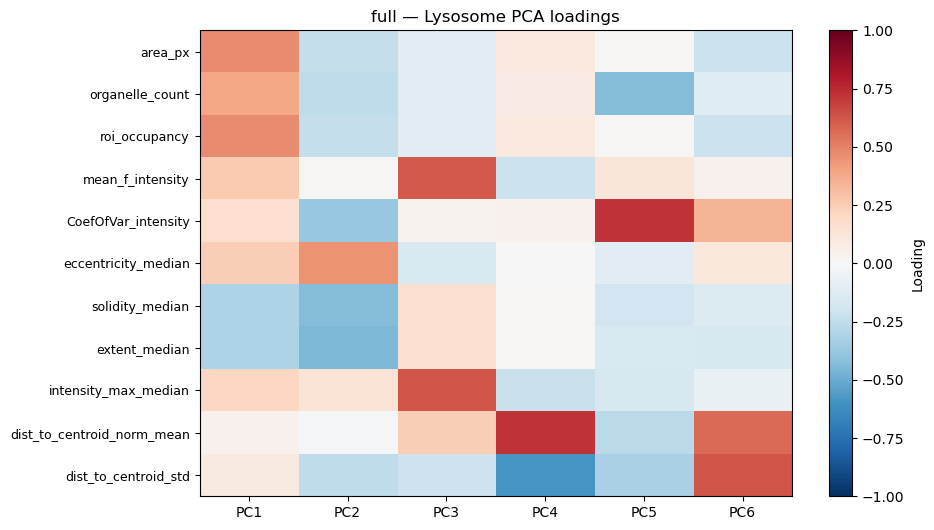

In [15]:
df_auto = df[df["Source"] == "automated"]
feature_correlation(df_auto)
df_auto, pca, FEATURES = fit_pca(df_auto, label="full")

### PCA plots - ROI-level

All 13 iNDI_Plate_ID values have a color.


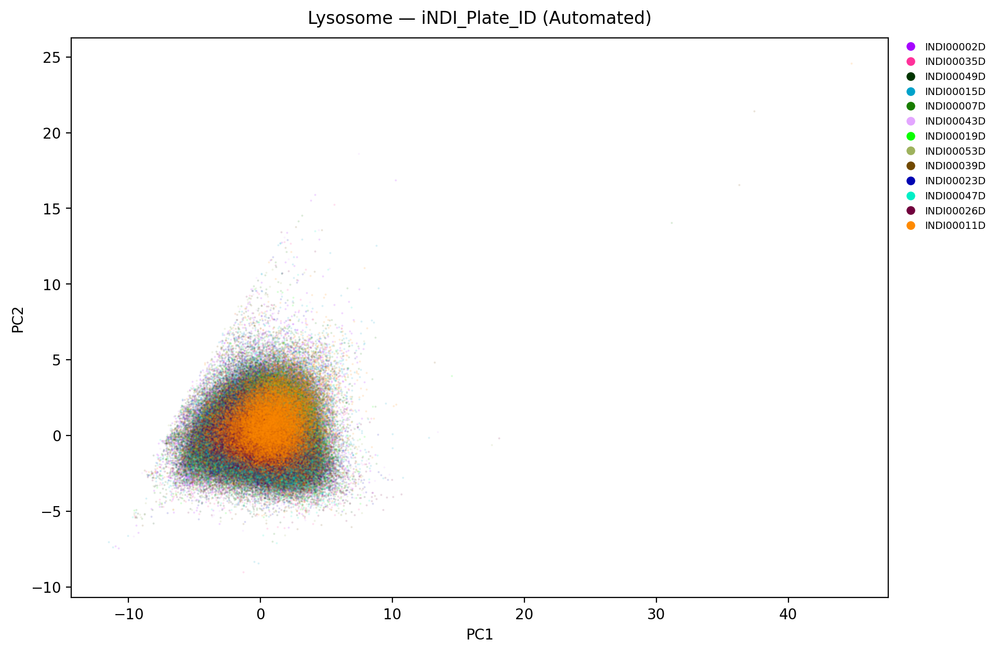

All 4 Batch values have a color.


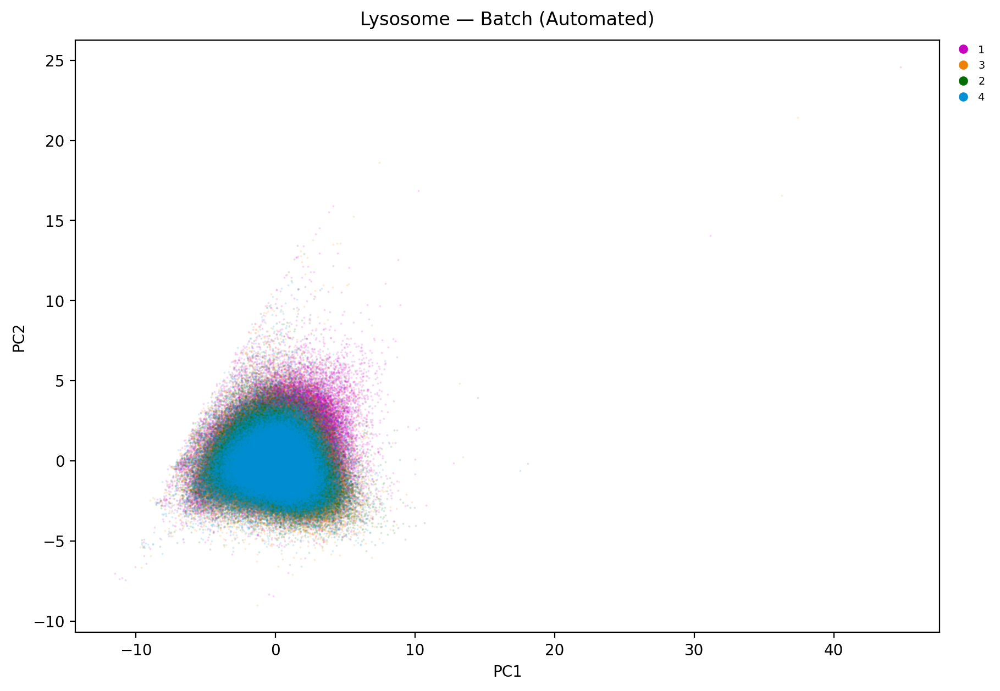

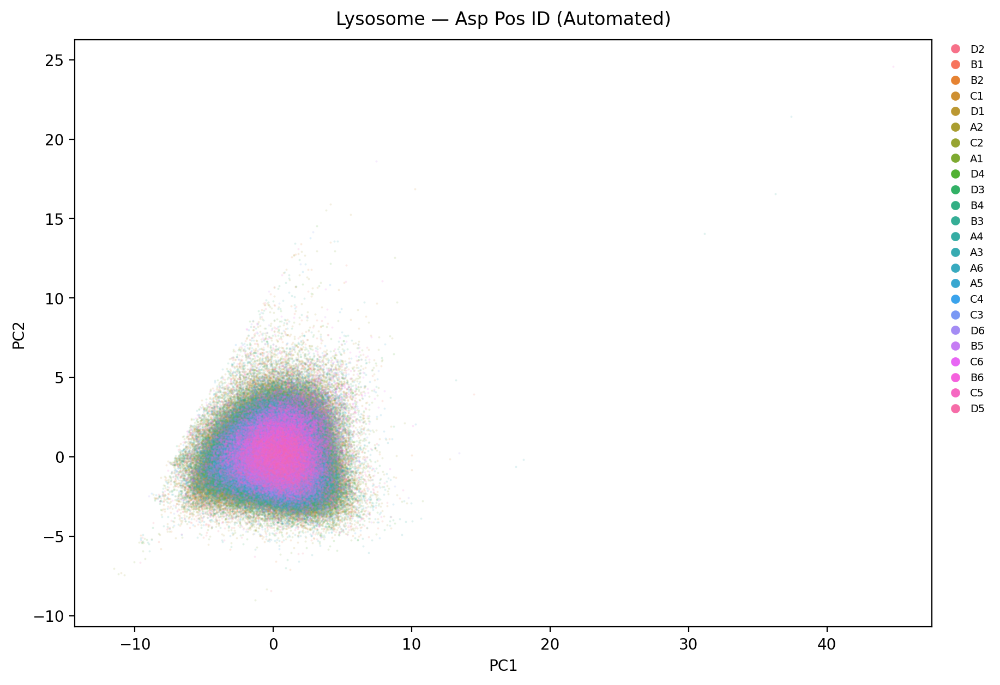

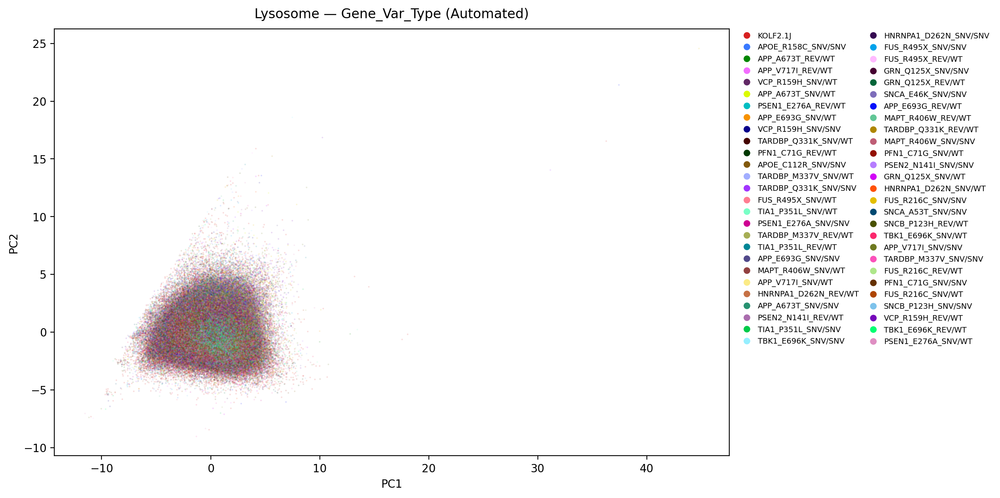

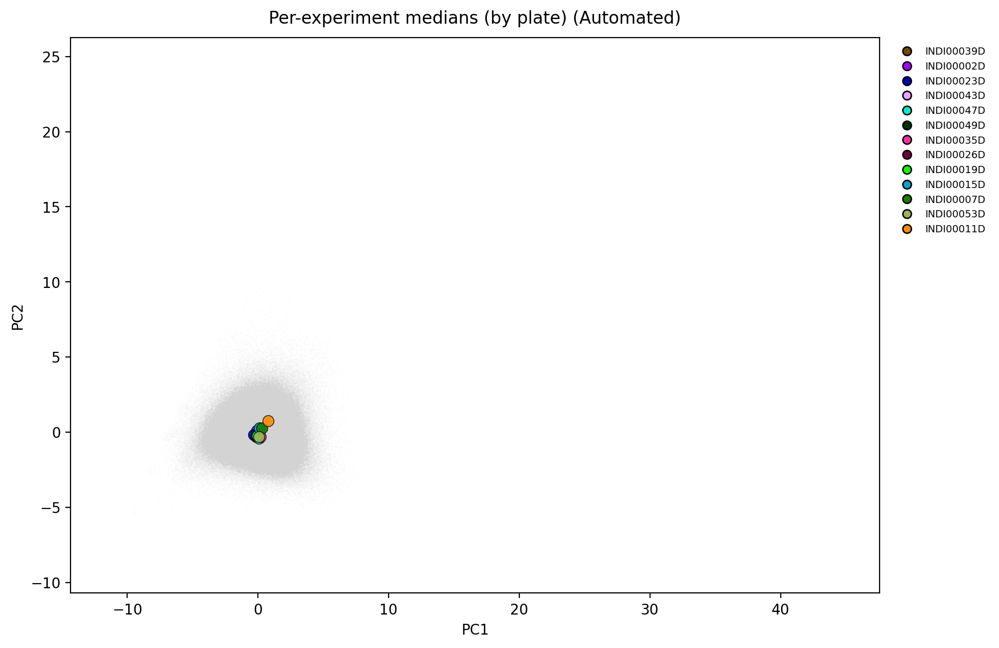

Std of per-experiment centroids (batch magnitude):
PC1    0.269
PC2    0.340
PC3    0.404
dtype: float64


In [16]:
plate_pal = make_palette(df_auto["iNDI_Plate_ID"])
check_palette_coverage(df_auto, "iNDI_Plate_ID", plate_pal)
pca_scatter(df_auto, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Lysosome — iNDI_Plate_ID (Automated)")

batch_palette = make_palette(df_auto["Batch"])
check_palette_coverage(df_auto, "Batch", batch_palette)
pca_scatter(df_auto, "Batch", palette=batch_palette, figsize=(12, 7),title="Lysosome — Batch (Automated)")

pca_scatter(df_auto, "Asp PosID", figsize=(12, 7),title="Lysosome — Asp Pos ID (Automated)")

pca_scatter(df_auto, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Lysosome — Gene_Var_Type (Automated)")

centroid_overlay(df_auto, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate) (Automated)")
cent = df_auto.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

### PCA plots - well-level

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 118307 rows (13440 images)
[full] well-level: 3739 rows
[full well] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full well] dropped 0 rows with NaN/inf; 3739 remain
[full well] EVR: [0.439 0.179 0.132 0.109 0.08  0.026 0.021 0.009 0.003 0.003 0.   ]
[full well] cumulative: [0.439 0.618 0.75  0.859 0.939 0.965 0.986 0.994 0.997 1.    1.   ]


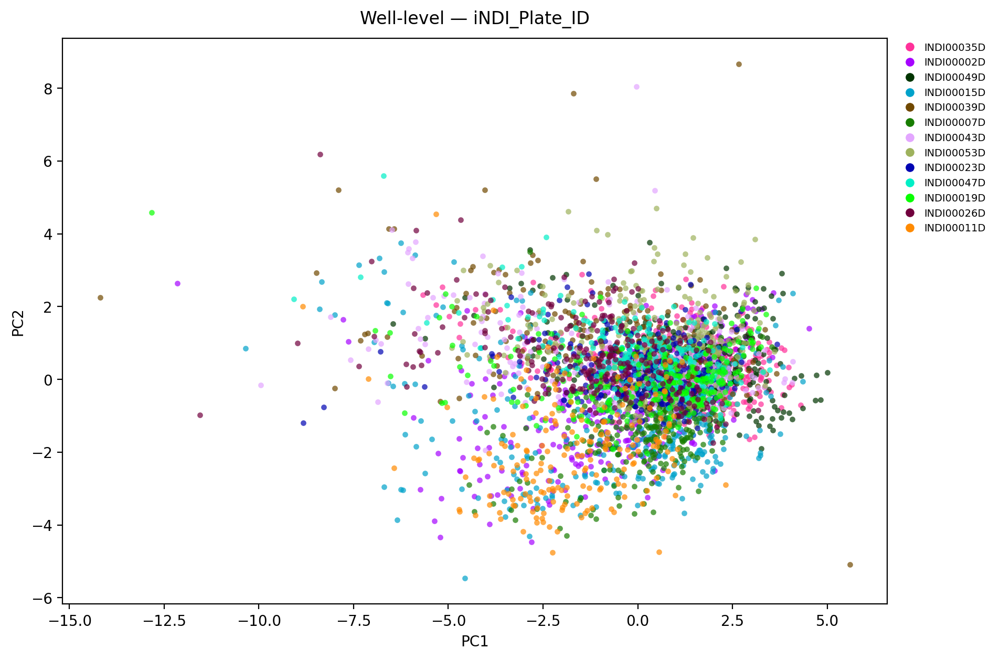

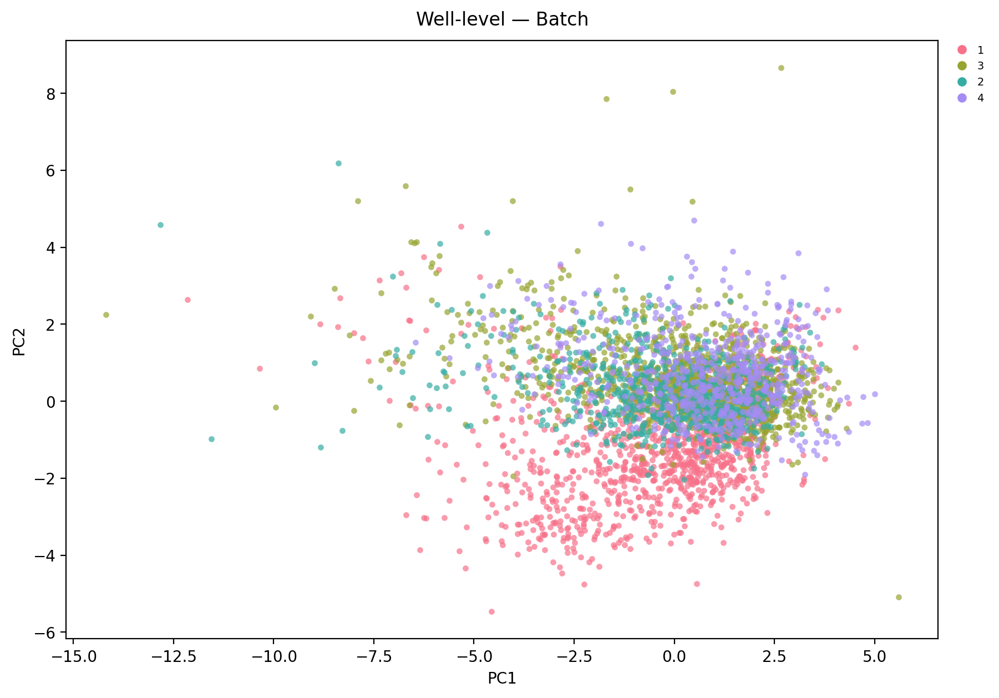

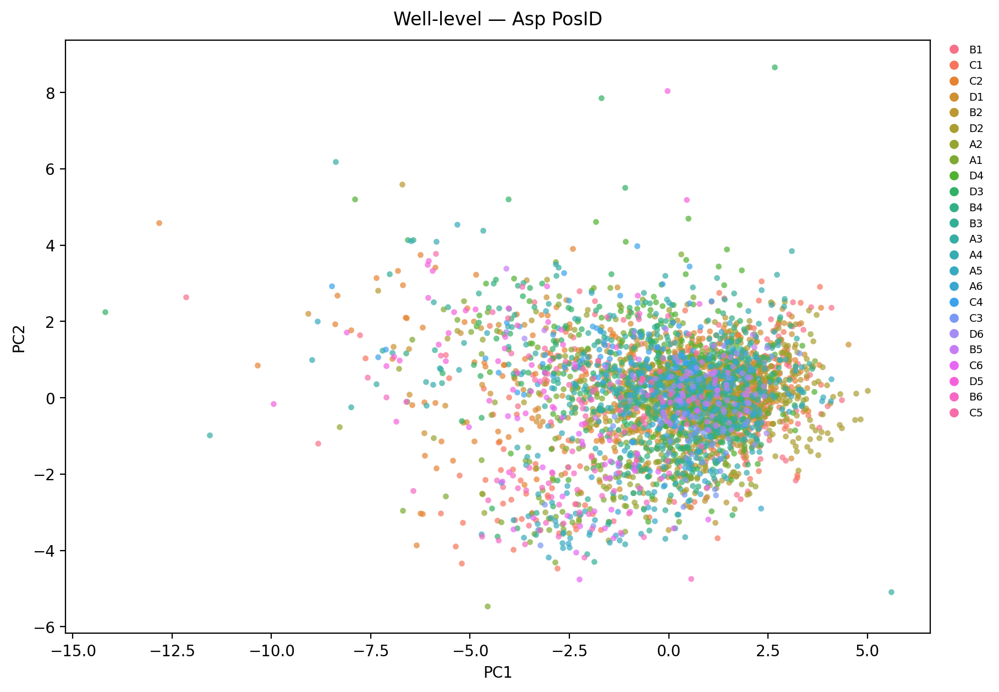

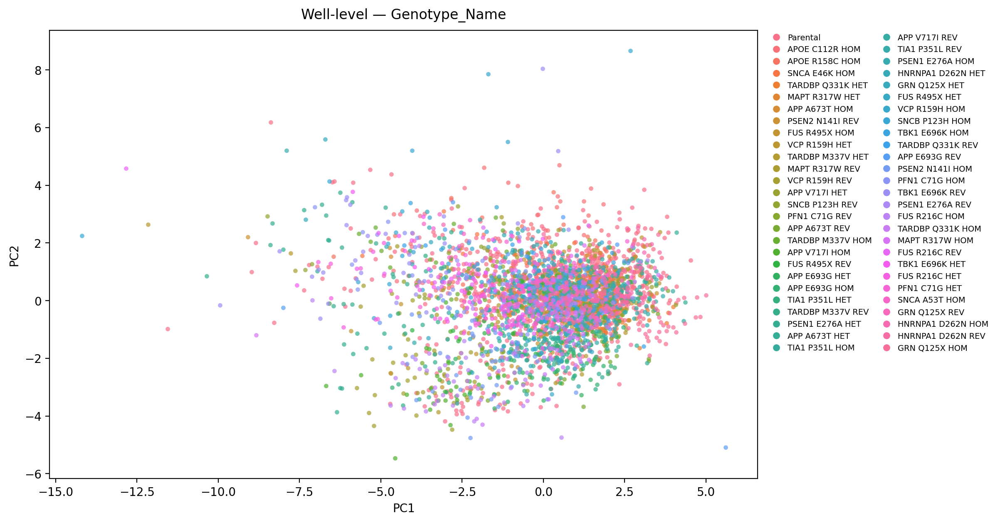

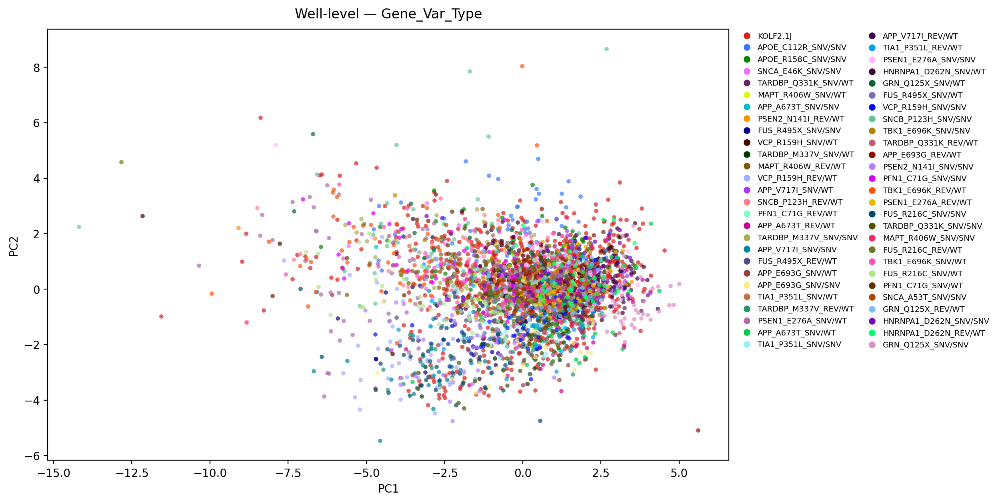

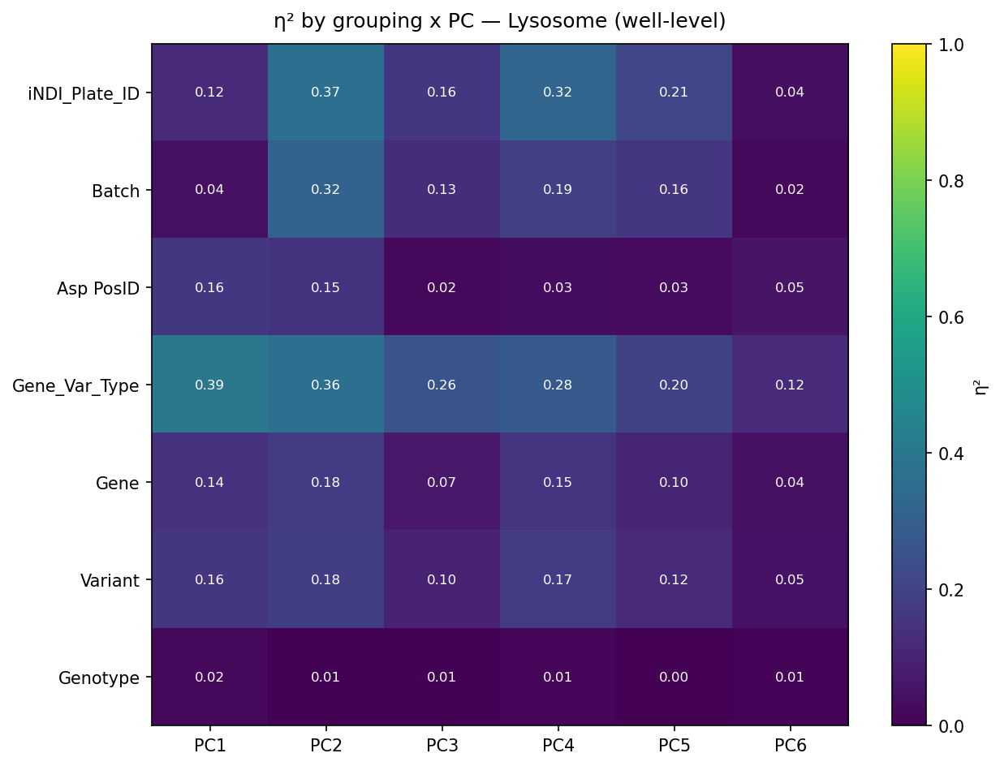

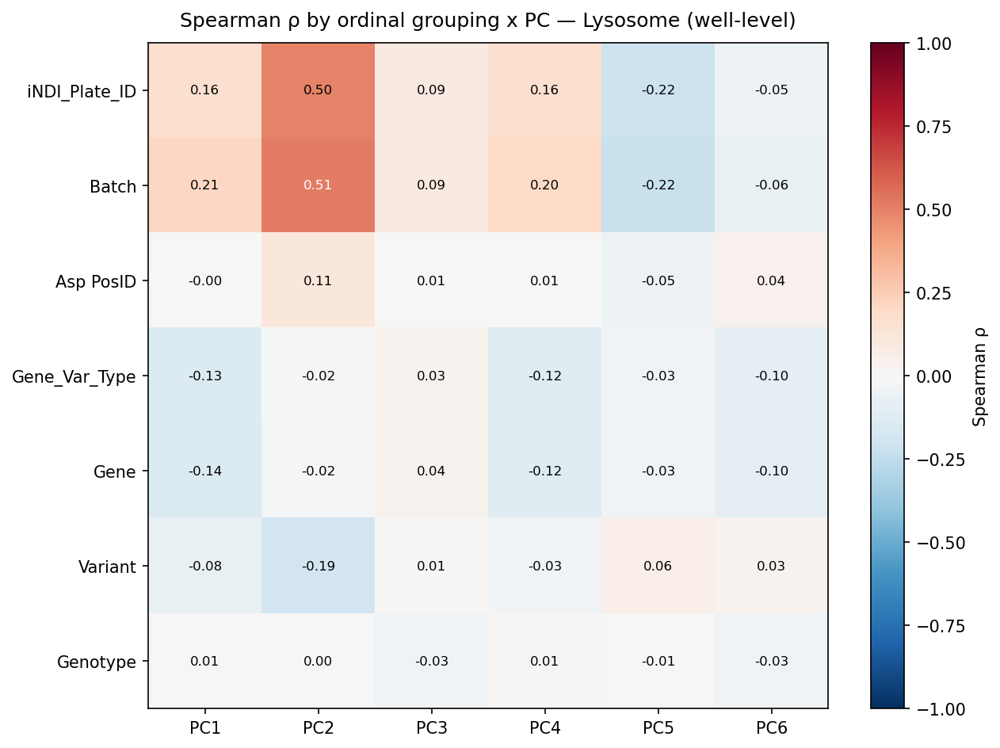

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.162013,0.498403,0.093620,0.162000,-0.216766,-0.050221
Batch,0.210653,0.511663,0.089455,0.201798,-0.219805,-0.063760
Asp PosID,-0.003619,0.110501,0.007646,0.006859,-0.054569,0.039768
Gene_Var_Type,-0.133973,-0.015404,0.034701,-0.118919,-0.032977,-0.098468
Gene,-0.135085,-0.016631,0.037822,-0.118944,-0.032140,-0.098292
Variant,-0.076876,-0.188351,0.010680,-0.031217,0.064510,0.031606
Genotype,0.005004,0.003149,-0.034084,0.014959,-0.005640,-0.031433


In [17]:
well_level = aggregate_wells(df_auto, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"],
            n_pcs=6, title="η² by grouping x PC — Lysosome (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — Lysosome (well-level)")

[facet] 21 (gene, variant) pairs; 1139 total KOLF2.1J rows (all folded into each facet)
  APOE / C112R: 93 variant + 1139 parental rows


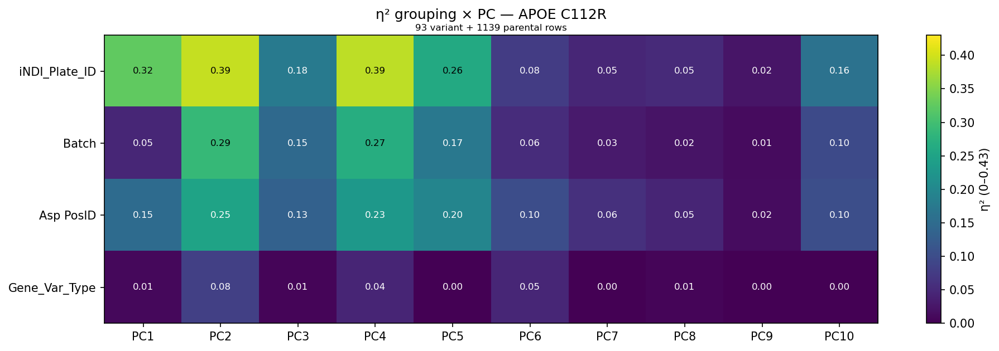

  APOE / R158C: 89 variant + 1139 parental rows


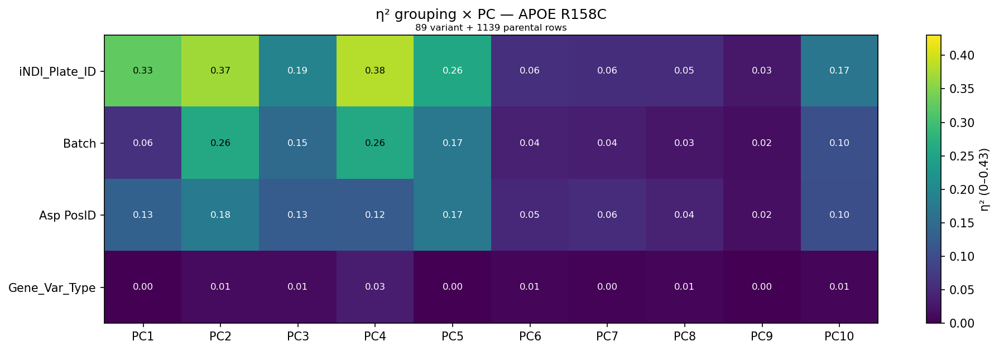

  APP / A673T: 144 variant + 1139 parental rows


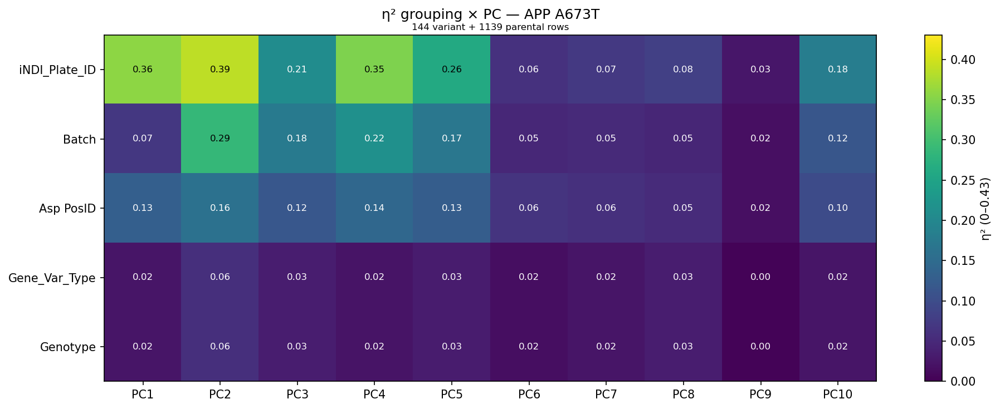

  APP / E693G: 144 variant + 1139 parental rows


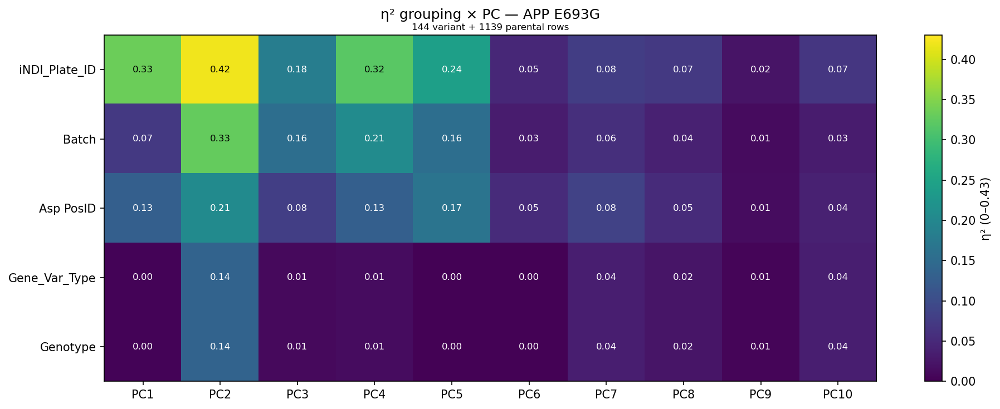

  APP / V717I: 144 variant + 1139 parental rows


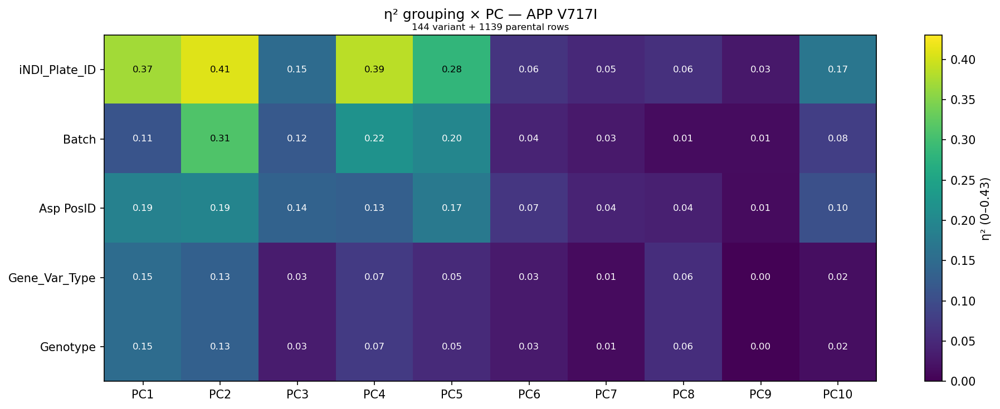

  FUS / R216C: 141 variant + 1139 parental rows


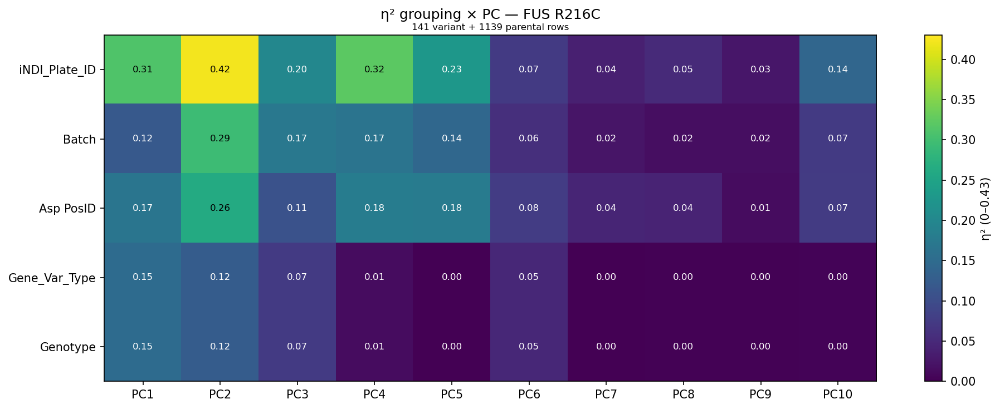

  FUS / R495X: 144 variant + 1139 parental rows


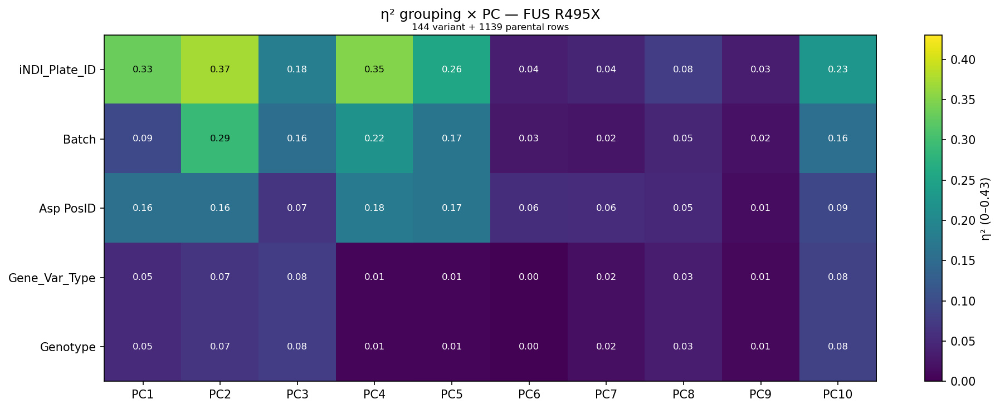

  GRN / Q125X: 134 variant + 1139 parental rows


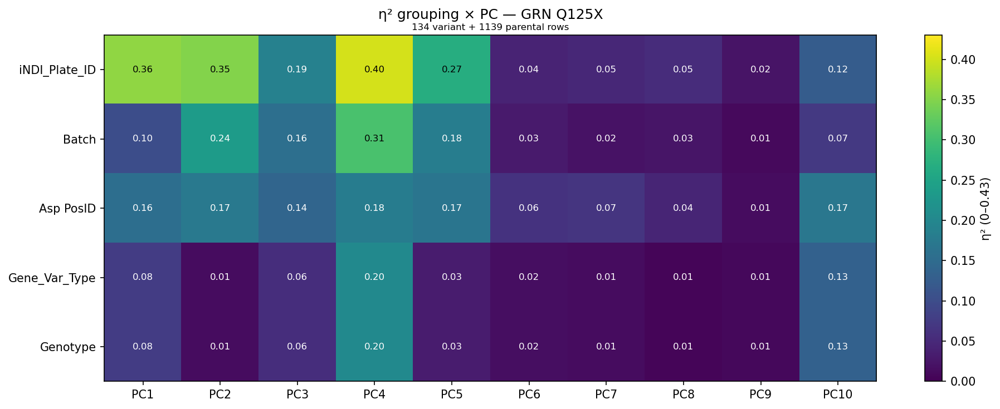

  HNRNPA1 / D262N: 136 variant + 1139 parental rows


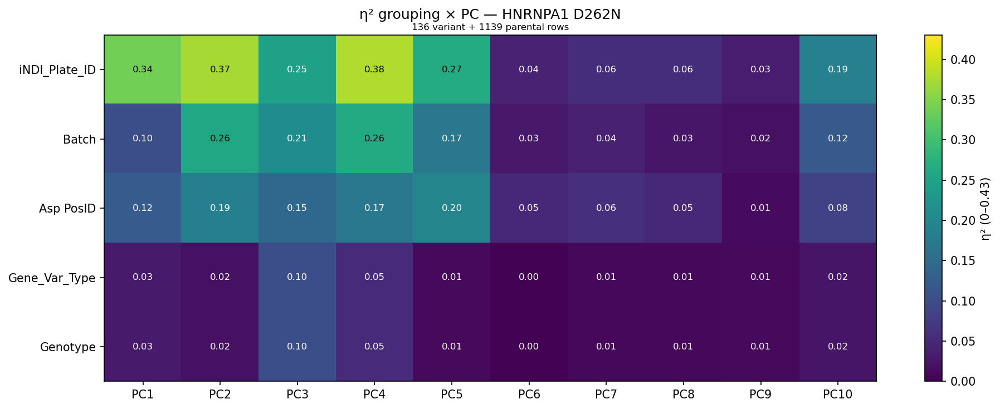

  MAPT / R406W: 143 variant + 1139 parental rows


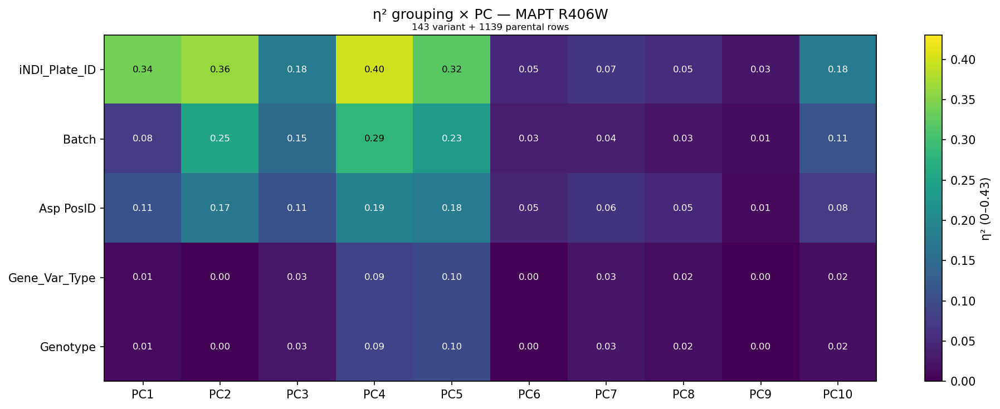

  PFN1 / C71G: 142 variant + 1139 parental rows


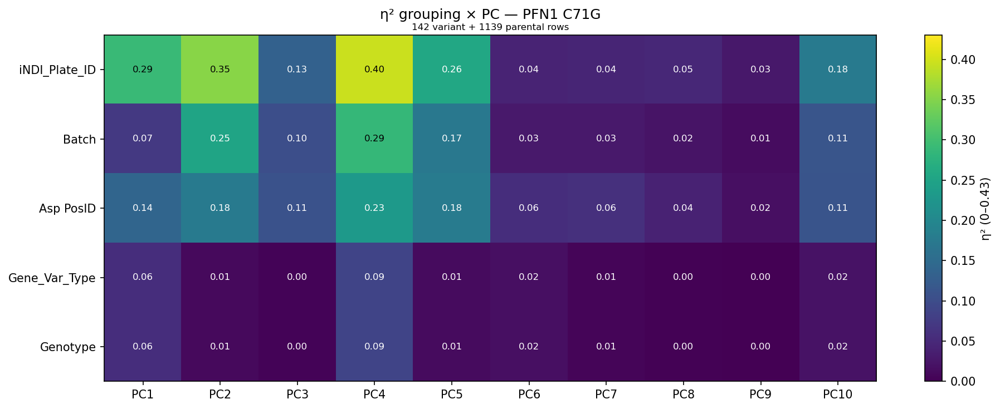

  PSEN1 / E276A: 143 variant + 1139 parental rows


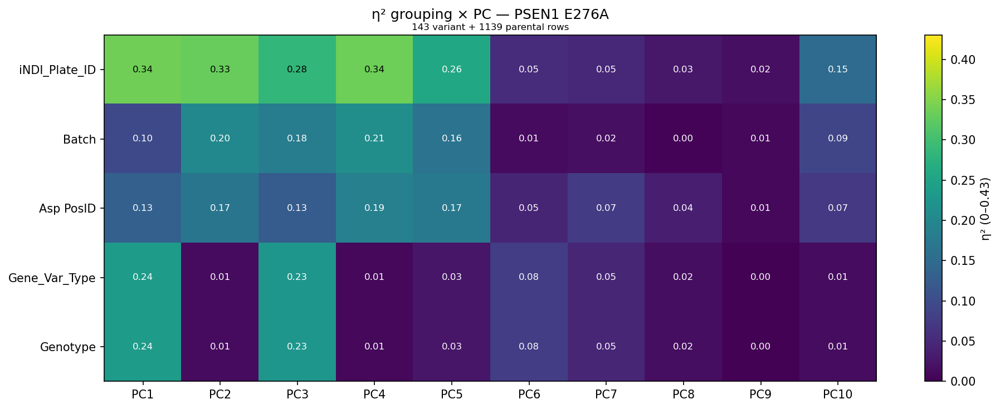

  PSEN2 / N141I: 96 variant + 1139 parental rows


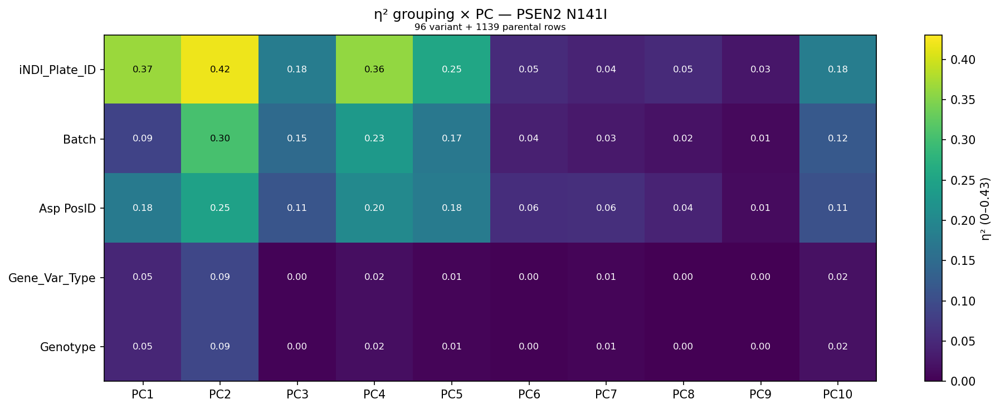

  SNCA / A53T: 46 variant + 1139 parental rows


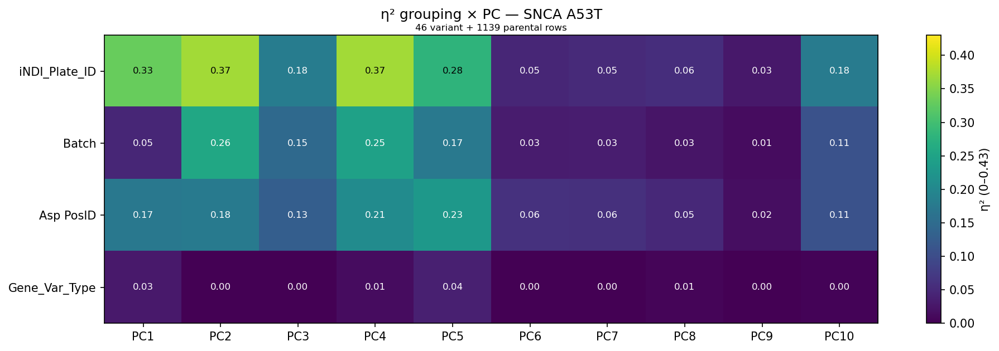

  SNCA / E46K: 48 variant + 1139 parental rows


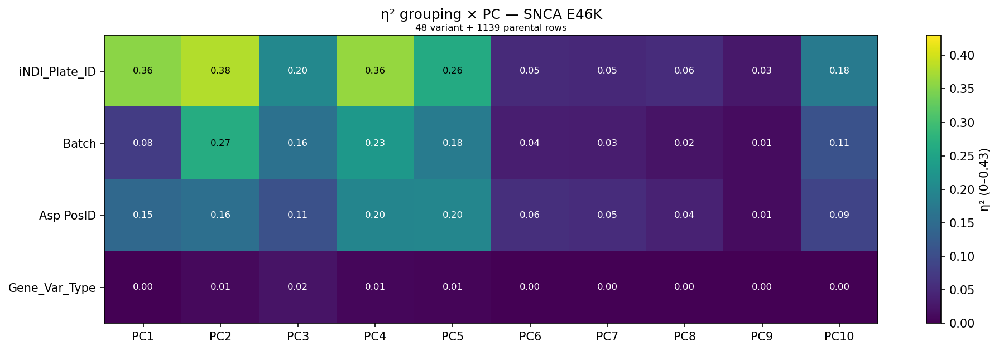

  SNCB / P123H: 96 variant + 1139 parental rows


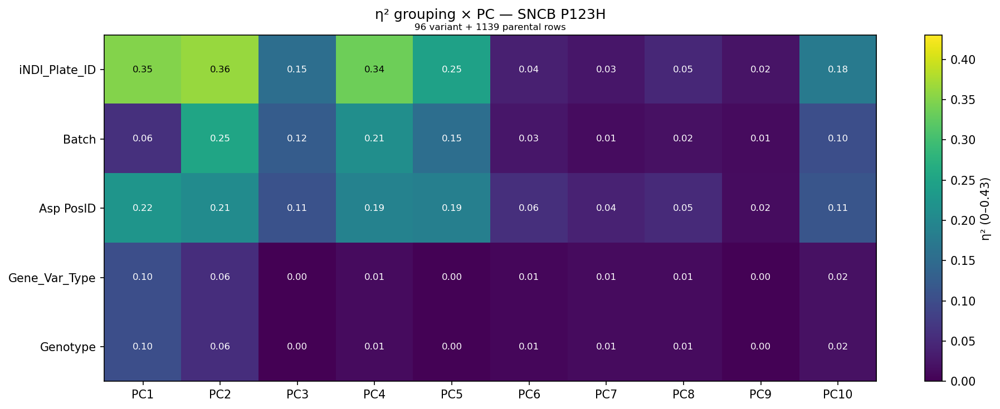

  TARDBP / M337V: 144 variant + 1139 parental rows


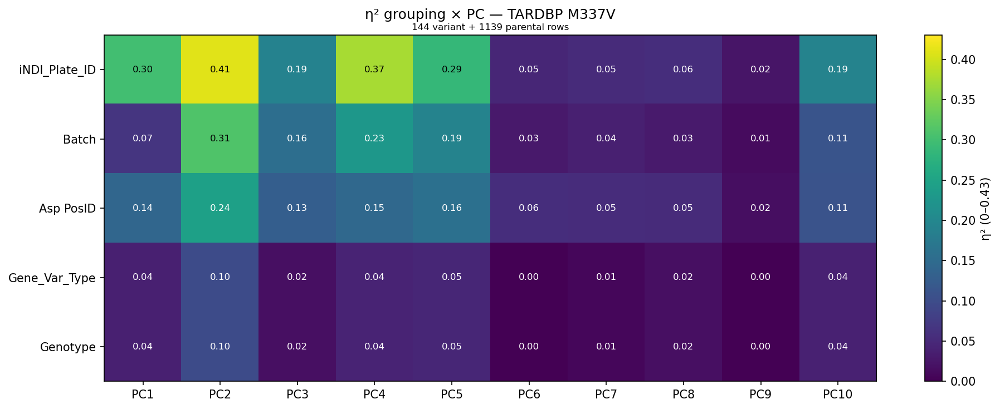

  TARDBP / Q331K: 143 variant + 1139 parental rows


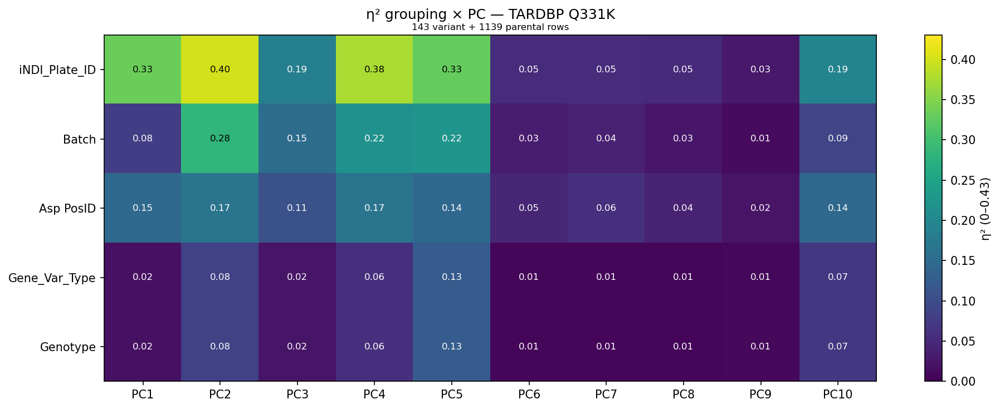

  TBK1 / E696K: 142 variant + 1139 parental rows


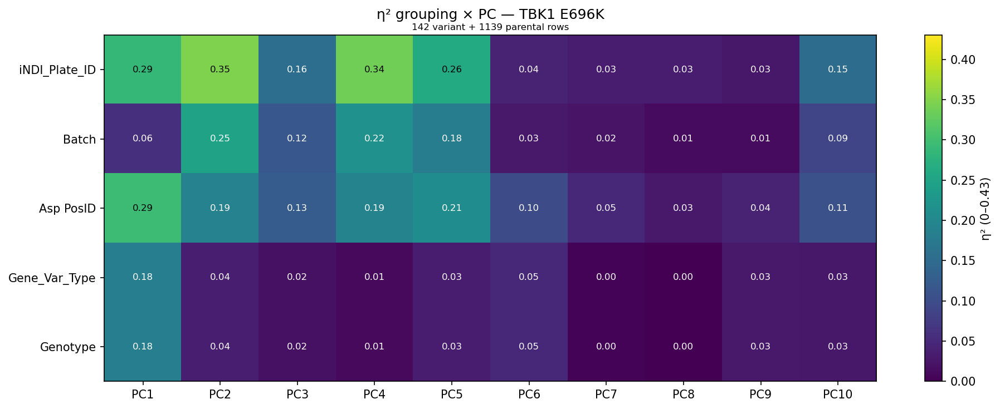

  TIA1 / P351L: 144 variant + 1139 parental rows


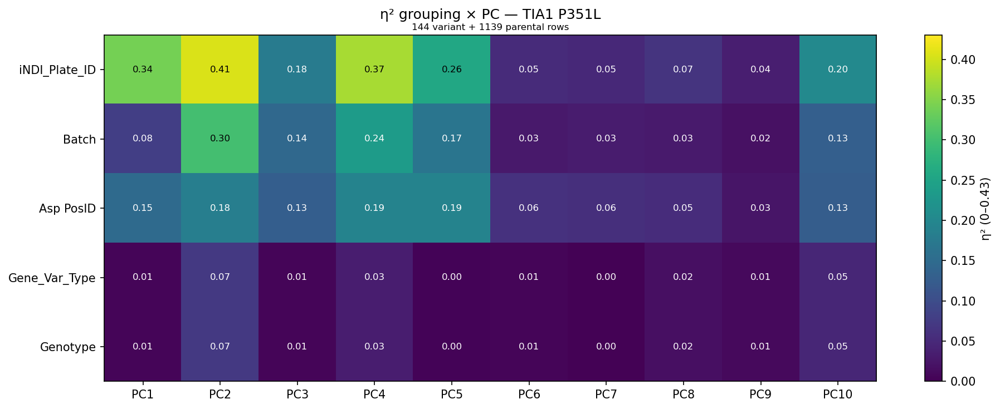

  VCP / R159H: 144 variant + 1139 parental rows


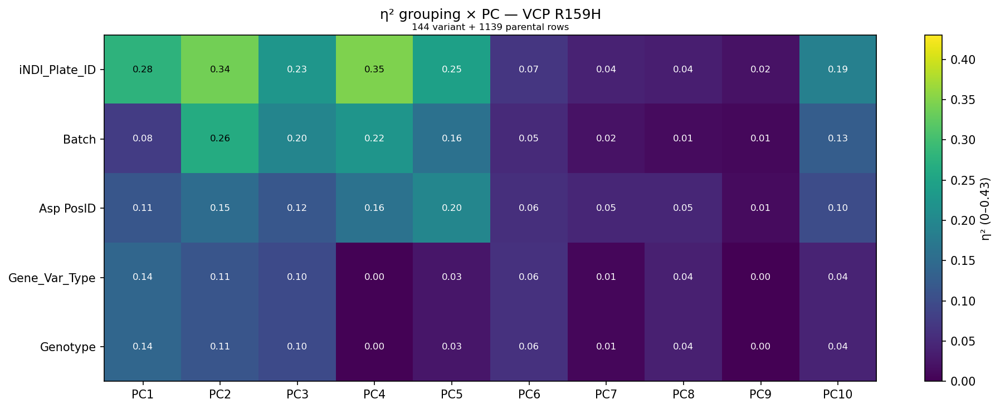

[facet] 21 (gene, variant) pairs; 1139 total KOLF2.1J rows (plate-matched per facet)
  APOE / C112R: 93 variant + 94 parental rows on 1 plate(s)


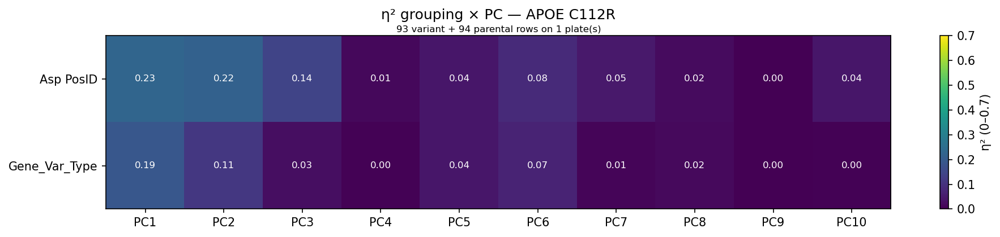

  APOE / R158C: 89 variant + 185 parental rows on 2 plate(s)


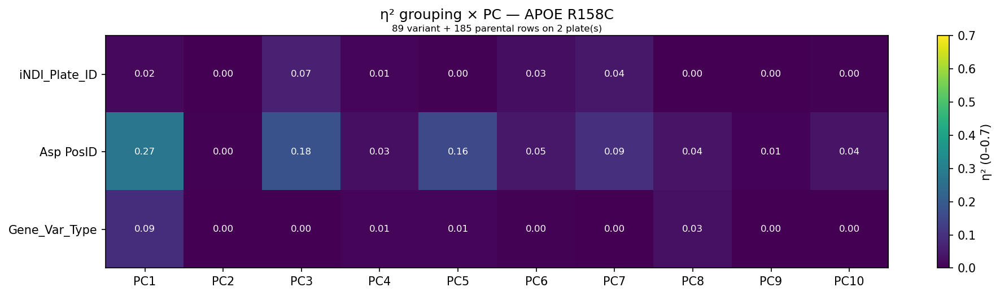

  APP / A673T: 144 variant + 144 parental rows on 2 plate(s)


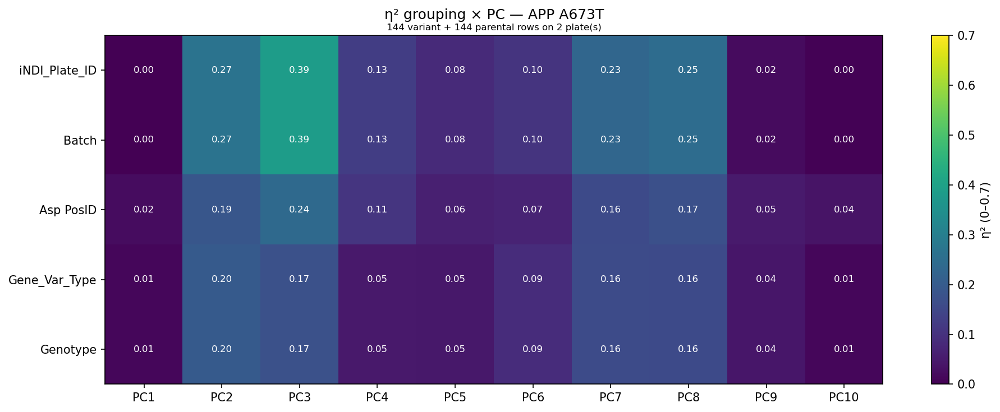

  APP / E693G: 144 variant + 144 parental rows on 2 plate(s)


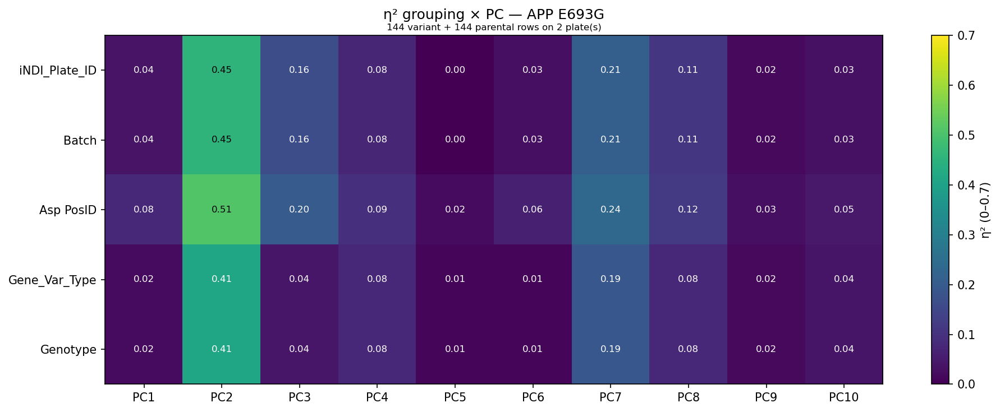

  APP / V717I: 144 variant + 144 parental rows on 2 plate(s)


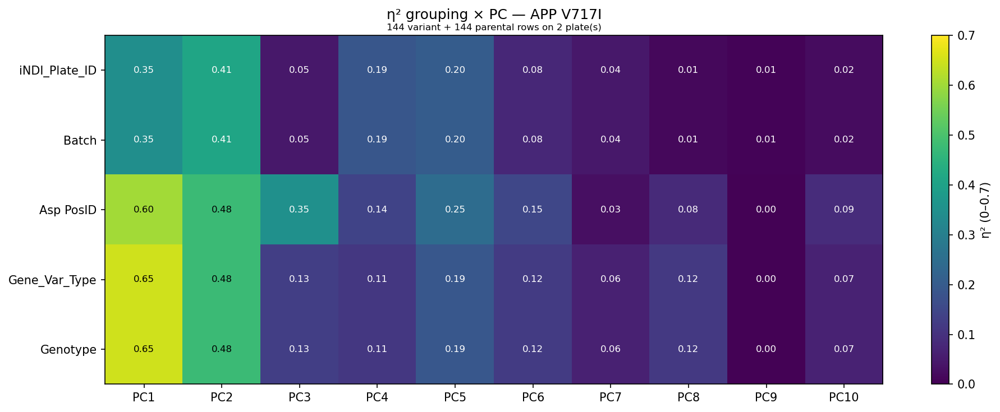

  FUS / R216C: 141 variant + 191 parental rows on 2 plate(s)


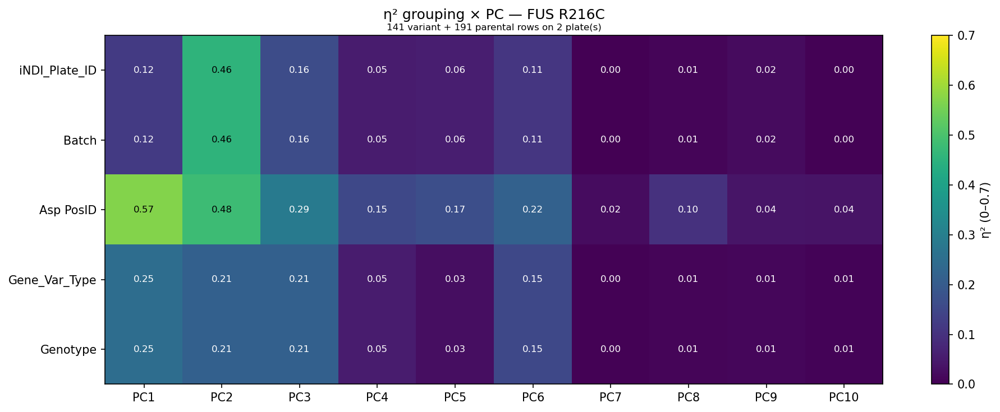

  FUS / R495X: 144 variant + 96 parental rows on 1 plate(s)


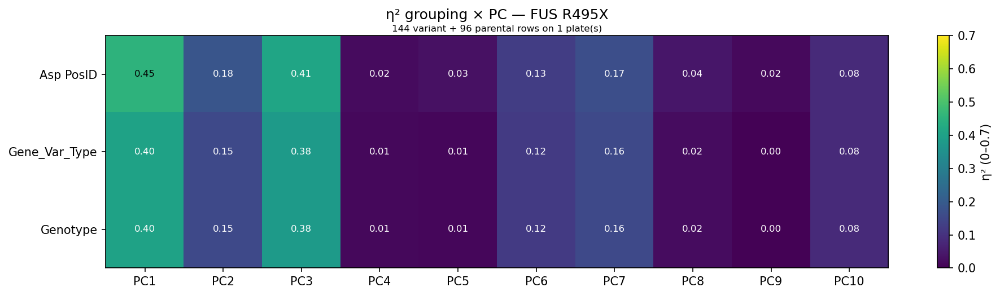

  GRN / Q125X: 134 variant + 186 parental rows on 2 plate(s)


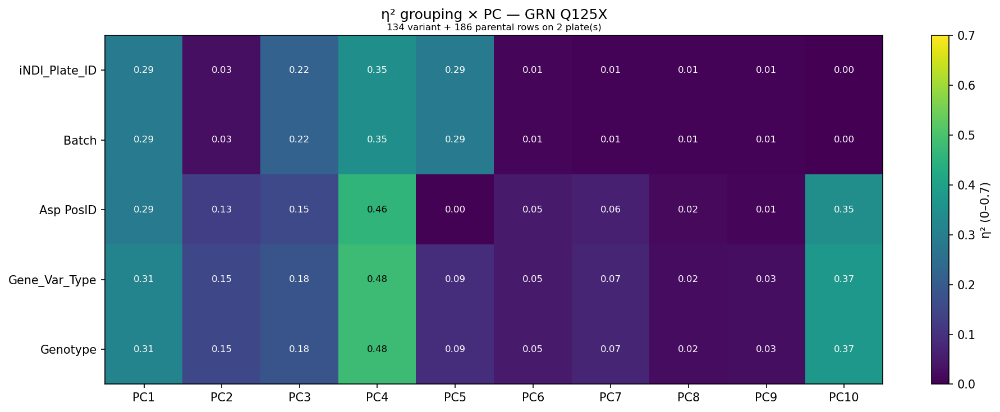

  HNRNPA1 / D262N: 136 variant + 183 parental rows on 2 plate(s)


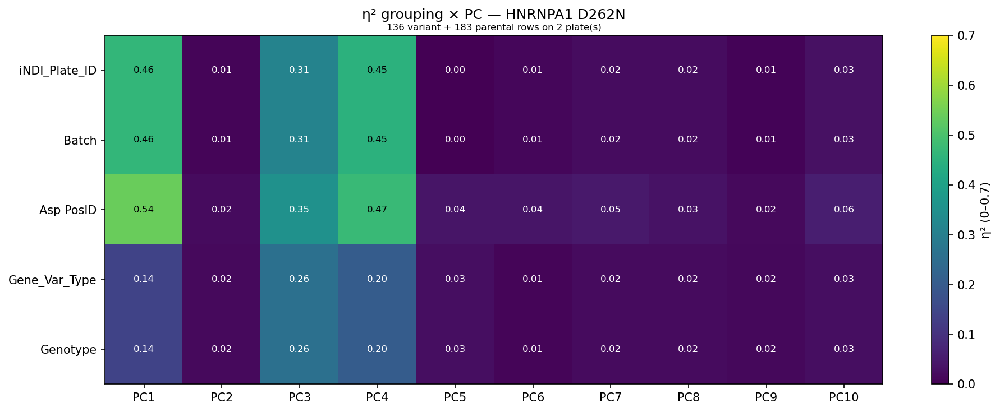

  MAPT / R406W: 143 variant + 96 parental rows on 1 plate(s)


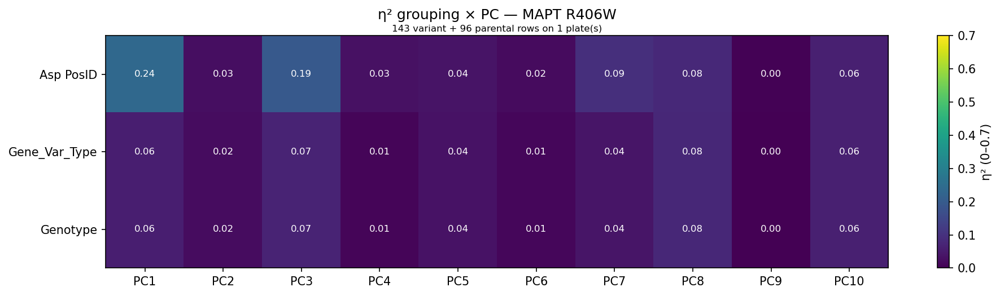

  PFN1 / C71G: 142 variant + 183 parental rows on 2 plate(s)


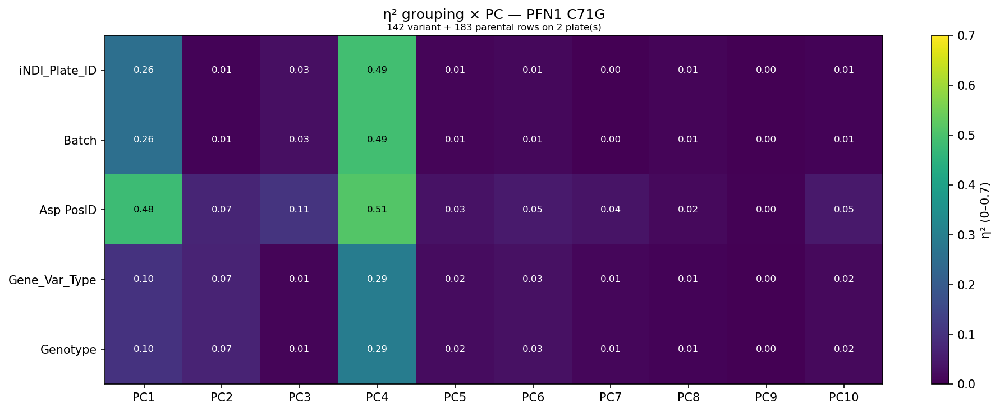

  PSEN1 / E276A: 143 variant + 239 parental rows on 3 plate(s)


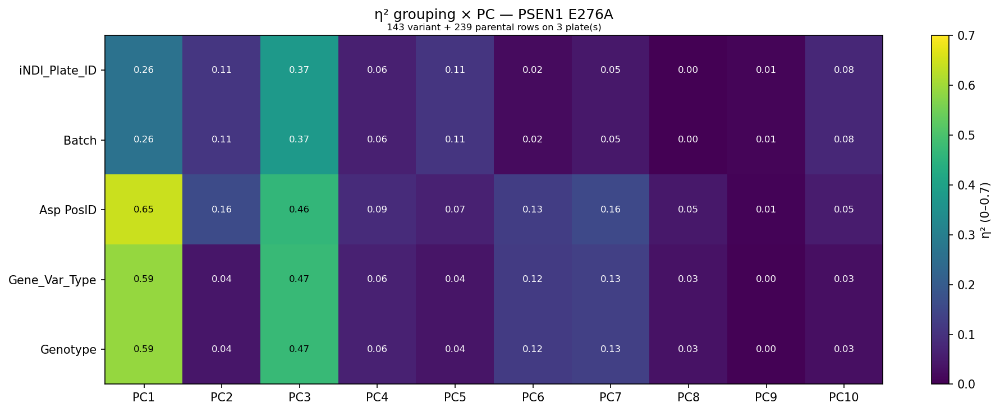

  PSEN2 / N141I: 96 variant + 191 parental rows on 2 plate(s)


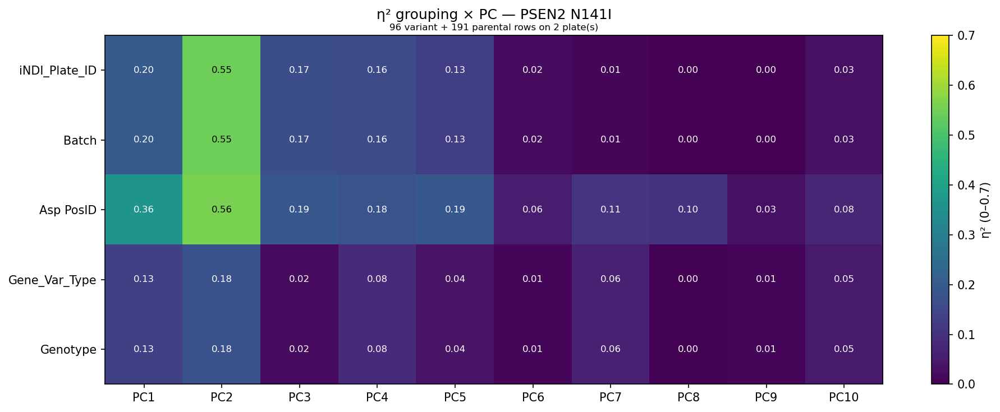

  SNCA / A53T: 46 variant + 94 parental rows on 1 plate(s)


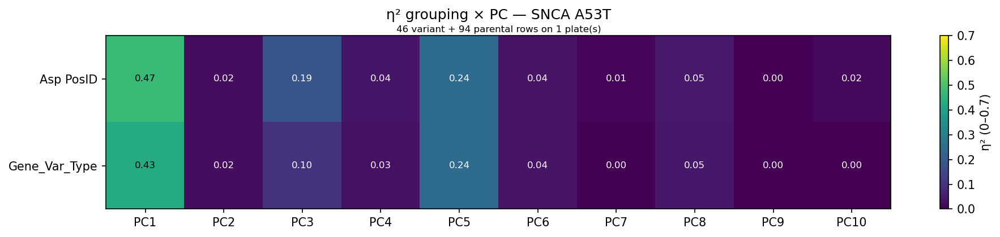

  SNCA / E46K: 48 variant + 95 parental rows on 1 plate(s)


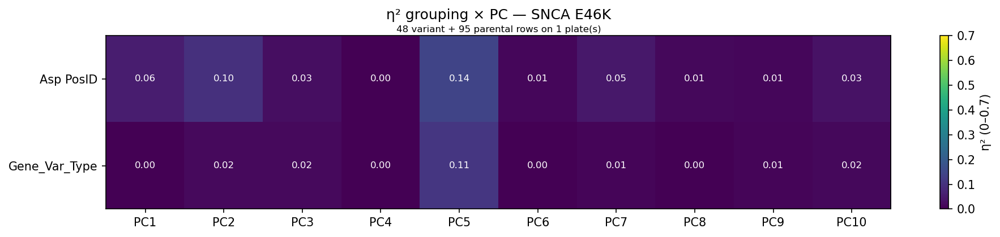

  SNCB / P123H: 96 variant + 96 parental rows on 1 plate(s)


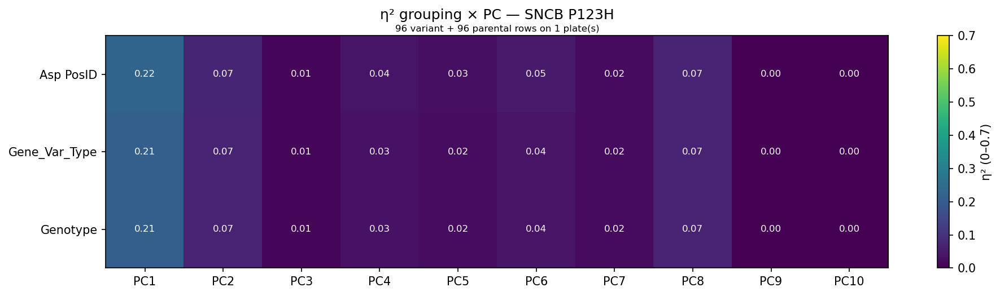

  TARDBP / M337V: 144 variant + 144 parental rows on 2 plate(s)


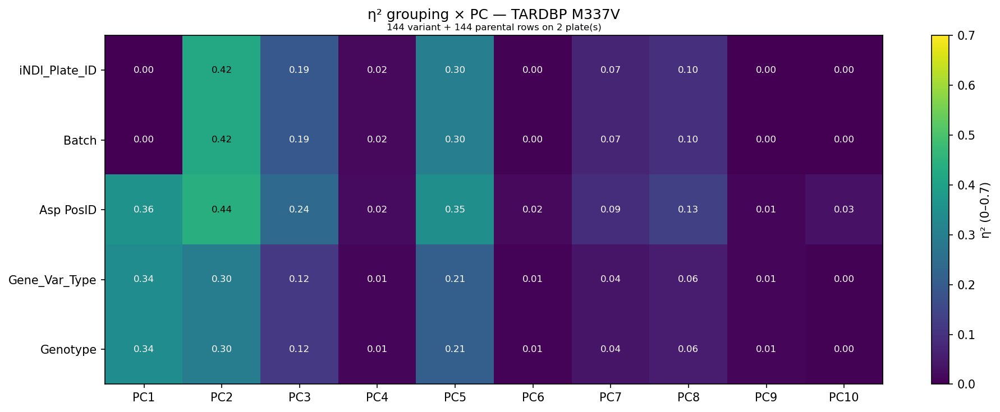

  TARDBP / Q331K: 143 variant + 144 parental rows on 2 plate(s)


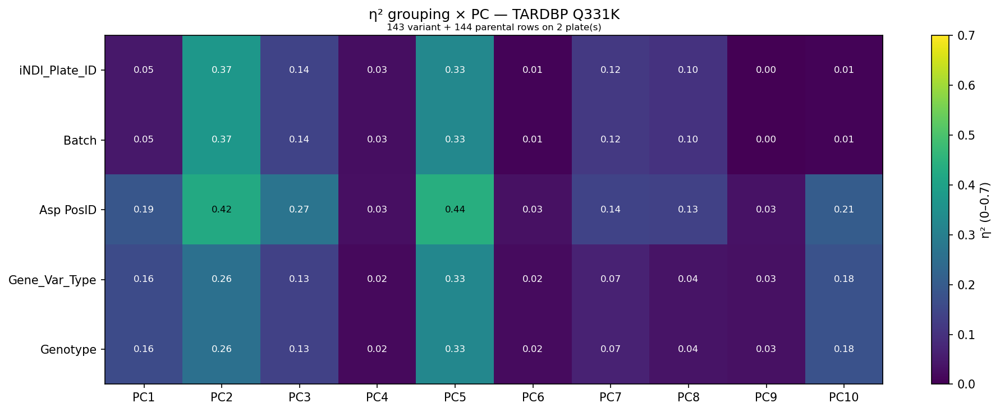

  TBK1 / E696K: 142 variant + 96 parental rows on 1 plate(s)


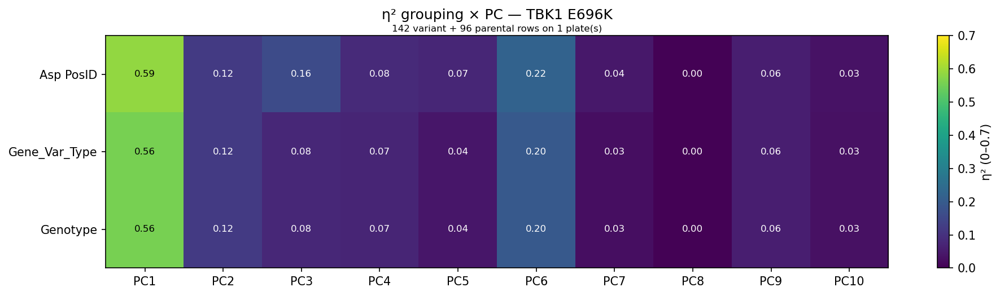

  TIA1 / P351L: 144 variant + 144 parental rows on 2 plate(s)


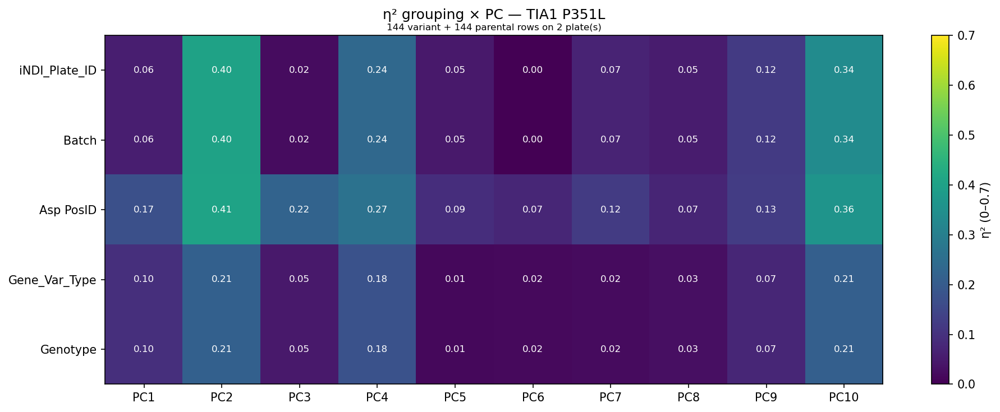

  VCP / R159H: 144 variant + 96 parental rows on 1 plate(s)


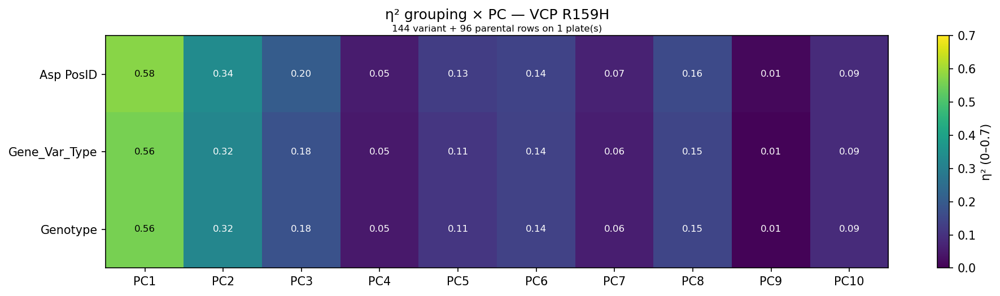

In [18]:
GROUP_COLS = ["Source", "iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Variant", "Genotype"]

mats = facet_by_gene_variant(well_level, GROUP_COLS, n_pcs=10, vmax=0.43, plate_match=False)
mats = facet_by_gene_variant(well_level, GROUP_COLS, n_pcs=10, vmax=0.7, plate_match=True)

## Manual analysis
### Feature assessment and loadings

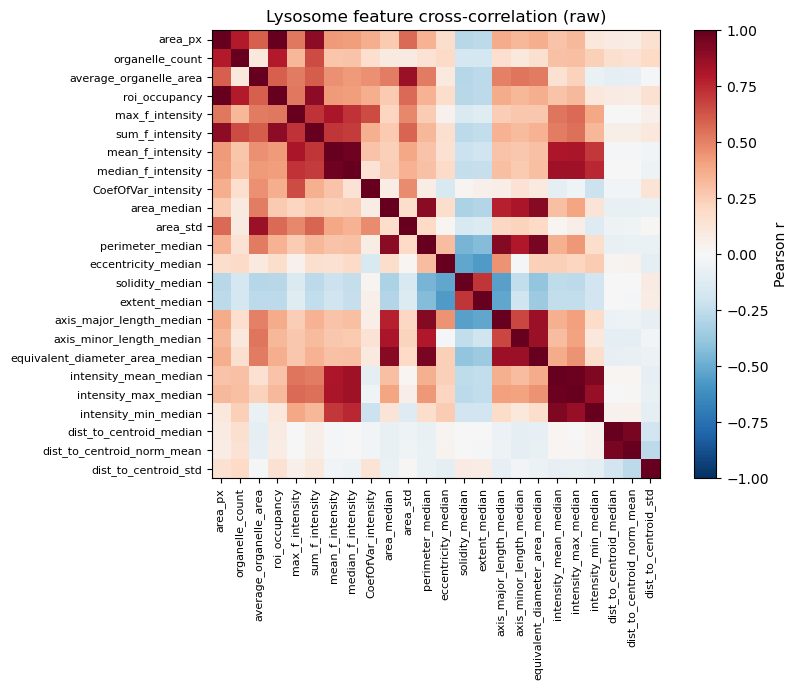

Highly correlated pairs (|r| > 0.9):
  +1.000  area_px                roi_occupancy
  +0.978  intensity_mean_median  intensity_max_median
  +0.974  mean_f_intensity       median_f_intensity
  +0.951  perimeter_median       equivalent_diameter_area_median
  +0.950  dist_to_centroid_median dist_to_centroid_norm_mean
  +0.933  intensity_mean_median  intensity_min_median
  +0.919  perimeter_median       axis_major_length_median
  +0.912  area_median            equivalent_diameter_area_median
[full] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full] dropped 0 rows with NaN/inf; 455154 remain
[full] EVR: [0.344 0.183 0.122 0.111 0.081 0.057 0.045 0.026 0.02  0.01  0.   ]
[full] cumulative: [0.344 0.527 0.649 0.761 0.842 0.899 0.944 0.97  0.99  1.    1.   ]


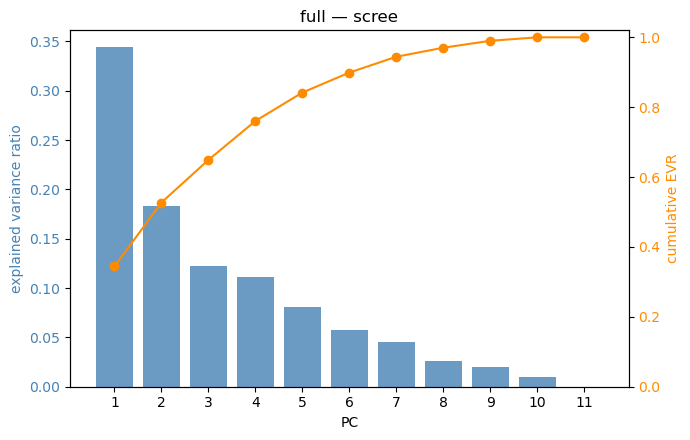

                              PC1    PC2    PC3    PC4    PC5    PC6    PC7  \
area_px                     0.453  0.244 -0.148  0.108 -0.027 -0.204 -0.055   
organelle_count             0.389  0.225 -0.188  0.181 -0.338 -0.107  0.049   
roi_occupancy               0.453  0.244 -0.148  0.108 -0.027 -0.204 -0.055   
mean_f_intensity            0.335  0.018  0.580 -0.186  0.089  0.156  0.074   
CoefOfVar_intensity         0.153  0.367 -0.002 -0.071  0.796  0.178  0.230   
eccentricity_median         0.225 -0.449 -0.195 -0.022 -0.077  0.069  0.822   
solidity_median            -0.279  0.432  0.199  0.103 -0.218 -0.074  0.424   
extent_median              -0.275  0.453  0.217  0.095 -0.190 -0.098  0.261   
intensity_max_median        0.308 -0.116  0.591 -0.153 -0.250  0.089 -0.065   
dist_to_centroid_norm_mean  0.043 -0.040  0.072  0.780 -0.013  0.609 -0.061   
dist_to_centroid_std        0.044  0.294 -0.324 -0.502 -0.300  0.672 -0.040   

                              PC8    PC9   PC10   P

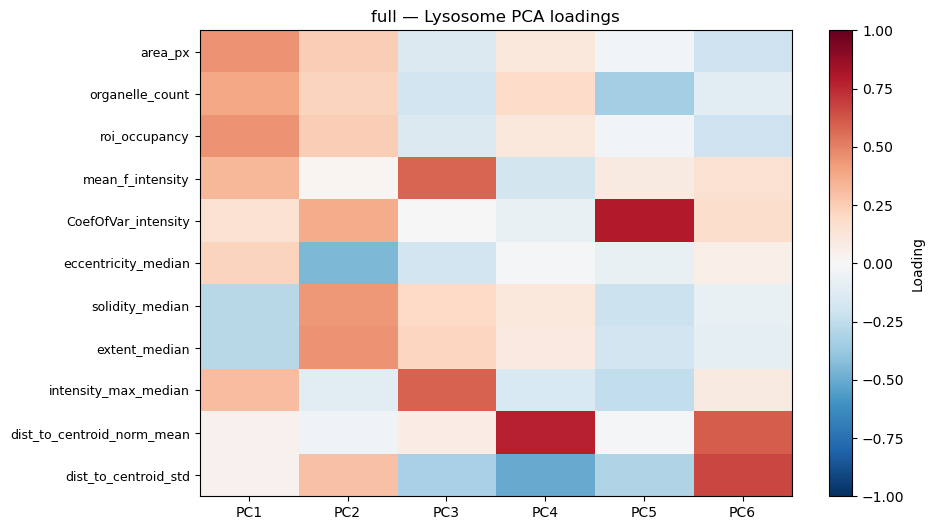

In [19]:
df_manual = df[df["Source"] == "manual"]
feature_correlation(df_manual)
df_manual, pca, FEATURES = fit_pca(df_manual, label="full")

### PCA plots - ROI-level

All 8 iNDI_Plate_ID values have a color.


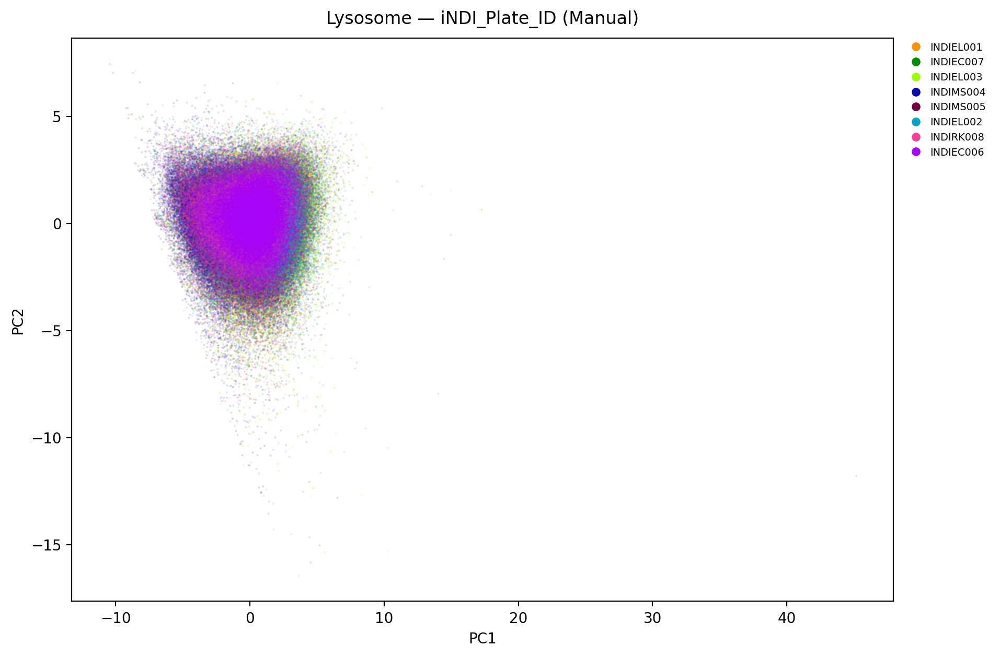

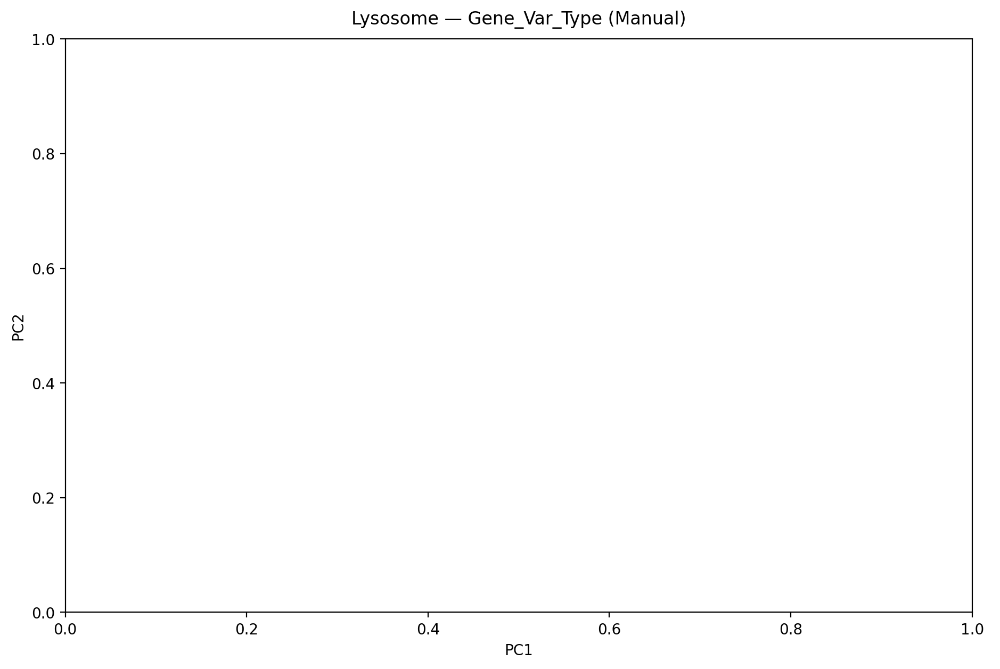

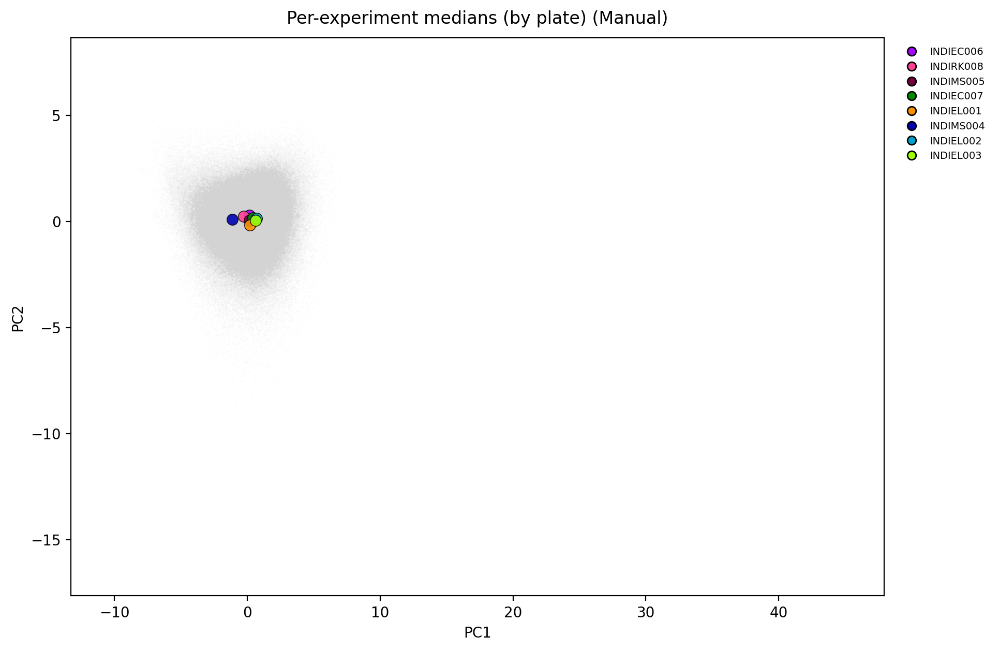

Std of per-experiment centroids (batch magnitude):
PC1    0.591
PC2    0.138
PC3    0.484
dtype: float64


In [20]:
plate_pal = make_palette(df_manual["iNDI_Plate_ID"])
check_palette_coverage(df_manual, "iNDI_Plate_ID", plate_pal)
pca_scatter(df_manual, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Lysosome — iNDI_Plate_ID (Manual)")

pca_scatter(df_manual, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Lysosome — Gene_Var_Type (Manual)")

centroid_overlay(df_manual, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate) (Manual)")
cent = df_manual.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

### PCA plots - well-level

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 74647 rows (11755 images)
[full] well-level: 2192 rows
[full well] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full well] dropped 0 rows with NaN/inf; 2192 remain
[full well] EVR: [0.371 0.227 0.182 0.1   0.068 0.02  0.014 0.011 0.008 0.001 0.   ]
[full well] cumulative: [0.371 0.598 0.78  0.88  0.948 0.967 0.981 0.991 0.999 1.    1.   ]


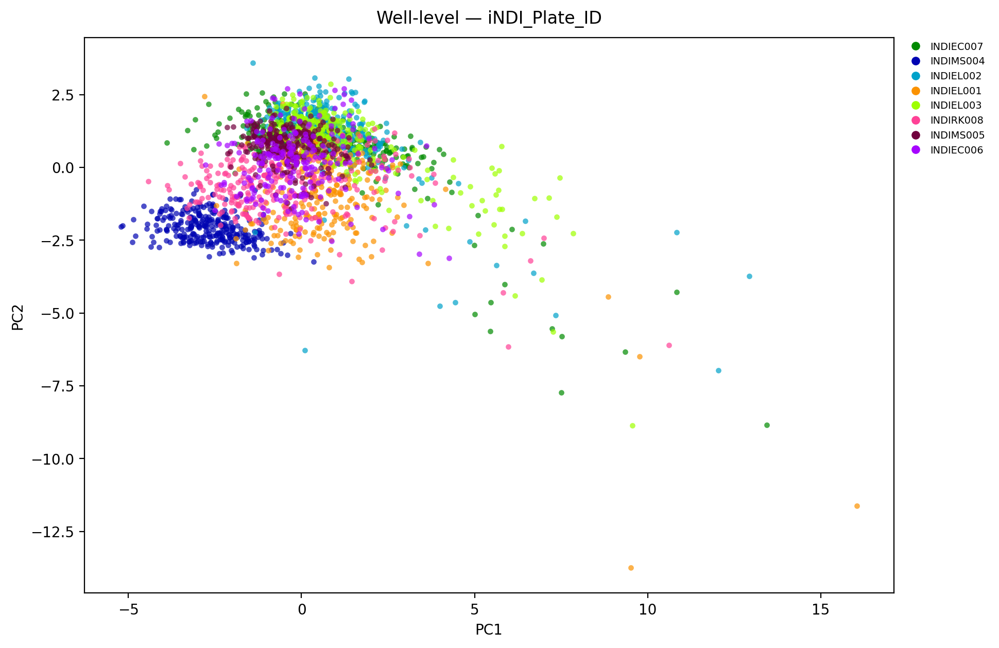

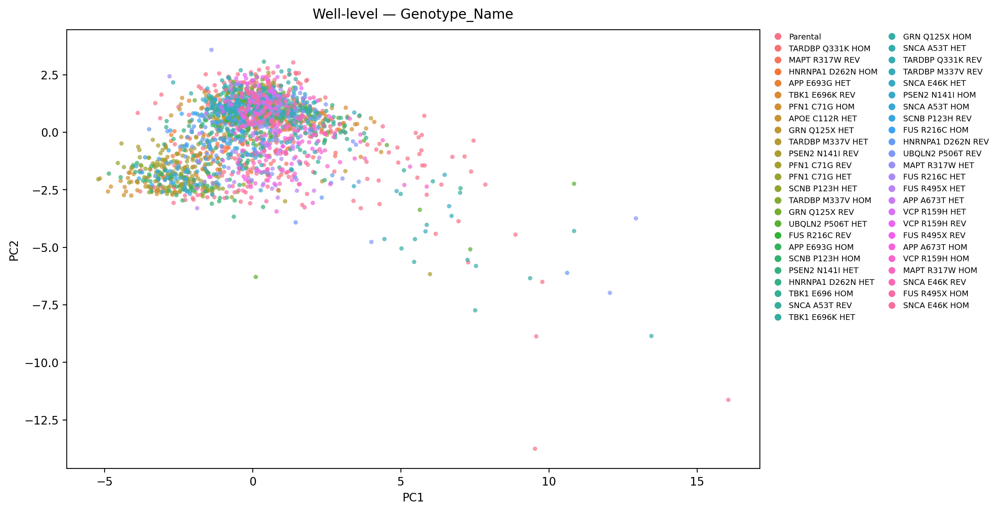

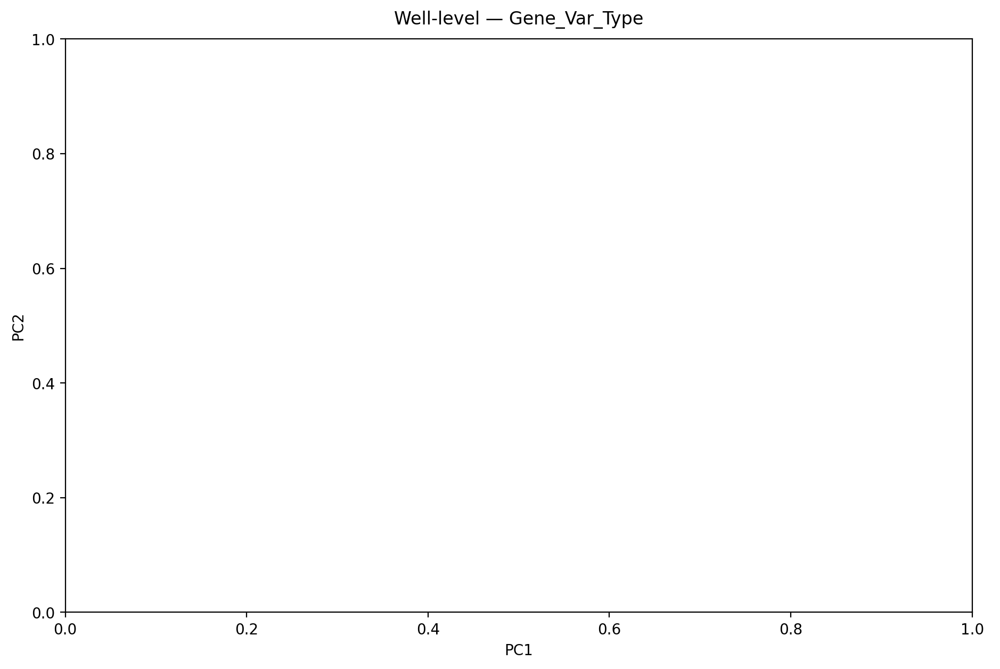

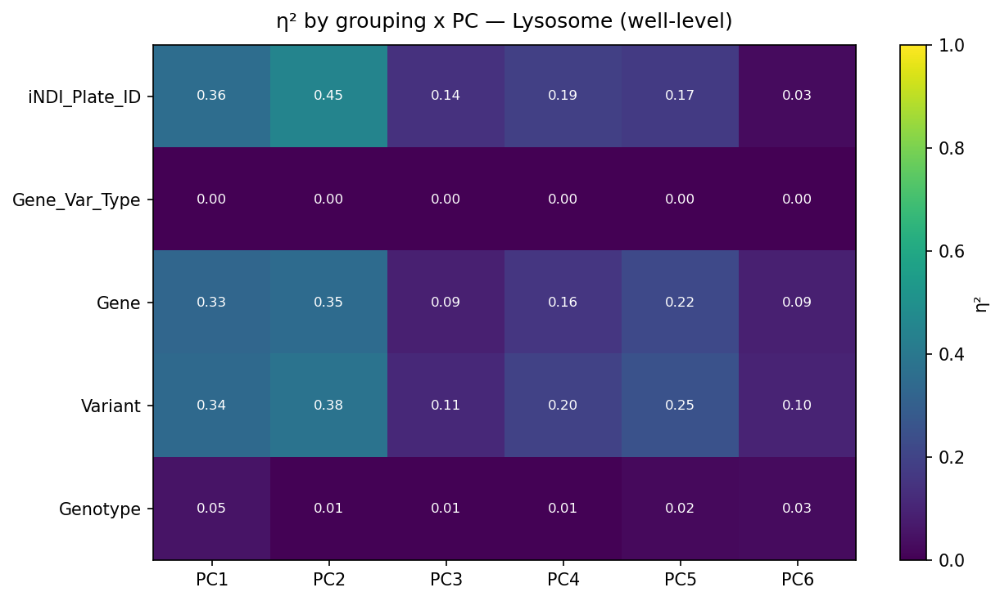

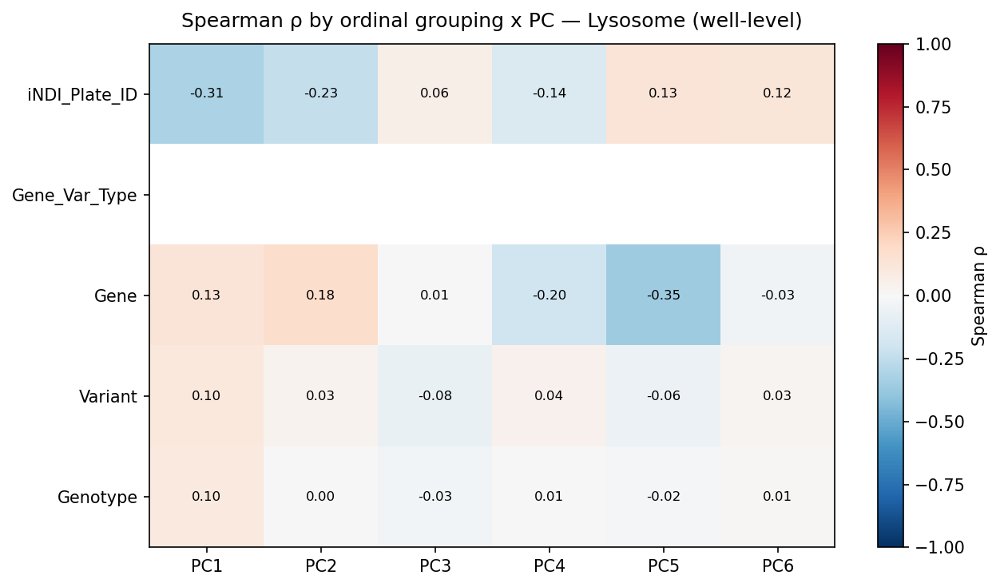

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,-0.314771,-0.234677,0.059546,-0.142031,0.126102,0.117763
Gene_Var_Type,NaN,NaN,NaN,NaN,NaN,NaN
Gene,0.130112,0.175118,0.007484,-0.199552,-0.354016,-0.033458
Variant,0.103790,0.033837,-0.077575,0.042391,-0.058369,0.027721
Genotype,0.099281,0.001449,-0.027243,0.006305,-0.017394,0.009866


In [21]:
well_level = aggregate_wells(df_manual, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_level["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Gene_Var_Type", "Gene", "Variant", "Genotype"],
            n_pcs=6, title="η² by grouping x PC — Lysosome (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Gene_Var_Type", "Gene", "Variant", "Genotype"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — Lysosome (well-level)")

[facet] 18 (gene, variant) pairs; 304 total KOLF2.1J rows (all folded into each facet)
  APOE / C112R: 42 variant + 304 parental rows


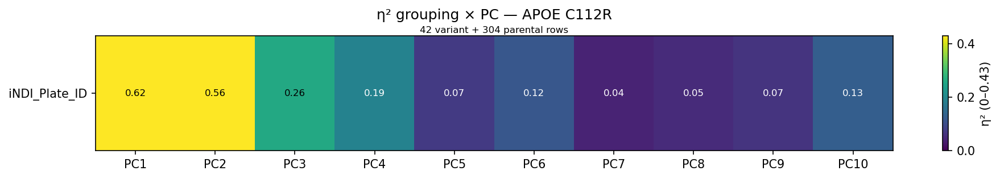

  APP / A673T: 56 variant + 304 parental rows


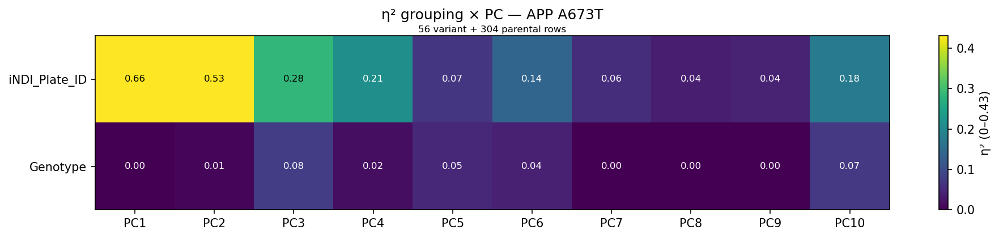

  APP / E693G: 84 variant + 304 parental rows


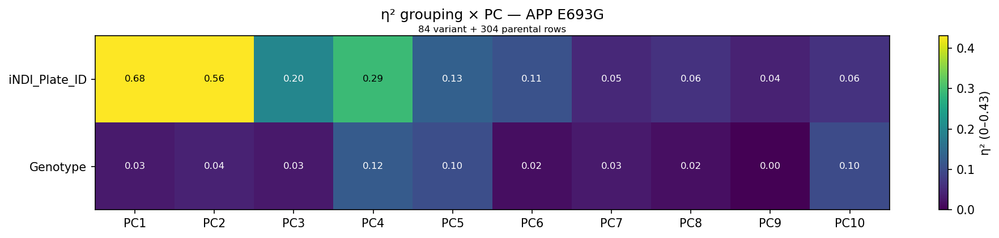

  FUS / R216C: 112 variant + 304 parental rows


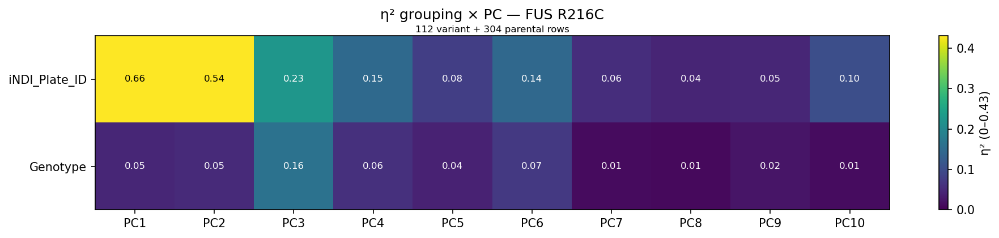

  FUS / R495X: 84 variant + 304 parental rows


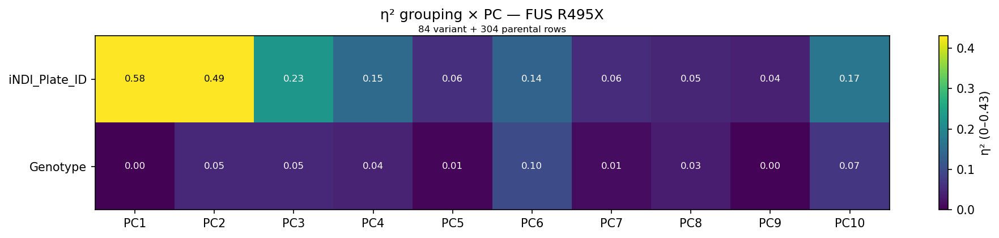

  GRN / Q125X: 126 variant + 304 parental rows


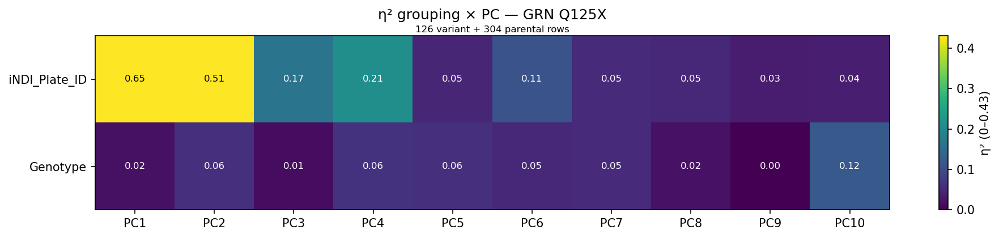

  HNRNPA1 / D262N: 125 variant + 304 parental rows


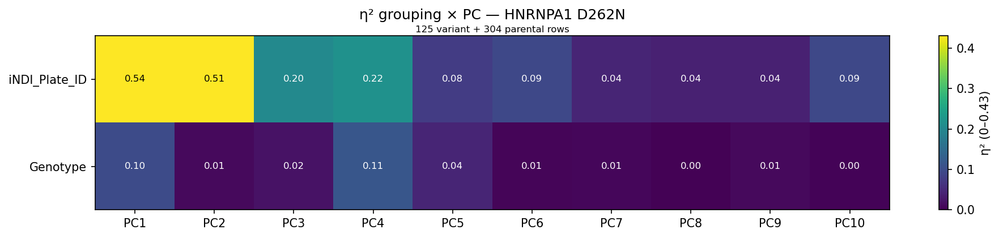

  MAPT / R406W: 112 variant + 304 parental rows


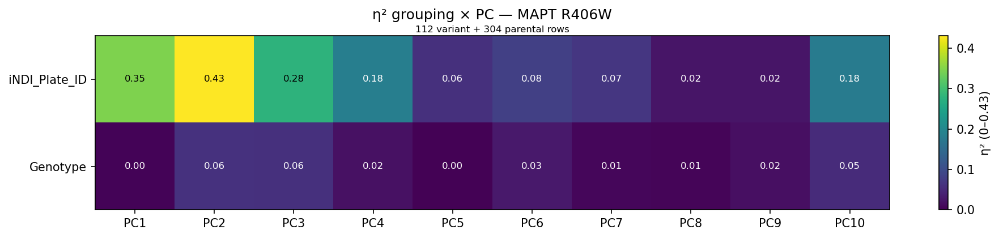

  PFN1 / C71G: 126 variant + 304 parental rows


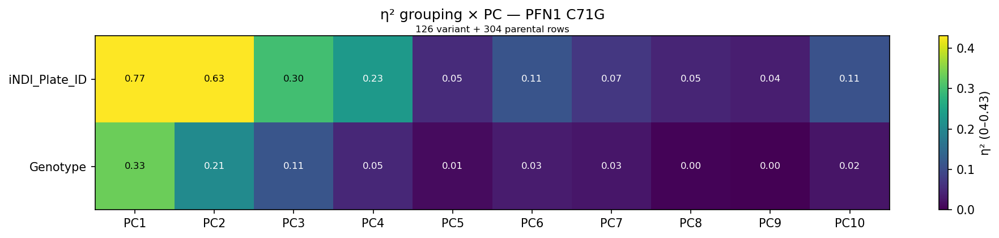

  PSEN2 / N141I: 126 variant + 304 parental rows


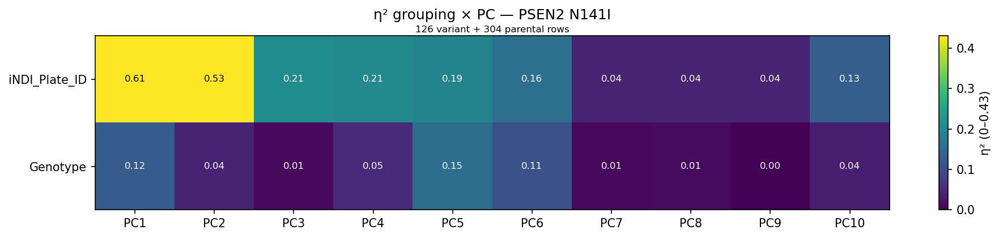

  SNCA / A53T: 126 variant + 304 parental rows


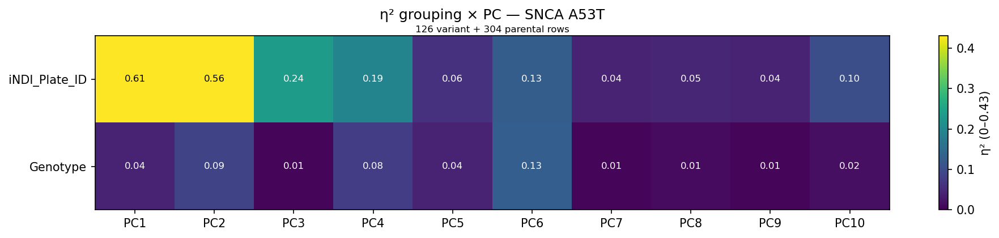

  SNCA / E46K: 98 variant + 304 parental rows


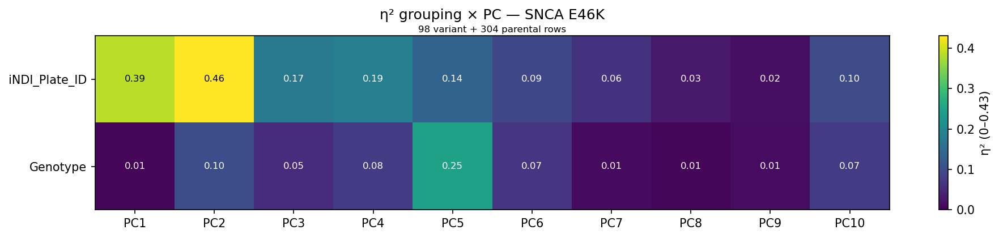

  SNCB / P123H: 126 variant + 304 parental rows


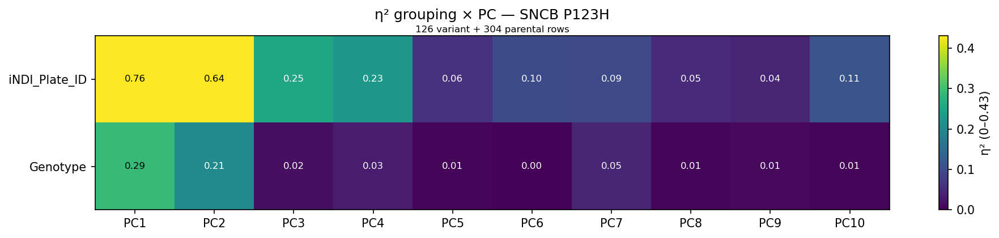

  TARDBP / M337V: 126 variant + 304 parental rows


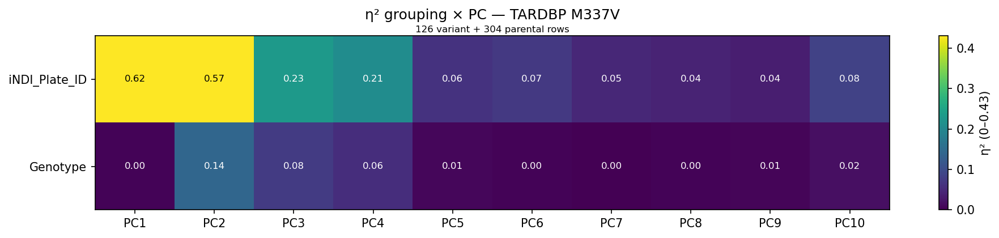

  TARDBP / Q331K: 126 variant + 304 parental rows


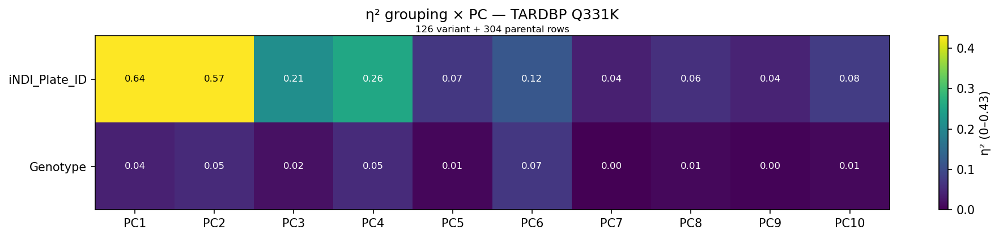

  TBK1 / E696K: 126 variant + 304 parental rows


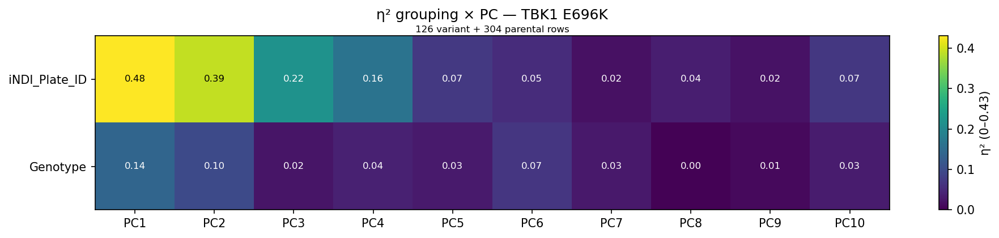

  UBQLN2 / P506T: 83 variant + 304 parental rows


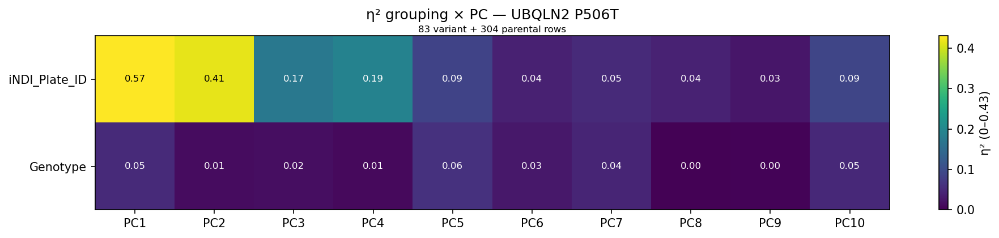

  VCP / R159H: 84 variant + 304 parental rows


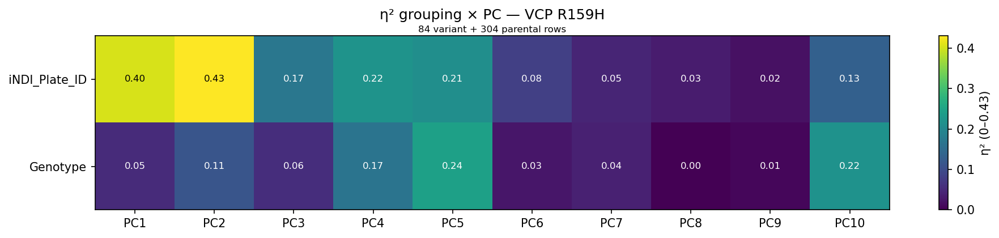

[facet] 18 (gene, variant) pairs; 304 total KOLF2.1J rows (plate-matched per facet)
  APOE / C112R: 42 variant + 42 parental rows on 1 plate(s)


/tmp/ipykernel_3620213/2003242941.py:62: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  im = ax.imshow(mat.values.astype(float), cmap="viridis",


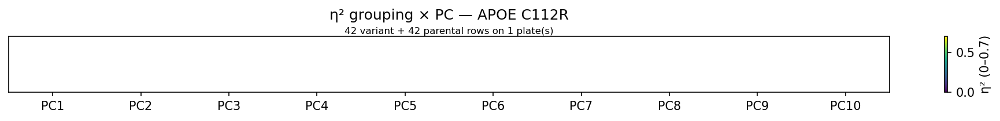

  APP / A673T: 56 variant + 53 parental rows on 1 plate(s)


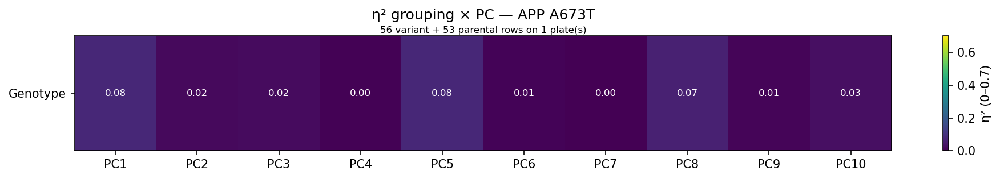

  APP / E693G: 84 variant + 42 parental rows on 1 plate(s)


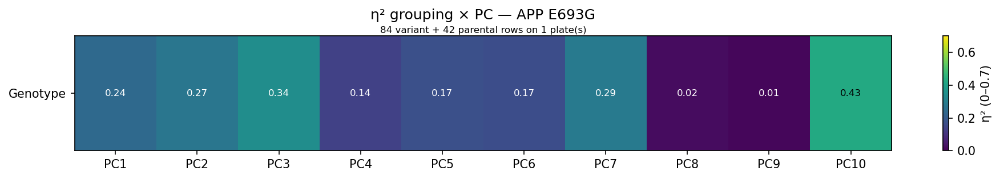

  FUS / R216C: 112 variant + 137 parental rows on 3 plate(s)


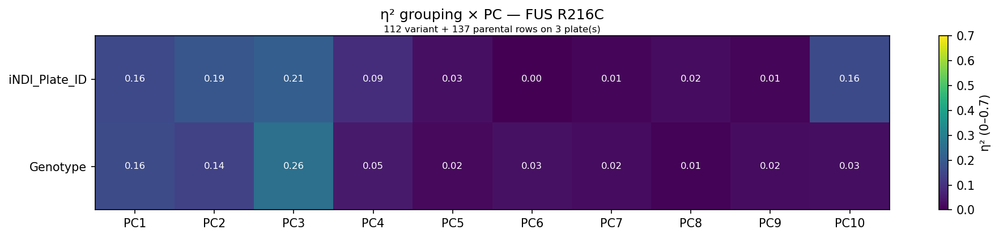

  FUS / R495X: 84 variant + 53 parental rows on 1 plate(s)


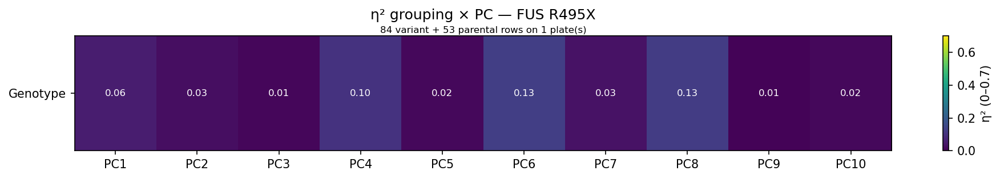

  GRN / Q125X: 126 variant + 84 parental rows on 2 plate(s)


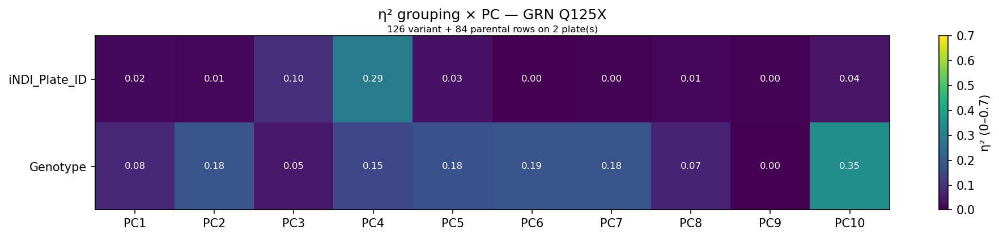

  HNRNPA1 / D262N: 125 variant + 14 parental rows on 1 plate(s)


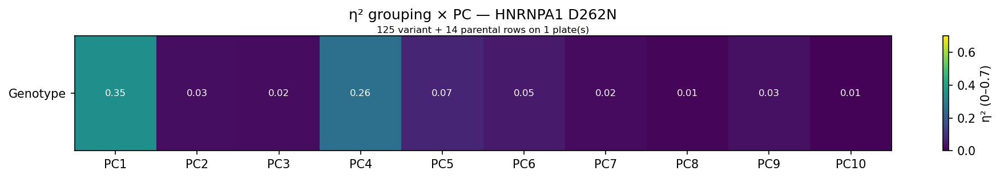

  MAPT / R406W: 112 variant + 80 parental rows on 2 plate(s)


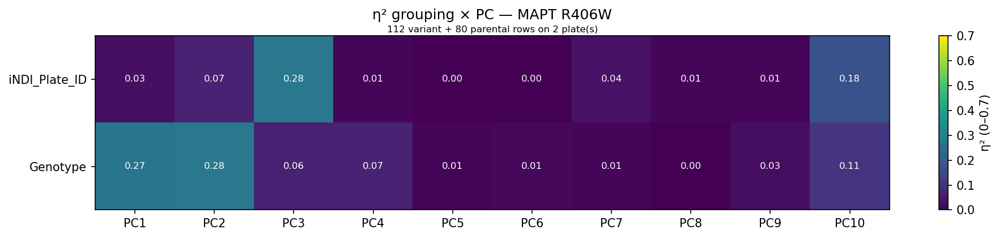

  PFN1 / C71G: 126 variant + 42 parental rows on 1 plate(s)


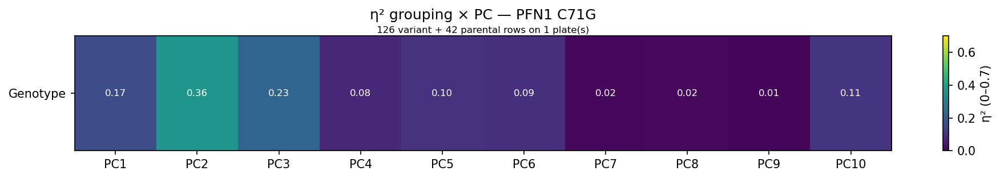

  PSEN2 / N141I: 126 variant + 14 parental rows on 1 plate(s)


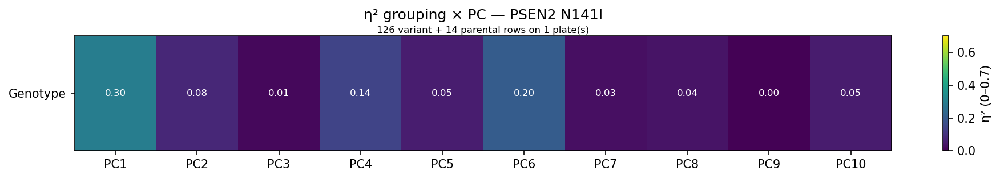

  SNCA / A53T: 126 variant + 42 parental rows on 1 plate(s)


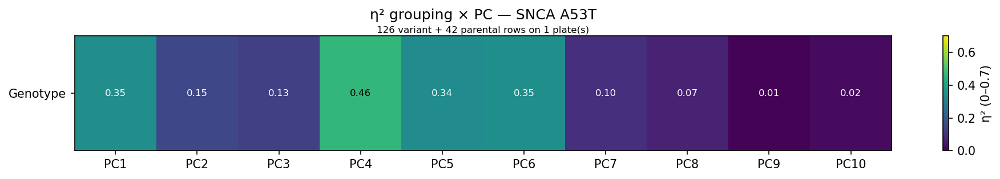

  SNCA / E46K: 98 variant + 27 parental rows on 1 plate(s)


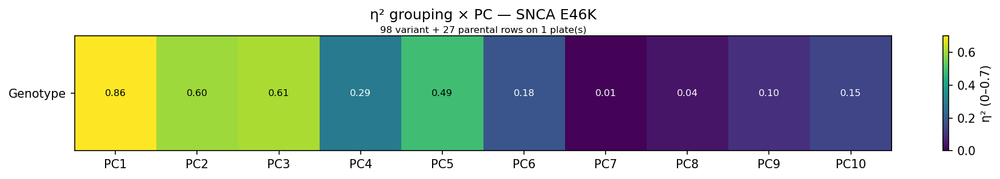

  SNCB / P123H: 126 variant + 42 parental rows on 1 plate(s)


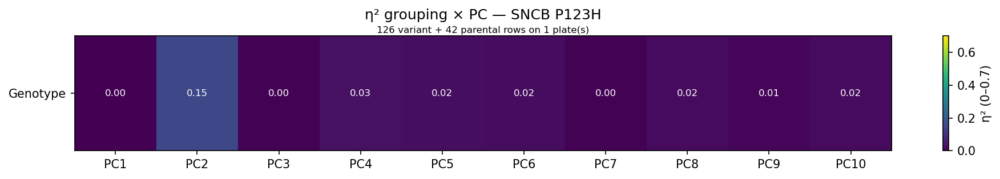

  TARDBP / M337V: 126 variant + 42 parental rows on 1 plate(s)


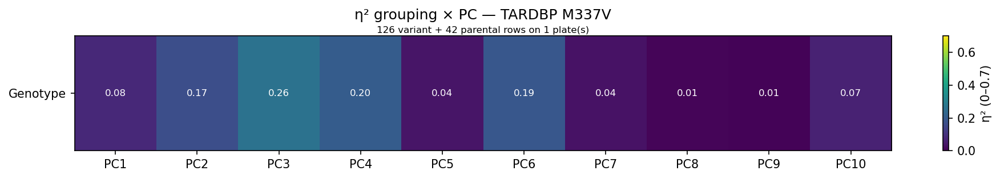

  TARDBP / Q331K: 126 variant + 126 parental rows on 3 plate(s)


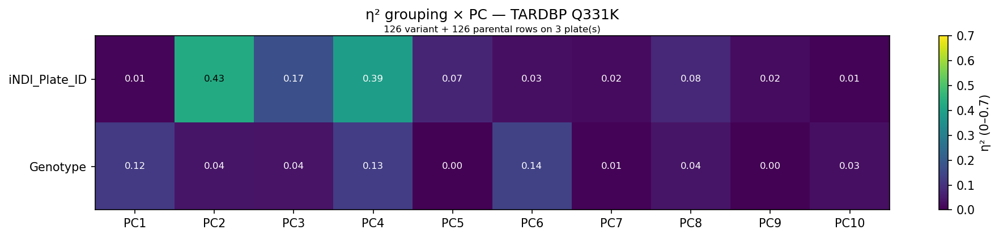

  TBK1 / E696K: 126 variant + 84 parental rows on 2 plate(s)


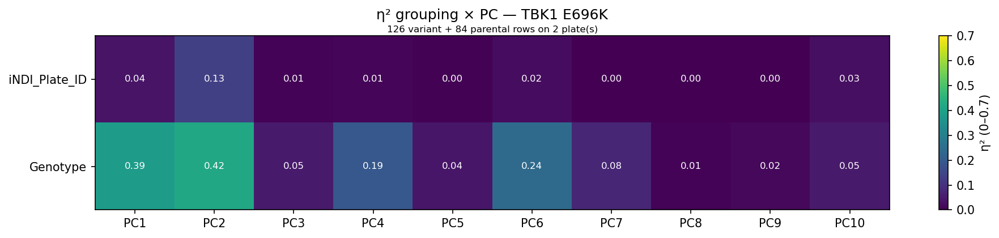

  UBQLN2 / P506T: 83 variant + 42 parental rows on 1 plate(s)


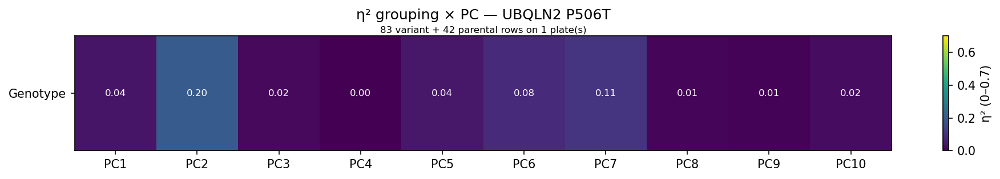

  VCP / R159H: 84 variant + 27 parental rows on 1 plate(s)


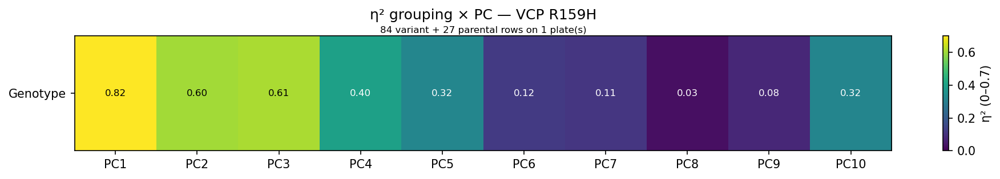

In [22]:
GROUP_COLS = ["Source", "iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Variant", "Genotype"]

mats = facet_by_gene_variant(well_level, GROUP_COLS, n_pcs=10, vmax=0.43, plate_match=False)
mats = facet_by_gene_variant(well_level, GROUP_COLS, n_pcs=10, vmax=0.7, plate_match=True)

# Parental-only analysis

In [45]:
# filter for parentals
parental        = df[df["Gene_Var_Type"] == "KOLF2.1J"]
parental_auto   = df[(df["Gene_Var_Type"] == "KOLF2.1J") & (df["Source"] == "automated")]
parental_manual = df[(df["Gene"] == "KOLF2.1J") & (df["Source"] == "manual")]

print(parental.shape)
print(parental_auto.shape)
print(parental_manual.shape)

(186651, 116)
(186651, 116)
(53613, 116)


## ROI level analysis
### Feature assessment and PCA loadings


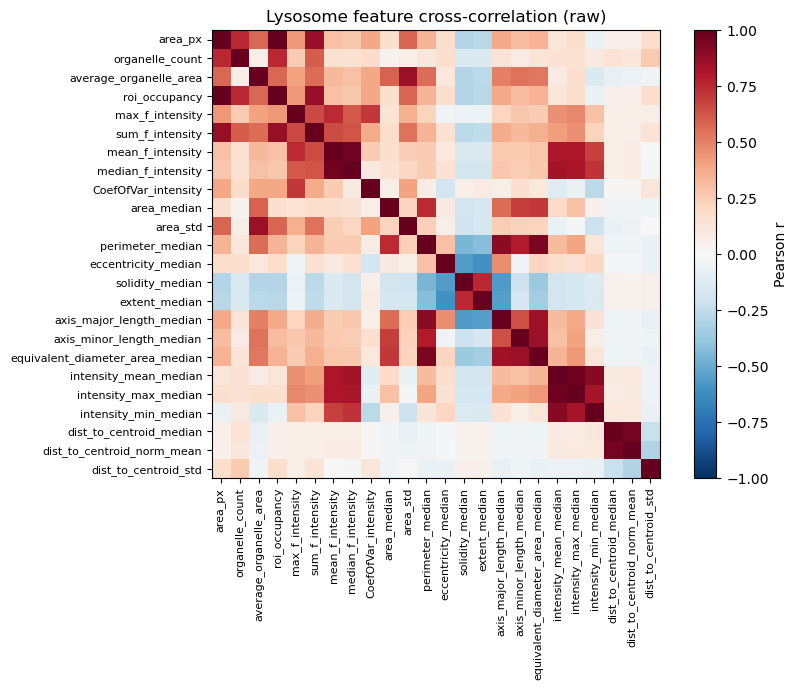

Highly correlated pairs (|r| > 0.9):
  +1.000  area_px                roi_occupancy
  +0.971  intensity_mean_median  intensity_max_median
  +0.968  mean_f_intensity       median_f_intensity
  +0.956  dist_to_centroid_median dist_to_centroid_norm_mean
  +0.942  perimeter_median       equivalent_diameter_area_median
  +0.907  intensity_mean_median  intensity_min_median
  +0.905  perimeter_median       axis_major_length_median
[full] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full] dropped 0 rows with NaN/inf; 186651 remain
[full] EVR: [0.317 0.191 0.148 0.111 0.079 0.055 0.042 0.022 0.022 0.011 0.   ]
[full] cumulative: [0.317 0.509 0.657 0.768 0.848 0.903 0.945 0.967 0.989 1.    1.   ]


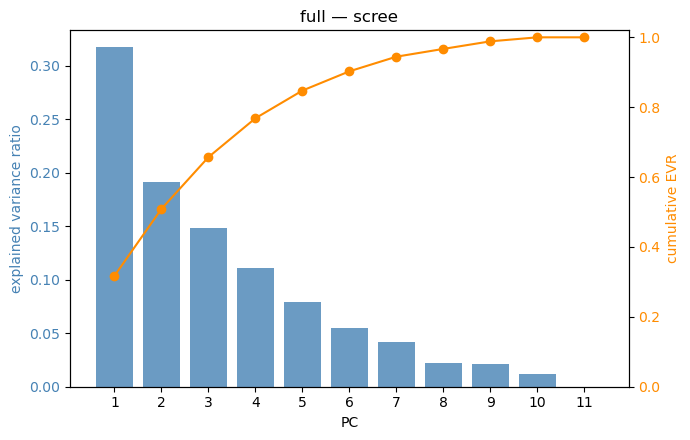

                              PC1    PC2    PC3    PC4    PC5    PC6    PC7  \
area_px                     0.473 -0.239 -0.113  0.107 -0.014 -0.207 -0.061   
organelle_count             0.390 -0.252 -0.136  0.119 -0.412 -0.079  0.095   
roi_occupancy               0.473 -0.239 -0.113  0.107 -0.014 -0.207 -0.061   
mean_f_intensity            0.269  0.004  0.606 -0.242  0.104  0.054  0.077   
CoefOfVar_intensity         0.163 -0.381  0.053  0.027  0.760  0.273  0.227   
eccentricity_median         0.240  0.453 -0.159  0.008 -0.077  0.127  0.813   
solidity_median            -0.305 -0.434  0.157  0.016 -0.208 -0.106  0.416   
extent_median              -0.303 -0.451  0.163  0.017 -0.180 -0.131  0.267   
intensity_max_median        0.222  0.134  0.616 -0.241 -0.213 -0.052 -0.061   
dist_to_centroid_norm_mean  0.034 -0.011  0.256  0.719 -0.200  0.593 -0.093   
dist_to_centroid_std        0.087 -0.250 -0.254 -0.573 -0.273  0.657 -0.085   

                              PC8    PC9   PC10   P

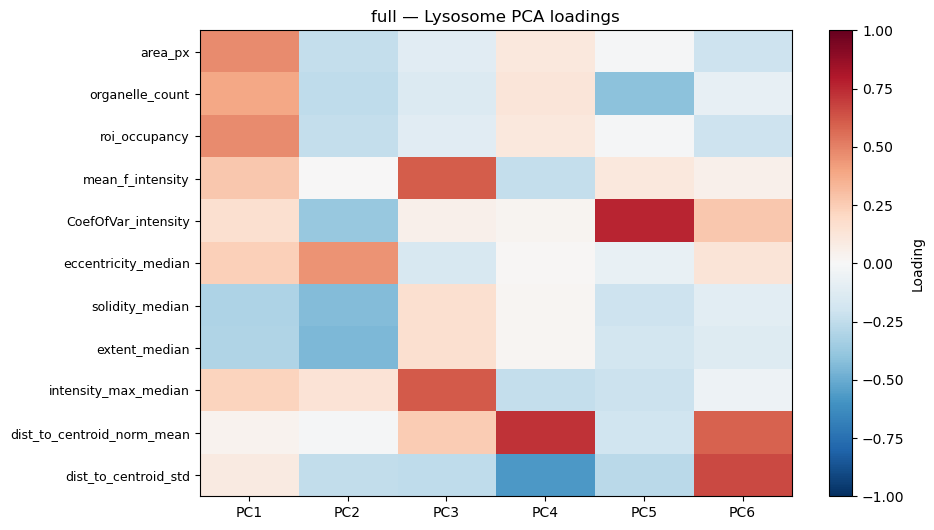

In [46]:
feature_correlation(parental)
parental, pca, FEATURES = fit_pca(parental, label="full")

### PCA plots
#### All parentals


All 13 iNDI_Plate_ID values have a color.


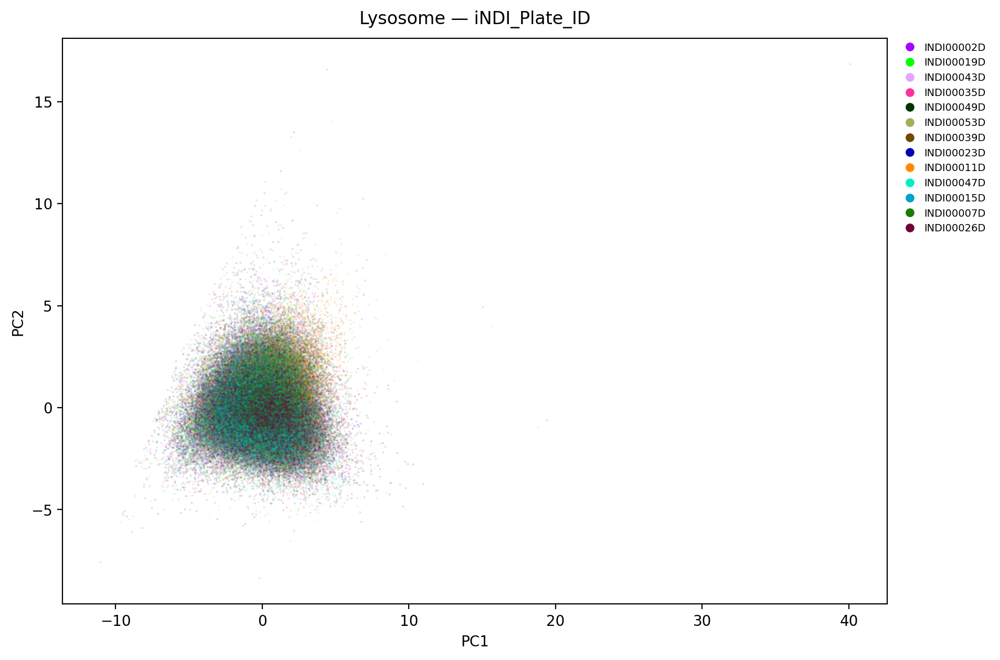

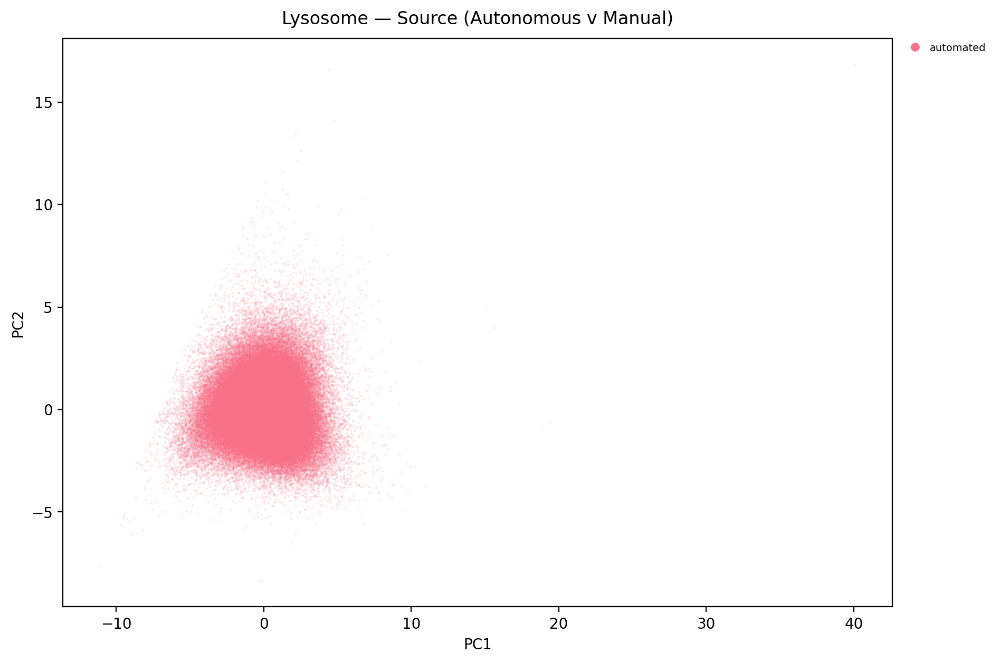

All 4 Batch values have a color.


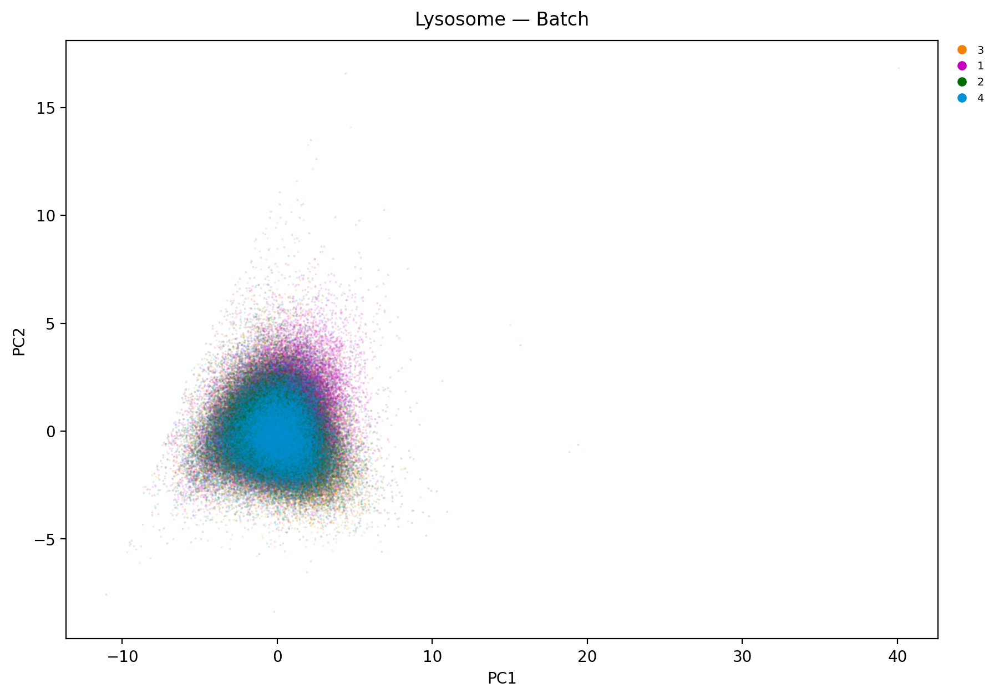

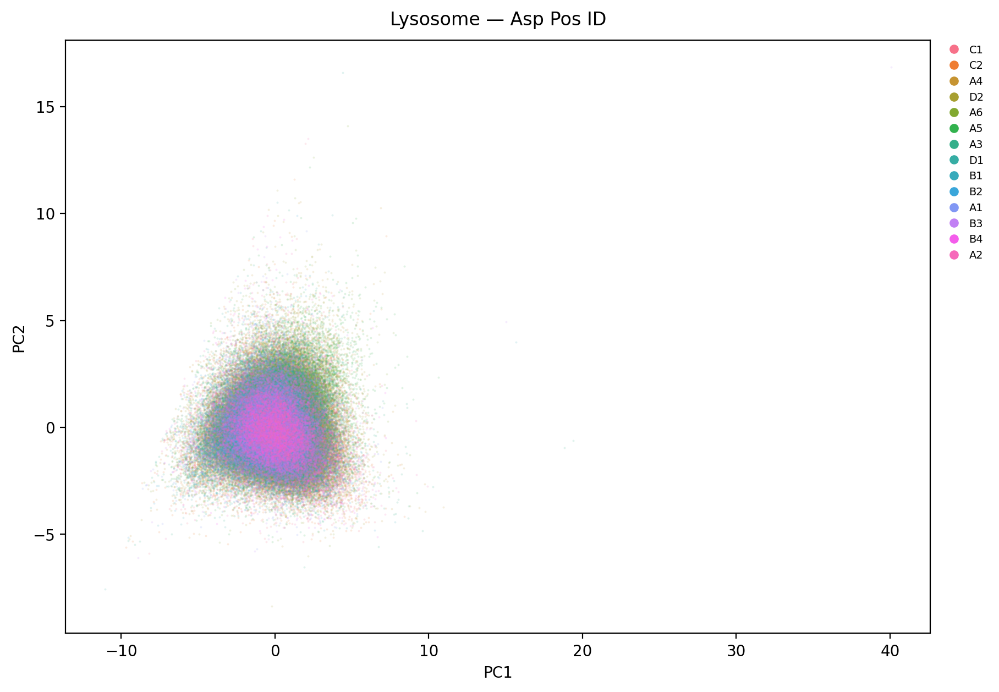

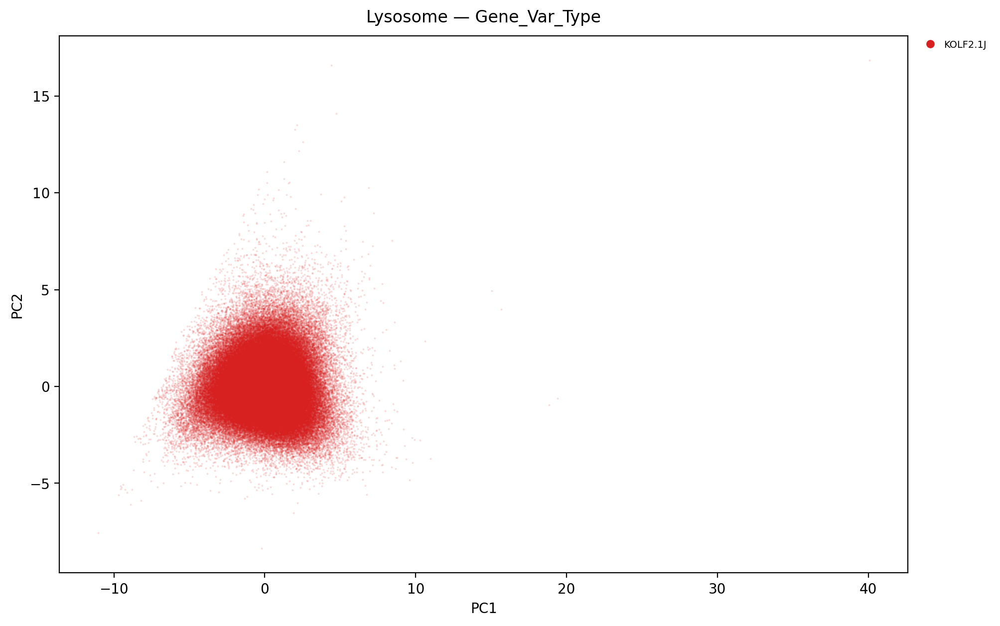

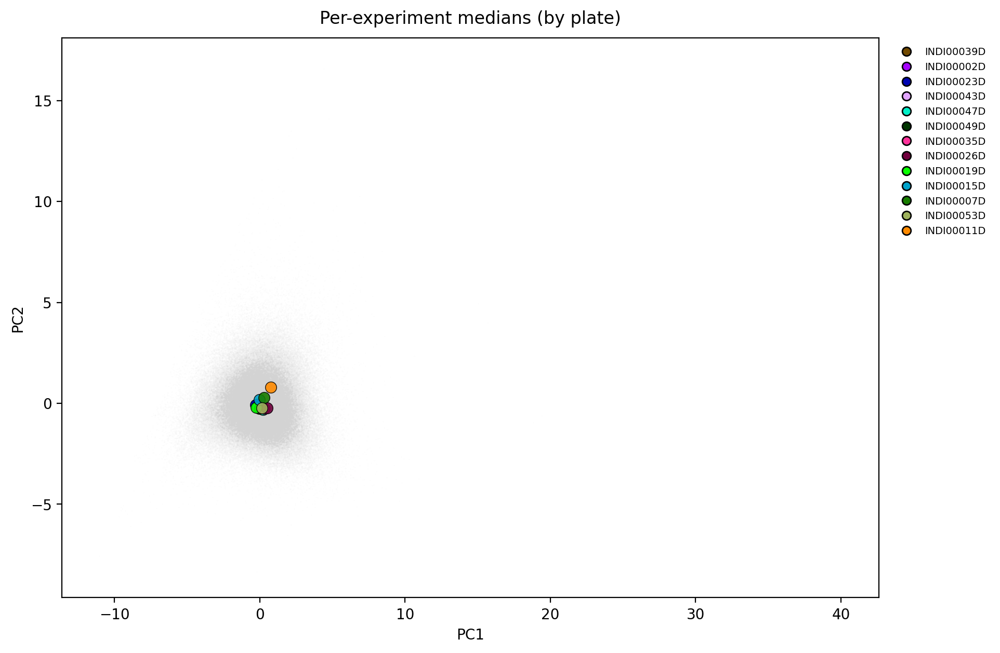

Std of per-experiment centroids (batch magnitude):
PC1    0.310
PC2    0.315
PC3    0.457
dtype: float64


In [47]:
plate_pal = make_palette(parental["iNDI_Plate_ID"])
check_palette_coverage(parental, "iNDI_Plate_ID", plate_pal)
pca_scatter(parental, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Lysosome — iNDI_Plate_ID")

pca_scatter(parental, "Source", figsize=(12, 7),title="Lysosome — Source (Autonomous v Manual)")

batch_palette = make_palette(parental["Batch"])
check_palette_coverage(parental, "Batch", batch_palette)
pca_scatter(parental, "Batch", palette=batch_palette, figsize=(12, 7),title="Lysosome — Batch")

pca_scatter(parental, "Asp PosID", figsize=(12, 7),title="Lysosome — Asp Pos ID")

pca_scatter(parental, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Lysosome — Gene_Var_Type")

centroid_overlay(parental, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = parental.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

#### Automated parentals

All 13 iNDI_Plate_ID values have a color.


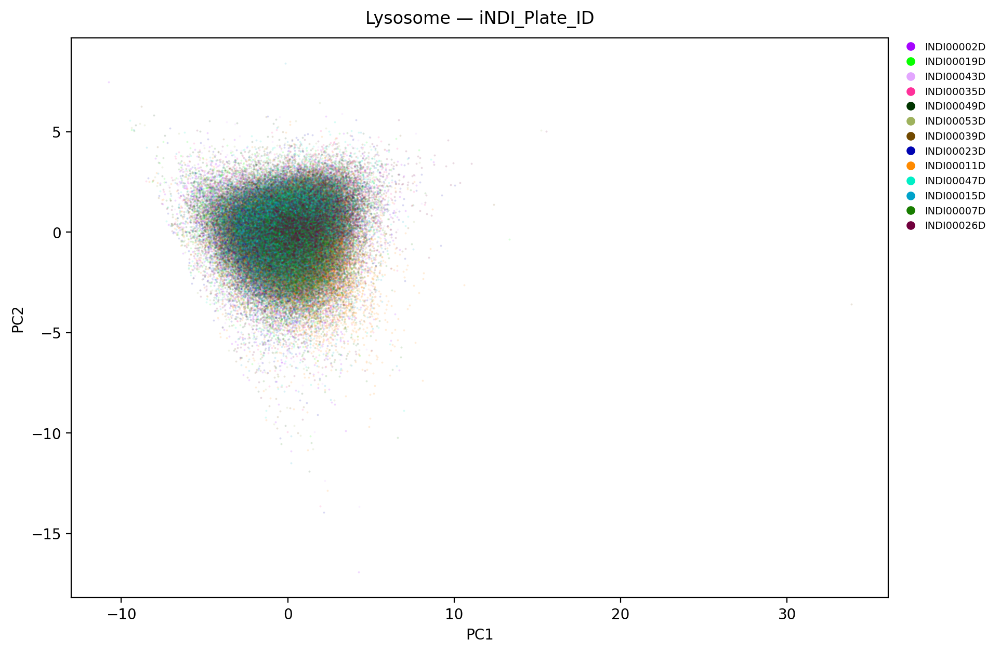

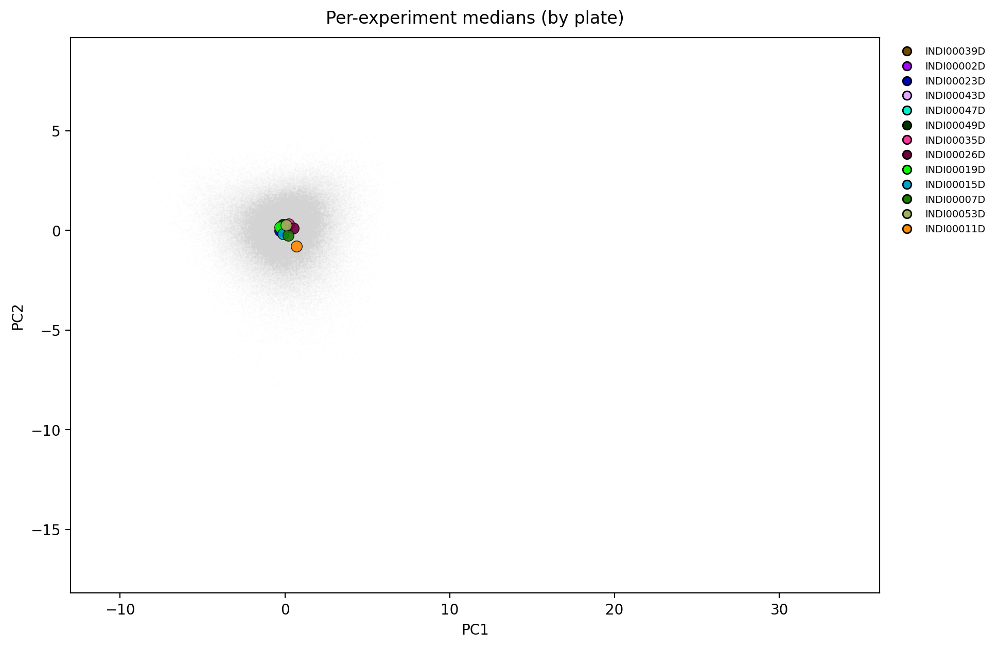

Std of per-experiment centroids (batch magnitude):
PC1    0.305
PC2    0.310
PC3    0.407
dtype: float64
All 4 Batch values have a color.


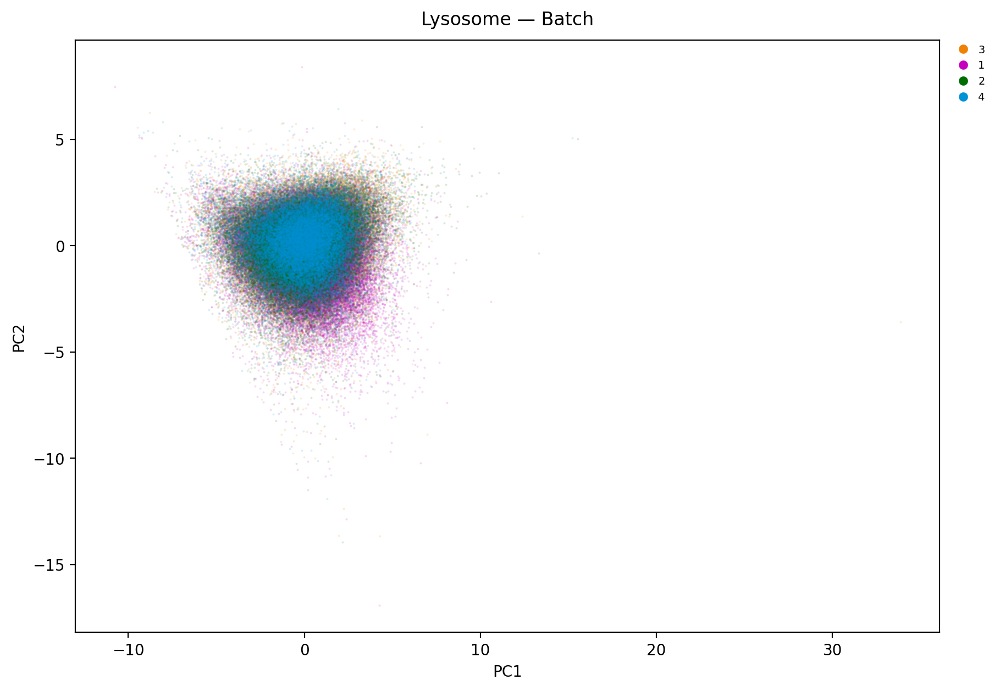

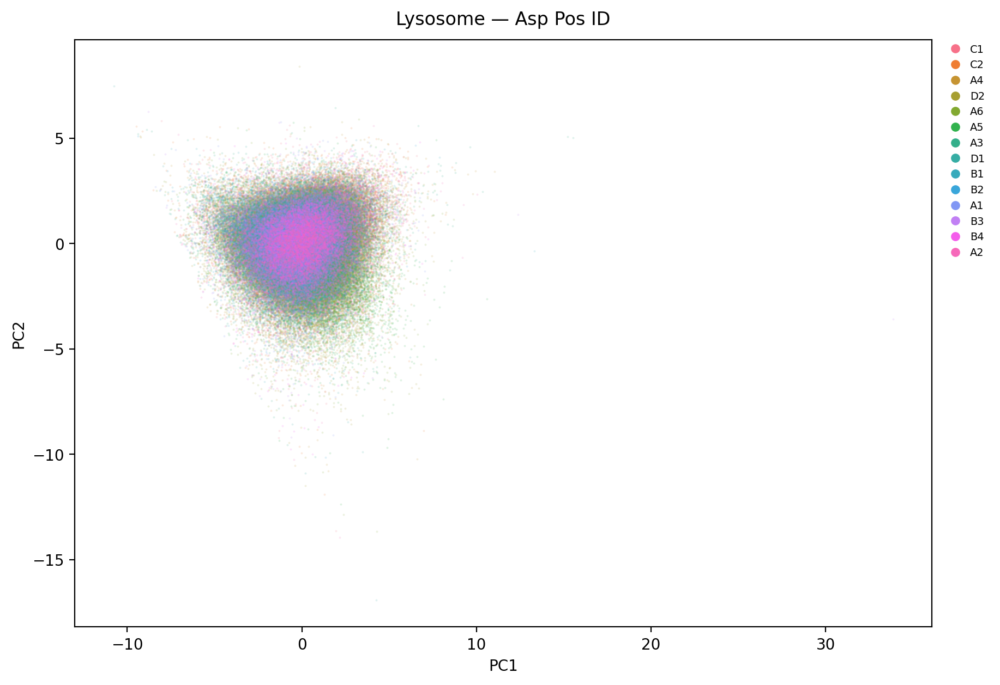

<Axes: title={'center': 'Lysosome — Asp Pos ID'}, xlabel='PC1', ylabel='PC2'>

In [48]:
plate_pal = make_palette(parental_auto["iNDI_Plate_ID"])
check_palette_coverage(parental_auto, "iNDI_Plate_ID", plate_pal)
pca_scatter(parental_auto, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Lysosome — iNDI_Plate_ID")
centroid_overlay(parental_auto, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = parental_auto.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

batch_palette = make_palette(parental_auto["Batch"])
check_palette_coverage(parental_auto, "Batch", batch_palette)
pca_scatter(parental_auto, "Batch", palette=batch_palette, figsize=(12, 7),title="Lysosome — Batch")

pca_scatter(parental_auto, "Asp PosID", figsize=(12, 7),title="Lysosome — Asp Pos ID")

#### Manual parentals

All 8 iNDI_Plate_ID values have a color.


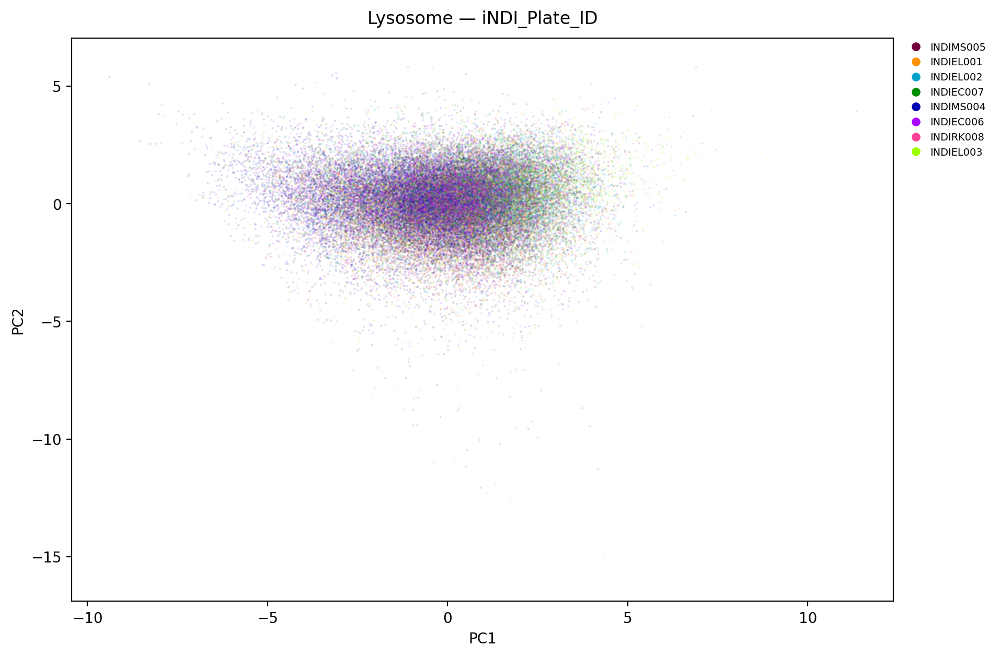

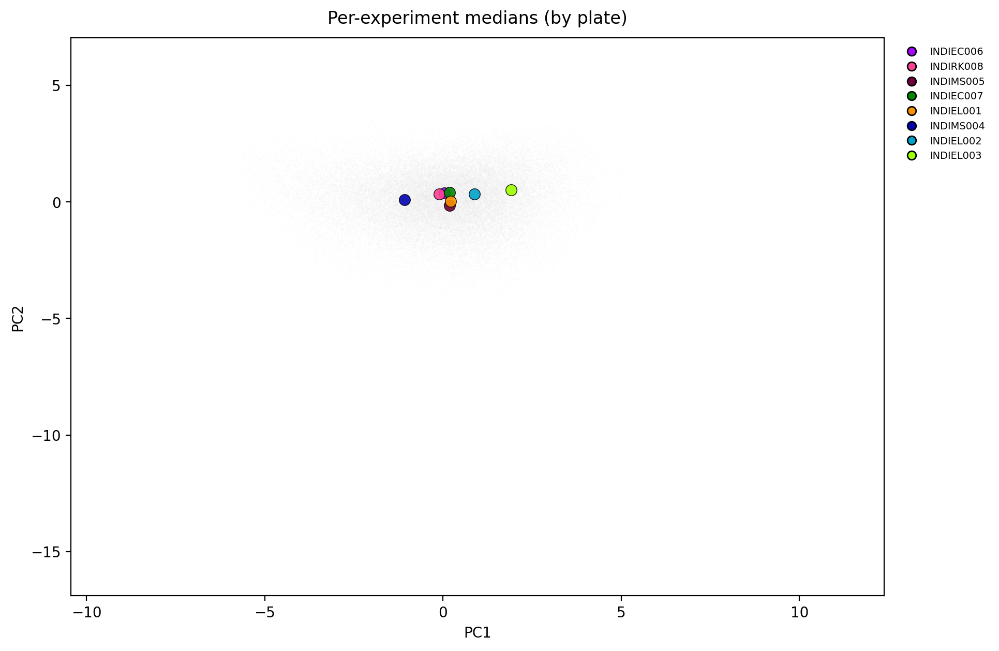

Std of per-experiment centroids (batch magnitude):
PC1    0.853
PC2    0.226
PC3    0.655
dtype: float64
All 1 Batch values have a color.


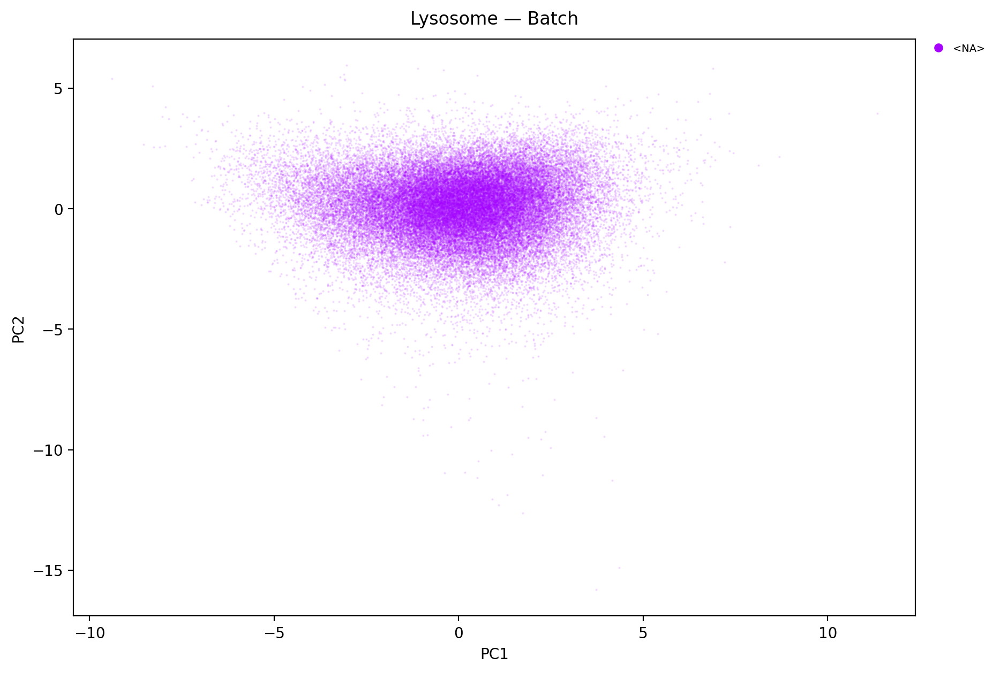

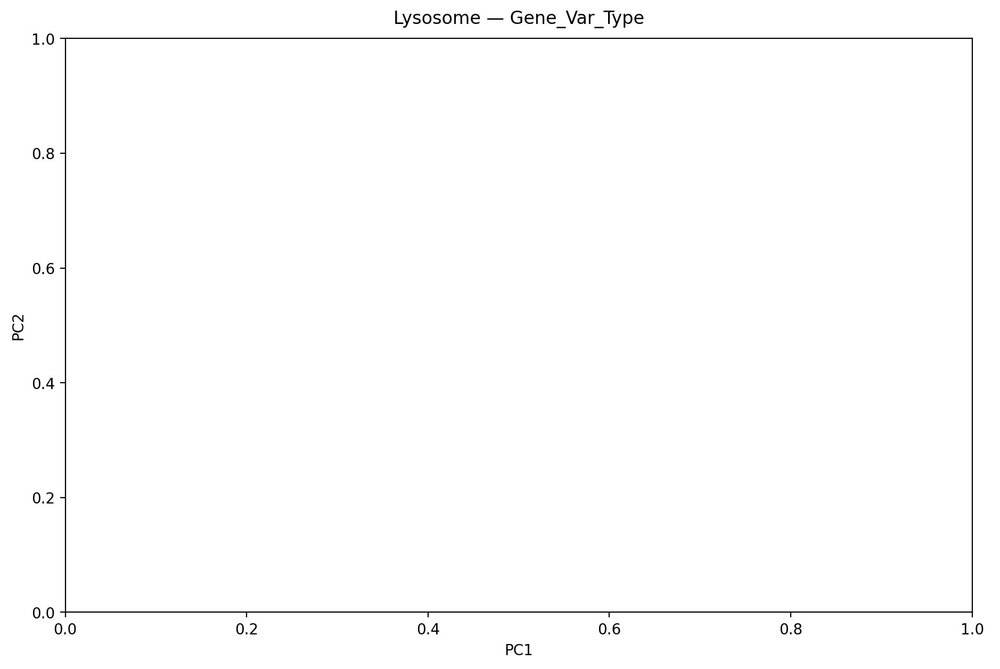

<Axes: title={'center': 'Lysosome — Gene_Var_Type'}, xlabel='PC1', ylabel='PC2'>

In [49]:
plate_pal = make_palette(parental_manual["iNDI_Plate_ID"])
check_palette_coverage(parental_manual, "iNDI_Plate_ID", plate_pal)
pca_scatter(parental_manual, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Lysosome — iNDI_Plate_ID")
centroid_overlay(parental_manual, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = parental_manual.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

batch_palette = make_palette(parental_manual["Batch"])
check_palette_coverage(parental_manual, "Batch", batch_palette)
pca_scatter(parental_manual, "Batch", palette=batch_palette, figsize=(12, 7),title="Lysosome — Batch")

pca_scatter(parental_manual, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Lysosome — Gene_Var_Type")

## Well-level aggregation
### PCA plots

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 37126 rows (12974 images)
[full] well-level: 1139 rows
[full well] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full well] dropped 0 rows with NaN/inf; 1139 remain
[full well] EVR: [0.438 0.179 0.126 0.116 0.088 0.024 0.017 0.007 0.003 0.001 0.   ]
[full well] cumulative: [0.438 0.617 0.743 0.859 0.947 0.971 0.989 0.996 0.999 1.    1.   ]


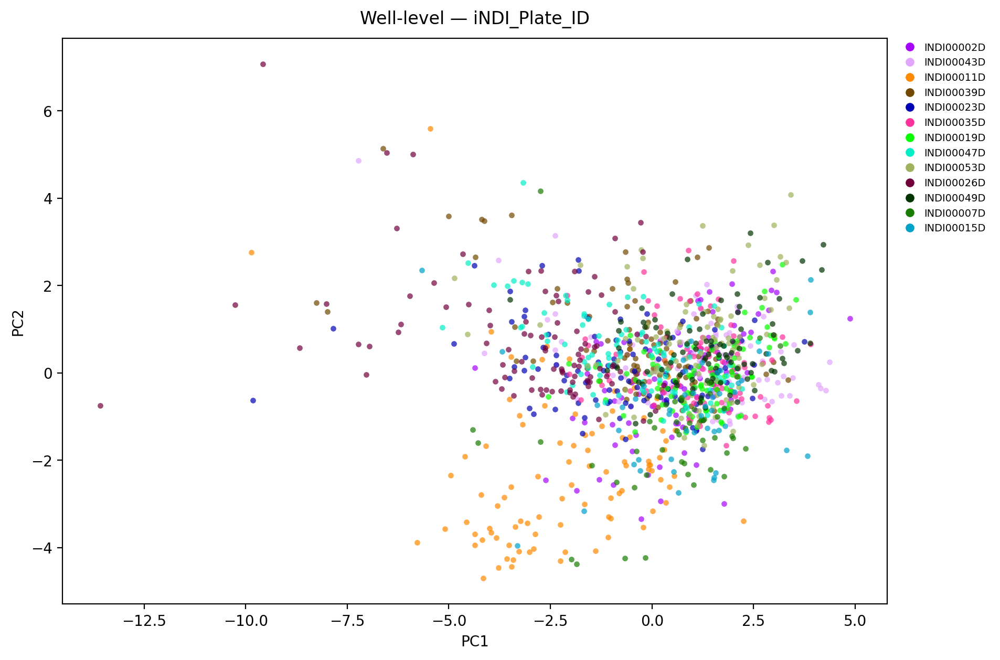

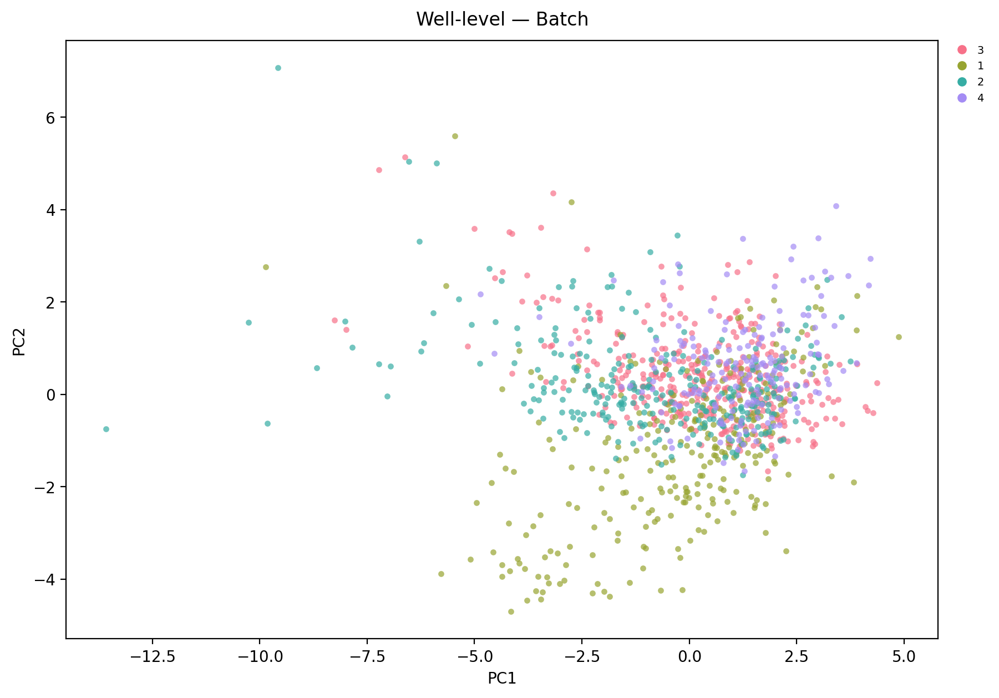

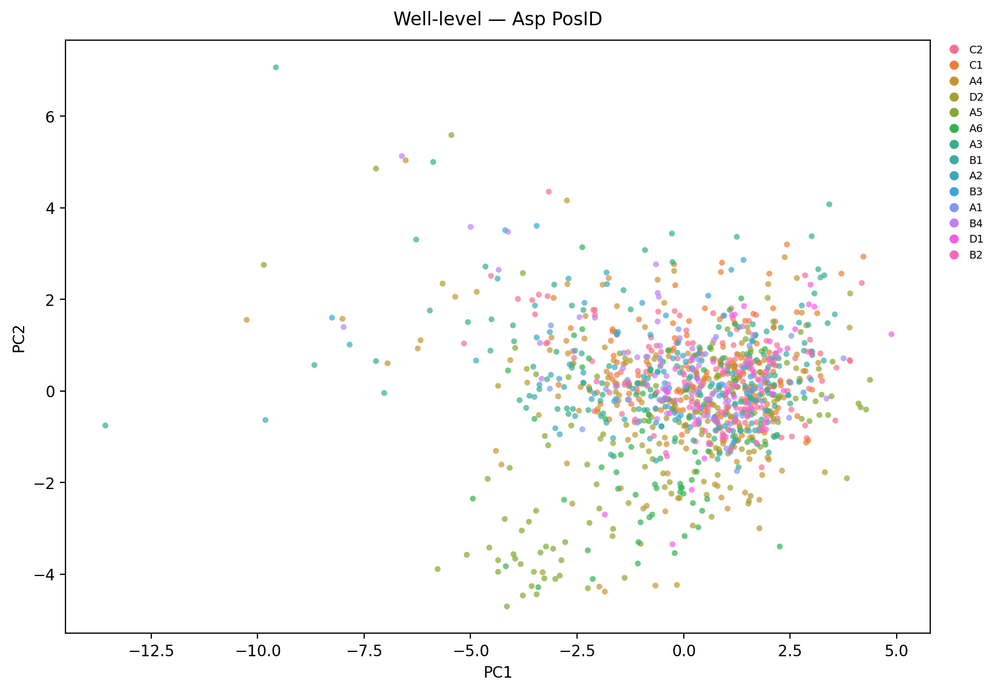

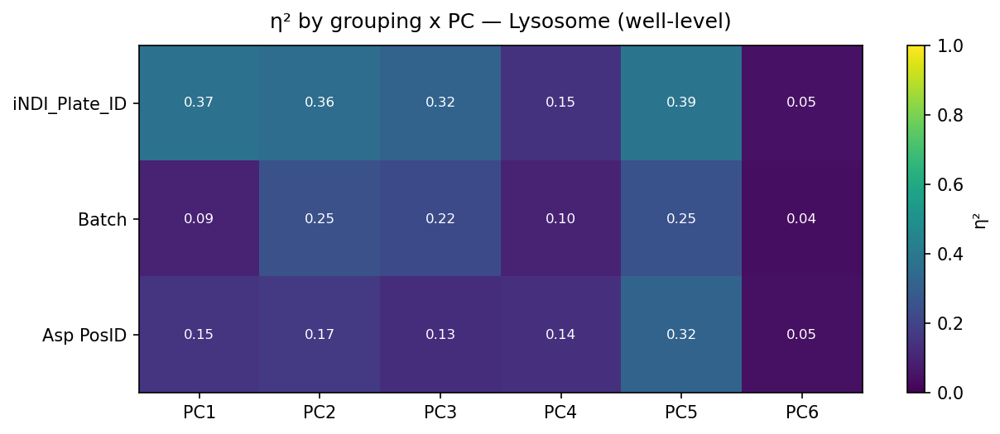

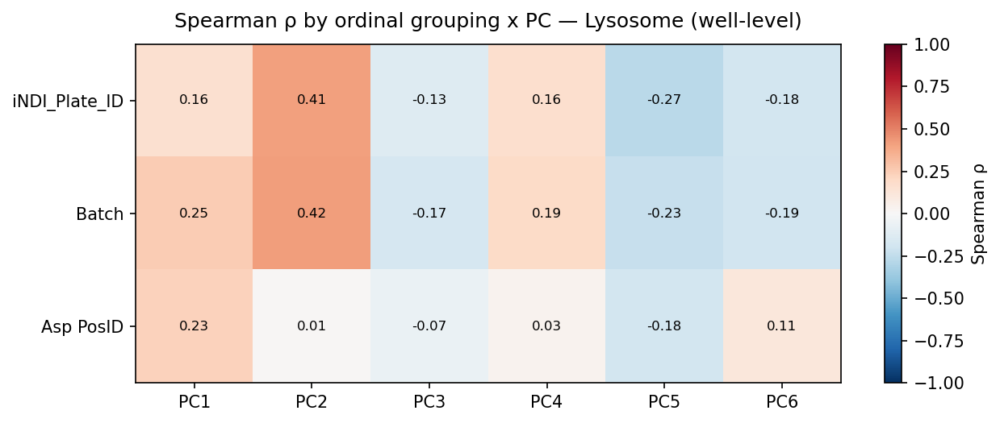

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.159581,0.412687,-0.125131,0.164479,-0.265768,-0.183945
Batch,0.251882,0.421325,-0.169044,0.193306,-0.232936,-0.194793
Asp PosID,0.227068,0.008632,-0.067342,0.031833,-0.180067,0.112093


In [50]:
well_level = aggregate_wells(parental, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"],
            n_pcs=6, title="η² by grouping x PC — Lysosome (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — Lysosome (well-level)")

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 37126 rows (12974 images)
[full] well-level: 1139 rows
[full well] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full well] dropped 0 rows with NaN/inf; 1139 remain
[full well] EVR: [0.438 0.179 0.126 0.116 0.088 0.024 0.017 0.007 0.003 0.001 0.   ]
[full well] cumulative: [0.438 0.617 0.743 0.859 0.947 0.971 0.989 0.996 0.999 1.    1.   ]


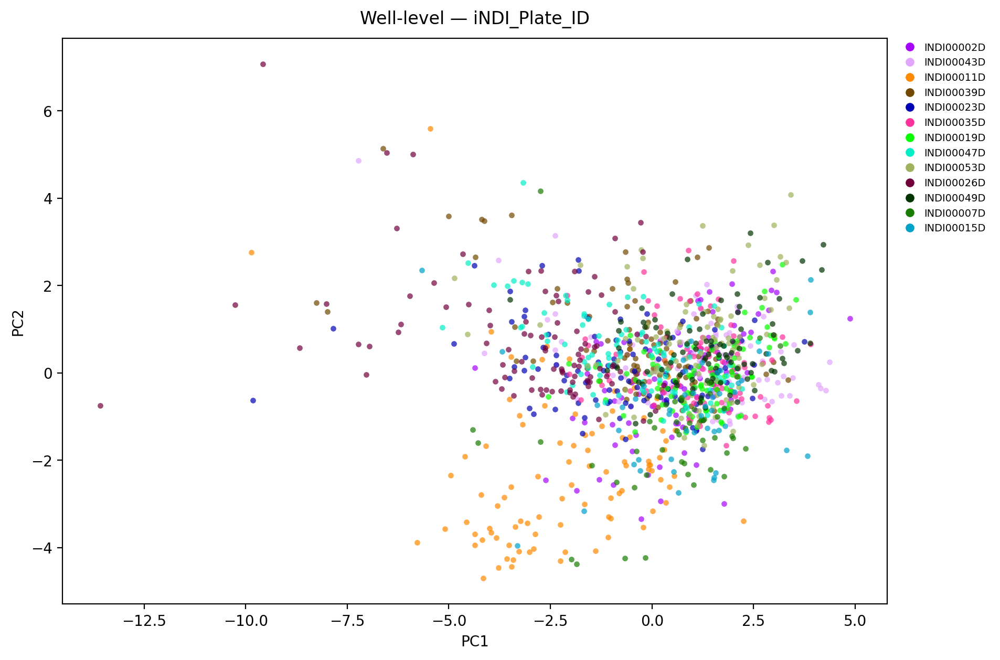

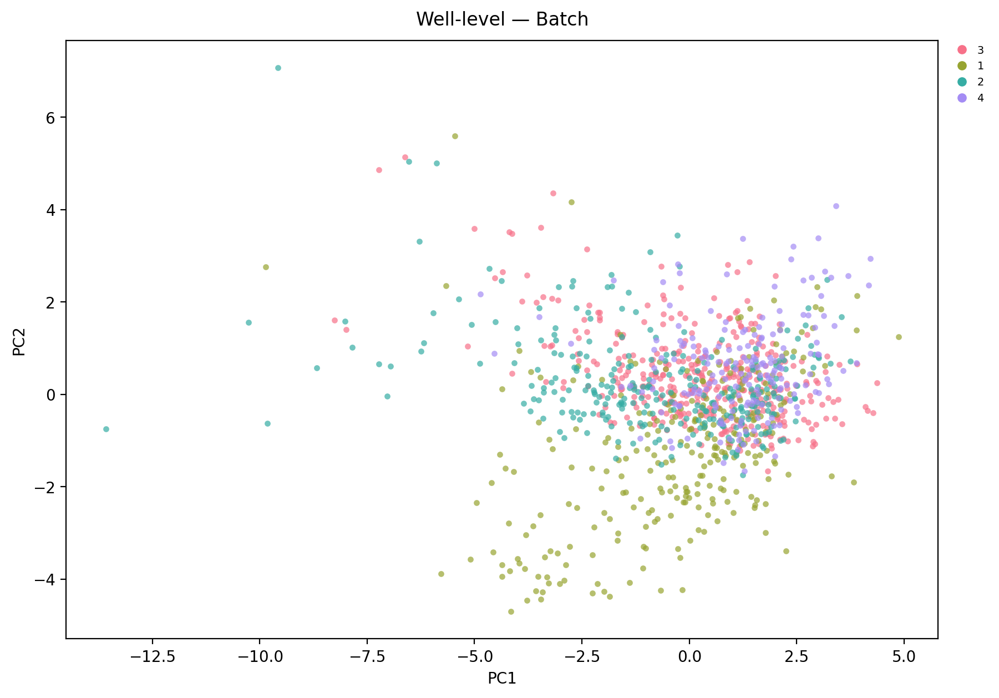

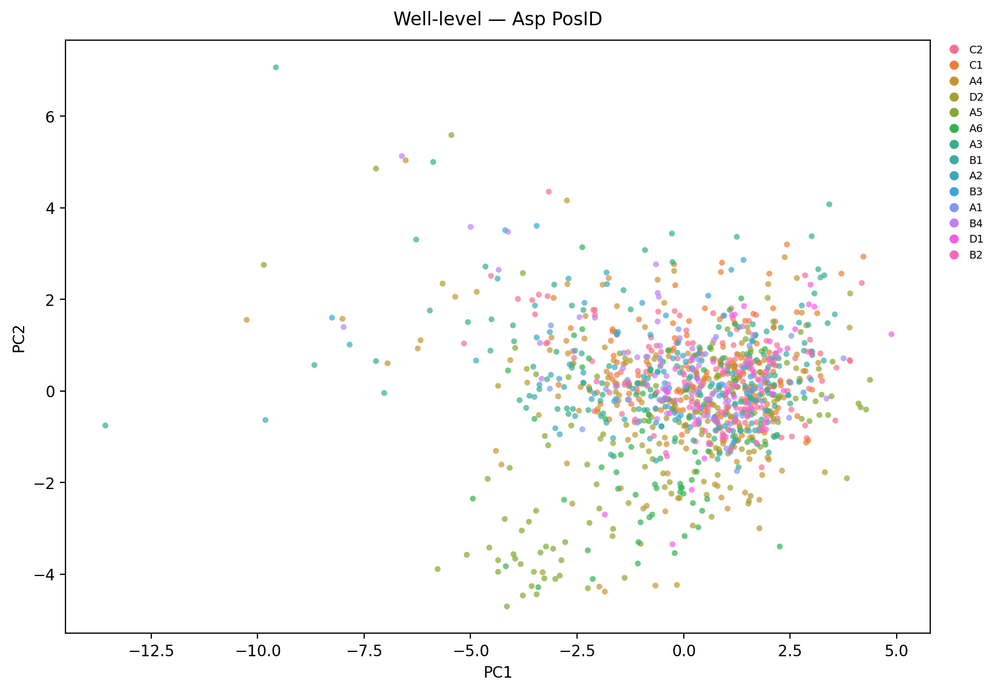

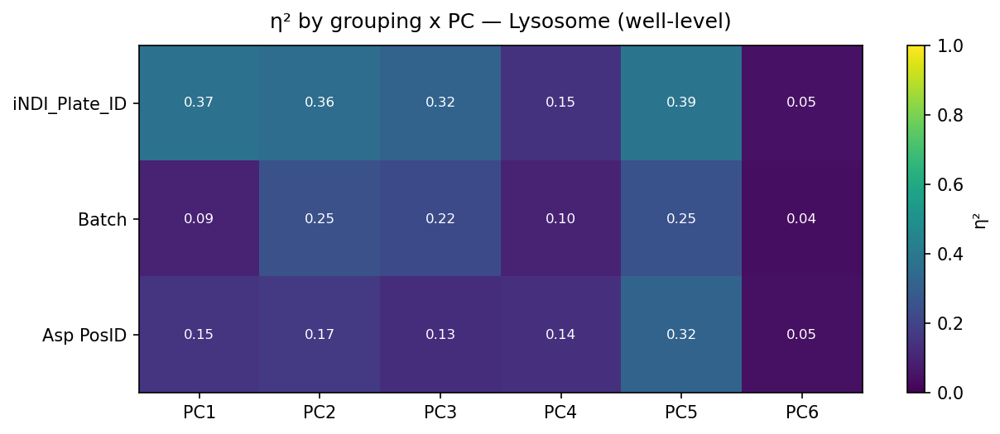

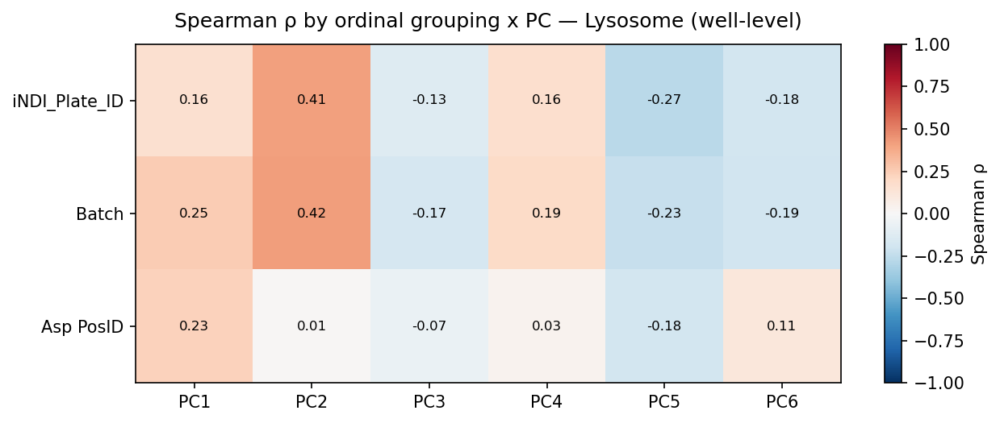

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.159581,0.412687,-0.125131,0.164479,-0.265768,-0.183945
Batch,0.251882,0.421325,-0.169044,0.193306,-0.232936,-0.194793
Asp PosID,0.227068,0.008632,-0.067342,0.031833,-0.180067,0.112093


In [51]:
well_level = aggregate_wells(parental_auto, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"],
            n_pcs=6, title="η² by grouping x PC — Lysosome (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — Lysosome (well-level)")

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 10166 rows (3738 images)
[full] well-level: 304 rows
[full well] using FEATURES: ['area_px', 'organelle_count', 'roi_occupancy', 'mean_f_intensity', 'CoefOfVar_intensity', 'eccentricity_median', 'solidity_median', 'extent_median', 'intensity_max_median', 'dist_to_centroid_norm_mean', 'dist_to_centroid_std']
[full well] dropped 0 rows with NaN/inf; 304 remain
[full well] EVR: [0.4   0.263 0.143 0.096 0.052 0.02  0.013 0.009 0.004 0.001 0.   ]
[full well] cumulative: [0.4   0.663 0.806 0.902 0.954 0.974 0.987 0.996 0.999 1.    1.   ]


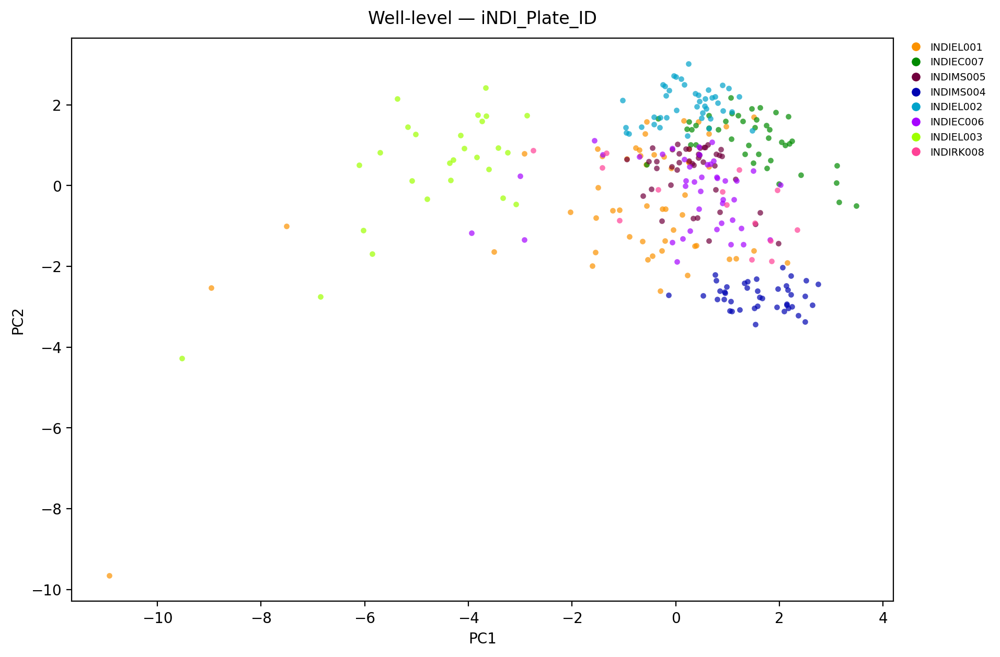

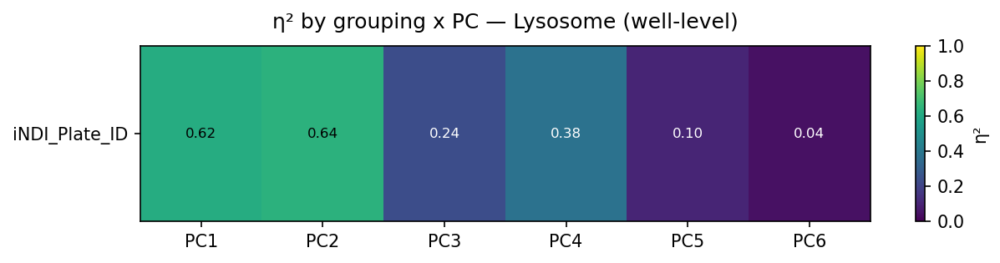

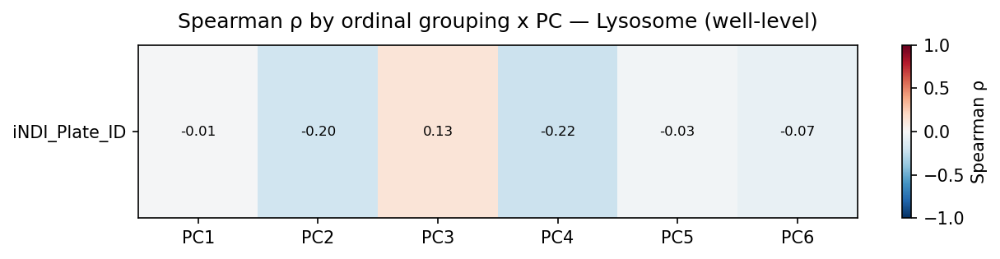

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,-0.007885,-0.195694,0.126155,-0.215806,-0.028118,-0.072254


In [52]:
well_level = aggregate_wells(parental_manual, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID"],
            n_pcs=6, title="η² by grouping x PC — Lysosome (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — Lysosome (well-level)")

In [53]:
build_pptx("/data/kelpschdj/iNDI/Production/notebooks/analysis_uoe5/uoe5_lysosome_analysis.pptx")

wrote 292 slides -> /data/kelpschdj/iNDI/Production/notebooks/analysis_uoe5/uoe5_lysosome_analysis.pptx
